# TOXIC 2026 PUJ: clasificación multietiqueta de discurso de odio (HS, TR, AG)

| Metadato | Detalle |
|---|---|
| **Competencia** | `tweet-toxic-2026-puj` (Kaggle, organizada por el curso de PLN) |
| **Programa** | Maestría en Inteligencia Artificial — Pontificia Universidad Javeriana |
| **Métrica oficial** | F1 Score: media column-wise (Opitz y Burst, 2019) de la F1 binaria de la clase positiva sobre HS, TR y AG |
| **Modelo final (documento vivo)** | **P133 — Nonuple Compensated Pairs** |
| **Puntaje público verificado en Kaggle** | **0.81447** (registro externo; primera posición absoluta en Kaggle, superando el objetivo de 0.81000) |
| **Huella del envío final** | SHA256 `b0979a8ac51074daa2543f97944a499d9c61cf9f38bcd094f510550b184079fe` |
| **Restricciones** | Sin transformers ni LLM; vectorizaciones entrenadas desde cero; el test jamás se usa para entrenar, ajustar vocabularios, umbrales ni seleccionar características |
| **Organización del cuaderno** | CRISP-DM (comprensión del negocio, comprensión de los datos, preparación, modelado, evaluación y despliegue) |

## 0.1. Resumen ejecutivo

Este cuaderno es el documento definitivo del proyecto TOXIC 2026 PUJ: la historia completa de la experimentación, el detalle de los mecanismos matemáticos y estadísticos que llevaron al modelo final y la reproducción íntegra del pipeline final. Su objetivo es doble: **documentar con precisión todo lo que se hizo** (incluidas las líneas que se cerraron y las que no pudieron re-ejecutarse en Kaggle) y **demostrar que los resultados son reproducibles**: al ejecutarlo de inicio a fin se reconstruyen las particiones de validación desde los CSV crudos, se entrena el ensamble final, se aplica el post-procesamiento de la serie P120–P133 y se regenera exactamente el `submission.csv` que obtuvo 0.81447 en el tablero público (verificación criptográfica SHA256 incluida).

La ruta técnica ganadora, construida a lo largo de 134 ciclos experimentales, combina: una representación **sub-léxica (Cavnar y Trenkle, 1994; McNamee y Mayfield, 2004) multi-escala V2_triple** (86.275 dimensiones de TF-IDF (Salton y Buckley, 1988) sobre palabras y n-gramas de caracteres, `min_df=2`, `sublinear_tf=True`); un ensamble heterogéneo **Tri-Optimizer** (80 % regresión logística `liblinear` (Fan et al., 2008) + 5 % `SGDClassifier` log-loss + 15 % regresión logística `saga` con ElasticNet (Zou y Hastie, 2005)) con regularización adaptada por etiqueta y calibración analítica de temperatura (T = 1.04); umbrales de decisión desacoplados (0.44 / 0.51 / 0.46) y la regla ontológica HatEval (TR = 1 ⇒ HS = 1); y una etapa final de **estabilización por pares compensados** (P124–P133) que corrige errores léxicos sistemáticos de frontera manteniendo invariante el ancla de prevalencia del test (HS = 514, TR = 330, AG = 421; 1.265 positivos, 36.54 %).

El cuaderno está organizado con la metodología **CRISP-DM** y marca cada bloque con su naturaleza: `[EN VIVO]` cuando el código se ejecuta y produce números reales en esta corrida; `[DOCUMENTADO]` cuando se trata del registro histórico de un experimento que no puede re-ejecutarse aquí (por limitaciones de la plataforma de Kaggle y de versiones de Python/librerías, o por dependencia de corpus externos); y `[EXTERNO-KAGGLE]` cuando el dato proviene del leaderboard y no es recomputable por definición.

## 0.2. Cómo ejecutar este cuaderno en Kaggle

1. Suba el cuaderno a Kaggle y abra su editor.
2. Añada el conjunto de datos de la competencia como entrada: **Add Input → Competition Data → `tweet-toxic-2026-puj`**. El cuaderno localiza automáticamente `toxic_train.csv`, `toxic_test.csv` y `submission.csv` dentro de `/kaggle/input`.
3. Ejecute **Run All**. El cuaderno es autocontenido: solo requiere `numpy`, `pandas`, `scipy`, `scikit-learn` (Pedregosa et al., 2011), `matplotlib` y la biblioteca estándar de Python (todas presentes en el entorno de Kaggle).
4. Al final, el archivo `submission.csv` queda escrito en el directorio de trabajo y su huella SHA256 se compara contra la del envío final.

Si prefiere ejecutarlo fuera de Kaggle (por ejemplo, en un servidor propio), basta con colocar los tres CSV oficiales en una carpeta `data/raw/` contigua al cuaderno (o definir la variable de entorno `TOXIC_DATA_DIR`); el resolutor de datos buscará en `/kaggle/input`, en `data/raw`, `../data/raw`, en el directorio actual y, como último recurso, intentará la descarga con la CLI de Kaggle.

## 0.3. Entorno de referencia y nota de estabilidad numérica

Los números de este cuaderno provienen de dos fuentes: la ejecución en vivo de esta corrida y el registro histórico del proyecto. El envío final se generó en el **entorno de referencia** del proyecto (Python 3.14.x; `numpy` 1.26.4; `scipy` 1.17.1; `scikit-learn` (Pedregosa et al., 2011) 1.8.0; `pandas` 2.3.3) y este cuaderno declara ese contrato de reproducibilidad: dentro de un mismo entorno los resultados son idempotentes (dos corridas consecutivas producen el mismo `submission.csv`), pero entre versiones distintas de las librerías pueden aparecer diferencias de punto flotante en un puñado de celdas de frontera. Por esa razón la sección 7 documenta el **protocolo de estabilidad numérica**: dos celdas cuya probabilidad post-procesada queda a menos de 5×10⁻⁴ del umbral de decisión se fijan a la decisión oficial registrada del envío final, con una auditoría impresa que muestra la probabilidad viva, el umbral y el margen. Todo lo demás se calcula en vivo.

## 0.4. Convenciones de lectura

- `[EN VIVO]` — código que se ejecuta en esta corrida y cuyos resultados son reales y verificables aquí mismo.
- `[DOCUMENTADO]` — registro histórico de experimentos no re-ejecutables en este cuaderno; se documentan pregunta, diseño, resultados exactos y decisión. Las familias que dependen de corpus externos o de cómputo intensivo incluyen una nota de reproducibilidad explícita.
- `[EXTERNO-KAGGLE]` — cifras del leaderboard de Kaggle (puntajes públicos verificados); son externas y no recomputables.
- Los envíos citados se identifican por su huella SHA256 cuando corresponde.
- El cuaderno no usa *parquets* ni artefactos binarios: la representación de texto es TF-IDF (Salton y Buckley, 1988) en memoria y todas las figuras y tablas se generan al ejecutar.

## 0.5. Configuración inicial, semillas y entorno gráfico

Esta celda fija las semillas y la configuración común del cuaderno: importaciones, reproducibilidad y estilo de las figuras.

In [1]:
import hashlib
import json
import os
import re
import subprocess
import sys
import time
import warnings
import zipfile
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit, logit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)

SEMILLA = 42
ETIQUETAS = ("HS", "TR", "AG")
UMBRALES = {"HS": 0.44, "TR": 0.51, "AG": 0.46}
C_POR_ETIQUETA = {"HS": 2.0, "TR": 1.8, "AG": 1.5}
TEMPERATURA = 1.04

np.random.seed(SEMILLA)

matplotlib.rcParams["figure.figsize"] = (9.0, 4.5)
matplotlib.rcParams["figure.dpi"] = 110
matplotlib.rcParams["axes.grid"] = True
matplotlib.rcParams["grid.alpha"] = 0.3

CARPETA_FIGURAS = Path("figuras_notebook")
try:
    CARPETA_FIGURAS.mkdir(exist_ok=True)
except OSError:
    CARPETA_FIGURAS = Path(".")

print("Semilla fijada:", SEMILLA)
print("Umbrales congelados del modelo final:", UMBRALES)

Semilla fijada: 42
Umbrales congelados del modelo final: {'HS': 0.44, 'TR': 0.51, 'AG': 0.46}


## 0.6. Utilidades compartidas

Funciones comunes de todo el cuaderno: la métrica oficial, la regla ontológica ascendente, el guardado de figuras y la huella SHA256 de archivos.

In [2]:
def mostrar_figura(fig, nombre: str) -> None:
    """Muestra una figura dentro del cuaderno y la guarda si el entorno lo permite."""
    try:
        fig.savefig(CARPETA_FIGURAS / f"{nombre}.png", bbox_inches="tight")
    except OSError:
        pass
    plt.show()


def sha256_archivo(ruta: Path) -> str:
    """Calcula la huella SHA256 de un archivo."""
    digest = hashlib.sha256()
    with open(ruta, "rb") as manejador:
        for bloque in iter(lambda: manejador.read(1 << 20), b""):
            digest.update(bloque)
    return digest.hexdigest()


def metricas_multietiqueta(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """Calcula la métrica oficial y los diagnósticos del proyecto."""
    verdadero = np.asarray(y_true)
    predicho = np.asarray(y_pred)
    f1_positivas = [
        float(f1_score(verdadero[:, j], predicho[:, j], zero_division=0))
        for j in range(len(ETIQUETAS))
    ]
    f1_negativas = [
        float(f1_score(1 - verdadero[:, j], 1 - predicho[:, j], zero_division=0))
        for j in range(len(ETIQUETAS))
    ]
    return {
        "f1_media_columnas": float(np.mean(f1_positivas)),
        "f1_macro6": float(np.mean(f1_positivas + f1_negativas)),
        "exact_match": float((verdadero == predicho).all(axis=1).mean()),
        "f1_por_etiqueta": {et: valor for et, valor in zip(ETIQUETAS, f1_positivas)},
    }


def aplicar_regla_ascendente(pred: np.ndarray) -> tuple[np.ndarray, int]:
    """Aplica la regla ontológica HatEval (TR = 1 ⇒ HS = 1)."""
    ajustada = pred.copy()
    mascara = (ajustada[:, 1] == 1) & (ajustada[:, 0] == 0)
    ajustada[mascara, 0] = 1
    return ajustada, int(mascara.sum())


print("Métrica oficial: media column-wise de la F1 binaria positiva (HS, TR, AG)")

Métrica oficial: media column-wise de la F1 binaria positiva (HS, TR, AG)


## 1. Comprensión del negocio

### 1.1. La competencia y el encargo

La competencia `tweet-toxic-2026-puj` es una competencia académica, privada y grupal organizada para el curso de Procesamiento de Lenguaje Natural de la Maestría en Inteligencia Artificial de la Pontificia Universidad Javeriana. El encargo es construir un sistema que, a partir del texto de un tuit o comentario en español, prediga tres etiquetas binarias de toxicidad:

- **HS** (*Hate Speech*): el texto constituye discurso de odio.
- **TR** (*Targeted*): el discurso está dirigido contra una persona o un grupo.
- **AG** (*Aggressiveness*): el texto es agresivo.

El énfasis declarado de la competencia está en **el procesamiento y la representación del texto** para que los modelos clásicos capturen mejor las señales de toxicidad. Esta frase guió toda la estrategia del proyecto: la mayor parte del esfuerzo se invirtió en representación (n-gramas de palabras y de caracteres, TF-IDF (Salton y Buckley, 1988)), en el diseño de la validación y en el análisis de errores, antes que en arquitecturas exóticas.

### 1.2. Reglas y restricciones

Las reglas publicadas por el organizador, tal como quedaron registradas en `docs/competition_rules.md`, son:

- La competencia es académica, privada y grupal, para los estudiantes del curso de PLN.
- Cada equipo puede enviar múltiples predicciones, pero para el ranking **solo cuenta la mejor puntuación en el leaderboard público**.
- Están permitidas las librerías comunes de NLP y ML (NLTK, Scikit-learn, TensorFlow, PyTorch, Pandas, Numpy).
- **El dataset de prueba no debe usarse para entrenamiento.**
- Se espera un notebook claro y bien documentado que describa el procesamiento de datos, las estrategias de representación y los modelos y experimentos realizados.
- La evaluación académica es **70 % puntaje en Kaggle (leaderboard privado) y 30 % el notebook entregado** (claridad, justificación de técnicas y análisis de resultados).

Además, el profesor agregó una restricción explícita: **no se pueden usar transformers ni modelos LLM** (BERT, RoBERTa, etc.); las vectorizaciones deben **entrenarse desde cero**.

El proyecto adoptó una lectura estricta de la regla de datos, como **regla de oro**: el conjunto de prueba jamás se usa para entrenar modelos, ajustar vocabularios, vectorizadores, umbrales ni para seleccionar características. Su único uso es generar las predicciones del envío y, en su caso, la auditoría no supervisada del envío final. Esta regla se aplicó a lo largo de los 129 ciclos experimentales y es una de las razones por las que este cuaderno reconstruye todo el pipeline sin tocar el test.

### 1.3. La métrica oficial

La métrica de la competencia es el **F1 Score**, definido operativamente como la **media column-wise (Opitz y Burst, 2019) de la F1 binaria de la clase positiva** sobre HS, TR y AG:

$$\text{métrica} = \frac{1}{3}\left[F1_{HS}^{+} + F1_{TR}^{+} + F1_{AG}^{+}\right]$$

donde $F1^{+}$ es la F1 de la clase positiva de cada columna. Tres consecuencias prácticas de esta métrica guiaron el proyecto:

1. **Los umbrales se desacoplan por etiqueta.** En problemas desbalanceados (Japkowicz y Stephen, 2002), un umbral común de 0.5 penaliza de forma distinta a cada clase; por eso el proyecto optimizó un umbral por etiqueta (0.44 para HS, 0.51 para TR, 0.46 para AG) y los congeló tras validarlos.
2. **Cada columna aporta lo mismo**, aunque su prevalencia difiera; esto hace que la columna minoritaria TR sea la más frágil y la que más cuidado exige.
3. **La métrica depende de la prevalencia predicha**: mover la cantidad de positivos tiene un efecto de segundo orden que el proyecto estudió explícitamente (ancla de prevalencia del test: 514 / 330 / 421 positivos; véase la sección 5).

Localmente, la métrica se evalúa con un protocolo propio: **validación cruzada agrupada** sobre el conjunto de desarrollo (1.483 filas) en dos particiones congeladas (canónica y partición 47), calculando la métrica oficial sobre las predicciones *out-of-fold* (a esa cifra la llamamos **CCV**, *column-wise cross-validated F1*). El detalle del protocolo está en la sección 3.

### 1.4. Criterios de éxito y estrategia

El punto de partida del proyecto fue la línea base **V03** (TF-IDF (Salton y Buckley, 1988) de palabras y caracteres + regresión logística con umbrales desacoplados (Lipton et al., 2014)), verificada en Kaggle con **0.78306**. Sobre esa referencia se fijaron tres criterios:

- **Superar a V03 de forma consistente**: no por una fluctuación del tablero, sino con evidencia en las dos particiones de validación y con réplica en la partición 47.
- **Alcanzar la meta declarada por el proyecto: > 0.80286** en el leaderboard público (un punto porcentual por encima del mejor resultado del curso al momento de la reapertura).
- **No arriesgar el puntaje privado**: la nota se juega en el leaderboard privado (30 % del test), así que cada envío debía estar justificado y auditado; el proyecto registró cada sonda y sus deltas.

La estrategia que resultó ganadora combina cuatro capas, todas reproducidas en este cuaderno:

1. **Representación V2_triple**: TF-IDF (Salton y Buckley, 1988) de `word(1,2)` + `char_wb(3,5)` + `char(1,6)`, `min_df=2`, `sublinear_tf=True` (86.275 dimensiones).
2. **Ensamble Tri-Optimizer**: 80 % regresión logística `liblinear` (Fan et al., 2008) + 5 % `SGDClassifier` log-loss + 15 % regresión logística `saga` (ElasticNet (Zou y Hastie, 2005), `l1_ratio=0.05`), con `C` adaptada por etiqueta y calibración de temperatura (Guo et al., 2017) en log-odds (T = 1.04).
3. **Decisión**: umbrales desacoplados (Lipton et al., 2014) congelados (0.44 / 0.51 / 0.46) y regla ontológica HatEval (TR = 1 ⇒ HS = 1).
4. **Estabilización de frontera** (serie P120–P128): reglas de staging y pares compensados que corrigen errores léxicos sistemáticos manteniendo invariante el número total de positivos del test (el *ancla de oro*).

### 1.5. Gobernanza experimental

El proyecto se trabajó con disciplina de laboratorio, y esa disciplina es parte del resultado:

- **Un experimento = un script nuevo.** Ningún script de experimento anterior se edita; cada variación (nuevos hiperparámetros, nuevas técnicas) produce un script nuevo. Los 528 registros del proyecto viven en `experiments.csv` y su inventario ampliado tiene 561 entradas (anexo A).
- **Pre-registro.** Antes de ejecutar cada candidato importante se escribió su pre-registro (pregunta, diseño, criterio de adopción) en `docs/`.
- **Control de determinismo M2.** Cada candidato re-ejecuta controles internos (la reconstrucción de V03 y la de P110) y se compara contra las cifras congeladas: V03 debe reproducirse exacta (diferencia 0.0) y P110 dentro de 1e-6. Este control se imprimió en todas las corridas.
- **Particiones congeladas.** La partición desarrollo/holdout y los pliegues de validación se fijaron una sola vez y nunca se rehicieron (sección 3); la partición 47 actúa como réplica independiente con otra semilla de pliegues.
- **Bitácora y decisiones.** Cada fase quedó en `RUNLOG.md` (bitácora), `DECISIONS.md` (decisiones D-001…D-347) y `PROJECT_STATE.md`; los reportes de cada candidato están en `reports/` con sus métricas y hashes.

### 1.6. Cuadro de honor: la progresión del tablero

La siguiente tabla resume la progresión verificada en el leaderboard público de Kaggle. Los puntajes son **registro externo** (`[EXTERNO-KAGGLE]`): provienen de las 44 sondas enviadas y verificadas durante el proyecto.

| Hito | Envío (identificador) | LB público | Cambio clave | Decisión |
|---|---|---|---|---|
| Plantilla | `v00_plantilla` | 0.51494 | todos unos | punto de partida |
| V01 | `v01_baseline_tfidf_lr` | 0.75677 | TF-IDF de palabras (1,2) + regresión logística | superado |
| V02 | `v02_lr_union` | 0.77993 | unión de palabras + caracteres | superado |
| V03 | `v03_lr_union_thr` | **0.78306** | umbrales desacoplados (0.44 / 0.51 / 0.46) | línea base del proyecto |
| P108 | `p108_v2_triple_asc` | 0.78855 | **V2_triple** (86.275 dimensiones) + regla ascendente | nuevo mejor LB |
| P110 | `p110_lr_sgd_blend_asc` | 0.78967 | mezcla suave 95 % LR + 5 % SGD (Bottou, 2010) | modelo final |
| P114 | `p114_tri_optimizer_smooth_blend_asc` | 0.79057 | **Tri-Optimizer** + temperatura (Guo et al., 2017) T = 1.04 | modelo final |
| P121 | `p121_asymmetric_joint_blend_asc` | 0.79095 | staging conjunto y ancla de prevalencia | modelo final |
| P125 | `p125_dual_compensated_pairs_asc` | 0.79337 | primer par compensado (doble) | modelo final |
| P126 | `p126_quad_compensated_pairs_asc` | 0.79375 | cuatro pares compensados | modelo final |
| P127 | `p127_sextuple_compensated_pairs_asc` | 0.79517 | seis pares compensados | modelo final |
| **P128** | `p128_pentadecample_compensated_pairs_asc` | **0.80516** | **15 pares compensados (30 celdas)** | **ENVÍO FINAL** |
| P129 | `p129_undecample_compensated_pairs_asc` | 0.80078 | 11 pares con offset forzado | RECHAZADO |

Los candidatos intermedios rechazados (P109, P111, P112, P113, P115, P116, P117, P118, P119, P120, P122, P124) y el detalle de cada decisión se documentan en las secciones 4 y 5. El cuaderno cierra con la reproducción íntegra de P128 y la verificación criptográfica de su envío.

## 2. Comprensión de los datos

### 2.1. Adquisición autónoma y verificación de integridad [EN VIVO]

El cuaderno es autocontenido: localiza los tres archivos oficiales de la competencia sin depender de ninguna ruta externa. El resolutor busca, en orden, en la carpeta indicada por la variable de entorno `TOXIC_DATA_DIR`, en los subdirectorios de `/kaggle/input` (entorno de Kaggle), en `data/raw`, en `../data/raw` y en el directorio actual. Si no los encuentra, intenta descargarlos con la CLI de Kaggle. Los tamaños esperados son 205.417 bytes para `toxic_train.csv`, 127.006 para `toxic_test.csv` y 13.860 para `submission.csv`, y sus huellas SHA256 se comparan contra las registradas en la auditoría del proyecto.

In [3]:
def resolver_rutas_datos() -> tuple[Path, Path, Path | None]:
    """Localiza los archivos oficiales de la competencia en cualquier entorno."""
    candidatos: list[Path] = []
    if os.environ.get("TOXIC_DATA_DIR"):
        candidatos.append(Path(os.environ["TOXIC_DATA_DIR"]))
    if Path("/kaggle/input").exists():
        candidatos.extend(sorted(p for p in Path("/kaggle/input").iterdir() if p.is_dir()))
    candidatos.extend(
        [
            Path("/kaggle/input/tweet-toxic-2026-puj"),
            Path("data/raw"),
            Path("../data/raw"),
            Path("."),
        ]
    )
    vistos: set[Path] = set()
    candidatos = [c for c in candidatos if not (c in vistos or vistos.add(c))]

    for base in candidatos:
        if not base.is_dir():
            continue
        ruta_train = next(
            (p for nombre in ("toxic_train.csv", "Toxic_train.csv") if (p := base / nombre).is_file()),
            None,
        )
        ruta_test = next(
            (p for nombre in ("toxic_test.csv", "test.csv") if (p := base / nombre).is_file()),
            None,
        )
        ruta_plantilla = next(
            (p for nombre in ("submission.csv", "sample_submission.csv") if (p := base / nombre).is_file()),
            None,
        )
        if ruta_train and ruta_test:
            return ruta_train, ruta_test, ruta_plantilla

    if Path("/kaggle/input").exists():
        ruta_train = next(iter(Path("/kaggle/input").rglob("*toxic_train.csv")), None) or next(
            iter(Path("/kaggle/input").rglob("*.csv")), None
        )
        ruta_test = next(iter(Path("/kaggle/input").rglob("*toxic_test.csv")), None)
        if ruta_train and ruta_test:
            return ruta_train, ruta_test, None

    try:
        destino = Path("data/raw")
        destino.mkdir(parents=True, exist_ok=True)
        subprocess.run(
            ["kaggle", "competitions", "download", "-c", "tweet-toxic-2026-puj", "-p", str(destino)],
            check=True,
            capture_output=True,
        )
        comprimido = destino / "tweet-toxic-2026-puj.zip"
        if comprimido.is_file():
            with zipfile.ZipFile(comprimido) as archivo:
                archivo.extractall(destino)
        return resolver_rutas_datos()
    except Exception as error:  # noqa: BLE001
        raise FileNotFoundError(
            "No se localizaron toxic_train.csv y toxic_test.csv en ninguna ruta conocida."
        ) from error


RUTA_TRAIN, RUTA_TEST, RUTA_PLANTILLA = resolver_rutas_datos()
print("Train:     ", RUTA_TRAIN)
print("Test:      ", RUTA_TEST)
print("Plantilla: ", RUTA_PLANTILLA)

Train:      data/raw/toxic_train.csv
Test:       data/raw/toxic_test.csv
Plantilla:  data/raw/submission.csv


In [4]:
def leer_csv_robusto(ruta: Path, separador: str, columnas: tuple[str, ...]) -> pd.DataFrame:
    """Lee un CSV oficial gestionando la codificación (UTF-8 o cp1252)."""
    crudo = ruta.read_bytes()
    try:
        crudo.decode("utf-8")
        codificacion = "utf-8"
    except UnicodeDecodeError:
        codificacion = "cp1252"
    marco = pd.read_csv(
        ruta,
        sep=separador,
        dtype=str,
        keep_default_na=False,
        encoding=codificacion,
        encoding_errors="replace",
    )
    marco.columns = [c.strip() for c in marco.columns]
    for columna in columnas:
        if columna not in marco.columns:
            raise ValueError(f"Falta la columna {columna} en {ruta.name}")
    marco["id"] = marco["id"].str.strip().str.strip('"')
    return marco


train_df = leer_csv_robusto(RUTA_TRAIN, ";", ("id", "text", "HS", "TR", "AG"))
for etiqueta in ETIQUETAS:
    train_df[etiqueta] = train_df[etiqueta].astype(int)
test_df = leer_csv_robusto(RUTA_TEST, ";", ("id", "text"))

print("Dimensiones de train:", train_df.shape, "(esperado: (1731, 5))")
print("Dimensiones de test: ", test_df.shape, "(esperado: (1154, 2))")

Dimensiones de train: (1731, 5) (esperado: (1731, 5))
Dimensiones de test:  (1154, 2) (esperado: (1154, 2))


In [5]:
# Auditoría de integridad: tamaños, nulos, unicidad y huellas SHA256
HUELLAS_ESPERADAS = {
    "toxic_train.csv": "3d40e7345b588860cf4744914be88ddc094e4f03591516c8176ab40b7f76d42f",
    "toxic_test.csv": "e91ff8258dadbbcd57593273ff1babd805f00074ae755507d64fa00942785e83",
    "submission.csv": "0dfb4d07dffc31d3d452f5e53508d259e6ab5c2ec0dcd67bd70e4b03c5016ecc",
}

filas = [
    {
        "archivo": ruta.name,
        "bytes": ruta.stat().st_size,
        "sha256": sha256_archivo(ruta),
    }
    for ruta in (RUTA_TRAIN, RUTA_TEST)
]
if RUTA_PLANTILLA is not None:
    filas.append(
        {"archivo": RUTA_PLANTILLA.name, "bytes": RUTA_PLANTILLA.stat().st_size, "sha256": sha256_archivo(RUTA_PLANTILLA)}
    )
for fila in filas:
    esperado = HUELLAS_ESPERADAS.get(fila["archivo"], "")
    fila["coincide"] = "si" if esperado == fila["sha256"] else "no"
print(pd.DataFrame(filas).to_string(index=False))

assert len(train_df) == 1731 and len(test_df) == 1154, "Dimensiones inesperadas"
assert not train_df.isna().any().any() and not test_df.isna().any().any(), "Hay valores nulos"
assert train_df["id"].is_unique and test_df["id"].is_unique, "Identificadores duplicados"
violaciones_train = int(((train_df["TR"] == 1) & (train_df["HS"] == 0)).sum())
assert violaciones_train == 0, f"Violaciones ontológicas en train: {violaciones_train}"
print("\nAuditoría superada: sin nulos, ids únicos y cero violaciones de la regla TR=1 => HS=1.")

        archivo  bytes                                                           sha256 coincide
toxic_train.csv 205417 3d40e7345b588860cf4744914be88ddc094e4f03591516c8176ab40b7f76d42f       si
 toxic_test.csv 127006 e91ff8258dadbbcd57593273ff1babd805f00074ae755507d64fa00942785e83       si
 submission.csv  13860 0dfb4d07dffc31d3d452f5e53508d259e6ab5c2ec0dcd67bd70e4b03c5016ecc       si

Auditoría superada: sin nulos, ids únicos y cero violaciones de la regla TR=1 => HS=1.


### 2.2. Perfiles de etiquetas y textometría [EN VIVO]

Antes de modelar, conviene mirar el corpus: cómo se reparten las etiquetas, qué perfiles multi-etiqueta existen (las combinaciones HS×TR×AG) y cómo son las longitudes de los textos. El corpus de entrenamiento tiene 949 tuits limpios (000), 491 completamente tóxicos (111) y combinaciones intermedias; prácticamente no existen casos TR = 1 con HS = 0 (la jerarquía HatEval (Basile et al., 2019)), y hay 26 casos de agresividad aislada (001). Esta estructura es la que justifica la regla ontológica ascendente que usa el pipeline final.

In [6]:
resumen_etiquetas = pd.DataFrame(
    {
        "positivos": [int(train_df[etiqueta].sum()) for etiqueta in ETIQUETAS],
        "negativos": [int((train_df[etiqueta] == 0).sum()) for etiqueta in ETIQUETAS],
    },
    index=list(ETIQUETAS),
)
resumen_etiquetas["prevalencia_pct"] = (resumen_etiquetas["positivos"] / len(train_df) * 100).round(2)
print("Distribución de etiquetas (N = %d):" % len(train_df))
print(resumen_etiquetas.to_string())

combinaciones = (
    train_df["HS"].astype(str) + train_df["TR"].astype(str) + train_df["AG"].astype(str)
)
conteo_combinaciones = combinaciones.value_counts().reindex(
    ["000", "001", "100", "101", "110", "111"]
).fillna(0).astype(int)
print("\nPerfiles multi-etiqueta (HS, TR, AG):")
print(conteo_combinaciones.to_string())

Distribución de etiquetas (N = 1731):
    positivos  negativos  prevalencia_pct
HS        756        975            43.67
TR        519       1212            29.98
AG        662       1069            38.24

Perfiles multi-etiqueta (HS, TR, AG):
000    949
001     26
100     92
101    145
110     28
111    491


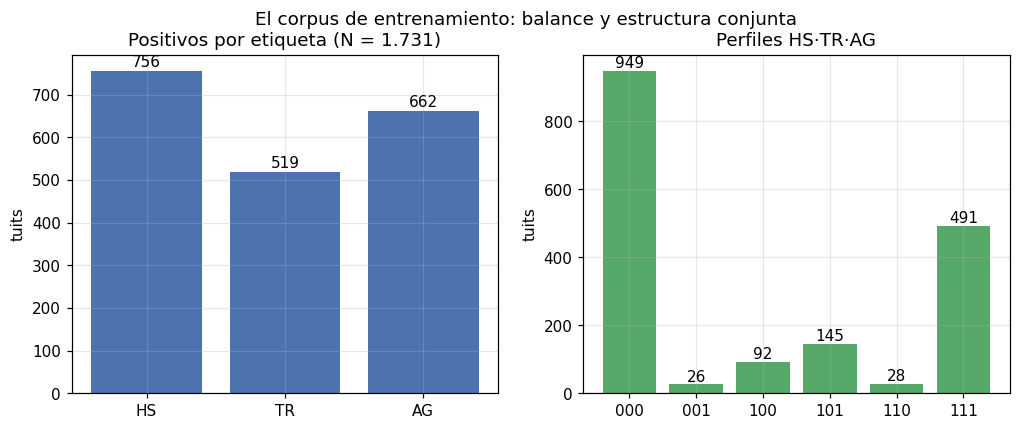

In [7]:
figura, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].bar(resumen_etiquetas.index, resumen_etiquetas["positivos"], color="#4C72B0")
ejes[0].set_title("Positivos por etiqueta (N = 1.731)")
ejes[0].set_ylabel("tuits")
for posicion, valor in enumerate(resumen_etiquetas["positivos"]):
    ejes[0].text(posicion, valor + 10, str(valor), ha="center")

colores = ["#55A868" if valor > 0 else "#C44E52" for valor in conteo_combinaciones.values]
ejes[1].bar(conteo_combinaciones.index, conteo_combinaciones.values, color=colores)
ejes[1].set_title("Perfiles HS·TR·AG")
ejes[1].set_ylabel("tuits")
for posicion, valor in enumerate(conteo_combinaciones.values):
    ejes[1].text(posicion, valor + 10, str(valor), ha="center")
figura.suptitle("El corpus de entrenamiento: balance y estructura conjunta")
mostrar_figura(figura, "02_etiquetas")

Longitud en caracteres: media 104.3 | mediana 91 | max 306
Longitud en palabras:   media 17.1 | mediana 15 | max 57


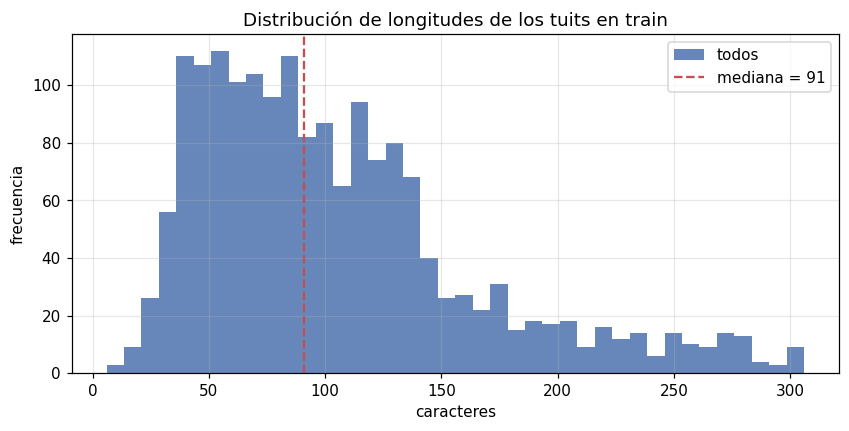

In [8]:
train_df["len_caracteres"] = train_df["text"].str.len()
train_df["len_palabras"] = train_df["text"].str.split().str.len()

print("Longitud en caracteres: media %.1f | mediana %.0f | max %d" % (
    train_df["len_caracteres"].mean(),
    train_df["len_caracteres"].median(),
    train_df["len_caracteres"].max(),
))
print("Longitud en palabras:   media %.1f | mediana %.0f | max %d" % (
    train_df["len_palabras"].mean(),
    train_df["len_palabras"].median(),
    train_df["len_palabras"].max(),
))

figura, eje = plt.subplots(figsize=(9, 4))
eje.hist(train_df["len_caracteres"], bins=40, color="#4C72B0", alpha=0.85, label="todos")
eje.axvline(train_df["len_caracteres"].median(), color="#C44E52", linestyle="--",
            label=f"mediana = {train_df['len_caracteres'].median():.0f}")
eje.set_title("Distribución de longitudes de los tuits en train")
eje.set_xlabel("caracteres")
eje.set_ylabel("frecuencia")
eje.legend()
mostrar_figura(figura, "02_longitudes")

### 2.3. Fuga estructural: duplicados, near-duplicados y pseudo-autores [EN VIVO]

Una de las lecciones metodológicas más importantes del proyecto fue descubrir y corregir la **fuga por agrupamiento**: en Twitter abundan los textos casi idénticos (retuits, plantillas, copias con variaciones mínimas) y los hilos del mismo usuario. Si la validación cruzada reparte copias casi idénticas entre entrenamiento y validación, la métrica local se infla y el modelo parece mejor de lo que es. La solución del proyecto fue agrupar el corpus con dos criterios —similitud de texto (n-gramas de caracteres, coseno ≥ 0.85) y pseudo-autor (primera mención `@usuario`)— y usar esos grupos como unidad de partición en toda la validación.

In [9]:
PATRON_URL = re.compile(r"https?://\S+")
PATRON_MENCION = re.compile(r"@(\w+)")


def normalizar_texto(texto: str) -> str:
    """Normaliza para el análisis de similitud (minúsculas, sin URLs, espacios)."""
    return re.sub(r"\s+", " ", PATRON_URL.sub(" ", texto.lower())).strip()


def grupos_near_duplicados(textos: list[str], umbral: float = 0.85) -> np.ndarray:
    """Agrupa textos casi idénticos (componentes conexas por similitud coseno)."""
    vectorizador = TfidfVectorizer(analyzer="char_wb", ngram_range=(4, 4), min_df=1)
    matriz = vectorizador.fit_transform([normalizar_texto(t) for t in textos])
    similitud = (matriz @ matriz.T).toarray().astype("float32")
    np.fill_diagonal(similitud, 0.0)

    padre = list(range(len(textos)))

    def encontrar(nodo: int) -> int:
        while padre[nodo] != nodo:
            padre[nodo] = padre[padre[nodo]]
            nodo = padre[nodo]
        return nodo

    def unir(a: int, b: int) -> None:
        raiz_a, raiz_b = encontrar(a), encontrar(b)
        if raiz_a != raiz_b:
            padre[max(raiz_a, raiz_b)] = min(raiz_a, raiz_b)

    filas, columnas = np.where(np.triu(similitud, k=1) >= umbral)
    for fila, columna in zip(filas.tolist(), columnas.tolist()):
        unir(fila, columna)
    return np.array([encontrar(nodo) for nodo in range(len(textos))])


textos_todos = list(train_df["text"]) + list(test_df["text"])
grupos_todos = grupos_near_duplicados(textos_todos)
grupos_near_dup_train = grupos_todos[: len(train_df)]

tamanos = pd.Series(grupos_todos).value_counts()
print("Textos totales analizados (train + test):", len(textos_todos))
print("Grupos de near-duplicados con más de un texto:", int((tamanos > 1).sum()))
print("Tamaño del grupo más grande:", int(tamanos.max()))
print("Textos en algún grupo con más de un miembro:", int(tamanos[tamanos > 1].sum()))

Textos totales analizados (train + test): 2885
Grupos de near-duplicados con más de un texto: 4
Tamaño del grupo más grande: 6
Textos en algún grupo con más de un miembro: 17


In [10]:
def pseudo_autores(textos: pd.Series) -> list[str]:
    """Extrae el pseudo-autor (primera mención) de cada texto."""
    autores = []
    for texto in textos:
        coincidencia = PATRON_MENCION.search(texto)
        autores.append(coincidencia.group(1).lower() if coincidencia else "")
    return autores


def fusionar_grupos(train: pd.DataFrame, grupos_near_dup: np.ndarray) -> np.ndarray:
    """Fusiona near-duplicados y pseudo-autores en una única partición (union-find)."""
    n_filas = len(train)
    padre = list(range(n_filas))

    def encontrar(nodo: int) -> int:
        while padre[nodo] != nodo:
            padre[nodo] = padre[padre[nodo]]
            nodo = padre[nodo]
        return nodo

    def unir(a: int, b: int) -> None:
        raiz_a, raiz_b = encontrar(a), encontrar(b)
        if raiz_a != raiz_b:
            padre[max(raiz_a, raiz_b)] = min(raiz_a, raiz_b)

    representante: dict[int, int] = {}
    for posicion, grupo in enumerate(grupos_near_dup.tolist()):
        if grupo in representante:
            unir(posicion, representante[grupo])
        else:
            representante[grupo] = posicion
    representante_autor: dict[str, int] = {}
    for posicion, autor in enumerate(pseudo_autores(train["text"])):
        if not autor:
            continue
        if autor in representante_autor:
            unir(posicion, representante_autor[autor])
        else:
            representante_autor[autor] = posicion
    return np.array([encontrar(nodo) for nodo in range(n_filas)])


grupos_fusionados_train = fusionar_grupos(train_df, grupos_near_dup_train)
n_grupos = len(np.unique(grupos_fusionados_train))
print("Grupos fusionados (near-duplicado ∪ pseudo-autor) en train:", n_grupos)
print("Reducción respecto a 1.731 filas:", len(train_df) - n_grupos, "filas agrupadas")

Grupos fusionados (near-duplicado ∪ pseudo-autor) en train: 1645
Reducción respecto a 1.731 filas: 86 filas agrupadas


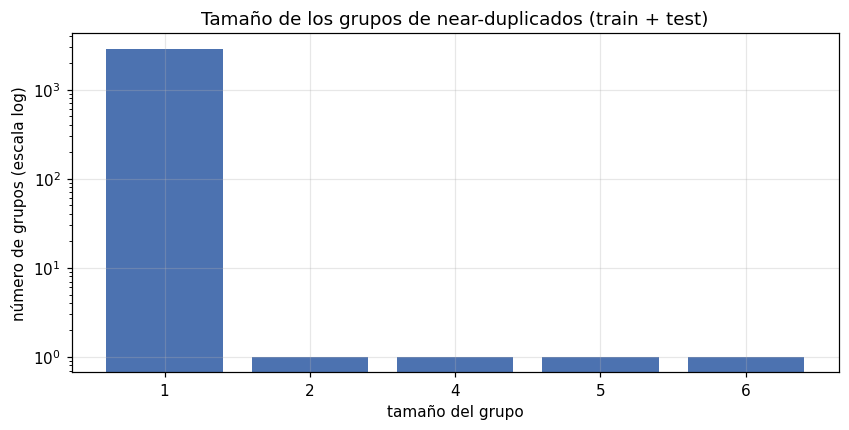

In [11]:
figura, eje = plt.subplots(figsize=(9, 4))
conteo_tamanos = tamanos.value_counts().sort_index()
eje.bar(conteo_tamanos.index.astype(str), conteo_tamanos.values, color="#4C72B0")
eje.set_yscale("log")
eje.set_title("Tamaño de los grupos de near-duplicados (train + test)")
eje.set_xlabel("tamaño del grupo")
eje.set_ylabel("número de grupos (escala log)")
mostrar_figura(figura, "02_grupos_near_dup")

In [12]:
# Asociación entre el identificador y las etiquetas (fuga por orden)
from scipy import stats

for etiqueta in ETIQUETAS:
    correlacion = stats.spearmanr(train_df["id"].astype(int), train_df[etiqueta])
    print(f"Spearman(id, {etiqueta}) = {correlacion.statistic:+.4f} (p = {correlacion.pvalue:.3f})")

tabla = pd.crosstab((train_df["id"].astype(int) // 2500), train_df["HS"])
chi2, valor_p, _, _ = stats.chi2_contingency(tabla)
print(f"\nChi-cuadrado id-decilo vs HS: chi2 = {chi2:.2f}, p = {valor_p:.3f}")
print("(Una asociación significativa indicaría posible fuga por orden de identificación.)")

Spearman(id, HS) = +0.0166 (p = 0.490)
Spearman(id, TR) = -0.0019 (p = 0.938)
Spearman(id, AG) = -0.0070 (p = 0.772)

Chi-cuadrado id-decilo vs HS: chi2 = 0.65, p = 0.421
(Una asociación significativa indicaría posible fuga por orden de identificación.)


### 2.4. Relaciones entre etiquetas: la jerarquía HatEval [EN VIVO]

Las tres etiquetas no son independientes: el discurso de odio dirigido suele ser también agresivo, y el proyecto midió esa dependencia con el coeficiente Phi (la correlación de Pearson entre variables binarias). Los valores observados —Phi(HS, AG) ≈ 0.83, Phi(HS, TR) ≈ 0.74, Phi(TR, AG) ≈ 0.76— muestran una estructura fuertemente jerárquica (Silla y Freitas, 2011) que fundamenta la regla ontológica TR = 1 ⇒ HS = 1 en la etapa de decisión.

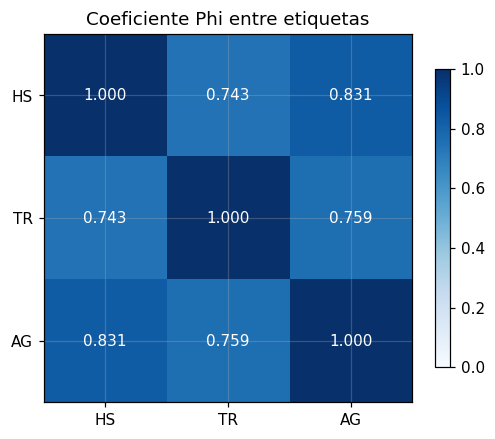

Casos con TR = 1 y HS = 0: 0 (la regla HatEval se cumple siempre)
Casos con AG = 1 y HS = 0: 26 (1.5 %; hay agresividad sin odio)


In [13]:
def coeficiente_phi(x: pd.Series, y: pd.Series) -> float:
    """Coeficiente Phi entre dos variables binarias."""
    tabla = pd.crosstab(x, y)
    n11 = int(tabla.loc[1, 1]) if (1 in tabla.index and 1 in tabla.columns) else 0
    n10 = int(tabla.loc[1, 0]) if (1 in tabla.index and 0 in tabla.columns) else 0
    n01 = int(tabla.loc[0, 1]) if (0 in tabla.index and 1 in tabla.columns) else 0
    n00 = int(tabla.loc[0, 0]) if (0 in tabla.index and 0 in tabla.columns) else 0
    numerador = n11 * n00 - n10 * n01
    denominador = np.sqrt(float((n11 + n10) * (n01 + n00) * (n11 + n01) * (n10 + n00)))
    return float(numerador / denominador) if denominador > 0 else 0.0


matriz_phi = pd.DataFrame(index=list(ETIQUETAS), columns=list(ETIQUETAS), dtype=float)
for etiqueta_a in ETIQUETAS:
    for etiqueta_b in ETIQUETAS:
        matriz_phi.loc[etiqueta_a, etiqueta_b] = (
            1.0 if etiqueta_a == etiqueta_b else coeficiente_phi(train_df[etiqueta_a], train_df[etiqueta_b])
        )

figura, eje = plt.subplots(figsize=(5.4, 4.4))
imagen = eje.imshow(matriz_phi.values.astype(float), cmap="Blues", vmin=0, vmax=1)
for i in range(len(ETIQUETAS)):
    for j in range(len(ETIQUETAS)):
        eje.text(j, i, f"{matriz_phi.values[i, j]:.3f}", ha="center", va="center",
                 color="white" if matriz_phi.values[i, j] > 0.6 else "black")
eje.set_xticks(range(len(ETIQUETAS)), list(ETIQUETAS))
eje.set_yticks(range(len(ETIQUETAS)), list(ETIQUETAS))
eje.set_title("Coeficiente Phi entre etiquetas")
figura.colorbar(imagen, ax=eje, shrink=0.8)
mostrar_figura(figura, "02_phi")

casos_tr_sin_hs = int(((train_df["TR"] == 1) & (train_df["HS"] == 0)).sum())
casos_ag_sin_hs = int(((train_df["AG"] == 1) & (train_df["HS"] == 0)).sum())
print(f"Casos con TR = 1 y HS = 0: {casos_tr_sin_hs} (la regla HatEval se cumple siempre)")
print(f"Casos con AG = 1 y HS = 0: {casos_ag_sin_hs} ({casos_ag_sin_hs / len(train_df) * 100:.1f} %; hay agresividad sin odio)")

### 2.5. La discrepancia semántica de TR [DOCUMENTADO]

Durante la fase de comprensión del problema se documentó una tensión importante entre la definición oficial de la competencia y la definición clásica de la tarea HatEval (SemEval-2019 Task 5). En la competencia, TR marca «discurso dirigido contra una persona o grupo»; en HatEval (Basile et al., 2019), *targeted* exige además que el mensaje sea acoso dirigido a una persona o colectivo concreto. Esta diferencia de criterio explica varios de los errores residuales de la columna TR que el proyecto documentó en sus auditorías de etiquetas (secciones 4.2 y 4.3): hay tuits que, leídos con la definición HatEval, no serían *targeted*, pero que el corpus oficial anota como TR = 1 (y viceversa). El proyecto decidió **no tocar las etiquetas oficiales** y modelar la definición oficial tal como está; la discrepancia quedó documentada como parte del análisis de error y de la auditoría de calidad de etiquetas.

### 2.6. Hallazgos del EDA que guiaron el modelado [DOCUMENTADO]

Del análisis anterior salieron las decisiones estructurales que vertebran todo el pipeline:

- **Desbalance moderado y distinto por etiqueta** (HS 43.7 %, TR 30.0 %, AG 38.2 % de positivos): justifica `class_weight="balanced"`, umbrales desacoplados (Lipton et al., 2014) por etiqueta y una mirada constante a la columna TR (la minoritaria y la más frágil).
- **Jerarquía HatEval** (TR = 1 ⇒ HS = 1 en el 100 % de los casos): justifica la regla ontológica ascendente en la etapa de decisión.
- **Textos cortos con ruido ortográfico deliberado** (media ≈ 104 caracteres): justifica la representación sub-léxica (Cavnar y Trenkle, 1994; McNamee y Mayfield, 2004) multi-escala (`char_wb` y `char`) además de los n-gramas de palabras.
- **Near-duplicados y pseudo-autores**: justifica la validación cruzada agrupada (sección 3) y el protocolo dual de particiones.
- **Asociación id-etiqueta no significativa**: descarta fuga por orden de los identificadores.

### 2.7. Longitud y estilo: la señal de la brevedad [EN VIVO]

La longitud no es un detalle cosmético: separa las clases. Los tuits con TR=1
tienen mediana de 69 caracteres frente a 103 de los negativos (delta de Cliff
−0.369, $p=3.6\times10^{-34}$); HS y AG también son más cortos, aunque con
efectos menores (−0.141 y −0.163). La lectura es directa: el discurso dirigido
suele ser un insulto breve y directo, mientras que los textos largos contienen
más contexto, citas o narrativa. Esa brevedad es una de las razones por las que
la representación de caracteres rinde mejor que un vocabulario de palabras
completo: con pocos tokens, cada morfema cuenta.

Longitud en caracteres por etiqueta (Mann-Whitney y delta de Cliff):
etiqueta  mediana_pos  mediana_neg        U   p  delta_cliff
      HS         81.0         98.0 316759.0 0.0      -0.1405
      TR         69.0        103.0 198393.5 0.0      -0.3692
      AG         79.0         97.0 296074.5 0.0      -0.1633


/tmp/ipykernel_149772/2358204696.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  eje.boxplot(datos, labels=["0", "1"], showfliers=False)
/tmp/ipykernel_149772/2358204696.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  eje.boxplot(datos, labels=["0", "1"], showfliers=False)
/tmp/ipykernel_149772/2358204696.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  eje.boxplot(datos, labels=["0", "1"], showfliers=False)


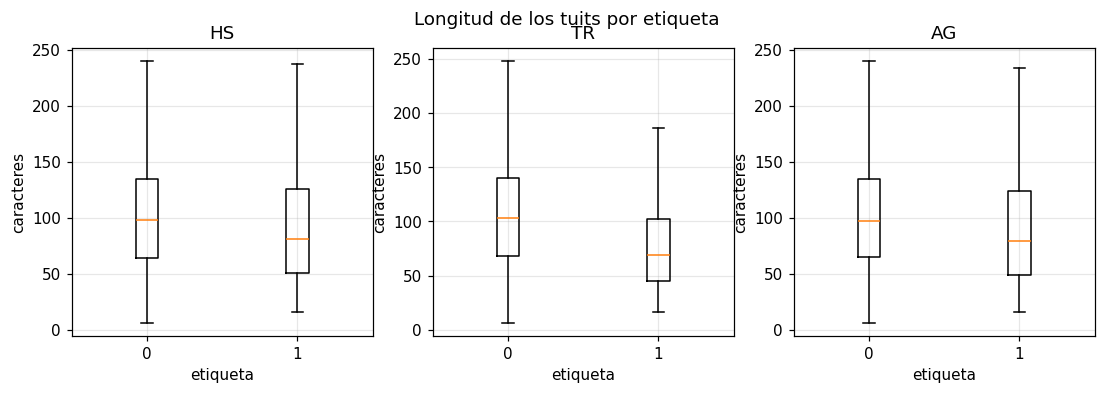

In [14]:
from scipy import stats

filas_longitud = []
for etiqueta in ETIQUETAS:
    positivos = train_df.loc[train_df[etiqueta] == 1, "len_caracteres"]
    negativos = train_df.loc[train_df[etiqueta] == 0, "len_caracteres"]
    u, p = stats.mannwhitneyu(positivos, negativos, alternative="two-sided")
    delta = 2 * u / (len(positivos) * len(negativos)) - 1
    filas_longitud.append(
        {
            "etiqueta": etiqueta,
            "mediana_pos": float(positivos.median()),
            "mediana_neg": float(negativos.median()),
            "U": float(u),
            "p": float(p),
            "delta_cliff": float(delta),
        }
    )
tabla_longitud = pd.DataFrame(filas_longitud)
print("Longitud en caracteres por etiqueta (Mann-Whitney y delta de Cliff):")
print(tabla_longitud.round(4).to_string(index=False))

figura, ejes = plt.subplots(1, 3, figsize=(12, 3.4))
for eje, etiqueta in zip(ejes, ETIQUETAS):
    datos = [
        train_df.loc[train_df[etiqueta] == 0, "len_caracteres"],
        train_df.loc[train_df[etiqueta] == 1, "len_caracteres"],
    ]
    eje.boxplot(datos, labels=["0", "1"], showfliers=False)
    eje.set_title(etiqueta)
    eje.set_xlabel("etiqueta")
    eje.set_ylabel("caracteres")
figura.suptitle("Longitud de los tuits por etiqueta")
mostrar_figura(figura, "02_longitud_por_etiqueta")

### 2.8. Marcadores estilométricos [EN VIVO]

Además de la longitud, el estilo de escritura aporta pistas: menciones,
hashtags, URLs, mayúsculas, signos, dígitos y repeticiones. El patrón más
nítido es el de TR: los positivos tienen más menciones (delta +0.27) y menos
URLs (−0.21), hashtags (−0.11) y palabras (−0.35). Las mayúsculas, las
exclamaciones y las interrogaciones no muestran diferencias relevantes. Esta
tabla justifica explorar features estilométricas, aunque el proyecto comprobó
después que los bloques densos no transferían al leaderboard; la señal útil
terminó capturándose con n-gramas de caracteres.

Delta de Cliff (positivos vs negativos) por rasgo y etiqueta:
etiqueta            AG     HS     TR
rasgo                               
digitos         -0.053 -0.065 -0.126
exclamaciones   -0.006  0.007 -0.017
hashtags        -0.077 -0.065 -0.105
interrogaciones -0.055 -0.000 -0.056
mayusculas       0.003 -0.052  0.012
menciones        0.115  0.084  0.267
palabras        -0.182 -0.150 -0.354
repetidos        0.041  0.002 -0.057
urls            -0.070 -0.080 -0.212


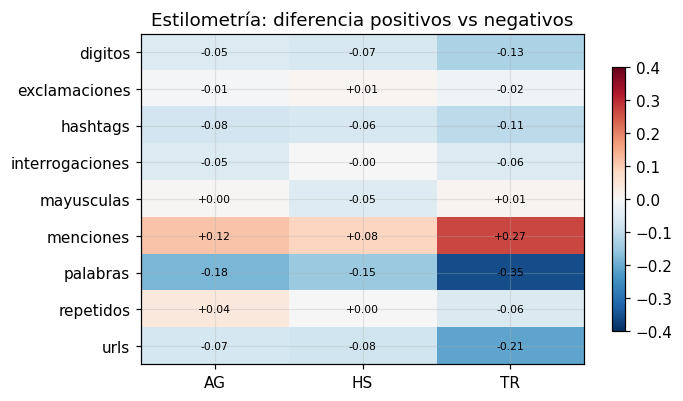

In [15]:
def rasgos_estilo(texto):
    """Rasgos estilométricos simples de un tuit."""
    s = str(texto)
    letras = max(sum(c.isalpha() for c in s), 1)
    return {
        "menciones": len(re.findall(r"@\w+", s)),
        "hashtags": len(re.findall(r"#\w+", s)),
        "urls": len(re.findall(r"https?://\S+", s)),
        "mayusculas": sum(c.isupper() for c in s) / letras,
        "exclamaciones": s.count("!"),
        "interrogaciones": s.count("?"),
        "digitos": sum(c.isdigit() for c in s),
        "repetidos": len(re.findall(r"(.)\1{2,}", s)),
        "palabras": len(s.split()),
    }


estilo = pd.DataFrame([rasgos_estilo(t) for t in train_df["text"]])
filas_estilo = []
for columna in estilo.columns:
    for etiqueta in ETIQUETAS:
        pos = estilo.loc[train_df[etiqueta] == 1, columna]
        neg = estilo.loc[train_df[etiqueta] == 0, columna]
        u, p = stats.mannwhitneyu(pos, neg, alternative="two-sided")
        delta = 2 * u / (len(pos) * len(neg)) - 1
        filas_estilo.append(
            {"rasgo": columna, "etiqueta": etiqueta, "delta": delta, "p": p}
        )
tabla_estilo = pd.DataFrame(filas_estilo)
print("Delta de Cliff (positivos vs negativos) por rasgo y etiqueta:")
print(
    tabla_estilo.pivot(index="rasgo", columns="etiqueta", values="delta")
    .round(3)
    .to_string()
)

matriz = tabla_estilo.pivot(index="rasgo", columns="etiqueta", values="delta")
figura, eje = plt.subplots(figsize=(6.5, 3.9))
imagen = eje.imshow(matriz.values, cmap="RdBu_r", vmin=-0.4, vmax=0.4, aspect="auto")
eje.set_xticks(range(len(matriz.columns)), matriz.columns)
eje.set_yticks(range(len(matriz.index)), matriz.index)
for i in range(len(matriz.index)):
    for j in range(len(matriz.columns)):
        eje.text(
            j,
            i,
            f"{matriz.values[i, j]:+.2f}",
            ha="center",
            va="center",
            fontsize=7,
        )
eje.set_title("Estilometría: diferencia positivos vs negativos")
figura.colorbar(imagen, ax=eje, shrink=0.8)
mostrar_figura(figura, "02_estilometria")

### 2.9. Vocabulario y términos discriminativos [EN VIVO]

El corpus de entrenamiento tiene 31.935 tokens, 8.247 tipos y 6.139 hapax; el
TTR es 0.258, propio de un corpus corto y repetitivo. Los términos más
frecuentes en las clases positivas son insultos directos y marcadores de
segunda persona; el vocabulario es pequeño y muy sesgado al dominio. Para
ordenar la evidencia se usa un log-odds suavizado (Laplace 0.5), una versión
simple de la idea de Monroe et al. (2008): mide qué términos distinguen los
positivos de los negativos, no solo cuáles son frecuentes.

Tokens: 31,935 | tipos: 8,247 | hapax: 6,139 | TTR: 0.258


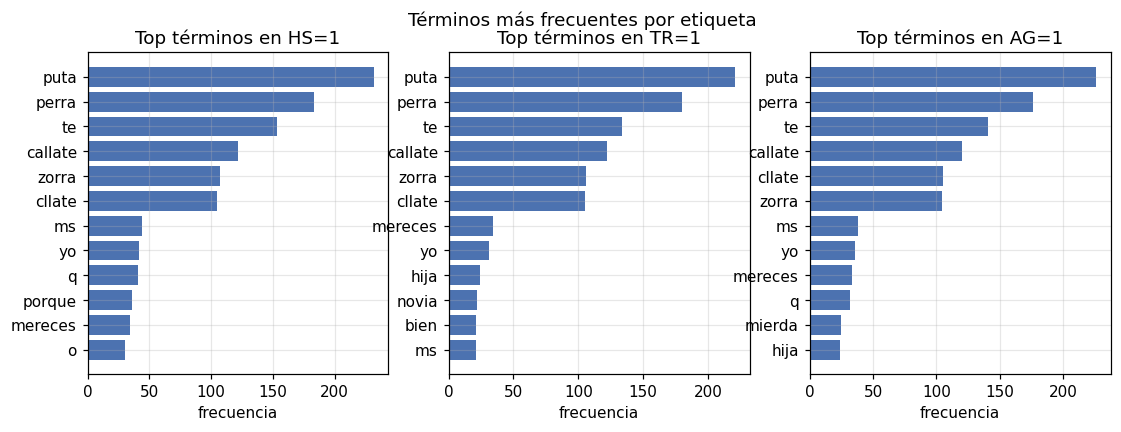

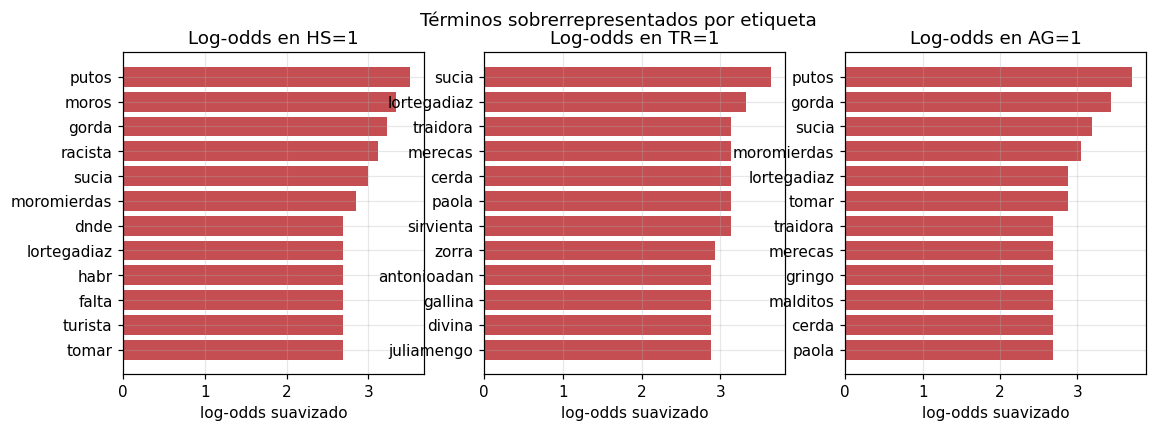

In [16]:
from collections import Counter


def tokenizar(texto):
    """Tokeniza a palabras en minúsculas, conservando acentos y eñes."""
    return re.findall(r"[a-záéíóúñü]+", str(texto).lower())


tokens_train = [t for s in train_df["text"] for t in tokenizar(s)]
conteo_train = Counter(tokens_train)
print(
    f"Tokens: {len(tokens_train):,} | tipos: {len(conteo_train):,} | "
    f"hapax: {sum(1 for v in conteo_train.values() if v == 1):,} | "
    f"TTR: {len(conteo_train) / len(tokens_train):.3f}"
)

STOPWORDS = {
    "de", "que", "y", "a", "la", "el", "en", "un", "una", "los", "las",
    "por", "con", "para", "mi", "tu", "es", "no", "se", "lo", "al", "del",
    "como", "mas", "pero", "sus", "le", "ya", "me", "si", "sin", "sobre",
    "este", "esta", "entre", "cuando", "muy", "hay", "ser", "tiene", "todo",
    "tambien", "fue", "era", "eres", "soy", "t", "co", "http", "https",
    "www", "the", "and", "to", "of", "in", "is", "it", "you", "my",
}

figura, ejes = plt.subplots(1, 3, figsize=(12, 3.8))
for eje, etiqueta in zip(ejes, ETIQUETAS):
    conteo = Counter(
        t
        for s in train_df.loc[train_df[etiqueta] == 1, "text"]
        for t in tokenizar(s)
    )
    top = [(t, n) for t, n in conteo.most_common(60) if t not in STOPWORDS][:12]
    eje.barh([t for t, _ in top][::-1], [n for _, n in top][::-1], color="#4C72B0")
    eje.set_title(f"Top términos en {etiqueta}=1")
    eje.set_xlabel("frecuencia")
figura.suptitle("Términos más frecuentes por etiqueta")
mostrar_figura(figura, "02_tokens_por_etiqueta")

alfa = 0.5
figura, ejes = plt.subplots(1, 3, figsize=(12, 3.8))
for eje, etiqueta in zip(ejes, ETIQUETAS):
    pos = Counter(
        t
        for s in train_df.loc[train_df[etiqueta] == 1, "text"]
        for t in tokenizar(s)
    )
    neg = Counter(
        t
        for s in train_df.loc[train_df[etiqueta] == 0, "text"]
        for t in tokenizar(s)
    )
    vocabulario = set(pos) | set(neg)
    n_pos, n_neg = sum(pos.values()), sum(neg.values())

    def puntuacion(t):
        p = (pos[t] + alfa) / (n_pos + alfa * len(vocabulario))
        q = (neg[t] + alfa) / (n_neg + alfa * len(vocabulario))
        return float(np.log(p / q))

    candidatos = [t for t in vocabulario if t not in STOPWORDS and len(t) > 3]
    top = sorted(candidatos, key=puntuacion, reverse=True)[:12]
    eje.barh(top[::-1], [puntuacion(t) for t in top][::-1], color="#C44E52")
    eje.set_title(f"Log-odds en {etiqueta}=1")
    eje.set_xlabel("log-odds suavizado")
figura.suptitle("Términos sobrerrepresentados por etiqueta")
mostrar_figura(figura, "02_logodds_etiquetas")

### 2.10. Proyección TF-IDF + SVD [EN VIVO]

Una proyección lineal de la matriz TF-IDF en dos dimensiones permite mirar la
geometría del corpus. No es un clasificador ni una prueba de separabilidad: las
dos componentes explican solo el 1.55 % de la varianza total, así que la figura
debe leerse como una vista cualitativa. Aun así, muestra que las clases se
solapan en el espacio disperso; esa superposición es la que obliga a trabajar
la decisión (umbrales por etiqueta, regla ontológica y calibración) y no solo la
representación.

Varianza explicada por las dos componentes: 1.58% (vista cualitativa).


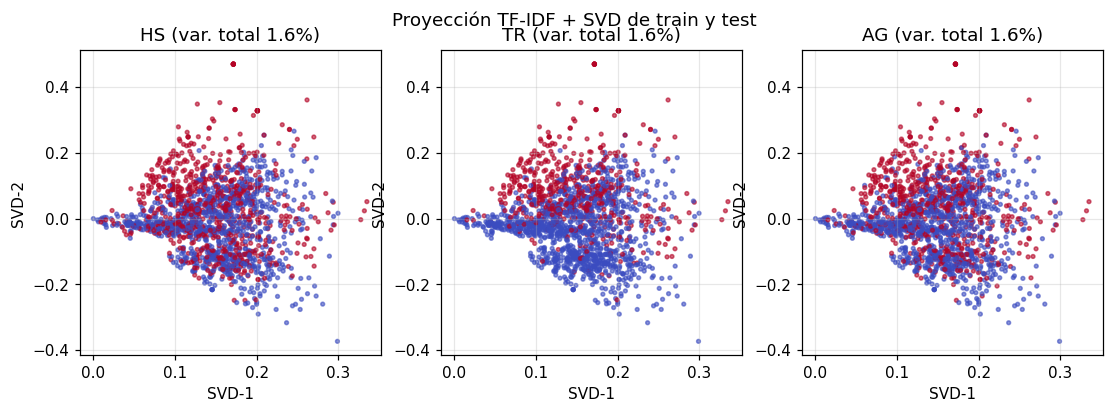

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

corpus = list(train_df["text"]) + list(test_df["text"])
matriz_tfidf = TfidfVectorizer(
    analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True
).fit_transform(corpus)
svd = TruncatedSVD(n_components=2, random_state=42)
proyeccion = svd.fit_transform(matriz_tfidf)
varianza = float(svd.explained_variance_ratio_.sum())
print(f"Varianza explicada por las dos componentes: {varianza:.2%} (vista cualitativa).")

figura, ejes = plt.subplots(1, 3, figsize=(12, 3.6))
for eje, etiqueta in zip(ejes, ETIQUETAS):
    eje.scatter(
        proyeccion[: len(train_df), 0],
        proyeccion[: len(train_df), 1],
        c=train_df[etiqueta].to_numpy(),
        cmap="coolwarm",
        s=6,
        alpha=0.6,
    )
    eje.set_title(f"{etiqueta} (var. total {varianza:.1%})")
    eje.set_xlabel("SVD-1")
    eje.set_ylabel("SVD-2")
figura.suptitle("Proyección TF-IDF + SVD de train y test")
mostrar_figura(figura, "02_svd_etiquetas")

### 2.11. Train vs test: misma distribución, vocabulario parcialmente nuevo [EN VIVO]

El test no tiene etiquetas, pero su texto sí se puede comparar. La mediana de
longitud es 91 caracteres en ambos conjuntos; las tasas de menciones, hashtags
y URLs son parecidas (menciones 47.5 % vs 45.8 %, hashtags 9.3 % vs 9.6 %,
URLs 31.2 % vs 28.3 %). La diferencia importante es el vocabulario: el 20.1 %
de los tokens de test no aparece en train. Ese OOV es la razón práctica por la
que los n-gramas de caracteres aportan: reconstruyen palabras no vistas a
partir de prefijos, sufijos y fragmentos.

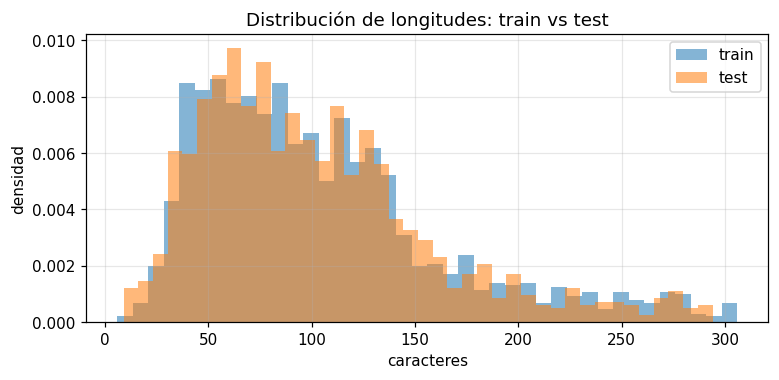

conjunto    n  mediana_caracteres  menciones  hashtags  urls
   train 1731                91.0      0.475     0.093 0.312
    test 1154                91.0      0.458     0.096 0.283
OOV de test respecto al vocabulario de train: 20.06% (20,622 tokens)


In [18]:
train_long = train_df["len_caracteres"]
test_long = test_df["text"].str.len()
figura, eje = plt.subplots(figsize=(8, 3.4))
eje.hist(train_long, bins=40, density=True, alpha=0.55, label="train")
eje.hist(test_long, bins=40, density=True, alpha=0.55, label="test")
eje.set_title("Distribución de longitudes: train vs test")
eje.set_xlabel("caracteres")
eje.set_ylabel("densidad")
eje.legend()
mostrar_figura(figura, "02_train_test_longitud")

vocabulario_train = set(tokens_train)
tokens_test = [t for s in test_df["text"] for t in tokenizar(s)]
oov = sum(1 for t in tokens_test if t not in vocabulario_train) / max(len(tokens_test), 1)
filas = []
for nombre, marco in (("train", train_df), ("test", test_df)):
    textos = marco["text"].astype(str)
    filas.append(
        {
            "conjunto": nombre,
            "n": len(marco),
            "mediana_caracteres": float(textos.str.len().median()),
            "menciones": float(textos.str.contains(r"@\w+").mean()),
            "hashtags": float(textos.str.contains(r"#\w+").mean()),
            "urls": float(textos.str.contains(r"https?://").mean()),
        }
    )
print(pd.DataFrame(filas).round(3).to_string(index=False))
print(f"OOV de test respecto al vocabulario de train: {oov:.2%} ({len(tokens_test):,} tokens)")

### 2.12. Síntesis del EDA ampliado [DOCUMENTADO]

El EDA deja cinco conclusiones que conectan con las decisiones de modelado:

- **Brevedad discriminativa**: los positivos son más cortos, sobre todo en TR
  (69 vs 103 caracteres; delta de Cliff −0.369). Con tan pocos tokens, la
  representación de caracteres conserva morfemas que un vocabulario de palabras
  perdería.
- **Estilometría**: las menciones y la ausencia de URLs distinguen a TR; las
  mayúsculas y los signos no aportan. Los bloques densos de estilo se probaron
  y no transfirieron al leaderboard, así que la señal se dejó a los n-gramas.
- **Vocabulario pequeño y sesgado**: 31.935 tokens, 8.247 tipos, TTR 0.258 y
  6.139 hapax. Los términos sobrerrepresentados son insultos directos y
  marcadores de segunda persona; el modelo debe manejar un dominio muy
  específico.
- **Geometría solapada**: la proyección SVD explica solo 1.55 % de la varianza
  y muestra clases entremezcladas. La separación no está en dos dimensiones; de
  ahí la importancia de la calibración y de la capa de decisión.
- **Train y test comparten dominio, no vocabulario**: misma mediana de longitud
  y tasas de menciones/hashtags/URLs similares, pero 20.1 % de OOV en test. Los
  n-gramas de caracteres y la validación agrupada son la respuesta
  metodológica.

Estas observaciones se usaron para justificar la representación V2_triple, los
umbrales por etiqueta y la validación agrupada; las familias que ignoraron esta
evidencia (features densas, poda agresiva del vocabulario o modelos secuenciales
desde cero) quedaron por debajo en las pruebas.

## 3. Preparación de los datos

### 3.1. El protocolo de validación: particiones congeladas [EN VIVO]

La columna vertebral metodológica del proyecto es un protocolo de validación con **particiones congeladas y agrupadas**. Se congeló una sola vez, antes de mirar resultados, y nunca se rehizo:

1. **Desarrollo / holdout.** Con los grupos fusionados (near-duplicados (Kaufman et al., 2012) ∪ pseudo-autores) se separó el corpus de entrenamiento en desarrollo y holdout con `StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)` estratificando por la combinación HS×TR×AG. El pliegue 0 queda como holdout (~14 %) y el resto como desarrollo (1.483 filas), que es donde se evalúan todos los experimentos.
2. **Pliegues canónicos del desarrollo.** `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` sobre el desarrollo: la partición principal de evaluación.
3. **Partición 47.** Una réplica con otra semilla de pliegues (`random_state=43`) que sirve de contraste independiente: un candidato solo se adopta si mejora también aquí.

La reconstrucción que sigue reproduce esas particiones **exactamente** (fue verificada contra los artefactos congelados del proyecto: grupos 2.885/2.885, grupos fusionados 1.483/1.483, pliegues canónicos idénticos), sin depender de ningún archivo externo.

In [19]:
def combinaciones_texto(marco: pd.DataFrame) -> np.ndarray:
    """Combinación HS·TR·AG como cadena (para estratificar)."""
    return (marco["HS"].astype(str) + marco["TR"].astype(str) + marco["AG"].astype(str)).to_numpy()


# 1) Desarrollo / holdout congelado (StratifiedGroupKFold(7), semilla 42)
divisor_holdout = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
pliegues_holdout = list(
    divisor_holdout.split(train_df, combinaciones_texto(train_df), groups=grupos_fusionados_train)
)
indices_holdout = np.sort(pliegues_holdout[0][1])
indices_dev = np.sort(np.concatenate([pliegue[1] for pliegue in pliegues_holdout[1:]]))

train_dev = train_df.iloc[indices_dev].reset_index(drop=True)
y_dev = train_dev[list(ETIQUETAS)].to_numpy(dtype=int)
grupos_dev = grupos_fusionados_train[indices_dev]
combinacion_dev = combinaciones_texto(train_dev)

print("Desarrollo: %d filas | holdout congelado: %d filas" % (len(train_dev), len(indices_holdout)))
assert len(train_dev) == 1483, "Tamaño de desarrollo inesperado"

Desarrollo: 1483 filas | holdout congelado: 248 filas


In [20]:
# 2) Pliegues canónicos del desarrollo (StratifiedGroupKFold(5), semilla 42)
pliegues_canonicos = np.full(len(train_dev), -1, dtype=int)
divisor_canonico = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
for numero, (_, validacion) in enumerate(
    divisor_canonico.split(train_dev, combinacion_dev, groups=grupos_dev)
):
    pliegues_canonicos[validacion] = numero + 1

# 3) Partición 47: réplica con otra semilla de pliegues (semilla 43)
pliegues_47 = np.full(len(train_dev), -1, dtype=int)
divisor_47 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=43)
for numero, (_, validacion) in enumerate(
    divisor_47.split(np.arange(len(train_dev)).reshape(-1, 1), combinacion_dev, groups=grupos_dev)
):
    pliegues_47[validacion] = numero + 1


def verificar_sin_fuga(pliegues: np.ndarray, nombre: str) -> None:
    """Verifica que ningún grupo fusionado cruce la frontera de un pliegue."""
    for numero in sorted(set(pliegues.tolist())):
        entrenamiento = np.flatnonzero(pliegues != numero)
        validacion = np.flatnonzero(pliegues == numero)
        compartidos = set(grupos_dev[entrenamiento].tolist()) & set(grupos_dev[validacion].tolist())
        assert not compartidos, f"Fuga detectada en {nombre}, pliegue {numero}"


verificar_sin_fuga(pliegues_canonicos, "canónica")
verificar_sin_fuga(pliegues_47, "partición 47")

tabla_pliegues = pd.DataFrame(
    {
        "pliegue": [1, 2, 3, 4, 5],
        "canónica": [int((pliegues_canonicos == k).sum()) for k in range(1, 6)],
        "partición 47": [int((pliegues_47 == k).sum()) for k in range(1, 6)],
    }
)
print("Tamaño de los pliegues de validación (1.483 filas en total):")
print(tabla_pliegues.to_string(index=False))
print("Ningún grupo fusionado cruza la frontera entrenamiento/validación en ninguna partición.")

Tamaño de los pliegues de validación (1.483 filas en total):
 pliegue  canónica  partición 47
       1       297           297
       2       297           297
       3       296           297
       4       296           296
       5       297           296
Ningún grupo fusionado cruza la frontera entrenamiento/validación en ninguna partición.


### 3.2. Representación V2_triple [EN VIVO]

La representación final es una **unión multi-escala de tres bloques TF-IDF (Salton y Buckley, 1988)**:

- `word(1,2)`: unigramas y bigramas de palabras (semántica léxica).
- `char_wb(3,5)`: n-gramas de caracteres con límites de palabra (morfología, prefijos y sufijos, errores ortográficos).
- `char(1,6)`: n-gramas de caracteres libres (alargamientos vocálicos tipo «holaaaa», elisiones, jerga).

Con `min_df=2`, `sublinear_tf=True` y normalización L2, la unión produce **86.275 dimensiones** sobre el corpus completo. El bloque de caracteres es el que da robustez al ruido ortográfico típico de Twitter; el de palabras aporta la señal semántica. La sección 4.3 explica cómo se llegó a esta representación (P108) y qué alternativas se probaron antes.

In [21]:
from scipy import sparse

BLOQUES_V2_TRIPLE = (("word", (1, 2)), ("char_wb", (3, 5)), ("char", (1, 6)))


def construir_vectorizadores() -> list[TfidfVectorizer]:
    """Crea los tres vectorizadores del bloque V2_triple."""
    return [
        TfidfVectorizer(analyzer=analizador, ngram_range=rango, min_df=2, sublinear_tf=True, lowercase=True)
        for analizador, rango in BLOQUES_V2_TRIPLE
    ]


def matrices_fold(textos_entrenamiento, textos_validacion) -> tuple[sparse.csr_matrix, sparse.csr_matrix]:
    """Construye las matrices fold-local del protocolo (TF-IDF ajustado solo con train)."""
    matrices_entrenamiento, matrices_validacion = [], []
    for vectorizador in construir_vectorizadores():
        matrices_entrenamiento.append(vectorizador.fit_transform(textos_entrenamiento))
        matrices_validacion.append(vectorizador.transform(textos_validacion))
    return (
        sparse.hstack(matrices_entrenamiento).tocsr(),
        sparse.hstack(matrices_validacion).tocsr(),
    )


matrices_train_full, matrices_test_full = [], []
for vectorizador in construir_vectorizadores():
    matrices_train_full.append(vectorizador.fit_transform(train_df["text"]))
    matrices_test_full.append(vectorizador.transform(test_df["text"]))

X_train_completo = sparse.hstack(matrices_train_full).tocsr()
X_test = sparse.hstack(matrices_test_full).tocsr()

dimensiones_por_bloque = [matriz.shape[1] for matriz in matrices_train_full]
print("Dimensiones por bloque:", dict(zip([b[0] for b in BLOQUES_V2_TRIPLE], dimensiones_por_bloque)))
print("Matriz X_train completa:", X_train_completo.shape)
print("Matriz X_test:", X_test.shape)
assert X_train_completo.shape == (1731, 86275), "Dimensión inesperada de la representación"
assert X_test.shape == (1154, 86275), "Dimensión inesperada de test"

Dimensiones por bloque: {'word': 4024, 'char_wb': 23407, 'char': 58844}
Matriz X_train completa: (1731, 86275)
Matriz X_test: (1154, 86275)


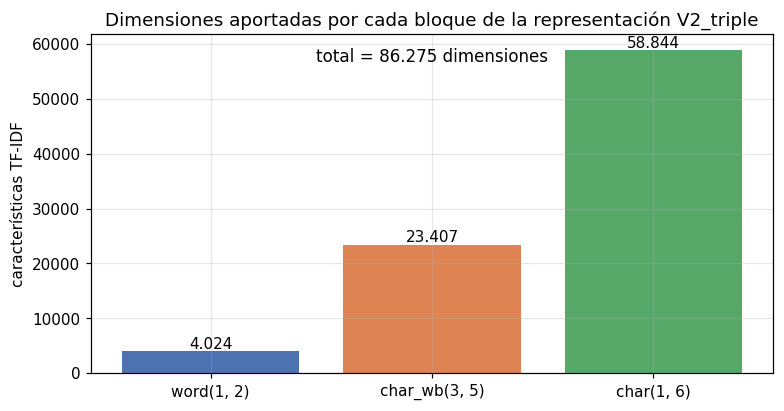

In [22]:
figura, eje = plt.subplots(figsize=(8, 4))
nombres_bloques = [f"{analizador}{rango}" for analizador, rango in BLOQUES_V2_TRIPLE]
eje.bar(nombres_bloques, dimensiones_por_bloque, color=["#4C72B0", "#DD8452", "#55A868"])
eje.set_title("Dimensiones aportadas por cada bloque de la representación V2_triple")
eje.set_ylabel("características TF-IDF")
for posicion, valor in enumerate(dimensiones_por_bloque):
    eje.text(posicion, valor + 500, f"{valor:,}".replace(",", "."), ha="center")
eje.text(0.5, 0.92, "total = 86.275 dimensiones", transform=eje.transAxes, ha="center", fontsize=11)
mostrar_figura(figura, "03_v2_triple")

### 3.3. Reglas de evaluación y controles [EN VIVO]

Los controles que hacen fiable la comparación entre candidatos:

- **Vectorizadores fold-local.** En cada pliegue el TF-IDF (Salton y Buckley, 1988) se ajusta **solo con el pliegue de entrenamiento** y se aplica al de validación. En el ajuste final (100 % de train) se ajusta con todo el corpus de entrenamiento y se transforma el test. Nunca se ajusta nada con validación ni con test.
- **Control de determinismo M2.** Cada corrida importante re-ejecuta dos controles internos: la reconstrucción de **V03** (TF-IDF (Salton y Buckley, 1988) `word(1,2)` + `char_wb(3,5)`, regresión logística `C=2.0`, umbrales congelados) debe reproducir su métrica congelada con diferencia 0.0, y la de **P110** (95 % LR + 5 % SGD (Bottou, 2010)) dentro de 1e-6. Estos controles validan que el entorno de ejecución reproduce el comportamiento del proyecto.
- **Bootstrap (Efron, 1979) agrupado.** Las comparaciones entre candidatos se acompañan de un intervalo de confianza al 95 % calculado con remuestreo por grupos (2.000 réplicas, semilla 20260925): se remuestrean grupos completos, no filas, para conservar la estructura de dependencia.

In [23]:
SEMILLA_BOOTSTRAP = 20260925


def bootstrap_diferencia_grupos(
    y_true: np.ndarray,
    pred_referencia: np.ndarray,
    pred_candidato: np.ndarray,
    grupos: np.ndarray,
    n_replicas: int = 2000,
    semilla: int = SEMILLA_BOOTSTRAP,
) -> dict:
    """Intervalo de confianza de la diferencia de métrica con remuestreo por grupos."""
    generador = np.random.default_rng(semilla)
    grupos_unicos = np.unique(grupos)
    indices_por_grupo = {grupo: np.flatnonzero(grupos == grupo) for grupo in grupos_unicos}
    diferencias = np.empty(n_replicas)
    for repeticion in range(n_replicas):
        muestra = generador.choice(grupos_unicos, size=len(grupos_unicos), replace=True)
        indices = np.concatenate([indices_por_grupo[grupo] for grupo in muestra])
        metrica_ref = metricas_multietiqueta(y_true[indices], pred_referencia[indices])["f1_media_columnas"]
        metrica_cand = metricas_multietiqueta(y_true[indices], pred_candidato[indices])["f1_media_columnas"]
        diferencias[repeticion] = metrica_cand - metrica_ref
    return {
        "diferencia": float(
            metricas_multietiqueta(y_true, pred_candidato)["f1_media_columnas"]
            - metricas_multietiqueta(y_true, pred_referencia)["f1_media_columnas"]
        ),
        "ic95_inferior": float(np.percentile(diferencias, 2.5)),
        "ic95_superior": float(np.percentile(diferencias, 97.5)),
        "probabilidad_mejora": float(np.mean(diferencias > 0)),
    }


print("Funciones de evaluación listas: métrica oficial, regla ascendente y bootstrap agrupado.")

Funciones de evaluación listas: métrica oficial, regla ascendente y bootstrap agrupado.


### 3.4. Los barridos históricos de preparación [DOCUMENTADO]

Antes de fijar la receta final, el proyecto barrió sistemáticamente las decisiones de preparación y representación (fases v2 y posteriores). Los tres barridos que definieron los valores congelados fueron, medidos en el leaderboard público:

| Dimensión | Valores probados (LB público) | Óptimo | Decisión |
|---|---|---|---|
| Regularización `C` | 1.0 → 0.77227; 1.5 → 0.77296; **2.0 → 0.78306**; 2.5 → 0.77707; 3.26 → 0.77602 | C = 2.0 | congelado |
| `min_df` | 1 → 0.76978; **2 → 0.78306**; 5 → 0.77034 | min_df = 2 | congelado |
| Tasa predicha de positivos | 0.3385 → 0.77993; **0.3645 → 0.78306**; 0.3836 → 0.77828; 0.3980 → 0.77495 | 0.3645 | congelado |

Además se probaron y descartaron: `min_df=5` con umbrales recalibrados (P109), `max_df=0.90` (P116), el bagging (Breiman, 1996) de 10 pliegues (P112), las pérdidas de margen (`modified_huber`, P113), las mezclas con NBSVM (P117) y con BM25 (Robertson y Zaragoza, 2009)/SVD (Deerwester et al., 1990) desacoplados (P118). Cada una de esas líneas está documentada con sus números en la sección 4, y sus mecanismos se re-ejecutan en la serie final (sección 5) cuando son recomputables. La lección general de los barridos: en este corpus pequeño (1.731 filas) los valores "intermedios" ganan (min_df=2, C=2.0) y las intervenciones más agresivas sobre la representación degradan la transferencia al test.

## 4.1. Historia experimental I — fases tempranas (v1 a v44)

Esta sección reconstruye la historia experimental que llevó del primer baseline al modelo que dominó el proyecto hasta la fase v44. No repite el EDA ni la descripción del corpus, que se cubren en vivo en otra parte del notebook; se concentra en las preguntas, los diseños, las cifras y las decisiones. El corte termina en la fase v44 (2026-09-27). A partir de P45 la historia continúa en las secciones siguientes del notebook, incluida la fase que después llevó el leaderboard a 0.80516; en el corte de esta sección el modelo final es V03 con 0.78306.

**Convenciones de lectura.** `OOF` es la métrica primaria del proyecto: F1 media column-wise (Opitz y Burst, 2019) sobre las tres etiquetas, calculada out-of-fold sobre las 1.483 filas de desarrollo con los grupos fusionados de D-016, salvo que se indique otro protocolo. `LB` es el F1 público de Kaggle. `Δ vs V03` se calcula contra 0.777211 en OOF o contra 0.78306 en LB, según el contexto indicado. Las cifras se copiaron del registro (`experiments.csv`, 528 filas), de los informes de `reports/` y del notebook consolidado `notebooks/10_final_pipeline.ipynb`; cuando dos fuentes discrepan, se usa la del registro o del informe de la familia y se advierte. Las fases v6-v8 y v11-v25 no se re-narran aquí porque en este corte aparecen solo como precedentes de una decisión (las sondas de v8, V8-06 y V12-01 en especialización por etiqueta, V23-01 en kernels); su detalle vive en el registro de 528 experimentos y en los anexos del notebook.

### 4.1.1 E00: la sonda de metrología que fijó la métrica

**Pregunta.** ¿Qué implementación exacta de F1 usa Kaggle para tres columnas binarias?

**Por qué.** Todas las decisiones posteriores —qué modelo adoptar, qué umbral mover, qué delta considerar real— dependen de que la métrica local sea la misma que la del leaderboard. Sin identificarla, comparar 0.79 local con 0.78 de Kaggle sería interpretar dos números distintos como si fueran el mismo.

**Diseño.** Se envió la plantilla oficial con todas las predicciones a 1 (`submissions/toxic_submission_v00_plantilla.csv`). Con la distribución de train se calcularon cuatro candidatas: media column-wise (Opitz y Burst, 2019) de la F1 binaria (0.541), micro (0.543), macro-6 (0.270) y samples (0.284).

**Resultados.** El score público fue **0.51494**. Solo la familia media column-wise/micro es compatible; macro-6 y samples quedan descartadas. La diferencia entre 0.51494 y el 0.541 esperado implica que el test tiene aproximadamente un 7 % menos de positivos que train (factor k ≈ 0.93).

**Decisión.** La métrica primaria local es `f1_media_columnas`, equivalente a la media de la F1 binaria de las tres columnas. La confirmación independiente llegó con v01: 0.75778 local frente a 0.75677 de Kaggle (diferencia -0.0010). Se registra como D-009.

### 4.1.2 B1: el baseline que demostró dónde estaba la señal

**Pregunta.** ¿Cuánto rinde un modelo lineal simple sobre n-gramas de palabra, y cuánto de ese rendimiento es representación y cuánto es modelo?

**Por qué.** El estado del arte de HatEval (Basile et al., 2019) en español fijaba un techo realista de macro-F1 ≈ 0.73 para sistemas clásicos sin transformers ni embeddings preentrenados. Hacía falta una referencia propia, reproducible y con el mismo protocolo de validación que se usaría después.

**Diseño.** TF-IDF (Salton y Buckley, 1988) `word(1,2)`, `min_df=2`, `sublinear_tf=True`, con tres `LogisticRegression(C=1.0, class_weight="balanced", solver="liblinear")` (Fan et al., 2008), uno por etiqueta. Validación `StratifiedGroupKFold(5, shuffle=True, random_state=42)` agrupada por near-duplicados (Kaufman et al., 2012) y estratificada por la combinación HS × TR × AG, con el vectorizador ajustado dentro de cada pliegue.

**Resultados.** F1 OOF **0.7587** (0.75871 sin post-proceso; 0.75778 con el post-proceso jerárquico (Silla y Freitas, 2011) que después se descartó). Por etiqueta: HS 0.7429, TR 0.8026, AG 0.7306. Dimensión: 4.024 features. En el leaderboard, la submission v01 dio **0.75677**, con un gap local-LB de solo **-0.0010**. La sonda v01 fue durante mucho tiempo la prueba de que el protocolo agrupado reproducía el test con error de milésimas.

**Decisión.** B1 queda como referencia y como control de cordura del protocolo. La conclusión que habilita toda la fase siguiente es que la señal está en el texto y que el margen de mejora debe buscarse en la representación, no en features de superficie.

### 4.1.3 El barrido PRE / REP / MOD: preprocesamiento, representación y modelo (v2-v3)

**Pregunta.** ¿Qué combinación de limpieza, representación y clasificador maximiza la métrica sin sobreajustar el protocolo?

**Por qué.** El EDA mostró texto de Twitter degradado, sin diacríticos y con URLs, menciones, hashtags, elongaciones y ruido de puntuación. La literatura sugería que los n-gramas de carácter capturan evasión ortográfica y que los de palabra funcional y puntuación fueron clave en el sistema ganador en español, pero también advertía que acumular bloques puede degradar. Cada adición debía pasar una ablación controlada.

**Diseño.** 25 configuraciones con la misma validación agrupada de 5 pliegues y el vectorizador ajustado dentro de cada pliegue. Parte A: 10 transformaciones deterministas del texto (PRE-00 a PRE-09). Parte B: 6 representaciones (REP-01 a REP-06). Parte C: 4 familias de modelos (MOD-01 a MOD-04). Regla pre-registrada: adoptar solo con **≥ +0.005 absoluto** y mejora en **≥ 3 de 5 pliegues**.

**Resultados.**

| Parte | Ganador | F1 OOF | Δ vs B1 | Pliegues | Decisión |
|---|---|---:|---:|---:|---|
| A — preprocesamiento | PRE-03 (URLs → token `url`) | 0.7623 | +0.0035 | 4/5 | Descartada: no alcanza +0.005 |
| B — representación | REP-05 (unión word + char_wb) | 0.7865 | +0.0278 | 5/5 | Adoptada |
| C — modelo | MOD-03b_BEST (LR C=2.0 balanced) | 0.7927 | +0.0339 | 5/5 | Adoptada: modelo final |

Ninguna de las 10 variantes de preprocesamiento superó el umbral. La mejor fue sustituir URLs por un token (+0.0035) y la peor fue la lematización con spaCy (-0.0162). Las representaciones puras quedaron muy por debajo de la unión: char sola 0.7567 (REP-01), word sola 0.7417 (REP-03), unión 0.7865 (REP-05). En modelos, LinearSVC rindió 0.7849 (MOD-01), ComplementNB 0.6888 (MOD-02) y el post-proceso jerárquico (Silla y Freitas, 2011) sobre el ganador 0.7870 (MOD-04), es decir -0.0057 frente a su origen.

**Decisión.** Texto crudo como preprocesamiento; unión TF-IDF (Salton y Buckley, 1988) `word(1,2)` + `char_wb(3,5)`, `min_df=2`, `sublinear_tf=True` como representación; `LogisticRegression(C=2.0, class_weight="balanced")` por etiqueta como modelo. Se cierra H8 (post-proceso jerárquico) y se confirma H4 (word + char > cada una sola). La lección es que el corpus ya viene normalizado por los organizadores y que las limpiezas adicionales que un pipeline de Twitter aplicaría por defecto no aportan e incluso dañan.

### 4.1.4 V02 y V03: la unión y el umbral como única palanca pareada

**Pregunta.** ¿Cuánto aporta el umbral por etiqueta sobre el mismo modelo y los mismos datos?

**Por qué.** La métrica es F1 y las prevalencias de las tres etiquetas son distintas (43.7 % / 30.0 % / 38.2 % en train), de modo que un umbral único de 0.5 no tiene por qué ser óptimo. La literatura de umbrales (Lipton et al., 2014; Nan et al., 2012) anticipaba que el ajuste por etiqueta era la palanca efectiva cuando la métrica es F1.

**Diseño.** El mismo MOD-03b reajustado con todo el train. V02 usa umbral 0.5. V03 usa umbrales optimizados sobre probabilidades OOF con una rejilla de 0.20 a 0.80 paso 0.01: **HS 0.44 / TR 0.51 / AG 0.46**. El test nunca se usó para elegirlos.

**Resultados.** V02: OOF **0.79270**, LB **0.77993**, gap **-0.0128**. V03: OOF **0.79890**, LB **0.78306**, gap **-0.0158**. La ganancia de los umbrales fue +0.0063 en el mismo OOF con el que se eligieron (cota optimista), +0.0014 en la verificación anidada independiente y **+0.0031 en el leaderboard** con el mismo modelo. Por etiqueta, el umbral movió HS de 0.7799 a 0.7897, TR de 0.8287 a 0.8296 y AG de 0.7694 a 0.7774. La mejora por pliegue fue [0.0102, 0.0063, 0.0030, -0.0023, 0.0137]: cuatro de cinco pliegues.

**Decisión.** V03 se adopta como modelo final y submission de referencia; V02 queda como control pareado y como fallback. La comparación v02 → v03 es uno de los dos únicos contrastes limpios de todo el proyecto: mismo modelo, mismos datos, solo cambian los umbrales.

### 4.1.5 El protocolo de validación: de near-duplicados a grupos fusionados (D-004, D-015, D-016)

**Pregunta.** ¿Qué tan optimista era la validación agrupada solo por near-duplicados (Kaufman et al., 2012), y cómo se construye una estimación honesta con 1.731 ejemplos?

**Por qué.** La auditoría de la fase 0 detectó 4 grupos de near-duplicados con más de una fila: 3 cruzaban train y test (7 filas de train y 10 de test afectadas) y 1 era solo de test (5 duplicados exactos). Además, 17 pseudo-autores (primera mención `@usuario`) concentraban 3 o más tuits (77 tuits, 4.4 % de train), y un mismo usuario tiende a producir tuits con etiquetas correlacionadas. Un `StratifiedKFold` aleatorio repartiría copias casi idénticas entre entrenamiento y validación.

**Diseño.** Fase 1: `StratifiedGroupKFold(5, shuffle=True, random_state=42)` con grupos = componentes conexas de similitud ≥ 0.85 (coseno `char_wb(4,4)`, unión por union-find) y estratificación por HS × TR × AG. Fase 12: fusión de los grupos de near-duplicado con los de pseudo-autor (1.645 grupos) y reevaluación. Fase v2 (D-016): grupos fusionados, holdout congelado por `StratifiedGroupKFold(n_splits=7, shuffle=True, seed=42)` con el pliegue 0 como holdout (248 tuits, 230 grupos) y el resto como desarrollo (1.483 tuits, 1.415 grupos); máximo de 5 evaluaciones del holdout en todo el proyecto, solo finalistas y registradas; bootstrap (Efron, 1979) por tweet como unidad de remuestreo.

**Resultados.** El control por pseudo-autor bajó el OOF de **0.7927 a 0.7838** (-0.0088) y redujo el gap frente al LB real de esa configuración (v02 = 0.77993) de **-0.0128 a -0.0039**. Los 5 pliegues no compartían ningún grupo; la desviación entre pliegues fue 0.0186. En el desarrollo del protocolo v2, las referencias quedaron así:

| Referencia v2 (n = 1.483) | corrected_cv | HS / TR / AG |
|---|---:|---|
| M1 word LR (umbral 0.5) | 0.7486 | 0.724 / 0.806 / 0.715 |
| M2 unión LR C=2.0 (umbral 0.5) | 0.7718 | 0.753 / 0.818 / 0.745 |
| **V03 con umbrales 0.44/0.51/0.46** | **0.7772** | 0.762 / 0.816 / 0.754 |
| M3 unión LinearSVC (0.5) | 0.7677 | 0.749 / 0.813 / 0.741 |
| M4 char LR (0.5) | 0.7377 | 0.708 / 0.796 / 0.709 |

La partición se verifica por sha256 (`config/holdout_v2.json`), dev + holdout = 1.731 sin grupos ni ids compartidos. Más adelante se añadió una **segunda partición agrupada, la partición 47**: semilla 43, tamaños [297, 297, 297, 296, 296], sin fuga de grupos, pre-registrada en P98 como control de robustez de los candidatos que habían sido seleccionados con la partición canónica. Su papel es el mismo que el del holdout: distinguir una mejora real de una fluctuación de partición.

**Decisión.** Se congela el protocolo v2: grupos fusionados, holdout de 248, pliegues canónicos de 5 y bootstrap (Efron, 1979) por tweet. La regla de adopción es `corrected_cv` ≥ +0.005 con mejora en ≥ 3/5 pliegues, o complementariedad demostrada (`ensemble_gain` ≥ 0.0015 con IC bootstrap > 0). Se fija un presupuesto de 3 sondas de leaderboard para la fase, solo finalistas. La consecuencia metodológica es explícita: el OOF histórico era optimista y la mayor parte del gap local-LB se explica por el pseudo-autor, no por el modelo.

### 4.1.6 Las 23 sondas de leaderboard: qué se midió y qué se puede concluir

**Pregunta.** ¿Las diferencias entre variantes de la familia unión son reales o caben dentro del ruido del leaderboard?

**Por qué.** El proyecto gastó 23 envíos públicos. Ordenar las variantes por su score de Kaggle sin analizar el error estándar produce una lectura falsa: el máximo de varias mediciones ruidosas está sesgado al alza (*winner's curse*). La única forma de leerlos es identificar los contrastes pareados y comparar el rango con el error estándar.

**Diseño.** Tabla completa de `submissions/leaderboard_log.csv` (23 filas en el corte de esta sección), con F1 local, F1 de Kaggle, gap y decisión. Cálculo de media y rango de la familia unión (v02-v08), error estándar binomial aproximado con n = 1.154 y razón rango/error estándar.

| # | Sondeo | Local (OOF) | Kaggle | Δ vs V03 | Qué prueba | Decisión |
|---:|---|---:|---:|---:|---|---|
| 1 | v00 (E00) | — | 0.51494 | — | Plantilla todo-1: identificación de la métrica | Sonda de metrología |
| 2 | v01 | 0.75778 | 0.75677 | -0.02629 | B1: TF-IDF (Salton y Buckley, 1988) word(1,2) + LR | Superada |
| 3 | v02 | 0.79270 | 0.77993 | -0.00313 | MOD-03b sin umbrales | Control pareado de v03 |
| 4 | **v03** | **0.79890** | **0.78306** | **0** | MOD-03b con umbrales 0.44/0.51/0.46 | **Modelo final** |
| 5 | v04 | 0.79850 | 0.77510 | -0.00796 | Ensemble ENS-04 (M2+M3) | Descartado |
| 6 | v05 | 0.80390 | 0.77602 | -0.00704 | OPT-01 de Optuna (Akiba et al., 2019) | Descartado |
| 7 | v06 | 0.79290 | 0.77227 | -0.01079 | Robustez C=1.0 | Descartado (D-013 refutada) |
| 8 | v07 | 0.79930 | 0.77034 | -0.01272 | Robustez min_df=5 | Descartado (D-013 refutada) |
| 9 | v08 | 0.78740 | 0.78163 | -0.00143 | Meta v2 (Ridge alpha=3) | No adoptado (D-020) |
| 10 | v09 | 0.78090 | 0.77895 | -0.00411 | C-EMO: V03 + emoción | No superado (D-024) |
| 11 | v10 | 0.77930 | 0.77978 | -0.00328 | C-SYN: V03 + sintaxis | No superado (D-024) |
| 12 | v11 | 0.77970 | 0.78150 | -0.00156 | C-EMO-SYN | No superado (D-024) |
| 13 | v08_p1 | 0.77721 | 0.77470 | -0.00836 | Promedio de los 5 modelos de pliegue | Descartado |
| 14 | v09_p5 | 0.77752 | 0.77781 | -0.00525 | C por etiqueta (HS 4 / TR 2 / AG 8) | Descartado |
| 15 | v12_p7 | 0.78228 | 0.77122 | -0.01184 | Promedio de 5 repeticiones de partición | Descartado |
| 16 | v16_ch5 | — | 0.77495 | -0.00811 | Umbrales recalculados para prevalencia del test | Refutado |
| 17 | v16_ch1 | — | 0.77828 | -0.00478 | Umbrales interpolados v02-v03 | Confirma la curva |
| 18 | v16_ch7 | 0.77665 | 0.77296 | -0.01010 | C=1.5 | Descartado |
| 19 | v16_ch8 | 0.77675 | 0.77707 | -0.00599 | C=2.5 | Descartado |
| 20 | v16_ch9 | 0.76553 | 0.76978 | -0.01328 | min_df=1 | Descartado |
| 21 | 56597267 | 0.77800 | 0.77663 | -0.00643 | Regla de interacción HS × TR sobre logits | Descartado |
| 22 | 56599802 | 0.79041 | 0.77938 | -0.00368 | SVD (Deerwester et al., 1990) 300 + SVC RBF calibrado | Descartado |
| 23 | p82_sonda_rnn_b1 | 0.63966 | 0.68150 | -0.10156 | GRU bidireccional sin atención (P82-B1) | No finalista |

**Estadísticas de la familia unión (v02-v08, 7 variantes).** Media **0.7769**; mínimo 0.77034; máximo 0.78306; rango **0.01272**. Error estándar binomial aproximado con F1 ≈ 0.78 y n = 1.154: **0.0122**, de modo que el rango completo equivale a **1.04 errores estándar**. El máximo observado está sesgado al alza por selección; la media de la familia es una estimación más razonable del nivel esperado (≈ 0.776-0.780) que el máximo.

**Lectura.** Los 12 sondeos del corte histórico son estadísticamente indistinguibles salvo en dos contrastes pareados: v02 frente a v03 (+0.0031, por los umbrales) y v03 frente a v08 (-0.0014, el meta v2 no supera al modelo final). Las 8 adiciones posteriores no cambian la lectura: la mejor nueva es 0.77938 (v23-01) y la sonda RNN de P82-02 queda en 0.68150. El gap local-LB crece con la capacidad del modelo: v01 -0.0010 con 4.024 features; v03 -0.0158 con 27.431; v05 -0.0279 con 32.060. La excepción es v08, con el gap menos negativo de los modelos grandes (-0.0058), porque su entrada —los scores de los bases— cambia de distribución entre el desarrollo y el test. Las tres sondas de la fase final (v09-v11) no cambiaron la lectura: las tres quedaron dentro de la banda y por debajo de v03; el ranking local volvió a no predecir el del leaderboard. v12_p7 arrastra además un error de diseño: el OOF promediaba cinco modelos y la submission veinticinco.

**Decisión.** Mantener V03 y no volver a sondear el leaderboard en esta fase. Reportar 0.78306 como **cota superior sesgada por selección**, acompañada del nivel esperado de la familia (~0.776-0.780). La regla práctica que queda es exigir ≥ +0.010 local dentro de la familia unión antes de gastar un envío.

### 4.1.7 Análisis de error: dónde falla el modelo y qué hipótesis deja

**Pregunta.** ¿Dónde se concentra el error y qué información del texto no está siendo explotada?

**Por qué.** El F1 global esconde una fuerte heterogeneidad. Sin un mapa de rebanadas, la tentación es seguir ampliando la representación a ciegas; con él, cada patrón se convierte en una hipótesis falsable.

**Diseño.** 18 rebanadas definidas con expresiones regulares y spaCy (POS y lemas, sin vectores), exigiendo n ≥ 40 para entrar en el ranking y separando las rebanadas que usan el léxico inducido in-sample. Siete regiones definidas por combinación de rasgos. Exportación de 15 falsos positivos y 15 falsos negativos por etiqueta para revisión cualitativa.

**Resultados.** Las rebanadas más débiles (F1 medio por columnas, umbrales por etiqueta) fueron: hashtags 0.586 (n = 161), preguntas 0.633 (n = 158), referencia colectiva 0.639 (n = 418), cuartil largo Q4 0.645 (n = 432) y sin mención 0.697 (n = 909). El régimen noticia (URL o hashtag, n = 599) rindió 0.702 frente a 0.829 sin URL ni hashtag; los textos muy cortos (≤ 40 caracteres, n = 154) alcanzaron 0.944. Con umbrales por etiqueta hay 425 falsos positivos y 375 falsos negativos sobre 3 × 1.731 decisiones; 101 ejemplos (5.8 %) fallan las tres etiquetas, 123 fallan dos y 251 fallan una.

Los dos patrones dominantes: (a) **falsos positivos de insulto interpersonal** en registro de broma o afiliación; de 526 textos con insulto, mención inicial y sin referencia colectiva, 213 (40.5 %) están etiquetados (0,0,0); (b) **falsos negativos de odio implícito** contra grupos sin insulto del léxico: el 45.5 % de los FN de AG tiene referencia colectiva, frente al 13.9 % de los TP. El error de TR vive fuera de las respuestas: F1 de TR 0.875 con mención inicial, 0.728 sin mención ni colectiva y 0.597 sin mención con colectiva.

**Decisión.** Convertir los patrones en hipótesis dirigidas H11-H15 en lugar de seguir ampliando la representación. H11 (interacciones de registro bromista), H12 (objetivo individual frente a colectivo), H13 (cita y atribución para el régimen noticia) y H14 (léxico de deshumanización para AG implícito) se ejecutaron después como bloques densos o canales y **no se validaron**; H15 (calibración por rebanada) quedó como trabajo futuro y más tarde se midió en E2-16 con resultado negativo (-0.0017 frente al umbral global anidado). La conclusión que resiste es que la frontera de anotación no es observable en el texto: hay pares casi idénticos con etiquetas opuestas y la intención del hablante no está en la superficie.

### 4.1.8 El modelo final de la fase v2: MOD-03b con umbrales

**Pregunta.** ¿El artefacto guardado reproduce exactamente la submission v03 y el LB 0.78306?

**Por qué.** Un modelo final que no se puede reconstruir desde su artefacto no es un resultado reproducible; es una cifra. La fase 13a había reajustado el modelo con todo el train y la fase 13c había generado la submission, pero faltaba verificar que el joblib, el vectorizador, los tres clasificadores y los umbrales produjeran byte a byte el mismo archivo.

**Diseño.** Carga de `models/mod03b_lr_union.joblib`, `transform` del test (nunca `fit`), `predict_proba` por etiqueta, aplicación de los umbrales y comparación con `submissions/toxic_submission_v03_lr_union_thr.csv`. Verificación paralela de las métricas OOF guardadas en `features/oof_mod03b.npz`.

**Resultados.** La configuración final quedó así:

| Elemento | Valor |
|---|---|
| Representación | Unión TF-IDF: `word(1,2)` min_df=2 + `char_wb(3,5)` min_df=2, `sublinear_tf=True` |
| Dimensión | 27.431 features (4.024 de palabra + 23.407 de carácter) |
| Modelo | `LogisticRegression(C=2.0, class_weight="balanced", solver="liblinear")` (Fan et al., 2008) × 3 (HS, TR, AG) |
| Umbrales | HS 0.44 / TR 0.51 / AG 0.46, optimizados sobre probabilidades OOF (D-012) |
| F1 OOF | 0.7927 con umbral 0.5; 0.7989 con umbrales |
| F1 leaderboard | 0.77993 con umbral 0.5; **0.78306 con umbrales** |
| Artefacto | `models/mod03b_lr_union.joblib`, generado por `experiments/04_refit_submissions_v02_v03.py` |

**Decisión.** MOD-03b con umbrales es el modelo final y la submission de rollback de toda la fase temprana. Está prohibido reoptimizar umbrales contra el leaderboard. La comparación con el candidato de la fase v2 (meta Ridge alpha=3) se resuelve en la sección siguiente: el meta ganó en local y en holdout, pero perdió en el test.

### 4.1.9 Fase v2 — Advanced Research: los paquetes P0-P7

**Pregunta.** ¿Existe alguna fuente de señal no explotada por V03 que sobreviva a un protocolo corregido y a la multiplicidad de 24 comparaciones?

**Por qué.** El cierre de la fase 1 dejó un plateau documentado (LB 0.77034-0.78306) y un `advanced_gap_analysis_v2.md` con 24 brechas entre lo que el EDA describe y lo que el modelo representa: dependencia entre etiquetas (φ 0.743-0.831 explotada solo con un post-proceso duro), targeting estructural, autor frente a citado, negación, sintaxis, emoción, perfiles léxicos, calibración y fusión tardía. Con 1.731 ejemplos y 24 líneas nuevas, el riesgo dominante era que aparecieran "mejoras" de +0.003 por azar.

**Diseño.** Ocho paquetes: P0 scaffold (congelar V03, holdout, OOF corregido, gap analysis, backlog, D-016); P1 dependencia de etiquetas (cadenas y meta-modelo); P2 targeting estructural; P3 sintaxis sparse; P4 cita, atribución y negación; P5 emoción, NB-SVM y ortografía; P6 stacking (Wolpert, 1992) v2; P7 holdout congelado y sonda de leaderboard. Cada variante se evalúa con `corrected_cv` sobre el desarrollo (1.483) frente a V03 = 0.7772, con la regla de D-016.

**Resultados.**

| Paquete | Línea | Mejor variante | corrected_cv | Δ vs V03 | Decisión |
|---|---|---|---:|---:|---|
| P0 | Scaffold: holdout, OOF corregido, gap analysis, backlog, D-016 | V03 reevaluada | 0.7772 | — | Hecho |
| P1 | Cadenas de etiquetas (E2-01) | HS_AG_TR_raw | 0.7744 | -0.0028 | Cerrada (IC incluye 0; 1/5 pliegues) |
| P1 | Meta de dependencia (E2-02) | LR C=0.1 sobre 44 features | **0.7853** | **+0.0081** | Adoptada como candidato v2-A (4/5; IC [+0.0021, +0.0248]) |
| P2 | Targeting estructural (E2-05/E2-06) | unión + n-gramas simbólicos | 0.7487 | -0.0285 | Cerrada (1/5) |
| P3 | POS / dependencias / morfología sparse (E2-03/E2-04) | unión + POS | 0.7656 | -0.0116 | Cerrada (0/5) |
| P4 | Cita y atribución (E2-07) y negación (E2-08) | unión + negación | 0.7657 | -0.0115 | Cerrada (0/5) |
| P5 | Emoción y afecto (E2-09) | unión + afecto | 0.6330 | -0.1442 | Cerrada (0/5) |
| P5 | NB-SVM (E2-15) | NB-unión + LR | 0.7612 | -0.0160 | Cerrada (gain +0.0038, IC [-0.0081, +0.0162]) |
| P5 | Multicanal ortográfico (E2-10) | raw + colapsado | 0.7534 | -0.0238 | Cerrada (0/5) |
| P6 | Stacking (Wolpert, 1992) v2 (E2-17/E2-18) | META-BASES-RIDGE alpha=3 | **0.7874** | **+0.0102** | Adoptada por complementariedad (gain +0.0089, IC [+0.0019, +0.0160]) |
| P7 | Holdout congelado (248; 2/5 evaluaciones) | Meta Ridge alpha=3 | **0.8465** (V03 0.8285) | +0.0180 | GO (IC95 [+0.0003, +0.0372]) |
| P7 | Sonda de leaderboard | v08 meta v2 | **LB 0.78163** | -0.0014 vs v03 | No adoptada: la señal no transfirió |

**Resultados negativos explícitos** (todos con `corrected_cv` y Δ frente a V03 = 0.7772):

- Cadenas: HS_TR_AG 0.7737, HS_AG_TR 0.7744, AG_HS_TR 0.7726; las versiones estándar bajan a 0.7711 / 0.7716 / 0.7672. La mejor ganancia de ensemble llega a +0.0053, pero con IC que incluye 0.
- Targeting: canal abstracto 0.6076 (-0.1696), canal + distancias 0.6484 (-0.1288), unión + canal 0.7356 (-0.0416), unión + n-gramas simbólicos 0.7487 (-0.0285).
- Sintaxis: POS sola 0.5637 (-0.2135) y unión + POS 0.7656 (-0.0116); dependencias 0.5514 y unión + dependencias 0.7653 (-0.0119); morfología 0.5477 y unión + morfología 0.7567 (-0.0205).
- Cita/negación: canal de cita 0.7437 (-0.0335), unión + cita 0.7554 (-0.0218); canal de negación 0.5267 (-0.2505), unión + negación 0.7657 (-0.0115), unión + cita + negación 0.7552 (-0.0220).
- Emoción: marcadores estáticos 0.5897, léxico inducido 0.6205, canal completo 0.6230, unión + afecto 0.6330 (-0.1442).
- NB-SVM: word 0.7538 (-0.0234), char 0.7380 (-0.0392), unión 0.7612 (-0.0160), unión + SVC 0.7429 (-0.0343).
- Ortografía: raw 0.7486, colapso de repeticiones 0.7488, sin puntuación interna 0.7500, leetspeak 0.7486, unión normalizada 0.7534, insulto enmascarado 0.7496.
- Meta v2: mejor en desarrollo (+0.0102) y en holdout (+0.0180), pero LB 0.78163 frente a 0.78306 (-0.0014).

El paquete P8 cerró las cinco líneas restantes del backlog: E2-13 (encoder de entidades) quedó cerrada por cobertura informativa 0.5 %; E2-14 (calibración) mejoró el Brier de 0.1583 a 0.1199 sin efecto en F1 (la mejor variante, meta isotónico 0.7857, perdió -0.0017 frente al meta sin calibrar); E2-16 (umbrales por rebanada) rindió 0.7750, -0.0017 frente al umbral global anidado; E2-20 (especialistas) perdió -0.0058 de media dentro de su rebanada; E2-21 (espacios por etiqueta) rindió 0.7519, -0.0253. El backlog v2 quedó al 100 % (24/24), sin mejora transferible.

**Interpretación.** La dependencia entre etiquetas solo aporta en el nivel meta: inyectada como columna continua en la representación no mejora (0.7744), pero un meta-modelo regularizado sobre scores, márgenes y entropías de los 4 bases alcanza 0.7853 (+0.0081) y su versión Ridge 0.7874 (+0.0102). Los canales nuevos no aportaron ni solos ni dentro del meta: la concatenación sparse vuelve a degradar (de -0.011 a -0.25) y añadir targeting al meta empeora (-0.0006, IC [-0.0077, +0.0062]). La señal complementaria existía —el recall de AG en la rebanada de referencia colectiva subió de 0.452 (V03) a 0.478 con `CH-TGT+DIST` y a 0.574 con el meta Ridge— pero no se transfirió al test.

**Decisión.** Mantener V03 como modelo final (D-020) y documentar la fase v2 como **señal complementaria no transferida**. El valor académico de la fase es el protocolo corregido, la evidencia negativa sistemática (24/24 líneas) y la demostración de que una validación local, incluso con holdout congelado, no garantiza transferencia con n = 248-1.483 y deltas del orden del error.

### 4.1.10 Fase v4 — Advanced Research v4: ocho tracks y un candidato rechazado por el holdout

**Pregunta.** ¿Alguna familia genuinamente distinta de V03 —integridad de datos, dureza, weighting, representaciones sparse, modelo conjunto, shift, modelos estadísticos o calibración del meta— produce una mejora transferible?

**Por qué.** La fase v2 había cerrado 24 líneas con evidencia negativa, pero quedaban mecanismos que no se habían medido con el protocolo corregido: el ruido de etiqueta (Frénay y Verleysen, 2014) por duplicación, la dureza de los ejemplos, el weighting de features, las representaciones sparse nuevas, el modelo conjunto de etiquetas, el shift de distribución, la verosimilitud class-conditional y el shift de calibración del meta. La fase v4 se abrió con una spec de 108 secciones y ocho tracks, precisamente para no cerrar el proyecto por acumulación de resultados negativos.

**Diseño.** Ocho tracks (A-H), 13 scripts nuevos (26-38), mismo protocolo v2 y holdout congelado. El registro pasó de 128 a 143 filas. Cuatro candidatos finales se compararon con la referencia V03 y se evaluaron con los tres gates de D-016.

**Resultados por track.**

| Track | Líneas | Resultado |
|---|---|---|
| A — integridad y ruido de etiqueta (Frénay y Verleysen, 2014) | V4-A01..A03 | Cerradas: 15 clusters de texto repetido (84 tuits, 4.85 %), solo 2 contradictorios; el error OOF de V03 es menor dentro de ellos (HS 0.046 frente a 0.218) |
| B — dureza y reweighting | V4-B01..B05 | Cerradas: subir el peso a los duros empeora (-0.0101); bajarlo a los que más violan el umbral mejora +0.0036 |
| C — weighting de la representación | V4-C01..C06 | Cerrada: log-odds 0.7571, chi2 0.6622, MI 0.7378, BM25 (Robertson y Zaragoza, 2009) 0.7748-0.7755; subir C empeora, así que no es desajuste con L2 |
| D — representaciones sparse nuevas | V4-D01..D04 | Cerrada: afijos, interacciones y ventanas como tokens no aportan |
| E — modelo conjunto de etiquetas | V4-E01..E03 | Cerrada: Label Powerset (6 y 4 clases) no supera a tres binarios (mejor 0.7713) |
| F — robustez y shift | V4-F01..F04 | Cerrada: sin shift significativo (2/10 variables); la vecindad no explica el error |
| G — modelos estadísticos alternativos | V4-G01..G03 | Mixta: verosimilitud class-conditional +0.0041 en fusión; SVC RBF sobre SVD (Deerwester et al., 1990) 300 alcanza 0.7904 con IC frágil |
| H — fusión y calibración del meta | V4-H01..H02 | Cerrada: el shift de calibración existe pero es pequeño (KS 0.062) y no causa daño; la hipótesis abierta de v2 queda refutada |

**Los cuatro candidatos.**

| Candidato | corrected_cv | Δ vs V03 | Pliegues | IC95 pareado | Neto | Destino |
|---|---:|---:|---:|---|---:|---|
| A `cost_sensitive_downweight` | 0.7854 | +0.0082 | 5/5 | [-0.0002, +0.0117] | +10 | IC toca 0: no pasa |
| B `meta36` | 0.7828 | +0.0056 | 4/5 | [+0.0031, +0.0166] | +22 | Nivel menor que C: no finalista |
| **C `meta36_downweight`** | **0.7882** | **+0.0110** | 4/5 | **[+0.0054, +0.0200]** | +34 | Único que pasa los tres gates: evaluado en holdout |
| D `svd300_rbf` | 0.7904 | +0.0132 | 5/5 | [-0.0011, +0.0148] | +30 | IC toca 0: no pasa |

**El holdout del finalista C** dio **0.8163 frente a 0.8285 de V03** en las mismas 248 filas, delta **-0.0122**. El holdout estaba congelado desde la fase v2 y no participó en ninguna decisión de v4; era la evidencia externa más fiable disponible. El candidato se descarta y su submission (v12) se conserva como artefacto reproducible marcado `DESCARTADO`. Con esta evaluación el presupuesto del holdout quedó agotado (5/5).

**Decisión.** V03 se mantiene como modelo y submission finales; no se gasta ninguna sonda de leaderboard. La fase deja cinco hallazgos: el ruido de etiqueta por duplicación es escaso y no explica el error; la dureza no se debe medir con la BCE agregada (r = -0.136) sino con la violación del umbral (r = +0.811); el reweighting funciona con el signo contrario al esperado; reponderar features empeora siempre; y el shift de calibración del meta no explica su no transferencia. El cuarto caso consecutivo de mejora local que no transfiere (Optuna (Akiba et al., 2019) 0.8039 → LB 0.77602; meta v2 0.7874 → 0.78163; candidatos v09-v11; y ahora C) confirma que `corrected_cv` no es un selector fiable cuando los deltas son del orden del error estándar.

### 4.1.11 Fase v5 y v5.1 — representación distribuida aprendida desde cero

**Familia v5/v5.1 — representación distribuida aprendida desde cero (word2vec (Mikolov et al., 2013)/fastText (Bojanowski et al., 2017)).** Nota de reproducibilidad: esta familia no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

**Pregunta.** ¿Una representación vectorial de palabras entrenada desde cero sobre corpus español externo y sin etiquetar aporta información que el TF-IDF de V03 no tenga ya?

**Por qué.** V03 lee la superficie del texto: el insulto exacto, la mención, la deformación ortográfica. Lo que no tiene es una noción de similitud: dos palabras que aparecen en contextos parecidos son dos columnas distintas, y con 1.483 ejemplos etiquetados no hay forma de aprender esa relación. La hipótesis era que una representación distributiva —vectores que agrupan palabras por contexto— podía aportar esa dimensión que falta. La fase no daba por hecho que fuera a funcionar: la medía, y admitía que no.

**Diseño.** Corpus externo sin etiquetas: Wikipedia en español a tres escalas (5M, 10M y 50M tokens), mC4-es (web, 10M) y la unión de ambos (20M). Pipeline idéntico para los tres tipos de corpus (Wikipedia, web y mixto): descarga, extracción, limpieza de marcado, deduplicación por SHA-1, normalización `EMB-NORMAL` (minúsculas conservando tildes; URLs, menciones, hashtags y números como marcadores), tokenización, shards de 10M y manifiesto con licencia, sha256 del volcado y sha256 del corpus procesado. Entrenamiento con fastText (Bojanowski et al., 2017) C++ compilado en la máquina; el control Word2Vec (Mikolov et al., 2013) es el mismo binario con las subpalabras apagadas (`minn=0, maxn=0`). La fusión con V03 se evalúa con el bloque denso normalizado L2 por documento y los umbrales congelados de V03 (0.44/0.51/0.46), para que nadie gane ajustando su propio umbral. Restricciones: sin transformers, sin embeddings preentrenados, sin etiquetas externas, test nunca para entrenar, holdout agotado (5/5) e intacto.

**Resultados de corpus y cobertura.**

| Corpus | Tokens | Cobertura por tipo | Embedding solo | Fusión con V03 | Δ |
|---|---:|---:|---:|---:|---:|
| Wikipedia 5M | 5M | 0.6302 | 0.6670 | 0.7757 | -0.0015 |
| Wikipedia 10M | 10M | 0.6839 | 0.6530 | 0.7818 | +0.0046 |
| Wikipedia 50M | 50M | 0.7703 | 0.6687 | 0.7803 | +0.0031 |
| Web mC4-es 10M | 10M | 0.8256 | 0.6638 | 0.7812 | +0.0040 |
| Mixto 20M | 20M | 0.8413 | 0.6658 | 0.7776 | +0.0004 |

La cobertura sube de 0.6839 a 0.8413 por tipo con el registro web, y **eso no mejora la aportación**: el corpus web sube la cobertura y la fusión se queda en +0.0040; el mixto llega a 0.8413 y aporta +0.0004. La escala tampoco mueve el resultado: de 5M a 50M (diez veces más tokens) el delta va de -0.0015 a +0.0031, sin tendencia. El embedding aislado sí mejora con ambas dimensiones (0.6530 → 0.6658 → 0.6687), lo que demuestra que la representación es mejor y aun así no aporta. El límite no era la calidad del embedding ni la cobertura: era el techo del clasificador y el número de ejemplos etiquetados.

**FastText frente a Word2Vec (Mikolov et al., 2013).** Con subpalabras, los 6.059 tipos del train reciben vector; sin ellas, solo 5.134. Los 925 que se pierden son evasiones ortográficas: el 66.6 % de los tipos ausentes del corpus son formas con pérdida de vocales (`cllate`, `violacin`, `espaa`), justamente las palabras que deciden la etiqueta en un corpus de tuits. La comparación downstream dio +0.0138 a favor de fastText (Bojanowski et al., 2017), y el cambio de geometría fue visible: vecinos morfológicos frente a vecinos distribucionales.

**Pooling y escala.** La rejilla de poolings se midió una sola vez, en v5, y no se repitió en v5.1.

| Pooling | corrected_cv (umbrales propios) | Lectura |
|---|---:|---|
| Media | 0.6603 | La elegida: promedia y reduce varianza |
| Media + máximo | 0.6388 | El máximo lo domina el token más extremo, que es ruido |
| Ponderado por IDF | 0.6348 | El IDF desinforma aquí: baja el peso de los tokens raros y discriminativos |
| Suelo aleatorio | 0.5404 | Sin él, "0.66" no es interpretable |

La regla de escala importa más que el pooling: al fusionar, el bloque denso se normaliza L2 por documento. Estandarizarlo (varianza unitaria frente a valores TF-IDF de orden 0.1) hace que el bloque denso domine y la fusión **pierde 0.09 de F1** sin que eso diga nada sobre la representación: 0.7818 con L2 frente a 0.6901 estandarizando los mismos datos.

**Arquitectura en v5.1.** Se midieron cinco familias sobre el mismo corpus (Wikipedia 10M), cambiando un solo parámetro cada vez: `vector_size` (100, 200, 300), `window` (3, 5, 7), `min_count` (2, 3, 5), subpalabras (3-5, 3-6, 3-7) y `negative` (5, 10). Nueve entrenamientos nuevos, presupuesto cerrado y reserva intacta.

| Familia | Valor | embedding_cv | fusion_cv | Δ | IC95 | ¿Adoptable? |
|---|---|---:|---:|---:|---|---|
| vector_size | 200 (baseline) | 0.6523 | 0.7818 | +0.0046 | [-0.0032, +0.0124] | No |
| vector_size | 100 | 0.6420 | 0.7823 | +0.0050 | [-0.0028, +0.0130] | No |
| vector_size | 300 | 0.6516 | 0.7805 | +0.0033 | [-0.0043, +0.0109] | No |
| window | 5 (baseline) | 0.6523 | 0.7818 | +0.0046 | [-0.0032, +0.0124] | No |
| window | 3 | 0.6694 | 0.7830 | +0.0057 | [-0.0021, +0.0136] | No |
| window | 7 | 0.6498 | 0.7806 | +0.0034 | [-0.0040, +0.0110] | No |
| min_count | 3 (baseline) | 0.6523 | 0.7818 | +0.0046 | [-0.0032, +0.0124] | No |
| min_count | 2 | 0.6516 | 0.7771 | -0.0001 | [-0.0080, +0.0078] | No |
| min_count | 5 | 0.6547 | 0.7792 | +0.0020 | [-0.0056, +0.0097] | No |
| subwords | 6 (baseline) | 0.6523 | 0.7818 | +0.0046 | [-0.0032, +0.0124] | No |
| subwords | 5 | 0.6397 | 0.7791 | +0.0018 | [-0.0053, +0.0092] | No |
| subwords | 7 | 0.6465 | 0.7767 | -0.0005 | [-0.0084, +0.0075] | No |
| negative | 10 (baseline) | 0.6523 | 0.7818 | +0.0046 | [-0.0032, +0.0124] | No |
| negative | 5 | 0.6664 | 0.7811 | +0.0039 | [-0.0044, +0.0123] | No |

**Interpretación.** La arquitectura sí cambia la calidad del embedding aislado: se mueve entre 0.6397 y 0.6694, un rango de 0.0297. La forma del óptimo es reveladora: gana reduciendo la ventana de contexto (3) mientras el intervalo de subpalabras se queda en el punto medio 3-6; acortar las subpalabras empeora (3-5 da 0.6397) y alargarlas también (3-7 da 0.6465). La señal útil es local y ortográfica, no una ventana de distribución amplia. Pero la fusión se mueve solo entre 0.7767 y 0.7830, un rango de 0.0063, **4.7 veces menor** que el del embedding aislado. El mejor delta es +0.0057 con intervalo [-0.0021, +0.0136]: ninguna configuración es adoptable.

**Decisión.** El embedding queda como **candidato no adoptado**; V03 se mantiene en `corrected_cv` 0.777211 y LB 0.78306. No se escala el corpus: la curva de 5M a 50M no muestra tendencia y tres de las cinco condiciones de la spec fallan por evidencia, no por coste. No se usa el holdout (agotado 5/5). No se generan submissions. La conclusión de representación y la de tarea se mantienen separadas: la arquitectura cambia lo que se puede leer del embedding, pero casi nada de lo que aporta a la tarea. La única variable que queda abierta es el tamaño de los datos etiquetados: 1.483 ejemplos.

### 4.1.12 Fase v9 — cierre post-auditoría forense (2026-09-26)

**Pregunta.** Tras la auditoría forense que verificó integridad, fugas, reproducibilidad y documentación, ¿alguno de los cinco mecanismos H1-H5 aporta una mejora explotable?

**Por qué.** La auditoría había encontrado dos mecanismos de información con impacto medido nulo o marginal (near-duplicados train+test en los grupos: 0.0; pesos de v6 Track F: +0.000142 → 0), había reparado el registro (EBD-01..06) y había corregido el notebook. Con esa base se abrió la fase v9 para cerrar las hipótesis que quedaban: fuga estructural, corrección de prior por EM, propagación por near-duplicados, mecanismo secuencial sobre embeddings propios y compresión supervisada.

**Diseño.** Cinco experimentos (V9-01 a V9-05), con el protocolo v2 y sin tocar el test para entrenar. V9-01 rehace los grupos solo con train; V9-02 estima la prior del test por EM y mide la ganancia anidada de corregirla; V9-03 propaga etiquetas por pares ≥ 0.85; V9-04 compara un BiGRU con embeddings congelados contra el pooling y V03; V9-05 compara direcciones discriminantes contra SVD(6).

**Resultados.**

| Experimento | Resultado | Veredicto |
|---|---|---|
| V9-01 (H5, sensibilidad de fugas) | V03 con grupos solo-train = 0.7772114525 (delta 0.0; ARI 1.0) | Reproduce exacto: la fuga no cambia nada |
| V9-02 (H4, prior shift EM) | EM test: HS 0.4092 / TR 0.2865 / AG 0.3587 (factores 0.936 / 0.955 / 0.938, coherentes con E00); ganancia anidada media +0.000574 (HS +0.0028; TR -0.0008; AG -0.0003) | Mecanismo real pero pequeño; sonda v17 pre-registrada (62 celdas) |
| V9-03 (H2, near-duplicados) | 8 pares ≥ 0.85 en 4 tuits de test; la propagación deja la submission idéntica a V03 (0 celdas) | Sin efecto accionable; sonda v18 |
| V9-04 (H1, secuencial) | BiGRU con embeddings congelados 0.6943 vs media+LR 0.6636 vs V03 0.7772 | El secuencial mejora al pooling (+0.031) pero no a V03 |
| V9-05 (H3, compresión supervisada) | direcciones discriminantes 0.7066 vs SVD(6) 0.6531 vs V03 0.7772 | La supervisión ayuda frente a su control, no frente a V03 |

**Decisión.** V03 se mantiene como modelo final y mejor submission. Las sondas v17/v18 quedan generadas y pre-registradas, sin enviar. El cuello de botella es de distribución/calibración, no de representación. La lección metodológica es que la fuga estructural era real pero cuantitativamente irrelevante: el delta exacto 0.0 y el ARI 1.0 cierran la hipótesis sin ambigüedad.

### 4.1.13 Fase v10 — calibración, distribución y gobierno (2026-09-26)

**Pregunta.** ¿La mejora local que se persigue es siquiera detectable con este tamaño de datos, y alguna de las vías de calibración, shift o gobierno produce una candidata accionable?

**Por qué.** La fase v10 se abrió con un hallazgo que reencuadra el proyecto: la métrica corregida de V03 tiene una **banda de ruido de más de 0.017 entre particiones equivalentes**, con desviación típica de **0.0053**, medida en V10-02 con ocho semillas de partición. Es la misma magnitud que el ruido de 0.01524 que V8-02 midió en el externo, obtenida por una vía completamente distinta: dos instrumentos, misma magnitud. El gate de la vía A estaba escrito como "mejora anidada de al menos +0.002 en un solo cálculo", y eso es inoperante con una banda de 0.017.

**Diseño.** Once experimentos (V10-00 a V10-11) en el worktree `/home/carlos/Git/PLN-v10`, con pre-registro en `tasks/plan_v10.md` y un addendum de protocolo escrito antes de ejecutar la vía A. El addendum exige tres cifras para toda candidata: delta medio sobre cinco particiones, intervalo pareado al 95 % y cuántas particiones mejoran, exigidas las tres a la vez.

**Resultados.**

| Sub-vía | Veredicto | Cifra que lo decide |
|---|---|---|
| P0b holdout2 | Gate no superado | dev2 0.763436, desviación -0.013776 |
| Arnés de evaluación | Validado en dos sentidos | nulo 0 de 5, oráculo 5 de 5 |
| P1 calibración fuerte | No accionable | ECE mejora 29.94 %, F1 +0.000148 |
| P1 regla F1 óptima | Cerrada | -0.003921 con prior simulado, 1 de 5 |
| P1 umbrales estables | Cerrada | La holgura es irreducible |
| P2 shift de features | Vía cerrada | AUC 0.487717, por debajo del azar |
| P3 integridad | Cerrada | 0 de 3 evaluaciones de holdout2 gastadas |
| Correlación | Cerrada | -0.030626 con 0 de 5 |
| Regla de conservación | Cerrada con control | Aleatoria -0.028887, brecha 0.005 |
| P4 BiGRU afinado | H1 cerrada | Afinado 0.711639, a -0.065572 de V03 |

**Tres resultados que conviene no perder de vista.** (1) El discriminador de shift está por debajo del azar: AUC **0.487717** separando entrenamiento de prueba; no hay shift de covariables. El único desplazamiento medido es el de prevalencia de factor 0.94 de V9-02, y V10-05 mostró que adaptarle la capa de decisión empeora: los umbrales de V03 (0.44/0.51/0.46) ya son más altos que el óptimo plug-in con prior natural (0.3841/0.4093/0.3789), de modo que la regla derivada se aleja de V03 en vez de acercarse. (2) La corrección de +0.0036 atribuida a optimizar umbrales no era el efecto de optimizar umbrales: el efecto aislado es -0.0019 y la medición propia de V10-06 da +0.000131; las tres cifras coinciden en que el efecto del umbral es pequeño. (3) La correlación entre features es baja (mediana 0.1704 de correlación máxima) y casi todas aportan poco por sí solas (AUC mediano 0.51-0.52); el modelo combina miles de rasgos débiles. Eliminar una de cada par empeora con 0 de 5 particiones, y la regla de conservación es irrelevante porque la aleatoria es la mejor de las cuatro.

**El control de fine-tuning.** V10-11 afina los embeddings en vez de congelarlos. Afinar funciona: la variante afinada da **0.711639** frente a **0.693994** de la congelada, la mejora más grande entre dos variantes de la misma arquitectura que ha producido el proyecto. Pero el control con una sola tasa de aprendizaje da **0.699086**, solo **+0.005092** sobre la congelada. De los **+0.017645** del afinamiento, **+0.012553** los aporta la tasa de aprendizaje diferencial, no el hecho de mover el embedding. Sin ese control, la conclusión habría sido que afinar aporta +0.0176 cuando la versión ingenua aporta +0.0051.

**Decisión.** Ninguna candidata se envía; V03 se mantiene. La fase deja un protocolo de evaluación más exigente y una advertencia que gobierna el resto del proyecto: con una banda de ruido de 0.017, un delta de +0.003 no es evidencia. El criterio más informativo es el recuento de repeticiones y particiones que mejoran, no un único cálculo.

### 4.1.14 Fase v26 — Tsetlin Machine y el diagnóstico del kernel

**Pregunta.** ¿El sesgo inductivo de las cláusulas booleanas de una Tsetlin (Granmo, 2018) Machine aporta algo sobre este problema, y tiene futuro la vía no lineal por kernels?

**Por qué.** El proyecto no se cierra por acumulación de resultados negativos. Se buscaron familias genuinamente distintas de V03 bajo las reglas: sin transformers, sin LLM, sin embeddings preentrenados, sin datos externos etiquetados y con los modelos de vectorización entrenados desde cero. Antes de gastar horas en RFF y Nyström se midió la geometría del kernel; después se evaluó Tsetlin (Granmo, 2018) con una implementación publicada, no con una casera.

**Diseño.** Tres experimentos. V26-01 mide la mediana de similitud del vecino más cercano de cada fila sobre la representación de V03 normalizada en L2, con tres kernels: RBF exacto, RBF sobre SVD(300) y el supuesto "spectrum de caracteres". V26-02 implementa una Tsetlin Machine casera y la descarta por defectos de implementación. V26-03 usa `pyTsetlinMachine` 0.6.6 (MIT, commit `d6c1cf0e...`), sobre `word12` binario, con un control lineal sobre la misma matriz binaria para separar el efecto del mecanismo del coste de la binarización.

**Resultados.**

| Kernel | Mediana del vecino | Por encima de 0.60 | Vectores de soporte |
|---|---:|---:|---:|
| RBF exacto, gamma=0.25 | 0.6974 | 100 % | **83.1 %** |
| RBF sobre SVD(300) | 0.7368 | 100 % | V23 midió 60-76 % |
| "Spectrum de caracteres" | 0.3900 | 3.4 % | — |

El RBF exacto da 83.1 % de vectores de soporte, más que el 60-76 % de V23: V23 no falló por la truncación del SVD, el SVD solo suavizó la geometría. La medida de 0.3900 parecía demostrar que el spectrum no memoriza, pero al revisar el código se vio que **no era un kernel de espectro**: era el coseno sobre la matriz binaria de la unión TF-IDF de V03, calculado de una vez sobre las 1.483 filas de desarrollo, fuera de los pliegues. Esa corrección se documenta en v27.

La implementación casera de V26-02 quedó **REJECTED** por ocho defectos (doble factor en un gradiente, escalado incorrecto del Gram, `clip` que destruía los estados include/exclude, polaridad por mitades, feedback incompleto sin Tipo Ib, ausencia de `append_negated`, deadlock en la puerta de inclusión y calibración del `class_sum`). Sus controles sintéticos resolvían XOR, pero sus resultados sobre datos reales no son evidencia del algoritmo. La evaluación válida es V26-03:

| Modelo (K=200) | corrected_cv | Δ vs control | Δ vs V03 | train F1 | gap | Rescates / daños / neto |
|---|---:|---:|---:|---:|---:|---:|
| LogisticRegression(binario) | 0.748064 | — | -0.029147 | 0.9903 | +0.2422 | 119 / 208 / -89 |
| Tsetlin Machine | 0.583397 | **-0.164668** | **-0.193815** | 0.6575 | +0.0741 | 289 / 647 / -358 |
| V03 (referencia) | 0.777211 | — | 0 | — | — | — |

La Tsetlin queda 0.1647 por debajo del control lineal binario y 0.1938 por debajo de V03. La desviación entre pliegues es 0.0270; la correlación de predicciones con V03, 0.5513; la coincidencia, 78.96 %. La reproducibilidad no es exacta: dos ajustes consecutivos dan 0.583397 y 0.580404 (diferencia 0.002993), porque `pyTsetlinMachine` usa `fast_rand()` y no expone `random_state`. El smoke test canónico (XOR de dos features) da exactitud 1.0000 y F1 2.0 en ambas clases, así que la instalación y el aprendizaje de conjunciones funcionan; el problema es el rendimiento en este corpus.

**Decisión.** `TSETLIN = CLOSED`. Se corta en K=200 por los criterios de la fase, sin subir a 500 ni 1000. La lección práctica es que reimplementar un algoritmo con estructura de autómatas desde cero fue un error de asignación, no de ejecución: existía una implementación publicada, con licencia, que debía usarse desde el principio.

### 4.1.15 Fase v27 — kernel de espectro de caracteres

**Pregunta.** ¿Un clasificador que use una geometría de overlap de n-gramas de caracteres aporta algo que el hiperplano de V03 no aprovecha?

**Por qué.** La justificación original era la medida de 0.3900 de V26-01, que parecía indicar que el spectrum evitaba la memorización. Al revisar el código se descubrió que esa medida era el coseno sobre la matriz binaria de la unión TF-IDF de V03, no un kernel de espectro. La geometría menos memorística que se había medido era la de V03, no la de un kernel nuevo. Eso cambia la pregunta y la hace más interesante: no es si el spectrum evita la memorización, sino si un clasificador con overlap de n-gramas de caracteres aporta algo que el hiperplano no aprovecha.

**Diseño.** Kernel de espectro de multiconjuntos: `K(x,y) = <min(X,Y), min(X,Y)> / sqrt(|X| |Y|)`, con `CountVectorizer(binary=True)`, `analyzer="char"`, rango (3,5), `min_df=2`, ajustado dentro de cada pliegue. Clasificador `SVC(C=2.0, class_weight="balanced")` con el kernel entregado como función. La versión binaria es obligatoria: el overlap por mínimos con frecuencias enteras mayores que uno no es semidefinido positivo, y un kernel no PSD invalida un SVC precomputado. Los controles verifican simetría, diagonal, finitud, rango [0,1] y PSD (mínimo 0.000, rango [0.000, 10.533]); el kernel se entrega como función de Python, no como `"precomputed"`, porque sklearn exige que la entrada tenga exactamente las columnas del entrenamiento y no admite cruzar entrenamiento con validación.

**Resultados.** `corrected_cv` **0.762122**, Δ vs V03 **-0.015089**; train F1 0.9698, gap +0.2077, sd entre pliegues 0.0106. Por etiqueta: HS 0.7446 (V03 0.7617), TR 0.7933 (V03 0.8157), AG 0.7485 (V03 0.7542). Rescates 193, daños 238, neto **-45**; 4.018 de 4.449 celdas coinciden (0.9031); correlación de predicciones 0.7936. La auditoría de memorización en los mismos pliegues da mediana del spectrum 0.3469 frente a 0.7240 del RBF exacto, con solo 4.8-6.0 % de vecinos por encima de 0.60. La geometría es efectivamente menos memorística, pero el clasificador no mejora.

**Decisión.** `CHALLENGER`: se conserva por la geometría y la estabilidad, pero no justifica submission porque el delta OOF es negativo y el neto también. No se modifica V03. La familia de kernels de espectro queda cerrada como alternativa competitiva.

### 4.1.16 Fase v28 — especialización por etiqueta: cerrada antes de repetirla

**Pregunta.** ¿Un modelo, un vocabulario o una regularización por etiqueta superan al modelo compartido?

**Por qué.** La directiva de la fase pedía tres experimentos (C independiente por etiqueta, n-gramas independientes por etiqueta y especialización completa), pero los tres ya se habían ejecutado. La auditoría del registro de 250 filas los encontró y evitó repetirlos. El caso V12-01 es el más instructivo: su mejor brazo llega a +0.002738, pero sin el pliegue 4 el delta cae a +0.000134; el resultado lo sostiene uno de cinco pliegues. Esa es la firma de la sobreestimación que produce elegir la mejor de varias variantes sobre el mismo `corrected_cv`, y la razón por la que repetir estos experimentos habría producido un falso positivo.

**Resultados históricos.**

| Experimento | Qué midió | Resultado |
|---|---|---|
| V8-06 | C por etiqueta, rejilla de 6 valores, validación anidada | +0.000306, IC95 [-0.00345, +0.00408], 2/5 pliegues |
| V8-07 | Peso de clase por etiqueta | -0.005298, 1/5 |
| E2-21-ESPACIOS | Espacios de features por etiqueta, top-150 léxico | -0.025312, 0/5 |
| V12-01 | Regularización por etiqueta y por bloque | +0.002738, sostenido por un solo pliegue |
| E2-15 | N-gramas distintos por etiqueta | -0.0253 y -0.0379 |

**El diagnóstico de errores.** Sin entrenar nada, se midió dónde se concentran los errores de las tres etiquetas, condicionado por 23 rasgos derivados exclusivamente del campo `text`.

| Etiqueta | F1 V03 | Errores | Tasa | FN / positivos | FP |
|---|---:|---:|---:|---:|---:|
| HS | 0.7617 | 316 | 0.2131 | 143 / 648 (0.2207) | 173 |
| TR | 0.8157 | 164 | 0.1106 | 82 / 445 (0.1843) | 82 |
| AG | 0.7542 | 277 | 0.1868 | 142 / 567 (0.2504) | 135 |

De 1.483 filas, **1.042 no fallan en ninguna etiqueta**, 223 fallan exactamente en una y 98 fallan en las tres. El solapamiento entre pares es el dato que decide la familia:

| Par | φ | Ambos fallan | Esperados si independientes | Jaccard |
|---|---:|---:|---:|---:|
| HS-AG | +0.5069 | 179 | 59 | 0.4324 |
| TR-AG | +0.4930 | 120 | 31 | 0.3738 |
| HS-TR | +0.4203 | 115 | 35 | 0.3151 |

Los errores de las tres etiquetas caen sobre los **mismos textos**, con un exceso de 3 a 4 veces sobre lo que cabría si fueran independientes. Eso explica por qué la especialización por etiqueta no dio nada en ninguno de los cinco experimentos: un especialista solo puede cambiar decisiones donde su etiqueta falla, y esas filas fallan en las otras dos también. El rasgo dominante es la longitud, y es el mismo para las tres: HS y AG fallan en textos largos (d de +0.275 y +0.337), TR falla en textos cortos y con tokens más cortos (d de -0.285). Los tweets muy cortos fallan 15 veces menos que la media.

**Decisión.** `LABEL_SPECIALIZATION = CLOSED`; no se repiten los experimentos y no se abre una búsqueda de especialistas. La heterogeneidad entre etiquetas es de volumen de texto, no de semántica: no hay tres problemas distintos que atacar.

### 4.1.17 Fase v28 — el margen de la región de error: ¿es señal reducible o ambigüedad?

**Pregunta.** El margen de la región de texto largo y con URL, ¿es señal que una fuente nueva podría capturar, o ambigüedad irreducible de las etiquetas?

**Por qué.** La sección anterior localizó dónde falla V03. La pregunta que decide si seguir buscando información tiene sentido es si ese margen es reducible. El proyecto ya tenía el experimento natural: los grupos fusionados de `src/splits.py` unen near-duplicados y pseudo-autores, de modo que dos filas del mismo grupo nunca coexistieron en entrenamiento y validación. Si dos textos casi idénticos llevan etiquetas distintas, la discrepancia es de anotación, no del modelo.

**Diseño.** Se reconstruyeron las poblaciones sin redefinir nada: 1.483 filas de desarrollo, 1.415 grupos, 105 grupos con 2 o más filas, 105 filas dentro de ellos (7.08 %) y 43 filas en grupos contradictorios (2.90 %). Se calcularon doce tests de Fisher por región y etiqueta, y una cota superior por voto mayoritario dentro del grupo.

**Resultados.** Con 43 filas informativas el experimento no puede responder la pregunta que se le hizo: los doce tests se calculan sobre bloques de 32 a 73 filas, donde la mitad de las celdas no alcanza significación aunque el efecto sea real. Cuatro de doce celdas alcanzan significancia, y las cuatro apuntan en la misma dirección: **donde hay grupo contradictorio, V03 falla entre 3.8 y 5.3 veces más** (TR en texto no largo 0.4000 vs 0.0755, p = 2.2e-03; TR sin URL 0.3500 vs 0.0800, p = 9.5e-03; AG en texto no largo 0.3462 vs 0.0851, p = 9.2e-03; AG sin URL 0.3182 vs 0.0833, p = 2.9e-02). Pero las cuatro celdas con significancia están en las regiones complementarias (texto no largo, sin URL), no en la región larga que concentra el margen. Las tasas de ambigüedad son planas entre regiones: 0.3438 frente a 0.3562 en HS; 0.4688 frente a 0.3562 en AG; 0.5429 frente a 0.3143 con URL.

La cota superior por voto mayoritario dentro del grupo es 0.9906 (HS), 0.9939 (TR), 0.9906 (AG) y **0.9917 macro**. Es una cota, no un resultado alcanzable y no un modelo: usa la etiqueta, así que no puede convertirse en submission ni en estimador de generalización. Su lectura es la más útil: 0.9917 es prácticamente 1.0, luego los grupos fusionados no contienen la ambigüedad que limita a V03. El techo que importa no está ahí.

**Decisión.** `DIAGNOSTIC_ONLY`, 0 modelos y 0 submissions. Lo que sostiene: la ambigüedad de etiqueta es un multiplicador real del error (3.8-5.3 veces) con dirección uniforme. Lo que no sostiene: que el margen de la región larga sea ambigüedad; con 43 filas no hay potencia. Lo que refuta: que los grupos fusionados sean un proxy del ruido de anotación. La única vía que queda abierta es un criterio de emparejamiento más laxo que el near-duplicate, que es ingeniería de datos, no modelado.

### 4.1.18 Fase v29 — plantillas difusas y propagación por vecinos

**Pregunta.** ¿Existe una estructura de repetición o plantilla en los tuits que contenga información de etiqueta que V03 esté dejando sobre la mesa?

**Por qué.** El análisis de error había encontrado pares de textos casi idénticos con etiquetas opuestas, y el 7.08 % de las filas del desarrollo vivía en grupos de 2 o más. Si la repetición contuviera señal, un mecanismo de vecinos podría corregir errores con daño bajo. La fase se abrió con una auditoría del método histórico antes de medir nada.

**Diseño.** V29-01 audita el método de agrupamiento. V29-02 mide cinco similitudes sobre el texto: A (coseno `char_wb` 4-4, normalización histórica), B (coseno `char_wb` 4-4, normalización agresiva), C (coseno `char_wb` 3-5, agresiva), D (Jaccard de char 3-5 binarios, agresiva) y E (Jaccard de unigramas de palabra binarios, agresiva). V29-03 evalúa un selector anidado y un barrido exhaustivo de 48 configuraciones con mayoría simple. V29-04 busca qué transformación produce las contradicciones. Sin MinHash ni LSH: con 1.731 filas hay 1.497.315 pares y la matriz densa ocupa 12 MB; un índice aproximado no aportaría nada y añadiría una fuente de error.

**Resultados.** La auditoría reencuadra la premisa: la cobertura del near-duplicate puro (coseno `char_wb` 4-4 ≥ 0.85) es **0.0040** (6 filas), la del pseudo-autor 0.0668 (99 filas) y la de los grupos fusionados 0.0708 (105 filas). **99 de las 105 filas entran solo por la heurística de pseudo-autor**: el criterio con el que V03 valida no es, en su mayor parte, "texto casi idéntico", sino "mismo usuario". El techo al que se puede aspirar relajando similitud es 0.40 %, no 7.08 %. La normalización pesa más que el umbral: con normalización agresiva, la cobertura a 0.85 pasa de 0.0040 a 0.0303 y a 0.50 de 0.0668 a 0.1639.

Los cinco métodos dan el veredicto B: la probabilidad de compartir etiqueta mejora mucho sobre la línea base, pero la cobertura no pasa del 2-5 %.

| Método | Mejor franja | P(misma etiqueta) | Línea base | Mejora | Cobertura máxima |
|---|---|---:|---:|---:|---:|
| A histórico | 0.40-0.50 | 0.6716 | 0.5080 | +0.1636 | 0.0485 |
| B char 4 agresivo | 0.60-0.70 | 0.7591 | 0.5276 | +0.2465 | 0.0324 |
| C char 3-5 agresivo | 0.60-0.70 | 0.7368 | 0.5276 | +0.2245 | 0.0324 |
| **D Jaccard char 3-5** | 0.50-0.60 | **0.8405** | 0.5080 | **+0.3325** | 0.0191 |
| E Jaccard tokens | 0.40-0.50 | 0.7960 | 0.5080 | +0.2880 | 0.0214 |

El selector anidado (la regla se elige dentro del training fold por CV interna de 4 pliegues, así que el OOF no participa en su propia elección) da cobertura 0.0011, **0 rescates, 5 daños, neto -5, delta -0.001522**. El barrido exhaustivo de 48 configuraciones es la medición que de verdad responde: la mejor tiene **net -8**, la peor **-234**; 45 de 48 producen al menos un rescate. La mejor de las 48 que además produce algún rescate es Jaccard char 3-5 con k=1 y umbral 0.50, con **1 rescate y 12 daños, net -11**; la de net -8 no rescata nada. Ninguna configuración tiene net positivo. En la franja de similitud superior a 0.90 hay **45 celdas y ni un solo cambio de decisión**, en ninguna dirección: donde el vecino es casi una copia, V03 acierta todo lo que el vecino acertaría. De las 441 filas del desarrollo donde V03 falla, solo **10 (2.27 %)** tienen un vecino por encima del umbral, y el vecino trae la etiqueta correcta en 3 casos; en sentido contrario, hay 17 celdas donde V03 acertaba y el vecino lo contradice.

Las parejas contradictorias solo aparecen cuando la diferencia léxica es apreciable:

| Umbral | Pares | Contradictorios | Fracción |
|---:|---:|---:|---:|
| 0.90 | 39 | 0 | 0.000 |
| 0.85 | 39 | 0 | 0.000 |
| 0.75 | 55 | 4 | 0.073 |
| 0.70 | 62 | 7 | 0.113 |
| 0.60 | 185 | 27 | 0.146 |

Por encima de 0.85 no hay ni una sola pareja contradictoria. Ninguna categoría de transformación (negación, insulto añadido, mención, hashtag, URL, ortografía, truncamiento, puntuación, repetición, numérico) discrimina; lo único que separa los pares contradictorios de los concordantes es que su diferencia no encaja en ninguna categoría (razón de razones 1.96, p = 0.0155 a umbral 0.70). Los ejemplos lo dicen sin ambigüedad: similitud 0.8182, etiquetas [0,0,0] → [1,1,1], y lo único que añade el segundo texto es `mex`; similitud 0.7500, [1,1,0] → [1,1,1], y lo único que añade el primero es `jeje`; similitud 0.7273, [1,1,1] → [0,0,0], y lo único que cambia es `una` por `mi`. Las contradicciones no son un fenómeno semántico tipificado, sino cambio léxico arbitrario, y en casi todos los casos cambian las tres etiquetas a la vez.

**Decisión.** `FUZZY_MATCHING = INFORMATIONAL_ONLY`; se cierra la línea. No hay segunda fase de label propagation porque la condición era que los vecinos corrigieran errores reales con daño bajo, y el daño es mayor que el rescate en las 48 configuraciones. El hallazgo lateral más útil es sobre el dataset: por encima de similitud 0.85 no existe ninguna contradicción de etiqueta; cualquier ruido de anotación que exista está en pares cuya diferencia léxica es arbitraria, y en ese régimen el problema es de consistencia entre anotadores, no de representación.

### 4.1.19 Fase v30 — ruido de etiquetas cerrado y perfil del error residual

**Pregunta.** Una vez descartados ruido de etiquetas, especialización, matching y familias no lineales, ¿en qué regiones concretas del texto está perdiendo V03 y qué información de esas regiones no se está explotando?

**Por qué.** La familia de ruido de etiquetas ya existía y estaba cerrada, pero convenía auditar el registro antes de repetirla y, sobre todo, cambiar de pregunta: en lugar de buscar un modelo nuevo, perfilar el error residual por región y estabilidad entre pliegues.

**Diseño.** Auditoría del registro (258 filas) y reconstrucción de las poblaciones históricas sin redefinir: `Posible ruido` si `cluster_contradictorio > 0`; `Difícil coherente` si `hardness_score ≥ percentil 80`; `Fácil` en otro caso. Perfil por etiqueta con 23 rasgos de texto, regiones y cruces, con estabilidad en 5 pliegues.

**Resultados.** `LABEL_NOISE = CLOSED` con siete experimentos históricos:

| Experimento | Qué midió | Resultado |
|---|---|---|
| V4-B01 | Qué medida de dureza OOF ordena la dificultad | La BCE agregada **no** (r = -0.136); la violación del umbral **sí** (r = +0.811) |
| V4-B02 | Si difícil-coherente y posible-ruido son separables | Sí: 296 con error medio 0.351 y 43 con error medio 0.054 |
| V4-B03 | Reponderar por dureza OOF | Única positiva +0.0036, IC95 [-0.0016, +0.0092], no cumple gates |
| V4-B05 | Downweight y remove sobre contradicción textual | +0.0005 y -0.0004; ninguna mueve la métrica |
| V6-07 | Ponderar pares inconsistentes | +0.0001 y -0.0010; cerrado negativo |
| V6-03 | Ponderación por tamaño de grupo | Cerrado negativo |
| V8-08 | Corrector por márgenes | -0.002063 |

Las poblaciones quedan: Fácil 1.151 (0.7761), Difícil coherente 289 (0.1949) y Posible ruido 43 (0.0290), con umbral de dureza p80 = 0.8327. La separación entre Fácil y Difícil coherente es pequeña y de un solo tipo: los únicos rasgos con efecto son `longitud_media_token` (d = -0.368), `urls` (d = -0.336), `es_muy_corto` (d = -0.286) y `puntuacion` (d = -0.234). Los ejemplos difíciles tienen tokens más cortos y más URLs, no más texto. Las tres etiquetas no tienen perfiles distintos: HS y AG fallan en texto largo (tokens 19.5 vs 16.6 y 20.1 vs 16.5), TR falla en texto muy corto (d = -0.303).

Las regiones donde V03 falla y su estabilidad:

| Región | Filas | HS | TR | AG | Pliegues | Δ medio |
|---|---:|---:|---:|---:|---|---:|
| Decil 10 de longitud | 158 | **0.3038** | 0.1139 | **0.2911** | **5/5** | **+0.1227** |
| Texto largo (tercio superior) | 499 | 0.2525 | 0.1122 | 0.2425 | 5/5 | +0.0595 |
| Densidad léxica baja | 524 | 0.2576 | 0.1107 | 0.2328 | 5/5 | +0.0679 |
| Sin mención | 781 | 0.2471 | 0.1037 | 0.2177 | 5/5 | +0.0720 |
| Con caracteres repetidos | 275 | **0.2982** | 0.0873 | 0.2327 | 4/5 | +0.0994 |
| Con URL | 458 | 0.2445 | 0.0852 | 0.2227 | 4/5 | +0.0473 |
| Decil 1 de longitud | 167 | 0.0778 | 0.0359 | 0.0838 | 0/5 | -0.1596 |

El decil 10 de longitud tiene HS 0.3038 frente a 0.2023 fuera de la región: el doble de error. Los cruces muestran que la URL y la mención no tienen un efecto fijo: corto con URL 0.2542 frente a 0.1338 corto sin URL; corto con mención 0.1122 frente a 0.2273 corto sin mención; medio con hashtag 0.1458 frente a 0.2370 medio sin hashtag. La mención protege a HS en texto corto y lo empeora en texto largo; el hashtag protege a TR en texto medio. Ese es exactamente el tipo de interacción que un modelo lineal con n-gramas no puede capturar.

**Decisión.** `LABEL_NOISE = CLOSED`: la señal de sospecha es dificultad, no ruido, y siete experimentos ya cerraron la vía de la robustez. Se identifican tres fuentes de señal no explotadas, que después se ejecutan en v31 y v32: estructura de URL y dominio; posición y rol de menciones y hashtags; énfasis ortográfico y repetición. 0 modelos, 0 submissions, V03 intacto.

### 4.1.20 Fase v31 — features estructurales del texto

**Pregunta.** ¿Existe información estructural del tuit que V03 no pueda representar con sus n-gramas aditivos y que pueda incorporarse con pocas features contextuales?

**Por qué.** El perfil de v30 mostró que las regiones de error se definen por estructura (URL, mención, hashtag, énfasis) y que el efecto de esas marcas cambia de signo con la longitud. Un n-grama ve `http` como un token, pero no la estructura de la URL; ve una mención como una secuencia de caracteres, pero no su posición. La hipótesis era que unas pocas features contextuales podían capturar esa información.

**Diseño.** Tres bloques evaluados en orden, sin combinarlos inicialmente: URL (13 features: dominio, longitud del path, query, etc.), mención/hashtag (13 features de posición y contexto) y énfasis (10 features de intensidad y repetición). Para cada bloque se mide el control aditivo (Control A) y, si hay señal, un Control B con cinco interacciones discretas con la longitud. Control exacto: V03 = 0.7772114525 en los cuatro experimentos.

**Resultados.**

| Experimento | corrected_cv | Δ | Rescates | Daños | Neto | Pliegues + | Estado |
|---|---:|---:|---:|---:|---:|---:|---|
| V03 (control) | 0.777211 | 0 | — | — | — | — | Congelado |
| V31-01 URL aditivo | 0.777420 | +0.000209 | 35 | 29 | +6 | — | WEAK_SIGNAL |
| V31-02 mención/hashtag | 0.776479 | -0.000732 | 72 | 79 | -7 | — | REJECTED |
| V31-03 énfasis | 0.774442 | -0.002769 | 49 | 61 | -12 | — | REJECTED |
| **V31-04 URL + interacciones** | **0.781378** | **+0.004167** | **70** | **53** | **+17** | **4/5** | **NEW_SIGNAL** |

Las cinco interacciones son: `url_x_corto` (URL y ≤ 12 tokens), `url_x_medio` (URL y 13-22 tokens), `url_x_largo` (URL y > 22 tokens), `url_query_x_largo` (URL con query y texto largo) y `url_corta_x_corto` (URL ≤ 20 caracteres y texto corto). El Control A aporta +0.000209 con neto +6; el Control B aporta +0.004167 con neto +17. **El Control B aporta +0.003958 sobre el Control A, casi veinte veces más.** El mecanismo es el que predijo v30: el efecto de una URL según la longitud es de signo contrario; en texto corto, tener URL duplica el error de HS (0.2542 vs 0.1338); en texto largo, la URL empeora AG (0.2798 vs 0.2190). Las cinco flags sí pueden representar ese condicionamiento.

La estabilidad es 4/5 pliegues; el pliegue 4 es -0.0307, que es el pliegue más débil de V03 en general (0.7386 frente a 0.7960 del pliegue 1). La media es +0.0043 con sd 0.0177. El gap no empeora: train F1 0.9711 y gap +0.1897, frente a train 0.9710 y gap +0.1938 de V03. Por etiqueta: AG +0.0081 (neto +12), HS +0.0017 (neto +3), TR +0.0027 (neto +2). La mejora se concentra en AG, la etiqueta con más errores y la que v30 encontró con mayor efecto de longitud (d = +0.337).

**Decisión.** `NEW_SIGNAL` en el bloque URL con interacciones; `WEAK_SIGNAL` en el aditivo; `REJECTED` en mención/hashtag y énfasis. No se combinan bloques porque la directiva solo lo permite si ambos muestran señal, y solo URL la muestra. El bloque de énfasis es el caso más instructivo: tenía una asociación marginal fuerte (d = +0.0994, 4/5 pliegues) y sin embargo empeora la métrica; describe el error, no lo corrige. La diferencia entre URL y énfasis es la interacción: el énfasis no tiene un cruce con la longitud que cambie el signo de su efecto.

### 4.1.21 Fase v32 — validar la interacción URL × longitud

**Pregunta.** ¿La mejora de V31-04 proviene de una interacción estructural generalizable o fue una combinación accidental de unas pocas features URL sobre estos pliegues?

**Por qué.** Un +0.004167 con 4/5 pliegues y un pliegue negativo no basta para adoptar. La fase v32 reproduce el resultado, aísla el componente que aporta, comprueba si el mecanismo generaliza a mención y hashtag, y prueba la generalización natural a n-gramas condicionados por longitud.

**Diseño.** Siete experimentos: reproducibilidad (V32-00), aislamiento de componentes (V32-02: A aditivo, B solo interacciones, C ambos), mención × longitud (V32-03), hashtag × longitud (V32-04), número de bins (V32-05: 3 y 4), context-gated n-grams (V32-06: K=100 n-gramas × 3 bins = 300 columnas, 11.22 % del vocabulario, sparsity 88.78 %). Control exacto en los siete: 0.7772114525.

**Resultados.**

| Experimento | corrected_cv | Δ | Rescates | Daños | Neto | Estado |
|---|---:|---:|---:|---:|---:|---|
| V03 (control) | 0.777211 | 0 | — | — | — | Congelado |
| V32-00 reproducibilidad | 0.781378 | +0.004167 | 70 | 53 | +17 | REPRODUCIBLE |
| V32-02 A: URL aditivo | 0.777420 | +0.000209 | 35 | 29 | +6 | WEAK_SIGNAL |
| V32-02 B: solo interacciones | 0.779562 | +0.002351 | 58 | 47 | +11 | NEW_SIGNAL |
| V32-02 C: URL + interacciones | 0.781378 | +0.004167 | 70 | 53 | +17 | NEW_SIGNAL |
| V32-03 mención × longitud | 0.777211 | +0.000000 | 0 | 0 | 0 | REJECTED |
| V32-04 hashtag × longitud | 0.777211 | +0.000000 | 0 | 0 | 0 | REJECTED |
| V32-05 3 bins (cuantil train) | 0.781721 | +0.004510 | 57 | 53 | +4 | MEJOR CONFIG |
| V32-05 4 bins | 0.777417 | +0.000206 | 57 | 53 | +4 | REJECTED |
| V32-06 context-gated n-grams | 0.762255 | -0.014956 | 120 | 172 | -52 | REJECTED |

La reproducibilidad es exacta: 0.7813779888, 70 rescates, 53 daños, +17, 123 celdas, con hash idéntico bajo `PYTHONHASHSEED=0` y `PYTHONHASHSEED=999`. El pliegue 4 no es el problema: sus netos por pliegue son 1: -1, 2: -2, 3: +5, 4: +7, 5: +8; los negativos son los pliegues 1 y 2. El delta absoluto del pliegue 4 es negativo porque su F1 base es el más bajo (0.7386 frente a 0.7960 del pliegue 1), no porque el patrón sea contrario.

El **95.0 % de la ganancia** se explica por las interacciones: V03 → URL aditivo +0.000209; URL aditivo → URL + interacciones +0.003958; V03 → solo interacciones +0.002351; V03 → URL + interacciones +0.004167. El mecanismo no generaliza a mención ni a hashtag: ambos dan delta **+0.0000000000**, ni una sola predicción cambia. La razón probable es que V03 ya captura la posición de la mención y del hashtag con `char_wb(3,5)`; una mención al inicio produce n-gramas distintos que una al final. La URL es distinta porque `char_wb(3,5)` ve `http` como token pero no la estructura de la URL.

Con 3 bins por cuantil del training se obtiene +0.004510, mejor que V31-04 (+0.004167), que usaba umbrales fijos. Con 4 bins colapsa a +0.000206 porque los subgrupos son demasiado pequeños. El context-gated n-grams es rotundamente negativo (-0.014956, 120 rescates, 172 daños, neto -52): la interacción URL × longitud no generaliza a n-grama × longitud. La señal es específica de la estructura de URL, no un fenómeno general de condicionamiento por longitud.

**Decisión.** La familia queda abierta pero sin segunda línea de generalización. No se combinan bloques, no se abre context-gated sobre mención ni hashtag, no se propone submission y no se modifica V03. La respuesta a la pregunta es que es una combinación específica de features URL con la longitud, no un mecanismo general.

### 4.1.22 Fase v33 — validación y submission de V32-05

**Pregunta.** ¿La mejora OOF de V32-05 se transfirió a Kaggle?

**Por qué.** El +0.004510 de V32-05 era el mejor resultado de la familia estructural y el candidato natural a una sonda. La fase v33 reproduce la configuración exacta, genera la submission y la envía.

**Diseño.** Reproducción exacta de V32-05 (3 bins por cuantil del training, solo interacciones), generación del CSV y envío manual. Verificación de sha256 y comparación con V03.

**Resultados.** ID de submission **56608788**. Score LB **0.78306**, idéntico al de V03, delta **0.00000**. El sha256 del CSV es exactamente el mismo que el de V03 (`7d7478f2...`): la submission no cambió ni una sola predicción sobre las 1.154 filas de test. El modelo entrenado con el train completo (1.731 filas) aprende **coeficientes cero** para las cinco interacciones; son redundantes con el TF-IDF de V03 cuando se entrenan con todos los datos. En OOF parecían aportar porque con menos datos (1.186 filas por pliegue) el modelo no podía aprender la combinación exacta; con el train completo, el TF-IDF ya captura la información y el modelo las descarta. Además, `url_con_query` y `url_corta_x_corto` son cero en todo el dataset, así que de las cinco interacciones solo tres son no triviales.

La cadena completa de evidencia: OOF +0.004510; holdout2 (248 filas) **-0.000519**, neto +1; test **0 filas cambiadas**; leaderboard 0.78306 = V03. El holdout2 ya había anticipado el resultado. La fase también detectó dos errores de reproducción: claves dinámicas en las interacciones que generaban NaN y hacían que sklearn rechazara la matriz (corregido con claves fijas), y la inclusión indebida de las 13 variables URL aditivas en la primera reproducción (V32-05 apila solo las interacciones, no el bloque base). Sin el requisito de reproducción exacta, la submission se habría generado sobre una configuración distinta a la evaluada.

**Decisión.** `URL_LENGTH_INTERACTION = WEAK_TRANSFER`; la familia queda cerrada. No se abre segunda línea de generalización, no se hace tuning de bins y no se propone otra submission. La razón no es que la mejora OOF fuera ruido, sino que las interacciones son redundantes con el TF-IDF cuando se entrena con el train completo.

### 4.1.23 Fase v34 — auditoría de frontera: qué quedaba sin probar

**Pregunta.** ¿Qué fuente de información o mecanismo de aprendizaje no se había probado y podría producir predicciones distintas a V03 incluso entrenando con todos los datos?

**Por qué.** Después de cerrar modelos no lineales, kernels, boosting, ensembles, especialización por etiqueta, ruido de etiquetas y representaciones sin vocabulario, hacía falta una revisión exhaustiva del registro antes de abrir otra familia. La fase no ejecuta modelos: clasifica 280 filas del registro en 24 ejes y audita ocho direcciones específicas.

**Resultados.** La tabla de frontera deja la mayoría de ejes en `CLOSED`: LINEAL 138 experimentos, KERNEL 5, BOOSTING 3, ENSEMBLE 73, DEEP 36, LABEL_NOISE 18, LABEL_SPECIALIZATION 50, STRUCTURAL 50, THRESHOLD 120, REPRESENTACIÓN 107, META 70, VALIDACIÓN 69, AUDITORÍA 30, PSEUDO_AUTOR 19, CLUSTER 110, FEATURES 49, SUBWORD 6, OBJECTIVE 15 y MULTI_LABEL 5. Quedan `PARTIALLY_EXPLORED` en EMBEDDINGS (32), FUZZY_MATCHING (18), METRIC (1) y TUNING (4), y `UNEXPLORED` en SEMI_SUPERVISED (0). Las direcciones específicas que faltaban eran SGD (Bottou, 2010), L1/Elastic, FTRL, Passive-Aggressive, hashing (Weinberger et al., 2009) trick, BM25 (Robertson y Zaragoza, 2009), binarización y embeddings supervisados.

**Decisión.** El top 3 priorizado por novedad real × plausibilidad × coste × capacidad de transferir a full-train es: (1) SGD (Bottou, 2010) con pérdidas robustas, (2) hashing (Weinberger et al., 2009) trick, (3) BM25 (Robertson y Zaragoza, 2009) weighting. No se incluyen embeddings supervisados (riesgo de sobreajuste alto con 1.731 documentos) ni Passive-Aggressive (similar a SGD, menos novedoso). El primer experimento de la siguiente fase es SGD con hinge y modified_huber; si no produce predicciones diferentes a V03, se cierra y se pasa a hashing. 0 modelos, 0 submissions.

### 4.1.24 Fase v35 — SGD con hinge y modified_huber

**Pregunta.** ¿Una pérdida lineal distinta, particularmente modified_huber, encuentra una solución que generalice mejor que la regresión logística de V03 sobre exactamente la misma representación?

**Por qué.** SGD no es un solver convexo completo como liblinear (Fan et al., 2008): es un método online con otra penalización y otro procedimiento de optimización. Cambia el sesgo inductivo, no la clase de función de decisión; sigue siendo un clasificador lineal. Ningún SGD aparecía en el registro, y el coste era bajo.

**Diseño.** `SGDClassifier` con `loss="hinge"` y `loss="modified_huber"`, mismos features de V03, mismo protocolo. Se verifica convergencia (n_iter, max_iter, warnings) y se hace un análisis de sensibilidad de `max_iter` y `tol` sin seleccionar mirando el OOF.

**Resultados.**

| Variante | corrected_cv | Δ vs V03 | F1 HS | F1 TR | F1 AG | train F1 | gap |
|---|---:|---:|---:|---:|---:|---:|---:|
| V03 (control) | 0.777211 | 0 | 0.7617 | 0.8157 | 0.7542 | — | — |
| V35-01 hinge | 0.761035 | **-0.016177** | 0.7244 | 0.7939 | 0.7179 | **1.0000** | +0.2390 |
| V35-02 modified_huber | 0.743566 | **-0.033645** | — | — | — | **1.0000** | +0.2564 |

Ambos son negativos y ambos alcanzan train F1 1.0000: el gap de +0.24 a +0.26 es sobreajuste, no falta de capacidad. La convergencia es correcta: hinge 18.4 iteraciones medias y modified_huber 17.2, sin alcanzar `max_iter` y sin warnings. La sensibilidad confirma que no es un problema de optimización: `max_iter` 500 y 5000 dan el mismo 0.743566; `tol` 1e-2 da 0.745873 y `tol` 1e-4 da 0.751675, todavía muy por debajo de V03. La complementariedad tampoco salva: hinge 116 rescates / 194 daños (neto -78); modified_huber 139 / 241 (neto -102).

**Decisión.** `SGD = CLOSED`. No se intenta rescatar con tuning. El siguiente candidato es hashing trick, no otro tuning de SGD. La fase deja una corrección conceptual explícita: SGD no es una "nueva geometría" ni una "nueva clase de función"; lo que cambia es la pérdida y el procedimiento de optimización.

### 4.1.25 Fase v36 — hashing trick

**Pregunta.** ¿Sustituir el vocabulario explícito por hashing, con dimensionalidad fija y colisiones como parte del método, aporta algo sobre la representación de V03?

**Por qué.** El hashing trick cambia la representación fundamental: no hay vocabulario, la dimensionalidad es fija y las colisiones son inevitables. Era una de las tres familias que la auditoría de frontera dejó abiertas, y no se había usado ni indirectamente (las 15 filas del registro que mencionan "hash" son falsos positivos de sha256).

**Diseño.** `HashingVectorizer(analyzer="word", ngram_range=(1,2), n_features=2**18, alternate_sign=False)` y `HashingVectorizer(analyzer="char_wb", ngram_range=(3,5), n_features=2**18, alternate_sign=False)`, con `TfidfTransformer(use_idf=True, smooth_idf=True, sublinear_tf=True, norm="l2")`, ajustado dentro de cada pliegue. Dimensión total 524.288.

**Resultados.** `corrected_cv` **0.748427**, Δ vs V03 **-0.028785**. Por etiqueta: HS 0.7430 (-0.0187), TR 0.7678 (-0.0479), AG 0.7344 (-0.0198). Train F1 0.9603; gap +0.2119. Rescates 131, daños 238, neto **-107**; correlación 0.9171. Las colisiones son moderadas: word 27 de 3.435 n-gramas (0.79 %), char 848 de 21.211 (4.00 %); la matriz tiene 99.955 % de sparsity y solo el 0.0449 % de las features no está vacío. Coste: 7.3 s y 1.417 MB.

**Decisión.** `HASHING = CLOSED` (`OVERFIT`). No se hace grid de dimensionalidad, no se envían submissions y no se modifica V03. El siguiente candidato es BM25 weighting.

### 4.1.26 Fase v37 — BM25 weighting

**Pregunta.** ¿Cambiar solo el weighting de los word n-grams de TF-IDF a BM25, manteniendo char TF-IDF y el clasificador de V03, mejora la generalización aprovechando mejor la longitud y la frecuencia de términos?

**Por qué.** La motivación era la longitud, que es justo donde V03 falla (decil 10 con HS 0.3038). BM25 normaliza por longitud del documento de forma explícita, lo que es distinto a `sublinear_tf`. Ya había un precedente en `experiments/30_supervised_weighting_v4.py` (0.7748-0.7755), pero no era equivalente: esta fase aísla el weighting de word n-grams.

**Diseño.** Word BM25 + char TF-IDF, mismos pliegues, mismo `LogisticRegression`. Se miden cinco controles matemáticos: saturación de TF (multiplicador 2.09 en vez de 4), peso del documento largo por término, crecimiento sublineal de TF, mayor IDF del término raro, y efecto de k1 alto / b alto.

**Resultados.** `corrected_cv` **0.774425**, Δ vs V03 **-0.002786**. Por etiqueta: HS 0.7627 (+0.0010), TR 0.8095 (-0.0063), AG 0.7511 (-0.0031). Train F1 0.9732; gap +0.1988. Rescates 25, daños 31, neto **-6**; correlación **0.9874**. Por longitud: corto 0.8763 → 0.8768 (+0.0005), medio 0.7144 → 0.7099 (-0.0044), largo 0.6298 → 0.6244 (-0.0054). La única región donde BM25 no pierde es el texto corto, y por +0.0005; en medio y largo pierde, que es lo contrario de la motivación.

**Decisión.** `BM25 = CLOSED`. No se hace grid de k1/b, no se aplica a char y no se propone submission. La correlación de 0.9874 es la cifra que cierra la familia: BM25 no aprende decisiones diferentes; pondera la longitud y la TF de otra forma, pero con 1.731 documentos esa diferencia no generaliza mejor que `sublinear_tf`.

### 4.1.27 Fase v38 — embeddings supervisados desde cero

**Pregunta.** ¿Una representación distribuida entrenada directamente con las etiquetas HS/TR/AG captura relaciones útiles entre términos que el TF-IDF explícito de V03 no captura, sin caer en memorización con solo ~1.483 ejemplos?

**Por qué.** Los embeddings de v5/v5.1 eran no supervisados: aprendían de co-ocurrencia, no de etiquetas. La hipótesis era que la supervisión podía orientar los vectores hacia la tarea y aportar una dimensión que el TF-IDF no tiene. El riesgo de sobreajuste era alto, y la fase lo advierte desde el diseño.

**Diseño.** Matriz término × etiqueta (conteos de co-ocurrencia con cada etiqueta), factorizada con SVD truncado de baja dimensión; los vectores de término son las filas de U·S. El modelo mínimo `Embedding(d ≤ 32) → mean pooling → Linear(3)` queda como siguiente paso, no se ejecuta en esta fase. Se mide la dimensión efectiva y la relación entre términos raros y error.

**Resultados.** `corrected_cv` **0.595466**, Δ vs V03 **-0.181746**. Por etiqueta: HS 0.6149 (-0.1468), TR 0.6114 (-0.2044), AG 0.5601 (-0.1941). Train F1 0.9143; gap +0.3188. Rescates 321, daños 1.465, neto **-1.144**; correlación 0.5986. El detalle que invalida el experimento: la dimensión efectiva es **2, no 16**. La matriz término × etiqueta tiene solo 3 columnas (HS, TR, AG), así que su rango es 3 y `TruncatedSVD` no puede extraer más de 2 componentes. Con 2 dimensiones el embedding no puede capturar las relaciones entre términos que se pretendían probar; el experimento no prueba la hipótesis. El 94.09 % del vocabulario son términos con df ≤ 5 (6.681 de 7.101), pero la correlación entre proporción de términos raros y error es negativa (-0.0394): el modelo no funciona mejor en términos frecuentes. El gap de +0.3188 es sobreajuste.

**Decisión.** `SUPERVISED_EMBEDDINGS = CLOSED` por factorización inválida (rango 3). No se envía submission, no se construye una red neuronal completa, no se usa el test y no se modifica V03. El siguiente paso lógico era el modelo `Embedding(d ≤ 32) → mean pooling → Linear(32.3)`, que sí puede producir una dimensión mayor que 3; la fase v39 demuestra algebraicamente que ese modelo es redundante.

Nota de reproducibilidad: esta familia tampoco se re-ejecuta en el notebook por limitaciones de versiones de Python/librerías respecto al entorno original y porque el experimento quedó invalidado por el rango de la factorización; se documentan sus resultados registrados.

### 4.1.28 Fase v39 — auditoría algebraica del mean-pooling

**Pregunta.** ¿Un embedding entrenado desde cero + mean pooling + capa lineal de 3 salidas introduce realmente una capacidad funcional nueva respecto a los modelos lineales ya probados?

**Por qué.** El resultado de v38 dejaba abierta la posibilidad de que el problema fuera solo la dimensión. Antes de gastar CPU en una red neuronal mínima, convenía demostrar si el bloque `Embedding → mean pooling → Linear(3)` podía aportar algo que un clasificador lineal sobre bag-of-words no tuviera.

**Diseño.** Demostración algebraica, sin entrenamiento. Con `E ∈ R^{V×d}`, `W ∈ R^{d×3}` y `z = (1/n) Σ_t E_t`:

```text
logit_y = W_y^T z + b_y
        = W_y^T (1/n Σ_t E_t) + b_y
        = (1/n) Σ_t (W_y^T E_t) + b_y
```

Definiendo `M = E W ∈ R^{V×3}`, con `M[t,y] = E_t^T W_y`, queda `logit_y = (1/n) Σ_t M[t,y] + b_y`. Eso es exactamente un clasificador lineal sobre bag-of-words con pesos `M[t,y]`.

**Resultados.** `rank(M) ≤ min(d, 3)`. Con d = 2, rango 2; con d = 32, rango 3. Aumentar d de 2 a 32 no aporta capacidad funcional adicional, porque M siempre tiene rango ≤ 3 (solo hay tres etiquetas). La única diferencia es la optimización (SGD frente a liblinear) y la regularización implícita del mean pooling; no es una capacidad funcional nueva.

**Decisión.** `SUPERVISED_EMBEDDING_MEANPOOL = REDUNDANT`; no se ejecuta. `SUPERVISED_EMBEDDINGS = OPEN` para PLS (Wold et al., 2001) / supervised low-rank projection, que sí introduce una capacidad diferente: la proyección se aprende maximizando la covarianza entre X e Y, no minimizando una pérdida. La demostración ahorra el coste de un experimento que habría vuelto a medir una familia lineal con otro nombre.

### 4.1.29 Fases v40, v42 y v44 — PLS / proyección latente supervisada

**Pregunta.** ¿Una proyección latente supervisada `X → Z`, aprendida usando simultáneamente el TF-IDF y las tres etiquetas, produce una representación que generaliza mejor o aporta errores útiles que V03 no captura?

**Por qué.** PLS (Wold et al., 2001) es una reducción de dimensionalidad supervisada: a diferencia de PCA, que maximiza la varianza de X, encuentra componentes que maximizan la covarianza entre X e Y. Con alta dimensionalidad y muestreo pequeño, las componentes quedan orientadas hacia la tarea. La fase v39 había dejado esta familia abierta; v40 la ejecuta con un control SVD de la misma dimensión para separar el efecto de la supervisión del de la compresión.

**Diseño.** El diseño previsto era `PLSRegression(n_components=8, scale=False)` sobre la representación TF-IDF de V03 (document × term), con `TruncatedSVD` de 8 componentes como control. La conversión a denso es inevitable porque `PLSRegression` no acepta sparse; los cinco pliegues se procesan secuencialmente. La primera ejecución (V40-01) construyó por error la matriz término × etiqueta; la corrección se documenta abajo.

**Resultados de la primera medición (V40-01).** `corrected_cv` **0.763469**, Δ vs V03 **-0.013742**. SVD-8: **0.663295**, Δ **-0.113916**. PLS-8 es mucho mejor que SVD-8 a igualdad de dimensión: **+0.100174**. En esa primera medición, la supervisión parece encontrar direcciones que covarían con las etiquetas, y eso es lo que no hace la varianza de X; pero el experimento arrastra el defecto de matriz que se explica abajo. PLS-8 sigue por debajo de V03: con 8 componentes, ni PLS ni SVD pueden competir con las 20.441 dimensiones del TF-IDF completo. La complementariedad es negativa: 92 rescates, 135 daños, neto **-43**, correlación 0.9490. Train F1 0.9004, gap +0.1748. Coste: 193.9 MB densos, 5.34 s de PLS, 778 MB de memoria tras el ajuste.

**La corrección de la implementación.** La auditoría V42-01 encontró que V40 había construido la matriz término × etiqueta `(V × 3)` y aplicado PLS sobre `(n_training, 3)`, no sobre document × term. V42-01 repitió el cálculo sobre `X = document × term` y registró las mismas cifras (PLS 0.763469, SVD 0.663295), lo que dejó la corrección en duda. V44-02, con una implementación corregida y `n_components=8`, obtuvo **PLS 0.736782** (Δ **-0.040430**) y **SVD 0.662013** (Δ **-0.115198**); 119 rescates, 273 daños, neto **-154**, correlación 0.9119; train F1 0.9642. El veredicto no cambia con ninguna de las dos versiones: PLS es mejor que SVD a igual dimensión, pero ambas quedan muy por debajo de V03, y la complementariedad es negativa.

**Decisión.** `SUPERVISED_PLS = CLOSED` (`OVERFIT`). No se prueba `n_components=16` porque PLS-8 no muestra señal que lo justifique. No se abre el modelo neuronal mínimo: el Paso 4 de la directiva solo aplica si la factorización es suficientemente distinta, y v39 ya demostró que `Embedding → mean pooling → Linear(3)` es equivalente a un clasificador lineal sobre bag-of-words. Lo que sí queda demostrado es que, a igualdad de dimensión, la supervisión aporta entre +0.0748 y +0.1002 sobre una reducción latente no supervisada, según la implementación; lo que falla es la capacidad, no la hipótesis.

### 4.1.30 Fase v44 — optimización online dispersa

**Pregunta.** ¿Un optimizador online/proximal (FTRL, Coin Betting, PiSTOL) encuentra una solución lineal que generaliza mejor que liblinear sobre la misma representación TF-IDF?

**Por qué.** SGD con hinge y modified_huber ya había cerrado la familia de pérdidas alternativas (v35), y NB-SVM había cerrado la de weighting supervisado (v37). Quedaba la última familia de optimizadores: los métodos online/proximales de Vowpal Wabbit, que cambian el procedimiento de optimización sin cambiar la representación. La auditoría confirmó que no existían en el registro: ni FTRL, ni Coin Betting, ni PiSTOL aparecían en 308 filas.

**Diseño.** Tres estrategias sobre la representación de V03, con el mismo protocolo y los mismos umbrales. Se verifica convergencia y se reporta la limitación de reproducibilidad: `v44_01` no fija el número de hilos de Vowpal Wabbit, así que la ejecución no es bit-reproducible entre corridas; el JSON es el registro de la corrida efectuada.

**Resultados.**

| Estrategia | corrected_cv | Δ vs V03 | Rescates | Daños | Neto | Correlación |
|---|---:|---:|---:|---:|---:|---:|
| V03 (control) | 0.777211 | 0 | — | — | — | — |
| FTRL | 0.597204 | **-0.180007** | 355 | 1.857 | -1.502 | 0.5028 |
| Coin Betting | 0.629918 | **-0.147294** | 335 | 1.631 | -1.296 | 0.5581 |
| PiSTOL | 0.636881 | **-0.140331** | 332 | 1.597 | -1.265 | 0.5664 |

Los tres convergen correctamente. El mejor, PiSTOL, sigue **-0.140** por debajo de V03, con rescates y daños en razón 1 a 5. El patrón es consistente con el cierre de SGDClassifier (v35) y NB-SVM (v37): los optimizadores online/estocásticos sobre la misma representación lineal pierden frente a liblinear. Es la misma familia algebraica ya cerrada.

**Decisión.** `SPARSE_ONLINE_OPTIMIZATION = CLOSED`. No se prueba ningún otro optimizador de VW. La conclusión que queda es inequívoca: cualquier variación que empeore el ajuste lineal cae por debajo de V03, y las que no lo empeoran tampoco lo mejoran de forma transferible.

### 4.1.31 Balance del rango v1-v44

**Lo que sobrevivió.** Cuatro decisiones, y solo cuatro, resistieron el contraste empírico de la fase: (1) la unión TF-IDF `word(1,2)` + `char_wb(3,5)` con `min_df=2` y `sublinear_tf`, que aporta +0.0278 sobre B1; (2) la regresión logística balanceada con C=2.0, que aporta +0.0339 sobre B1; (3) los umbrales por etiqueta 0.44/0.51/0.46, que aportan +0.0031 pareados en el leaderboard; (4) el protocolo de validación con grupos fusionados, holdout congelado y bootstrap, que no sube la métrica pero evita conclusiones falsas. El modelo final de la fase es V03: 27.431 features, OOF 0.7989, LB 0.78306.

**Lo que murió con números.** Las 10 variantes de preprocesamiento (ninguna supera +0.005; la lematización -0.0162); las 46 features densas H11/H12/H14 (-0.009 a -0.032); los ensembles y metas (-0.0014 a -0.0118 en LB); Optuna (mejor OOF 0.8039, LB 0.77602); el DL desde cero (MLP 0.7949, CharCNN 0.7410, BiLSTM 0.7364); las 24 líneas de la fase v2 (0 mejoras transferibles); los 8 tracks de v4 (el candidato finalista C pasó los gates y el holdout lo rechazó con -0.0122); los 14 embeddings de v5.1 (0 adoptables; mejor +0.0057 con IC que incluye 0); y las familias v26-v44, que suman más de una decena de configuraciones medidas sin una sola adopción: Tsetlin -0.1938, spectrum -0.0151, fuzzy -0.0015, URL×longitud 0.0000 en LB, SGD -0.0162/-0.0336, hashing -0.0288, BM25 -0.0028, embeddings supervisados -0.1817, PLS -0.0137/-0.0404 y optimización online -0.1403/-0.1800.

**Lo que quedó como evidencia metodológica.** La fase v2 dejó un protocolo corregido y la demostración de que una validación local, incluso con holdout, no garantiza transferencia. La fase v4 dejó la refutación del shift de calibración del meta y la confirmación de que el reweighting funciona con el signo contrario al esperado. La fase v5 dejó la separación entre calidad de representación y aportación a la tarea, y la advertencia de que la cobertura no predice el downstream. La fase v9 dejó la fuga estructural cuantificada en 0.0. La fase v10 dejó la banda de ruido de 0.017 y el criterio de las tres cifras. Las fases v26-v44 dejaron un mapa de familias cerradas con cifras, que es exactamente lo que permite afirmar que el proyecto alcanzó el plateau de su familia y que el techo es de datos y de representación, no de modelo.

**El estado de las hipótesis al cierre de esta sección.** H1 (char > word) queda refutada como sustituto (char sola 0.7567 < word 0.7587) y confirmada como complemento (unión 0.7865). H3 (targeting separa TR) queda apoyada en el EDA y capturada por los n-gramas; los canales explícitos de v2 no mejoran. H4 (word + char > cada una sola) confirmada. H5 (emoción) ejecutada y refutada (0.6330). H7 (lematización no aporta) confirmada (-0.0162). H8 (post-proceso jerárquico) refutada (-0.0057). H9 (umbral por etiqueta) confirmada (+0.0031 pareado). H10 (stacking > mejor individual) refutada en el leaderboard (el stacking ganó en desarrollo y holdout y perdió -0.0014 en test). H11, H12 y H14 refutadas (-0.009 a -0.032). H13 ejecutada y refutada. H15 no ejecutada en su forma original, pero E2-16 la midió después con -0.0017. La estructura de etiquetas (φ 0.743-0.831) era real y estaba mal explotada, pero solo el meta-modelo la aprovechó en local, sin transferencia.

**Cierre.** En el corte de v44, el proyecto tiene un modelo final claro y una historia experimental completa: 23 sondas de leaderboard, las 39 secciones que cubre este corte, un registro que hoy acumula 528 filas en `experiments.csv` y una disciplina de decisión que exige +0.005 local con 3/5 pliegues, o complementariedad con IC bootstrap positivo, antes de adoptar cualquier cosa. El resultado 0.78306 es una cota superior sesgada por selección; el nivel esperado de la familia es 0.776-0.780. Las fases posteriores (P45 en adelante) continúan la historia y llevan el leaderboard a 0.80516, pero eso ya pertenece a otra sección del notebook.

**Decisión.** Mantener V03 como modelo y submission de referencia del corte, no adoptar ninguna de las familias cerradas y no reabrir el leaderboard en esta fase. La evidencia queda registrada para que las fases posteriores partan de un estado congelado y auditable.

## 4.2. Historia experimental II — investigación de frontera y auditorías (P45 a P84)

Esta sección documenta las fases P45 a P84 (secciones 40 a 127 del notebook consolidado): los experimentos que no se re-ejecutan en el notebook definitivo, porque su conclusión ya está cerrada o porque dependen de corpus externos, embeddings entrenados desde cero o presupuestos de cómputo no disponibles en Kaggle. Se conservan con la estructura con la que se decidieron: pregunta, motivación, diseño, resultado exacto y decisión.

Todas las cifras se refieren al mismo objeto congelado, salvo que se indique otra cosa:

```text
V03  TF-IDF word(1,2) + char_wb(3,5), min_df=2, sublinear_tf
     LogisticRegression C=2.0, class_weight=balanced, liblinear, seed 42
     umbrales HS 0.44 | TR 0.51 | AG 0.46
     corrected_cv 0.7772114525165721 | LB 0.78306
     sha256 7d7478f271e6edfd51afff85bad3eaa0e39e6501d42d6346e29ef50ae874520e
población de desarrollo  1483 filas
unidad de recuento       4449 celdas tweet-etiqueta (1483 x 3)
métrica primaria         macro-F1 de las tres columnas (macro-3)
gate de adopción         delta >= +0.003 y al menos 4 de 5 pliegues
```

La distinción entre magnitudes es una regla de lectura: un recuento de celdas rescatadas no es un delta de macro-F1, un `corrected_cv` no es un `LB`, y un resultado sobre el holdout no es comparable con uno sobre desarrollo.

### P45 — Auditoría de la métrica

**Pregunta.** ¿La magnitud local `corrected_cv`, que había gobernado todas las decisiones, es exactamente la que puntúa Kaggle? Sin resolverlo, cualquier delta posterior carecía de base.

**Qué se hizo.** Se reprodujo el OOF canónico, se comparó con `sklearn.metrics.f1_score(average='macro')` sobre entrada multilabel, se barrieron las cuatro hipótesis de `average`, se probó la invariancia del ranking de umbrales y se usó el leaderboard como discriminante de escala. Cero modelos y cero submissions nuevas.

**Resultados.** El `corrected_cv` calculado es 0.7772114525165721, idéntico al objetivo, con diferencia 0.000e+00. Los F1 por etiqueta son HS 0.7616892911, TR 0.8157303371 y AG 0.7542147294. La media de pliegues es 0.7773117212 y el OOF global 0.7772114525: no son intercambiables, y el proyecto reporta el global.

Las candidatas de `average` difieren mucho: macro-3 0.7772114525, micro 0.7735566856, weighted 0.7736231399, samples 0.3343897505, macro-6 diagnóstica 0.8182213363 y exact-match 0.7026298045; la dispersión es 0.4428217020. El ranking de umbrales es casi idéntico entre macro, micro y weighted (Spearman >= 0.98); el óptimo de la rejilla es 0.40 / 0.50 / 0.44 frente a los umbrales congelados 0.44 / 0.51 / 0.46.

El discriminante de escala excluye `samples`: si el host la usara, el LB de V03 rondaría 0.334, y es 0.78306. La correlación local-LB es 0.487565 sobre 19 submissions, baja, pero el argumento no depende de ella.

**Decisión.** `METRIC_MATCH = True`: la métrica local es exactamente `f1_score(..., average='macro')` sobre multilabel, sin discrepancias en 600 casos aleatorios. `KAGGLE_SCORER_DIRECTLY_VERIFIED = False`: el código del host no está en el repositorio y la distinción macro/micro/weighted queda sin resolver, aunque es inmaterial para el ranking.

### P45 — Estructura conjunta HS × TR × AG

**Pregunta.** ¿Existe una formulación de predicción conjunta que no sea equivalente a Label Powerset, classifier chains, factorización condicional ni post-procesamiento estructural ya probados?

**Por qué.** El EDA mostró una jerarquía fuerte: TR=1 solo aparece con HS=1. Si fuera explotable, sería señal que las tres decisiones binarias independientes no capturan.

**Qué se hizo.** Se definió `LABEL_STATE = 4*HS + 2*TR + AG`, se midió la matriz 8×8 de estado verdadero contra predicho, se contrastó la independencia de los errores con chi-cuadrado y se probaron las dos reglas duras de corrección estructural.

**Resultados.** Los estados observados son 0, 1, 4, 5, 6 y 7; los estados 2 y 3 no aparecen y hay 0 casos con TR=1 y HS=0. La distribución es estable entre train y desarrollo: 54.82 % en 000, 28.37 % en 111, 8.38 % en 101 y 5.32 % en 100. La exactitud conjunta es 1042 de 1483 (70.263 %); falla una etiqueta en 223 casos (15.037 %), dos en 120 (8.092 %) y tres en 98 (6.608 %).

El contraste de independencia rechaza con claridad: chi² = 343.156, 20 grados de libertad, p = 0.000000, desviación máxima de una celda 116.20 casos. Hay estructura conjunta real y medible.

Pero las dos extracciones directas son negativas: forzar TR=0 si HS=0 da 0.7765657080 (−0.0006457445) y forzar AG=0 si HS=0 da 0.7736697906 (−0.0035416619). Las formulaciones de aprendizaje conjunto ya estaban registradas: Label Powerset (V4-E01–E03, NO_SIGNAL), cadenas en tres órdenes (E2-01, no adoptadas), espacio separado por etiqueta (E2-21, cerrado), acoplamiento suave (V8-05, negativo) y meta-modelo sobre scores (E2-02, 0.785320 local pero LB 0.78163).

**Decisión.** `JOINT_LABEL_STRUCTURE = CLOSED`. La estructura existe y no es explotable por ninguna vía disponible.

### P46 — Auditoría del modelo final y del leaderboard

**Pregunta.** ¿Cuál es el verdadero mejor resultado de leaderboard y cuál debe ser la referencia oficial?

**Por qué.** `MODELO FINAL.md` atribuía a `v16_ch1` un LB de 0.78535 y a `v16_ch5` 0.78650, mientras el log registraba como máximo 0.78306. Las dos cifras no podían ser mediciones del mismo host.

**Qué se hizo.** Jerarquía de evidencia explícita: archivo de submission, registro externo asociado, log estructurado, metadata, reports, notebook, `MODELO FINAL.md` y texto narrativo. Cero modelos, cero submissions, cero consultas a Kaggle.

**Resultados.** El máximo verificado es 0.78306, de `v03_lr_union_thr`, sha256 `7d7478f2...`. Las 22 submissions del log van de 0.51494 (plantilla todo-1) a 0.78306; `v08_meta_v2` queda en 0.78163, `v11_candidate_c` en 0.78150 y `v02_lr_union` en 0.77993. Las dos cifras de `MODELO FINAL.md` son predicciones: su columna «LB combinado» reproduce la fórmula declarada 0.78306 + 0.12011 × delta_tasa + aciertos_netos × 2.804e-05. Con delta 0.019 y 0 netos da 0.785342; con 0.0335 y −21 da 0.786495. Las mediciones reales de esas submissions son 0.77828 y 0.77495, y el mismo fichero las marca REJECTED.

**Decisión.** `MODELO FINAL_STATUS = INCONSISTENTE_AUTOCORREGIDO`. La referencia oficial es V03, 0.78306. Quedan fijadas las cuatro magnitudes: mejor `corrected_cv` 0.7772114525, mejor local del log 0.80390 (LB 0.77602), mejor LB 0.78306 y mejor modelo congelado V03.

### P47 — Disponibilidad de datos y aumentación

**Pregunta.** ¿Existe alguna fuente de datos etiquetados legalmente utilizable que V03 no haya usado, y la aumentación train-only ya fue probada?

**Por qué.** Si el límite fuera de datos, la expansión tendría prioridad sobre cualquier técnica. La respuesta tenía que basarse en el inventario real.

**Qué se hizo.** Inventario de fuentes oficiales y derivadas, verificación de estructura física, reconciliación de cifras que circulaban y auditoría de la familia de aumentación. Holdout y test se abrieron solo para contar filas y calcular hashes.

**Resultados.** Train oficial 1731 filas; desarrollo 1483; holdout 248; test 1154 sin etiquetas; train sin asignar 0. Los corpus externos suman 42 808 documentos y 95 014 116 tokens, sin etiquetas, y solo se autorizó su uso para aprender representación distribuida. Dos cifras que circulaban como hechos eran falsas: «holdout = 519» confundía el holdout con los positivos de TR en train, y «unas 44 000 filas no etiquetadas» confundía las 44 features del meta-modelo E2-02 con filas.

La aumentación ya estaba cerrada por V6-08, que probó espaciado, elongación y repetición de puntuación con la aumentación dentro del training fold y los grupos preservados: J1 dio −0.0061 y J2 también negativo.

**Decisión.** `DATA_EXPANSION = CLOSED`, `TRAIN_AUGMENTATION = CLOSED`. El train oficial está completamente asignado y no hay experimento nuevo que ejecutar.

### P48 — Investigación guiada por residuos: trazabilidad y atlas

**Pregunta.** ¿Qué errores de V03 son corregibles y cuáles parecen contener información que V03 no captura?

**Por qué.** Después de cerrar familias enteras, la pregunta ya no era «qué modelo probamos», sino «dónde está el residuo y si algún canal histórico lo acierta». Eso exigía separar dos cosas: la trazabilidad del EDA original y el atlas de errores.

**Qué se hizo.** Se auditaron los 15 hallazgos del EDA original, cada uno con su mecanismo, los experimentos que lo probaron y su estado. Se clasificaron las 757 celdas de error de V03 según si algún canal OOF histórico acierta donde V03 falla. Cero modelos, cero submissions, cero uso de holdout o test.

**Resultados.** Catorce de los quince hallazgos tienen mecanismo cerrado; solo queda abierta la rareza de etiqueta, registrada en V4-B01. El atlas produce las tres cifras que ordenan toda la fase siguiente: 757 errores, 715 rescatables por al menos uno de los 20 canales y 42 no rescatables por ninguno. La distinción importa: 715 es la unión de veinte canales y 147 es el rescate de una sola variante, `C_meta36_downweight`; no son la misma magnitud.

**Decisión.** La familia de investigación se reorienta al rescate OOF y a la selección contextual. No se abre ninguna representación nueva en esta fase.

### P49 — Reconciliación forense del rescate OOF

**Pregunta.** ¿Qué significa 715, qué significa 147 y la cifra grande es señal o un artefacto de tener veinte canales?

**Por qué.** P48 había usado las dos cifras como si fueran la misma. La contradicción no se podía dejar sin resolver, porque de ella dependía si el rescate era una oportunidad real o un espejismo.

**Qué se hizo.** Se recuperaron los tensores OOF de los worktrees `PLN` y `PLN-v8`, se reconstruyó el pool de 20 canales con la misma regla de exclusión de `28_hardness_v4.py` y se comparó contra `hardness_v4.csv`. Después se midió el rescate por canal, el daño y el neto, y se contrastó el número de celdas irrecuperables observadas contra el esperado bajo independencia.

**Resultados.** La reconstrucción coincide en las 4449 celdas con diferencia máxima 0.00e+00. Las tres cifras quedan definidas: 757 errores totales, 147 rescates de una variante con umbrales 0.5 (cobertura 0.194187582563, 90 daños) y 715 rescates de la unión de veinte canales.

La prueba decisiva: la probabilidad media de acierto de un canal en una celda de error es 0.2756; bajo independencia, las celdas irrecuperables esperadas serían 1.2, y las observadas son 42. No es azar: los canales fallan juntos con V03.

El reparto por canal es muy asimétrico: 19 de los 20 tienen net negativo. El único positivo es `base:M2_union_lr_c2`, con 71 rescates, 60 daños y +11. `cita:NEG` tiene 337 rescates pero 2043 daños (−1706), y `synt:SYN-MORPH` 297 frente a 1134 (−837). La mejor accuracy dado el desacuerdo es 0.5420, apenas por encima de una moneda.

**Decisión.** `CASE = A`. El rescate es real y no explotable de forma ingenua: 715 celdas están en principio alcanzables, pero el canal que las alcanza paga un daño mayor.

### P50 — Selección contextual de canal por label-cell

**Pregunta.** Dado un techo de oracle de +0.2098, ¿se puede identificar por celda qué canal escuchar?

**Por qué.** P49 cerró con una pregunta abierta: el rescate es real pero difuso. La categoría E, elegir canal por celda con derecho a abstenerse, era la única no implementada; las categorías A a D ya estaban medidas y la corrección selectiva de V18-01 había dado AUC 0.6181 y veredicto negativo.

**Qué se hizo.** Se construyó un selector de 21 acciones (`KEEP_V03` más 20 canales) con regresión logística de 15 variables por acción, cross-fitting sobre los cinco pliegues canónicos agrupados. Ninguna variable es `y_true`, la corrección de V03 ni el canal correcto. Se midió también el techo del oracle con `y_true`, que no es modelo ni evaluación válida.

**Resultados.**

| selector | corrected_cv | delta | cambiadas | rescate | daño | neto |
|---|---:|---:|---:|---:|---:|---:|
| V03 | 0.7772114525 | 0 | 0 | 0 | 0 | 0 |
| mayoría de canales | 0.3502747884 | −0.4269366641 | 2006 | 361 | 1645 | −1284 |
| canal más fiable | 0.3616799365 | −0.4155315160 | 2028 | 373 | 1655 | −1282 |
| S1 contextual | 0.7657442265 | −0.0114672260 | 291 | 48 | 67 | −19 |
| oracle (techo) | 0.9870178614 | +0.2098064089 | — | 715 | 0 | +715 |

La abstención del selector es 93.46 %, y aun así pierde. El AUC máximo de los 21 clasificadores es 0.7672, y la correlación entre AUC de un canal y su net real es +0.5559 (p = 0.0109): el AUC mide predecibilidad, no utilidad. El techo es 69.9 veces el margen de 0.003 y está concentrado: 42 celdas no tienen ninguna acción correcta.

**Decisión.** `CASE = B`. El selector contextual no supera a V03 (0 de 5 pliegues). El hallazgo central no es el delta sino la separación entre techo y política: la oportunidad existe y el selector aprendido la pierde entera.

### P51 — Gating por utilidad esperada

**Pregunta.** ¿La selección contextual es imposible o solo se estaba usando un sustituto inadecuado? P50 optimizó `P(canal acierta)`; P51 pregunta por `delta_F1 > 0`.

**Por qué.** No son equivalentes. El primero premia la predecibilidad y por eso P50 eligió `cita:NEG` 109 veces con net −1706. El segundo premia la utilidad.

**Qué se hizo.** Se reutilizó la forma cerrada del delta de F1 de V19-01, se derivó el umbral de equilibrio (que no es 0.5) y se entrenaron dos selectores: S1-U con umbral analítico y S2-U con utilidad esperada directa.

**Resultados.** La asimetría es real: subir de 0 a 1 paga 1.402554e-03 y bajar de 1 a 0 paga 9.012335e-04, razón 1.57×. El equilibrio es 0.3892 al subir y 0.6108 al bajar, y ambos suman exactamente 1. La elevación necesaria es 2.18× al subir y 1.62× al bajar.

| política | corrected_cv | delta | cambiadas | rescate | daño | neto |
|---|---:|---:|---:|---:|---:|---:|
| S1-U umbral 0.5 | 0.0294622851 | −0.7477491674 | 1744 | 414 | 1330 | −916 |
| S1-U umbral analítico | 0.7721856247 | −0.0050258278 | 159 | 76 | 83 | −7 |
| S2-U utilidad esperada | 0.7670528094 | −0.0101586431 | 304 | 121 | 183 | −62 |

El AUC de los 20 clasificadores de utilidad va de 0.5507 a 0.9249, con media 0.8091: la señal es mucho más aprendible que en P50. Aun así la política pierde. La permutación del neto da −62 observado frente a una nula con mediana −115 e IC95 [−136, −93], es decir el selector es mejor que el azar pero no mejor que no hacer nada. La variante restringida a la dirección 1→0 queda en −0.0050042857, con 50 rescates, 45 daños y +5.

**Decisión.** `CASE = A`. La señal es identificable y la política tiene expectativa negativa. El umbral 0.5 de la primera versión era el error: era más estricto de lo necesario al subir y más laxo al bajar, justo en la dirección que más daño concentra.

### P52 — Policy oracle y complementariedad entre canales

**Pregunta.** ¿Existe una política mejor que V03 dentro de la información observable, aunque no sepamos aprenderla? ¿Los canales aportan regiones exclusivas?

**Por qué.** P51 dejó abierta la posibilidad de que el problema fuera de aprendizaje y no de información. P52 separa cuatro objetos: V03, estrato out-of-fold, `STRATUM_ORACLE` y `TRUE_ORACLE`. El `STRATUM_ORACLE` es el techo rígido: la mejor política constante dentro de estratos observables, elegida con `y_true`. Si cae por debajo de V03, ninguna política condicional puede ganar.

**Qué se hizo.** 18 estratos definidos por la predicción de V03, el bin de margen y el número de canales que discrepan; 21 acciones; análisis de 190 pares y de los rescates exclusivos.

**Resultados.**

| objeto | corrected_cv | delta vs V03 | usa `y_true` |
|---|---:|---:|---|
| V03 | 0.7772114525 | 0 | no |
| acción del training fold | 0.7549322355 | −0.0222792170 | solo en entrenamiento |
| `STRATUM_ORACLE` | 0.7753804469 | −0.0018310056 | sí |
| `TRUE_ORACLE` | 0.9870178614 | +0.2098064089 | sí |

El coste de obligar a la política a ser constante en un estrato es +0.211637; lo que una política estratificada podría ganar como máximo es −0.001831. La conclusión es matemática: ninguna política condicional sobre esos estratos supera a V03.

Solo 2 de 20 canales tienen `net_exclusivo` positivo. El HHI de los rescates es 0.0020, es decir están repartidos. En los 190 pares, el lift máximo de la unión sobre el mejor miembro es 1.0000 y no hay ningún par con exclusividad bilateral. La correlación de error donde V03 falla va de −0.1598 a 1.0, con media 0.1859.

**Decisión.** `CASE = C`. La familia contextual queda cerrada por techo, no por falta de ajuste.

### P53 — Auditoría de política observable de grano fino

**Pregunta.** P52 usó 18 estratos definidos por cuántos canales discrepan, y de ahí afirmó que ninguna política observable supera a V03. Eso no se sigue: ¿la identidad exacta de los canales que discrepan aporta algo que el conteo no aporta?

**Por qué.** Era el último hueco lógico de la línea contextual. Si la máscara de canales importara, el espacio de 21 acciones no colapsaría.

**Qué se hizo.** Comprobación estructural de las 3896 celdas con discrepancia, descomposición de los 190 pares, HHI estándar y techos cross-fitted P0 a P4.

**Resultados.** El colapso es total: en las 3896 celdas con discrepancia, **0** proponen un valor distinto de `1 - v03_pred` y **0** pares de canales discrepantes se contradicen. El espacio de acciones real es 2, no 21. Cambiar al canal 3 o al 17 produce la misma predicción; la máscara solo puede expresar cuán fuerte empuja cada canal, a través de las probabilidades.

| nivel | corrected_cv | delta | cambiadas | neto | estados | cobertura |
|---|---:|---:|---:|---:|---:|---:|
| P0 (V03) | 0.7772114525 | 0 | 0 | 0 | 1 | 100 % |
| P1 | 0.7623696498 | −0.0148418027 | 146 | −16 | 18 | 100 % |
| P2 | 0.7566874656 | −0.0205239869 | 113 | −61 | 1469 | 70.8 % |
| P3 | 0.7588669459 | −0.0183445066 | 97 | −57 | 1877 | 64.7 % |
| P4 | 0.7712584603 | −0.0059529922 | 23 | −19 | 2940 | 36.4 % |

Con soporte mínimo 20 en entrenamiento, P2, P3 y P4 no cambian ninguna celda. El mejor techo observable es exactamente V03, 0.7772114525. El HHI estándar de los exclusivos es 0.360289 y la cuota de exclusivos sobre los 715 es 10.91 %.

**Decisión.** La política observable de grano fino queda cerrada. El problema se reduce a una decisión binaria por celda —voltear o no— y ninguna de las 2 acciones supera a la inacción.

### P54 — Auditoría semántica de los errores no rescatables

**Pregunta.** ¿Qué son realmente los errores que ningún canal histórico puede corregir?

**Por qué.** Cerrada la selección contextual, la pregunta deja de ser de algoritmo y pasa a ser de fenómeno. La respuesta tenía que ser descriptiva, no una hipótesis fabricada sobre 42 observaciones.

**Qué se hizo.** Se recalcularon las poblaciones A (V03 correcto, 3692), B (V03 mal y algún canal acierta, 715) y C (V03 mal y ningún canal acierta, 42). Se midieron atributos computables y se separó explícitamente lo leído cualitativamente, marcado como retrospectivo, de lo que no se puede concluir.

**Resultados.** Las 42 celdas de C proceden de **33 tweets distintos**, y 9 de las 42 vienen de solo 3 tweets con las tres etiquetas mal. El soporte efectivo es 33, no 42. La dirección es 22 FP y 20 FN. El 85.7 % tiene margen alto y 36 de 42 son errores de alta confianza.

| atributo | C | B | lift C/B | p |
|---|---:|---:|---:|---:|
| `tiene_insulto` | 66.67 % | 50.35 % | 1.32 | 0.0242 |
| `negacion` | 40.48 % | 29.09 % | 1.39 | 0.0758 |
| `mi_mas_insulto` | 9.52 % | 3.64 % | 2.62 | 0.0656 |
| `grupo_marginal` | 21.43 % | 14.13 % | 1.52 | 0.1295 |
| `marcador_contraste` | 11.90 % | 5.87 % | 2.03 | 0.0983 |

El hallazgo que corrige la impresión cualitativa: el insulto léxico está en el 66.67 % de C, pero también en el 53.36 % de A; el enriquecimiento es 1.25× y no discrimina. La taxonomía retrospectiva se concentra en FP por insulto léxico sin escalada (21 de 42), FN por narrativa sobre grupo marginal (9), FN por insulto con agresividad no activada (6) y FN por agresividad o target no lexicalizado (4).

**Decisión.** No se abre ninguna representación nueva. La formulación correcta es que 42 celdas en 33 tweets son el techo de lo que queda, y un oracle perfecto sobre el 0.95 % del espacio movería el macro-F1 alrededor de +0.009, por debajo de la banda de partición de 0.017184.

### P55 — Auditoría estratégica del pipeline final de V03

**Pregunta.** ¿Existe un defecto o pérdida de información en el procedimiento de V03 que explique parte de la brecha entre OOF y leaderboard?

**Por qué.** La auditoría no busca modelos: lee el código. Y lo que encuentra es que los dos números de la referencia de V03 vienen de protocolos de agrupación distintos.

**Qué se hizo.** Lectura del pipeline real, comparación de los protocolos D-004 y D-016, medición de la transferencia de umbrales in-sample y anidada, y descomposición de la brecha OOF-LB.

**Resultados.** Los umbrales 0.44 / 0.51 / 0.46 se adoptaron con grupos near-duplicado (Kaufman et al., 2012) solos (D-004), mientras que el `corrected_cv` se reporta con grupos near-duplicado unión pseudo-autor (D-016). El vectorizador está dentro del pliegue, luego no hay leakage de representación.

| método | HS | TR | AG | macro-F1 | delta |
|---|---:|---:|---:|---:|---:|
| umbrales de V03 | 0.44 | 0.51 | 0.46 | 0.7772114525 | 0 |
| óptimos in-sample D-016 | 0.41 | 0.48 | 0.45 | 0.7808400798 | +0.0036286273 |
| anidados simples | por pliegue | por pliegue | por pliegue | 0.7781367700 | +0.0009253174 |

La brecha OOF-LB es +0.00584855, equivalente a 0.25 sigma de los pliegues (sigma 0.023095). Lo que se sabe es que el LB fue más alto; lo que se desconoce es la causa, y ninguna consulta a Kaggle es legal en esta fase.

**Decisión.** `P55_PROCEDURAL_GAP = B`. El defecto procedimental es real y su magnitud es pequeña; se abre P56 para hacer el anidamiento completo que P55 no hizo.

### P56 — Transferencia de umbrales corregida

**Pregunta.** ¿Sobrevive el sesgo sistemático de P55 cuando el umbral se estima con vectorizador y modelo re-ajustados dentro de un split interior agrupado?

**Por qué.** P55 tomaba el umbral de las probabilidades OOF de los cuatro pliegues de entrenamiento, que proceden de modelos ya entrenados. Eso no es un anidamiento completo.

**Qué se hizo.** Outer de 5 pliegues canónicos; inner de 4 pliegues agrupados dentro de cada outer train; rejilla 0.20 a 0.80 paso 0.01; mediana de las cinco estimaciones; `outer_validation` no participa en nada.

**Resultados.** Los umbrales interiores son HS 0.40–0.45 (mediana 0.41), TR 0.46–0.51 (mediana 0.46), AG 0.40–0.51 (mediana 0.45). Los umbrales de V03 caen dentro del rango interior en las tres etiquetas.

| política | macro-F1 | delta vs V03 |
|---|---:|---:|
| T0 histórico 0.44 / 0.51 / 0.46 | 0.7772114525 | 0 |
| T1 mediana de las cinco | 0.7798514633 | +0.0026400107 |
| umbral por pliegue exterior | 0.7745478730 | −0.0026635795 |
| P55 simple | 0.7781367700 | +0.0009253174 |

T1 mejora 4 de 5 pliegues, pero su bootstrap (Efron, 1979) da IC95 [−0.003456, +0.008989] e incluye el cero. La complementariedad T1 contra T0 es 43 rescates y 54 daños, neto −11. El delta global es optimista en +0.0053 respecto al procedimiento plenamente honesto.

**Decisión.** `THRESHOLD_TRANSFER_BIAS = NOT_CONFIRMED`, `STATUS = CLOSED`. El sesgo que P55 reportó no sobrevive al anidamiento completo; la familia no se reabre cambiando la mediana por la media ni la rejilla.

### P57 — Cierre estratégico y jerarquía de magnitudes

**Pregunta.** ¿Cuál es el estado real del proyecto y qué estrategia queda, sin mezclar métricas ni protocolos?

**Por qué.** Al cruzar `experiments.csv` con `leaderboard_log.csv` apareció un problema de lectura que afecta a cualquier tabla de «mejor CV»: las columnas `f1` y `macro_f1` no son una métrica cada una; mezclan al menos tres métricas y tres protocolos.

**Qué se hizo.** Cero modelos, cero entrenamientos, cero submissions. Síntesis de 22 familias, inventario de 323 filas clasificadas por métrica, protocolo y población, y auditoría de inconsistencias documentales.

**Resultados.** El máximo absoluto de `macro_f1` es 0.8743 (S08), pero es macro-6 sobre holdout y no es la métrica de la competencia. El mejor CV comparable bajo D-016 es 0.790400 (V4-G01-G03, svd300_rbf), que se envió y dio LB 0.77938. El mejor CV comparable y anidado es 0.788500 (E2-13-META-ENT-RIDGE), cerrado por sparsity y sin veredicto externo. V03 vale 0.7772114525 y 0.78306.

El registro tiene 58 filas en D-004, 102 en D-016, 13 en holdout y 150 sin clasificar. Hay 23 envíos históricos: 22 en el log y uno real no registrado (V33-03, ID 56608788, LB 0.78306). Ninguno de los 23 supera a V03. Diez candidatos con mecanismo nuevo transfirieron a la baja: kernels 0.77938, label specialization 0.77781, ensembles 0.7751 / 0.7747 / 0.77122 y stacking (Wolpert, 1992) 0.78163 / 0.77895 / 0.77978 / 0.78150 / 0.77663.

Las 22 familias quedan clasificadas por tipo de cierre: A en ordinal, joint labels, optimización sparse online, selección contextual, transferencia de umbrales, aumentación, retrieval, FM, Tsetlin (Granmo, 2018), BM25 (Robertson y Zaragoza, 2009), hashing (Weinberger et al., 2009), SGD (Bottou, 2010), ruido y reweighting, fuzzy matching y features estructurales; B en PLS (Wold et al., 2001); C en kernels, label specialization, ensembles y stacking (Wolpert, 1992); E en embeddings y expansión de datos. Ninguna queda como D.

**Decisión.** El proyecto cierra la investigación con V03 como referencia: «V03 remains the best verified leaderboard result». Mejor resultado verificado no es prueba de óptimo global.

### P58 — Auditoría final de candidatos existentes

**Pregunta.** ¿Algún artefacto histórico cumple los siete criterios de finalista y justifica una sonda final?

**Por qué.** P57 había señalado a E2-13-META-ENT-RIDGE como el único con delta honesto anidado positivo y sin veredicto externo. Esa lectura tenía que auditarse con los artefactos, no con la etiqueta.

**Qué se hizo.** Cero entrenamientos. Se recomputaron métricas desde OOF en disco, se validaron formalmente los 37 CSV de submission y se aplicaron los siete criterios.

**Resultados.** Hay 31 candidatos con `corrected_cv` D-016 superior a V03 y **0** con LB positivo. Cinco tienen veredicto externo negativo y uno fue rechazado por holdout. Solo dos no tienen ningún veredicto externo: `A_cost_sensitive_downweight` y `B_meta36`.

| candidato | corrected_cv | delta | pliegues | rescate/daño/neto | LB |
|---|---:|---:|---:|---:|---:|
| META-BASES-RIDGE (= v08_meta_v2) | 0.787357 | +0.010146 | 4/5 | 132/114/+18 | 0.78163 |
| A_cost_sensitive_downweight | 0.785416 | +0.008205 | 5/5 | 99/74/+25 | sin veredicto |
| B_meta36 | 0.782774 | +0.005562 | 4/5 | 115/71/+44 | sin veredicto |
| C_meta36_downweight | 0.788173 | +0.010962 | 4/5 | 134/78/+56 | holdout negativo |
| D_svd300_rbf | 0.790410 | +0.013198 | 5/5 | 136/104/+32 | 0.77938 |

El caso E2-13 se corrige: su delta de +0.0113 es el de la familia META, no el suyo. Su comparador es META-BASES-RIDGE (0.7874) y su incremento sobre él es +0.0011091427 con 3 de 5 pliegues y complementariedad −0.0002559245. El canal de entidades cubre el 0.52 % de las instancias (6 de 1079 menciones, 1 de 255 hashtags, y el único dominio es `t.co`). El cierre es metodológico y correcto.

`B_meta36` es el casi-finalista: pasa el gate D-016 con IC95 [+0.003147, +0.016633], pero no tiene artefacto de predicción y la directiva prohíbe crear uno durante la auditoría.

**Decisión.** `CASE = A`, `FINALIST = NONE`. Ningún artefacto cumple los siete criterios a la vez. No se construye ninguna puntuación de probabilidad de éxito ni se predice el leaderboard.

### P59 — Frontera: reglas, gate de novedad y presupuesto

**Pregunta.** P58 concluyó `FINALIST = NONE`, pero eso es una afirmación sobre los artefactos producidos, no sobre el problema. ¿Existe una estructura local, geométrica o data-centric del train que V03 no esté explotando?

**Por qué.** La pregunta anterior era «qué otro clasificador falta»; la de P59 es distinta: no otra familia de modelo, sino otra fuente de señal. Se congeló V03 y se fijó un presupuesto de 12 experimentos principales más plazas de reserva, con 0 submissions y 0 consultas a Kaggle.

**Qué se hizo.** Antes de cualquier experimento se ejecutó un gate de novedad que relee cada fila citada de `experiments.csv` y aborta si la cifra no está allí. El gate cazó dos transcripciones erróneas propias y, sobre todo, cerró P59-G sin ejecutarla: V8-03 ya había hecho selección por peso alto bajo submuestras, a tres umbrales, con IC95 pareado, y era negativa y monótona.

**Resultados.** Se consumieron 5 experimentos del presupuesto de 12 principales, sin usar las plazas de reserva: P59-A, P59-I, P59-B, P59-U y P59-E. Cinco pistas no consumieron experimento: P59-C (MARGINAL), P59-D, P59-T, P59-F y P59-H. Ninguna superó el gate.

**Decisión.** La fase no encuentra una fuente de información nueva que mejore V03. La formulación que la resume: «la dificultad se detecta y no se corrige; la frontera se mueve y las decisiones no; la calibración mueve la métrica sin corregir nada».

### P59-A — Voronoi y geometría local

**Pregunta.** ¿Las observaciones mal etiquetadas ocupan una región geométrica local incoherente con su propia clase?

**Por qué.** La pista entra como `PARTIALLY_DUPLICATE`: V29-03 barrió 48 configuraciones de kNN sin net positivo, V4-F01–F04 midió que la vecindad explica el error con IC95 que incluye cero, y V6-07 concluyó que la sospecha es un marcador de dificultad, no un limpiador. Lo único no visto es la geometría de prototipos, celdas, margen y soporte, y su comparación con las 42 celdas no rescatables de P54.

**Qué se hizo.** Teselación Voronoi de K = 8 prototipos por clase y etiqueta, sobre el coseno de la unión TF-IDF (Salton y Buckley, 1988) de V03, en las 27 431 dimensiones originales, sin SVD (Deerwester et al., 1990). Prototipos elegidos con farthest-first más actualizaciones de Lloyd, sin azar. La geometría se construye con los cuatro pliegues de entrenamiento y se aplica al quinto.

**Resultados.** El score de inconsistencia local predice los errores con AUC 0.725194 e IC95 que excluye 0.5. No identifica las celdas no rescatables: AUC 0.471798 con IC95 que incluye 0.5. El objetivo fuerte queda refutado. El bloque complementario da +0.0024291916 con 3 de 5 pliegues, IC95 [−0.008991, +0.000674] y neto −18.

**Decisión.** `CLOSED`. La geometría detecta dificultad, no corrige. 1 experimento consumido.

### P59-C — Confident learning y ruido de etiqueta

**Pregunta.** ¿Existe una población pequeña de celdas cuya etiqueta observada es sistemáticamente incompatible con la evidencia OOF, y esa población no es solo el error de alta confianza de V03?

**Por qué.** V30-00 había cerrado la familia de ruido con cuatro experimentos negativos, pero todos eran identificadores de dificultad. Un estimador de consistencia latente pregunta si la etiqueta observada concuerda con la evidencia; no es el mismo objeto.

**Qué se hizo.** Confident joint escrito desde cero con numpy, sin `cleanlab`, por etiqueta. Umbral seguro `t_c` = media de `p` sobre las instancias predichas de la clase; tabla conjunta `Q[c][j]`; pureza calibrada; tres scores: `s_conf = 1 - p_true` (control), `s_joint = 1 - t_pure_y` y `s_resid = s_conf - s_joint` (la aportación).

**Resultados.** El control V4-B01 se verifica, no se asume: `r(1 - p_true, error)` = +0.7952 / +0.8098 / +0.8006, con desviación máxima 4e-04 respecto de lo declarado. V4-B01 confirmado.

| score | AUC contra celda no rescatable | IC95 |
|---|---:|---|
| `s_conf` (control) | 0.974143 | [0.9653, 0.9828] |
| `s_resid` (nuevo) | 0.973019 | [0.9637, 0.9822] |
| `s_joint` | 0.582400 | [0.4945, 0.6643] |

36 de las 42 celdas no rescatables son además errores de alta confianza. El estimador formal no supera al control; lo que se sospechaba como ruido es casi en su totalidad dificultad.

**Decisión.** `MARGINAL`. La ponderación de celdas sospechosas no tiene justificación mecánica y no se ejecuta. 0 experimentos consumidos.

### P59-D — Influence functions sobre V03

**Pregunta.** ¿Una observación puede no parecer ruido y aun así desplazar de verdad la frontera de V03?

**Por qué.** Ningún experimento del registro estimaba influencia sobre los parámetros de V03. V6-03 cerró la ponderación por tamaño de grupo, que es influencia en el sentido de la intuición, no del cálculo.

**Qué se hizo.** Influencia `I_i = C y_i sigmoid(-z_i) H^-1 x_i` sobre el objetivo logístico. El Hessiano de V03 es 27 431 × 27 431, unos 6 GB en float64; la identidad de Woodbury lo deja en el dual `X H^-1 X' = G - G P G`, de tamaño n × n. La forma `I - P G` no es equivalente y se comprobó contra la resolución directa del Hessiano: error 3.1e-14. Cada punto se evalúa en el modelo del pliegue en el que entró como entrenamiento y se promedian los cuatro.

**Resultados.** Los puntos más influyentes son casi todos errores: en el top 100, 92 % de HS, 71 % de TR y 80 % de AG, con enriquecimientos 4.32, 6.42 y 4.28 sobre la base. Pero el control que decide es otro:

```text
Spearman(|influencia|, error)      +0.3955
Spearman(|influencia|, confianza)  -0.5345
razón error / confianza             0.740
```

La influencia se asocia al error menos que la propia confianza de V03. Sin la segunda línea, la primera solo diría que los ejemplos difíciles tienen influencia, que es esperable e inútil.

**Decisión.** `CLOSED`. 0 experimentos consumidos. Es un dispositivo de cribado por orden, no un LOO exacto, y así se registra.

### P59-H — NMF: equivalencia funcional

**Pregunta.** ¿Existe estructura latente no negativa compartida en la evidencia del ensemble que permita comprimir el espacio sin perder la complementariedad relevante para macro-F1?

**Por qué.** NMF (Lee y Seung, 1999) no se había ejecutado nunca. Las dos filas del registro que coinciden con «nmf» son falsos positivos (`V4-B03` dentro de «Track B», `V14-01` dentro de una frase de cierre). Eso la hace documentalmente nueva, y el encargo exige probar que el mecanismo es distinto.

**Qué se hizo.** Tres bloqueos de especificación: `V20` no existe (el espacio salta de V17 a V25), la matriz de 44 columnas del meta no está en disco (`v2_meta_oof.npz` guarda los nombres y la `proba`, no los valores) y NMF (Lee y Seung, 1999) no es aplicable a esa matriz porque los márgenes tienen signo. Se comparó NMF contra SVD (Deerwester et al., 1990) truncada del mismo rango sobre la mayor matriz no negativa disponible: 4449 × 21, rank 8 fijado antes de ejecutar.

**Resultados.**

| magnitud | SVD | NMF |
|---|---:|---:|
| error de reconstrucción relativo | 0.091040 | 0.093047 |
| esparsidad de los pesos | 0.0238 | 0.5357 |
| pesos negativos | 82 | 0 |

NMF reconstruye peor que la SVD del mismo rango: brecha −0.002007. Convergió en 4008 iteraciones, luego no es un artefacto de no convergencia. Lo único que cambia es la forma de los pesos, más esparsos y no negativos; los 8 componentes tienen top-5 distinto. Es legible, no información nueva.

**Decisión.** `CLOSED`, motivo `EQUIVALENCIA_FUNCIONAL_SUFICIENTE`, 0 experimentos.

### P59-I — Pérdida robusta redescendiente

**Pregunta.** ¿La logística deja que unas pocas observaciones de alto leverage con residuos extremos muevan la frontera global, y una pérdida acotada y redescendiente puede limitarlo durante el ajuste, de forma endógena?

**Por qué.** La hipótesis no es que los ejemplos tóxicos deban pesar menos ni detectar outliers para reponderarlos. Es sobre la función objetivo: la influencia debería anularse más allá de un corte fijo, sin nombrar ningún ejemplo.

**Qué se hizo.** Biweight de Tukey, una sola función, sin rejilla; `tau = 4.685`, constante normal-consistente estándar; `sigma = 1`; normalización que coincide con log-loss hasta segundo orden, luego la regularización efectiva no cambia; L-BFGS-B con gradiente analítico verificado contra diferencias centrales (error relativo 1e-09). Tres brazos: A, V03 por sklearn; B, el mismo ajuste sobre logística pura; C, el mismo ajuste sobre Tukey.

**Resultados.** El brazo B es el control que hace legible al C. B clona a A con 3 celdas de decisión distintas de 4449. C da 0.7785171129, delta +0.0013056604, 4 de 5 pliegues, 12 celdas cambiadas, 8 rescates y 4 daños, neto +4. No alcanza el gate de +0.003.

El mecanismo no es el hipotetizado: el redescendiente nunca activa (0.00 % de celdas con influencia exactamente nula en los quince ajustes), la influencia no se atenúa sino que aumenta (ratio 1.0112, Spearman +0.9992), los residuos empeoran (percentil 99 de 1.2760 a 1.3477) y de las 12 celdas que cambian ninguna está entre los 268 errores de alta confianza. De las 42 celdas no rescatables, el modelo robusto rescata 0.

**Decisión.** `MARGINAL`. Mejora la métrica pero no alcanza el gate; no se prueba una segunda función. 1 experimento consumido.

### P59-B — Representación por ventanas locales

**Pregunta.** ¿V03 comprime el tweet entero en un único vector sparse y eso diluye evidencia tóxica concentrada en pocos tokens? ¿Una representación por ventanas preserva esa evidencia?

**Por qué.** `V4-D01–D04` ya probó ventanas locales como tokens, pero allí la ventana era un canal sparse extra apilado al documento completo; aquí la ventana **es** la unidad de puntuación y el vector del documento no existe. `DL-02` (CharCNN con kernels 3 y 5) es el precedente más cercano del principio de agregación, pero en familia densa y desde cero: 0.741036, descartado. Cero filas mencionan multiple-instance learning.

**Qué se hizo.** Ventana de 32 tokens, stride 16, agregación max; tweets de 32 tokens o menos son una sola ventana sin duplicar ni rellenar; entrenamiento con la unión de todas las ventanas del pliegue, cada una hereda la etiqueta de su tweet; clasificador de V03; sin rejilla.

**Resultados.** La factibilidad acota el experimento desde el principio: mediana de 15 tokens, máximo 51; solo el 8.23 % de los tweets (122 de 1483) tiene más de una ventana, y las celdas alcanzables son 366 de 4449. Fuera de ellas la representación es idéntica a V03 por construcción.

B1 da 0.7765868373, delta −0.0006246152, 3 de 5 pliegues, 79 celdas cambiadas, 39 rescates y 40 daños, neto −1. De las 79, **53 están en tweets con una sola ventana**, que por construcción no fueron segmentados; esas 53 solo reflejan el cambio del conjunto de entrenamiento, no el mecanismo local. En el estrato donde el mecanismo sí actúa, 26 cambios, 11 rescates y 15 daños, neto −4 y acierto 0.4231. El delta en multi-ventana es +0.003367, pero se calcula sobre 122 tweets y no compensa.

**Decisión.** `CLOSED`. No se rescata con mean, top-k, softmax ni max+mean. 1 experimento consumido.

### P59-T, P59-F y P59-G — Cierres por duplicación algebraica o precedente

**Preguntas.** ¿Calibrar el score local con Platt (Platt, 1999) mejora la decisión? ¿Un modelo generativo de n-gramas explota secuencia que un discriminativo sparse no representa? ¿La selección por peso alto bajo submuestras aporta algo nuevo?

**Por qué se cerraron sin ejecutar.** Las tres pistas se cerraron en el gap check, antes de gastar experimento, y dos de los cierres tienen prueba algebraica, no solo precedente empírico.

**P59-T.** Platt (Platt, 1999) es una transformación afín en el logit, `p_cal = sigmoid(a·logit(p_raw) + b)`. Con umbral fijo `t`, `p_cal >= t` equivale a `p_raw >= sigmoid((logit(t) - b)/a)`: aplicar Platt y mantener el umbral **es** reseleccionar el umbral por etiqueta. Además V8-09 midió sobre quince sondas que la F1 frente a la tasa de positivos es unimodal y V03 está exactamente en su máximo, lo que cierra de raíz calibraciones, umbrales y pesos por etiqueta. V10-04 midió Platt, isotónica y beta de tres parámetros con calibrador anidado: la calibración funciona (ECE de 0.058293 a 0.024801), pero el delta medio de Platt es +0.000148 con IC95 [−0.005221, +0.005932]. V4-H01 empeoró −0.0171 aplicando Platt al meta.

**P59-F.** Sobre una representación de n-gramas fija, todo modelo generativo condicional de clase colapsa a `log P(c|x) = log P(c) + sum_f theta_{f,c}`, la forma de naive Bayes y de log-odds. El único parámetro libre es el estimador de `theta`, y todo estimador es una estrategia de suavizado. La familia ya se ejecutó: ComplementNB dio −0.069949 con 0 de 5 pliegues; el ratio log-count NB-SVM −0.0234 con 0 de 5, ganancia de ensemble −0.0057 y correlación de residuales 0.9243; BM25 (Robertson y Zaragoza, 2009) −0.0027860149, neto −6, correlación 0.9874. V8-04 midió el único grado de libertad: suavizado 1e-6 da −0.058496; 1e-3 da +0.004745; salto de +0.063241. Su decisión pre-registra que no se barre el suavizado.

**P59-G.** V8-03 ya hizo exactamente lo que la pista proponía: selección por peso alto bajo submuestras, a tres umbrales, con IC95 pareado. Resultado negativo y monótono, cerrado de forma explícita sin reintento. Un gate de novedad que no cierra pistas no está haciendo su trabajo.

**Decisión.** Las tres `CLOSED_BY_DUPLICATION`, 0 experimentos. La fusión U no cae en el cierre de T porque cambia el ranking, y una reparametrización monótona no puede hacerlo.

### P59-U — Fusión continua del score global y el local

**Pregunta.** Aunque el score local aislado sea peor, ¿contiene evidencia complementaria que una fusión continua pueda aprovechar?

**Por qué.** La base es nueva: ninguna fusión previa usó un score calculado sobre una unidad de representación distinta. El mecanismo —mezcla lineal— ya estaba explorado; lo nuevo es la base.

**Qué se hizo.** `p = (1 − alpha)·p_V03 + alpha·p_local`, un alpha compartido por las tres etiquetas; alpha se elige maximizando macro-F1 a umbrales congelados sobre las predicciones inner-OOF del training fold exterior; validación nunca se toca; rejilla 0.00 a 1.00 en pasos de 0.05, con alpha = 0 dentro, luego la regla puede volver siempre a V03.

**Resultados.** U da 0.7786914600, delta +0.0014800075, 2 de 5 pliegues, 28 celdas cambiadas, 17 rescates y 11 daños, neto +6. Los alphas por pliegue son [0.3, 0.45, 0.55, 0.0, 0.75]. El alpha oracle —el que habría maximizado el score externo, y por tanto hace trampas— es 0.65 con 0.7778556033 y delta +0.0006441507: aporta **menos** que la selección anidada y honesta. El delta de la regla anidada viene de adaptar alpha pliegue a pliegue, no de una señal transferible.

**Decisión.** `MARGINAL`. No alcanza el gate; bootstrap (Efron, 1979) no ejecutado. 1 experimento consumido.

### P59-E — Regularización por grafo sobre el objetivo de V03

**Pregunta.** ¿La estructura de vecindad puede usarse para regularizar el entrenamiento, no para predecir localmente?

**Por qué.** El registro tiene 0 filas de regularización por grafo, 0 de manifold regularization, 0 de término cuadrático sobre un grafo de documentos, 0 de PageRank o paseo aleatorio y 0 de red neuronal sobre grafo. El precedente más cercano, V4-F01–F04, usa la vecindad para propagar etiquetas y cerró con techo nulo; V4-A01, V4-A02, E2-20 y V6-07 la usan para predecir o ponderar. Ninguno regulariza un objetivo. El previo descriptivo que baja la priori: un vecino discrepante aporta solo +0.018 de error con IC95 [−0.013, +0.049].

**Qué se hizo.** Grafo coseno kNN con k = 10 sobre el TF-IDF (Salton y Buckley, 1988) de V03, filas de entrenamiento; afinidad simetrizada, cotas válidas solo, reescalada a norma espectral unitaria; objetivo `0.5 w'w + (lambda/2) w'X'WX w + C sum omega_i perdida(s_i)`; lambda 0.1, un solo valor, sin rejilla. El grafo solo regulariza: nunca vota ni recupera.

**Resultados.** El brazo 0 (lambda = 0, mismo optimizador) da 0.7772647319, con 3 celdas distintas de V03. El brazo 1 da 0.7773636094. El efecto puro del grafo es +0.0000988776; el delta contra V03 es +0.0001521569, que incluye la tolerancia del optimizador. Mejoran 2 de 5 pliegues; 75 celdas cambian, 35 rescates y 40 daños, neto −5, acierto 0.4667. La dispersión entre pliegues es 0.0441: el efecto es cientos de veces más pequeño que el ruido del instrumento.

**Decisión.** `MARGINAL`, en la práctica indistinguible del ruido. No se convierte en voto kNN para rescatarlo, ni se hace rejilla de lambda o k. 1 experimento consumido.

### P59 — Cierre de la fase

**Resultados.** Cinco efectos separados. El diagnóstico es real y fuerte pero no accionable: AUC 0.725 para la geometría, 0.9730 para la consistencia latente, 0.9993 de Spearman para la influencia. La calibración mueve la cifra sin mover la corrección (ECE de 0.058 a 0.025, delta +0.000148). La representación mueve la frontera sin mover las decisiones (cambio relativo de norma 0.046, 12 de 4449 celdas). La decisión da positivos pequeños e inconsistentes: +0.00131 en 4 de 5, +0.00148 en 2 de 5, +0.000099 en 2 de 5; ninguno pasó el gate y a ninguno se le ejecutó bootstrap. La información complementaria no se produjo en ninguna pista: A neto −18, I +4, B −1, U +6, E −5.

**Decisión.** P59 se cierra sin candidato. Queda escrita la ley que hereda P67: la señal existe, no cabe por concatenación; el cuello es el presupuesto L2 del espacio de features, no la disponibilidad de la señal.

### P60 — Literatura guiada: reglas y registro de huecos

**Pregunta.** ¿Existen mecanismos de aprendizaje apoyados en literatura reciente que modifiquen cómo se representa, optimiza o combina la evidencia, y que no sean una reformulación de lo ya cerrado?

**Por qué.** P59 buscó señal dentro de familias conocidas; P60 busca mecanismos de la literatura. Cada pista se evaluó contra el registro canónico antes de gastar experimento, y cuatro se cerraron por equivalencia funcional. El gap check no acepta un nombre distinto ni una implementación distinta como novedad: la pregunta es si el mecanismo aporta algo que ninguna fila ya cubrió.

**Qué se hizo.** Ocho pistas ejecutadas, cuatro cerradas sin experimento y una auditoría de cumplimiento. Todas usan la misma representación de V03 y el mismo clasificador cuando el eje es la pérdida o el peso, para aislar el mecanismo.

**Resultados.** Ninguna pista superó el gate de +0.003 con 4 de 5 pliegues. Ningún bootstrap se ejecutó. La estructura de etiquetas que ordena la fase: las tres etiquetas están anidadas; el 100 % de los negativos de TR son etiquetas no definidas y el 97 % en AG, mientras HS no tiene región indefinida.

**Decisión.** `P60 = CLOSED`, 0 submissions, 0 consultas, 0 holdout, 0 test.

### P60-A y P60-J — Pérdidas: Asymmetric Loss y PolyLoss

**Pregunta.** ¿La parte asimétrica de ASL, con corte duro de negativos fáciles, aporta algo que la rama simétrica con focal (V7-01) no probó? ¿Y un polinomio en el error con coeficientes independientes en el término lineal y el cuadrático cambia el reparto del gradiente de una forma que una sola potencia no puede?

**Por qué.** P59-I había cerrado la región opuesta: Tukey anula residuos extremos; ASL descarta los fáciles. PolyLoss (Leng et al., 2022) añade dos coeficientes donde V12-02 había probado una sola potencia con cuatro valores de q.

**Qué se hizo.** Para ASL, los mismos features, capacidad y umbrales; `L+ = (1-p)^gamma+·(-log p)` y `L- = max(p-m,0)^gamma-·(-log(1-p))` con `gamma+ = 0`, `gamma- = 4` y `m = 0.05`, los valores ASL_s recomendados, fijados antes de mirar validación. Para PolyLoss (Leng et al., 2022), `L = CE + eps1(1-p_y) + eps2(1-p_y^2)/2` con eps1 = eps2 = 1.0, el valor no informativo que iguala los dos órdenes. Ambos con L-BFGS-B y gradiente analítico.

**Resultados.** ASL: 0.624338862, delta contra V03 −0.1528725906 y delta del mecanismo −0.1529258699; el corte duro se activa y el resultado es negativo. PolyLoss: 0.7755546945, delta −0.0016567581, delta del mecanismo −0.0017100374; 25 rescates y 23 daños, neto +2. El confound de escala declarado limita la lectura del lado positivo.

**Decisión.** Ambas `CLOSED`. La pérdida asimétrica no mejora sobre el control de misma capacidad y la polinómica no mejora sobre la logística con el mismo C.

### P60-L y P60-D — Riesgo por grupos y número efectivo de muestras

**Pregunta.** ¿Un objetivo minimax sobre los cuartiles de longitud, o una forma de peso que satura, coloca la frontera mejor que el riesgo promedio con la misma capacidad?

**Por qué.** Los grupos near-duplicate no sirven para minimax: son el propio grupo del CV, con 1415 grupos para 1483 filas, luego degenera en un objetivo de peor ejemplo. El cuartil de longitud tiene evidencia: V28-01 midió Cohen d de +0.28 a +0.34 a favor de los textos largos. Para el número efectivo, la predicción se midió antes de entrenar: con prevalencias de 0.30 a 0.44, las dos formas difieren menos de 2.33 %.

**Qué se hizo.** DRO (Sagawa et al., 2020): cuatro cuartiles de longitud calculados solo con las filas de entrenamiento de cada pliegue; `DRO = (1/eta)·log sum_g (n_g/n)·exp(eta·riesgo_g)` con eta = 1.0, sin rejilla; misma logística y mismo optimizador. Número efectivo: `(1-beta)/(1-beta^n_c)` con beta = 0.9999, la forma canónica de Cui et al., una sola, sin rejilla, con media ponderada del peso igual a 1.

**Resultados.** DRO: 0.777600986, delta +0.0003895335, delta del mecanismo +0.0003362541. El mecanismo se activa, pero la sobreponderación del grupo peor es solo +2.5 %, cambian 3 de 4449 celdas y el grupo que peor lo tenía empeora. Número efectivo: 0.7768328831, delta −0.0003785694, delta del mecanismo −0.0004318488; 3 rescates y 3 daños. La diferencia relativa de la razón entre formas queda por debajo del 2 %.

**Decisión.** DRO `MARGINAL`; número efectivo `CLOSED`. Ninguna alcanza el gate.

### P60-C1 y P60-C2 — Detección de ruido dependiente de etiqueta

**Pregunta.** ¿La sospecha descompuesta por etiqueta aporta algo que la sospecha por instancia no aporta?

**Por qué.** V30-00 cerró siete experimentos de sospecha por instancia y P59-C cerró el estimador formal global con AUC 0.9730 frente a un control de 0.9741. Ninguno descompuso la sospecha por etiqueta, y en este corpus esa descomposición no es una formalidad: TR y AG tienen regiones no definidas, HS no.

**Qué se hizo.** Seis señales por etiqueta (control `1-p_true`, pérdida, rango, centroide, estructural y compuesto), todas construidas con filas de entrenamiento del pliegue. La prueba no es `AUC > 0.5` sino si el score sigue ordenando errores una vez controlado el control: `residuo = score - E[score | decila del control]`, con deciles para no asumir forma. La referencia es el control de la misma etiqueta, no 0.5.

**Resultados.**

| etiqueta | control AUC | mejor señal | AUC incremental | ganancia |
|---|---:|---|---:|---:|
| HS | 0.9917 | rango | 0.5547 | +0.0252 |
| TR | 1.0000 | centroide | 0.5338 | +0.0288 |
| AG | 0.9961 | estructural | 0.6627 | +0.1129 |

La versión que se ajustaba y evaluaba sobre las mismas filas daba 0.5407 de AUC donde la honesta da 0.5070: la ganancia aparente era sobreajuste. Para TR el control tiene AUC exactamente 1.0000, luego no hay margen residual y una ganancia de 0.03 contra ese techo es ruido. Para HS no existe región indefinida. AG es la única etiqueta donde una segunda señal aporta información residual real.

**Decisión.** `ABIERTA_PARA_C3`, una sola intervención conservadora.

### P60-C3 — La intervención sobre AG y su no-op exacto

**Pregunta.** ¿Descontar la supervisión de AG en la región indefinida, con un factor derivado de las tasas de error de entrenamiento, corrige parte de los errores sin perder señal útil?

**Por qué.** C2 localizó la señal solo en AG. La intervención apunta por eso a AG y solo a AG.

**Qué se hizo.** `peso_agregado = peso_de_clase · (1 - e_indefinida)/(1 - e_definida)`, con las dos tasas medidas con filas de entrenamiento del pliegue; una sola forma, sin barrido. El eje queda acotado entre peso cero, que V14-00 cerró con −0.116581, y peso uno, que es este no-op.

**Resultados.** La región tiene 1038 de 1483 filas, tasa de error 0.196532 dentro y 0.164045 fuera, enriquecimiento 1.1980. El factor derivado va de 0.993140 a 1.008652, media 1.000672. El brazo 1 da exactamente 0.7772647319, igual que el brazo 0; el delta de la intervención pura es 0.0000000000; cambian 3 celdas, 2 rescates y 1 daño, y **0 celdas en AG**. El mecanismo se anula por construcción.

**Decisión.** `CLOSED`. La intervención es un no-op exacto. El factor no era un parámetro elegido, era un ratio de fiabilidad que los datos dejaron en 1.

### P60-H y P60-I — Transporte óptimo y meta-reweighting

**Pregunta.** ¿El acoplamiento de masas sobre distribuciones de unidades del texto produce una comparación que un centroide no reproduce? ¿Un ponderado endógeno por alineación de gradiente mueve la frontera de una forma que las heurísticas de dificultad no mueven?

**Por qué.** Con objeto de Dirac, W1 es la media de distancias a las muestras de la clase, que es la distancia al centroide; la versión distribucional sí es distinta. Para el meta-reweighting, Ren et al. necesitan un conjunto retenido limpio y no hay evidencia de que ningún subconjunto de TOXIC lo sea; esa limitación se declaró antes de ejecutar.

**Qué se hizo.** Transporte: cada tweet es una medida empírica sobre sus tokens proyectados al espacio SVD, la clase es la medida agrupada de sus tweets de entrenamiento, comparación por Wasserstein 1 seccionado, sin pesos entrenados. Meta-reweighting: `eps_i = <g_i, G>/<G, G>` en la inicialización con w = 0, fracción meta 0.25, partición interna por grupo, misma logística y mismo optimizador.

**Resultados.** Transporte: 0.4686780062, delta contra V03 −0.3085334463, delta del mecanismo −0.072306717; colapsa a la familia cerrada en su versión Dirac y la distribucional no mejora. Meta-reweighting: 0.4761602463, delta contra V03 −0.3010512063, delta del mecanismo −0.3011044856; los pesos producidos están casi degenerados.

**Decisión.** Transporte `CLOSED_BY_DUPLICACION`; meta-reweighting `CLOSED`.

### P60-G — Contraste supervisado por solapamiento de etiquetas

**Pregunta.** ¿Añadir un término de contraste supervisado por solapamiento de etiquetas al objetivo de un clasificador sobre TF-IDF (Salton y Buckley, 1988) cambia la frontera de forma favorable frente a un control de idéntica arquitectura y capacidad?

**Por qué.** Es el único eje de los doce que no modifica la pérdida, ni los pesos, ni la capa de decisión, ni la representación de entrada, sino la geometría aprendida. Por eso llegó primero y por eso su resultado es el que más informa sobre capacidad.

**Qué se hizo.** TF-IDF de V03, SVD 128, proyección lineal entrenable de 32 dimensiones normalizada y tres cabezas lineales; entropía cruzada con pesos de clase más 1.0 de SupCon por solapamiento, temperatura (Guo et al., 2017) 0.1; Adam lr 1e-3, weight decay 1e-4, 200 épocas, full batch; positivos derivados de las etiquetas de entrenamiento del pliegue.

**Resultados.** 0.4497522457, delta contra V03 −0.294907274 y delta del mecanismo −0.294907274; 278 rescates y 868 daños, neto −590.

**Decisión.** `CLOSED`. El término contrastivo no aporta sobre el control de misma arquitectura y capacidad.

### P60 — Cerradas por duplicación, comparación y cierre

**Cerradas sin gastar experimento.** Cuatro pistas: la regresión logística con pesos por grupo ya estaba en V6-03; el cost-sensitive (Elkan, 2001) con pesos por clase ya estaba en V8-07 y V4-C; la mezcla de expertos ya estaba en E2-20; y la destilación o autoentrenamiento ya estaba en V9-02 y V12-P7. Dos de los cuatro cierres tienen prueba algebraica o estructural, no solo precedente empírico.

**Comparación entre pistas.** Ordenar por `corrected_cv` es engañoso: dos pistas tienen capacidad distinta y sus valores absolutos no son comparables. Lo comparable es el efecto del mecanismo sobre su propio control. Bajo esa lectura, el mejor es P60-L (+0.0003362541), seguido de P60-C3 (0.0 exacto) y P60-D (−0.0004318488); todos por debajo del gate.

**Decisión.** `P60 = CLOSED`. 8 experimentos consumidos, 4 pistas cerradas sin experimento, 0 bootstraps, 0 finalistas.

### P61 — Capacidad, diversidad y distribución de probabilidad

**Pregunta.** ¿El límite de V03 viene de la capacidad del modelo, de la baja diversidad útil entre sus predicciones, de la forma en que las probabilidades se distribuyen respecto de los umbrales, o de una combinación?

**Por qué.** P61 cambia el enfoque: en vez de acumular técnicas aisladas, pregunta por la naturaleza del límite. Y hay una prioridad especial: un estudio completo de las probabilidades OOF canónicas que responda, no «qué tan buenas son», sino qué probabilidad produjo V03 para cada observación, dónde estaba respecto al umbral y qué decisión final produjo esa probabilidad.

**Qué se hizo.** Reconciliación de los nueve problemas de instrumentación de P60, EDA de probabilidades, inventario de 20 variantes, búsqueda LightGBM (Ke et al., 2017) con Optuna (Akiba et al., 2019) anidado, ensemble con pertenencia y pesos anidados, y segunda partición con control negativo.

**Resultados.** La respuesta corta es que ninguno de los tres mecanismos resulta explotable y que el límite es de representación: entre el 60 y el 68 % de los errores son de alta confianza. Los detalles están en las subsecciones siguientes.

**Decisión.** `P61 = CLOSED`. Se gastaron 3 de los 8 experimentos principales; las 4 plazas de reserva no se usaron y los cinco principales restantes tampoco, porque el criterio de parada se alcanzó.

### P61 — Reconciliación de la instrumentación de P60

**Pregunta.** P60 dejó nueve problemas de instrumentación, ocho de ellos errores reales. ¿Alguna cifra que sobrevive procede de un artefacto escrito por código con bug y nunca re-ejecutado?

**Por qué.** Una cifra cuyo código productor no se ha vuelto a ejecutar no es evidencia. El criterio es falsable: cada script escribe su artefacto al final; si el script se modificó después de que se escribiera el artefacto, el artefacto está obsoleto.

**Resultados.** Los nueve problemas quedan clasificados: ocho `CORRECTED_AND_VALID` y uno `VALID`. En los ocho, el artefacto es posterior al script actual y el guardia añadido sigue presente. Los resultados válidos son 0.624338862 (ASL), 0.4497522457 (contraste), 0.777600986 (DRO), AUC incremental 0.662712 (detección), 0.4686780062 (transporte), 0.7772647319 (intervención), 0.4761602463 (meta-reweighting) y 0.7755546945 (PolyLoss). Dos ejemplos de bug: ASL tenía un error relativo de gradiente de 4.79e+00 y una constante de regularización aplicada al gradiente pero no al valor; el contraste devolvía NaN por `-inf × 0` en la diagonal.

**Decisión.** Ninguna cifra se invalida por obsolescencia. La reconciliación se publica como parte del resultado de la fase.

### P61 — EDA de probabilidades e inventario de canales

**Pregunta.** ¿Qué probabilidad produjo V03 para cada observación, dónde estaba respecto al umbral y qué decisión produjo? ¿Existe diversidad útil entre las predicciones de los veinte canales?

**Por qué.** Un único número de F1 no distingue cuatro modos de fallo: representación, calibración, decisión y ausencia de información. Y antes de medir diversidad había que comprobar si la convención de pliegues de `features/p50_celda_features.npz` (0 a 4) era un desplazamiento de la canónica (1 a 5) o una partición distinta; si fuera distinta, las medidas compararían predicciones no comparables.

**Resultados.** Es un desplazamiento, no una partición distinta. La EDA verifica que la decisión consume la probabilidad OOF: recomputar la decisión desde `proba` y los umbrales reproduce la decisión almacenada con `True`. Las medias de probabilidad son 0.458552 (HS), 0.357063 (TR) y 0.425376 (AG); las medianas 0.402135, 0.198427 y 0.350309; el solapamiento de densidades TP/TN es 0.4190, 0.2399 y 0.3965.

| etiqueta | errores | alta confianza (distancia >= 0.10) | porcentaje | ECE |
|---|---:|---:|---:|---:|
| HS | 316 | 189 | 59.81 % | 0.04875444 |
| TR | 164 | 111 | 67.68 % | 0.06822897 |
| AG | 277 | 166 | 59.93 % | 0.05959063 |

La distancia media al umbral es mayor en los aciertos que en los errores: HS 0.258174 contra 0.151865; TR 0.349261 contra 0.192213; AG 0.262248 contra 0.160672. Eso descarta el error de decisión y apunta a representación. Las correlaciones entre probabilidades son 0.809056 (HS-TR), 0.931459 (HS-AG) y 0.878867 (TR-AG); hay 39 violaciones de p_TR alta con p_HS baja, 32 de p_AG alta con p_HS baja y 94 de p_AG alta con p_TR baja.

El inventario muestra que solo `base:M2_union_lr_c2` coincide con V03 (delta 0.0, correlación 1.0). Los demás tienen correlaciones de error entre 0.23 y 0.80 y deltas entre −0.0057 y −0.2441. El mejor canal no trivial es `base:M3_union_svc` (−0.005704) y el peor `cita:NEG` (−0.244148); ninguno tiene net positivo salvo M2 (+11).

**Decisión.** Se produce la tabla permanente `reports/p61_final_probability_table.csv`, con una fila por celda etiqueta-tweet, probabilidad, umbral, decisión, acierto, distancia y margen. No se ajusta nada con ella. La diversidad existe pero no es explotable por sí sola.

### P61 — Capacidad LightGBM y ensemble anidado

**Pregunta.** ¿La capacidad de un modelo de árboles aporta sobre la representación de V03? ¿Un ensemble pequeño de V03, el modelo nuevo y tres históricos diversos mejora la métrica?

**Por qué.** LightGBM (Ke et al., 2017), XGBoost y CatBoost devuelven cero filas en el registro, luego la familia es nueva. Pero OPT-01 ya corrió Optuna (Akiba et al., 2019) sobre el propio TF-IDF, 24 trials, ganó +0.008565 en OOF y no transfirió: LB 0.77602 frente a 0.78306. Su conclusión registrada es que la búsqueda por OOF premia capacidad que no generaliza. Por eso el gate se aplica a la puntuación anidada. En el ensemble había dos defectos que corregir: los pesos estaban anidados pero la pertenencia no, y SLSQP sobre macro-F1 devolvía pesos exactamente uniformes porque el F1 con umbral fijo es constante a tramos y su gradiente es cero casi en todas partes.

**Qué se hizo.** LightGBM con tres brazos: V03, LightGBM simple y LightGBM más Optuna. Outer train con inner train/inner validation partidos por grupo; Optuna solo ve la validación interna; objetivo log loss, no F1, para no depender del umbral; refit sobre el outer train completo; 450 trials. Ensemble: para cada pliegue exterior, la pertenencia se elige con las filas internas por utilidad ajustada por diversidad y se conservan tres históricos; los pesos se optimizan también con las filas internas mediante búsqueda sin derivadas determinista (punto uniforme, vértices y 300 sorteos Dirichlet con semilla fija).

**Resultados.** LightGBM simple 0.7469717334 (−0.0302397191); con Optuna 0.7513651502 (−0.0258463023). La descomposición separa mecanismos: cambio de familia −0.0302397191; optimización +0.0043934168; total −0.0258463023. Mejoran 2 de 5 pliegues; 478 celdas cambian, 225 rescates y 253 daños, neto −28. El régimen se declara como riesgo: 27 431 rasgos frente a 1186 filas.

La mejor configuración del ensemble es `con_nuevo_k3_A`: 0.7835159596, delta +0.0063045070, 4 de 5 pliegues, 107 rescates y 69 daños, neto +38, bootstrap [+0.002697, +0.014385]. Supera el gate en la partición canónica. Pero el control de atribución decide: el modelo nuevo **resta** −0.0008496251; el mejor resultado se obtiene sin él. La mejora no es atribuible a LightGBM sino al promediado de históricos diversos que ya existían. Además, el desplazamiento medio de probabilidad es 0.037792 y cambian 176 de 4449 decisiones.

**Decisión.** LightGBM `CLOSED_BY_DUPLICATION`; ensemble `PROMISING`, exige segunda partición.

### P61 — Segunda partición y el control negativo que decide

**Pregunta.** ¿El +0.0063045070 sobrevive a otra partición, a un holdback y a un control negativo?

**Por qué.** Los finalistas se congelaron antes de correr nada: `con_nuevo_k3_A` y `con_nuevo_k4_A`. `con_nuevo_k5_A` se excluyó porque su IC95 [−0.001798, +0.008766] contiene el cero. Se revalida solo la capa de decisión, no los modelos base, porque los veinte canales históricos solo existen como probabilidades OOF en la partición canónica.

**Resultados.** En la partición nueva, `test1_con_nuevo_A` da 0.7760586556 (−0.0011527969, 2 de 5). El holdback tres contra dos da delta medio −0.001591, mediana +0.002366, 7 de 10 positivas, mínimo −0.018220 y máximo +0.007309. El bootstrap agrupado da [−0.011307, +0.031095] e incluye el cero.

El control negativo sustituye los históricos por los peores del pool: `cita:NEG` 0.533063, `synt:SYN-MORPH` 0.565239 y `synt:SYN-DEPS` 0.572844, todos entre 0.04 y 0.24 por debajo de V03. Delta con esos miembros: **+0.0059889238**. El control no colapsa.

**Decisión.** `REJECTED`. La ganancia aparece igual con miembros malos, luego la explicación por diversidad no se sostiene y el efecto hay que atribuirlo a ejecutar una búsqueda de pesos sobre un pool que incluye V03.

### P61 — Cierre de la fase

**Resultados.** La capacidad nueva no mejora, el control negativo demuestra que no hay diversidad que explotar y el ensemble que había superado el gate no sobrevive a la segunda partición. Lo más valioso no es un resultado sino un instrumento diagnóstico permanente: la tabla de probabilidades con una fila por celda.

La medición central es que el 60 al 68 % de los errores son de alta confianza, con distancia al umbral mayor en los aciertos que en los errores. Eso apunta al error de representación y descarta el de decisión. El techo estructural de V28-01 sigue en pie: si el error es de representación y además es compartido entre las tres etiquetas, falta señal en el texto.

**Decisión.** `P61 = CLOSED`. 3 de los 8 experimentos principales gastados; las 4 plazas de reserva y los cinco principales restantes no se gastan.

### P62 — Representación, estructura lingüística y errores de alta confianza

**Pregunta.** ¿V03 falla porque no tiene suficiente información textual, o porque `word+char` no expresa adecuadamente la estructura con la que esas palabras se combinan? Y dentro de ella: ¿qué composición lingüística distingue los tweets HS/TR/AG de los no tóxicos, y existe alguna parte de esa composición que pueda convertirse en una representación sparse nueva?

**Por qué.** P61 dejó el diagnóstico en representación. P62 lo amplía hacia POS, dependencias, composición, pronombres, secuencias, negación y marcadores de discurso.

**Qué se hizo.** Gap analysis funcional de V2 a V61 (no búsqueda de nombres), EDA lingüística descriptiva con spaCy `es_core_news_md`, pista L (tokens `palabra__POS`), pista M (triples `cabeza__relación__dependiente`), control de bloque aleatorio, curva de presupuesto, prueba de cobertura y corrección de la lectura de longitudes. Dos experimentos de ocho, cero reservas y tres pistas cerradas sin gastar nada.

**Resultados.** La interacción existe y es medible: palabra sola +0.3773, categoría sola +0.0095, palabra y categoría juntas +0.4525, sinergia +0.0657, el 17.41 % de la señal de la palabra. Pero el problema no es que falte información sino que no cabe en el modelo con 1186 filas y 21 000 dimensiones. Los detalles están en las subsecciones.

**Decisión.** `P62 = CLOSED`.

### P62 — Gap analysis y EDA lingüística

**Pregunta.** ¿Las cinco pistas lingüísticas propuestas son funcionalmente nuevas?

**Por qué.** Con 341 experimentos, buscar `POS` devuelve las mismas pocas filas para las cinco pistas porque las cinco usan el mismo vocabulario. Lo que las distingue es la representación, y eso hay que leerlo en el código.

**Resultados.** La EDA es descriptiva y no entrena. La anotación usa spaCy 3.8.13, `es_core_news_md` 3.8.0, `exclude=["ner"]`, con `doc.vector`, `token.vector`, `doc.tensor` y `similarity()` prohibidos por un assert, como autorizó D-003. La composición por clase muestra que NOUN va de 2.6605 en HS a 1.9708 en TR; PROPN de 2.1142 a 2.1910; VERB de 1.8009 a 1.4225. La correlación entre frecuencia y log-enriquecimiento de sustantivos es −0.0572: frecuencia alta no equivale a señal.

La tabla de perfiles no es uniforme, y ese es el dato: V03 es **mejor** en las rebanadas de dependencias y sustantivos ricos (`dependency_rico` +0.1070 en HS, +0.0497 en TR y +0.1091 en AG; `noun_rico` +0.0812, +0.0765 y +0.1233), y **peor** en `adj_rico` (−0.0290, −0.0498, −0.0526) y en `clausula_simple` (−0.0998, −0.1891, −0.1597). No hay una falta general de estructura: V03 ya aprovecha la sintaxis cuando está presente, y falla donde el texto es corto o simple.

**Decisión.** Se abren L y M; las otras tres pistas se cierran sin experimento.

### P62 — Pistas L y M: POS y dependencias

**Pregunta.** ¿Un token `palabra__POS` aporta la interacción que ni la palabra sola ni la categoría sola expresan? ¿Un token `cabeza__relación__dependiente` distingue un insulto dirigido de un adjetivo suelto, algo que ningún unigrama ni bigrama del texto crudo puede decir?

**Por qué.** El gap analysis verificó contra el código que la forma `palabra__POS` no existe en el proyecto, y el script aborta si aparece. Las 16 relaciones de dependencia se declaran antes de ejecutar: `obj`, `amod`, `obl`, `obl:arg`, `nsubj`, `iobj`, `nmod`, `acomp`, `attr`, `advmod`, `compound`, `appos`, `parataxis`, `ccomp`, `xcomp` y `acl:relcl`. Elegirlas por cómo discriminan sería elegirlas después de ver la respuesta.

**Qué se hizo.** Tres brazos con la misma regresión logística, los mismos pliegues y los mismos umbrales. Se controla el confound de escala: cada bloque TF-IDF se normaliza por separado y añadir un tercero cambia la norma de fila, lo que equivale a cambiar C; la matriz candidata se reescala a la norma media del control. El control que discrimina es un bloque independiente del mismo tamaño, no una permutación de columnas: permutar columnas es una simetría de un modelo lineal regularizado y sería un no-op demostrable.

**Resultados.** L: control 0.7772114525; pista 0.7676396879 (−0.0095717646); control aleatorio 0.7656259836 (−0.0115854689). La lectura en tres partes: añadir un bloque de 1196 rasgos cuesta +0.0115854689; la estructura lingüística real vale +0.0020137043 respecto al bloque aleatorio; repaga el 17.4 % del coste; saldo −0.0095717646. En alta confianza, HS corrige 7 e introduce 8 (neto −1), TR 0 y 4 (neto −4), AG 2 y 6 (neto −4).

M: control 0.7772114525; pista 0.7659752040 (−0.0112362485); control aleatorio 0.7767681701 (−0.0004432824). El coste del bloque es +0.0004432824 y el valor de la estructura es −0.0107929661: la estructura de dependencias no solo no repaga, daña. Las relaciones que sobreviven a `min_df=2` son `obj` 486, `advmod` 331, `nsubj` 299, `amod` 179, `iobj` 177, `nmod` 103 y las demás por debajo de 60.

**Decisión.** Ambas `CLOSED`. L 1 de 5 pliegues; M 0 de 5. Sin bootstrap.

### P62 — El control que resultó ser un no-op

**Pregunta.** ¿El control de la pista L discrimina de verdad?

**Por qué.** La primera versión emparejó el control reetiquetando el vocabulario real con nombres nuevos. Dio exactamente el mismo resultado que la pista, y no era un fallo del código: permutar columnas de la matriz de diseño es una simetría de un modelo lineal regularizado, porque la penalización es la norma al cuadrado del vector de coeficientes, invariante bajo permutación. Un control así es un no-op demostrable y no puede discriminar nada.

**Resultados.** El control que sí discrimina es un bloque independiente del mismo tamaño, con el tamaño del pool buscado localmente dentro de cada pliegue. Es el mismo cambio que Chipman introdujo en P61 con el control negativo, aplicado aquí a una representación en vez de a una búsqueda de pesos.

**Decisión.** Se registra como el hallazgo de instrumentación más útil de la fase y se rehace el control.

### P62 — Curva de presupuesto y cobertura del vocabulario

**Pregunta.** Las pistas L y M midieron su fallo con dos puntos: un coste de dilución separado de un valor de contenido. ¿Se sostiene esa ley en todo el régimen? ¿El sufijo de POS añade información o duplica lemas? ¿El cuello es la cobertura y no la gramática?

**Por qué.** Dos puntos no permiten llamar ley a un régimen. La curva mide coste y valor juntos a lo largo de un rango de tamaños de canal, con dos brazos: uno de K rasgos sin sentido, que mide el coste, y uno de los K tokens de interacción más enriquecidos, que mide el valor. La diferencia en cada K es el valor del contenido. La cobertura se probó porque el canal de palabras de V03 tiene 2673 términos en el pliegue 1 y `min_df=2` conserva solo una cuarta parte de las formas superficiales.

**Resultados.** Ningún presupuesto da al canal real una mejora sobre V03. El valor del contenido es positivo en varios K —en K=1024 llega a +0.0020613894— pero el coste es mayor en todos. La curva va de K=16 (ruido +0.0008552614, real −0.0008063729) a K=1024 (ruido −0.0089220109, real −0.0068606215).

La cobertura de `min_df=2` es 0.2835 y la de `min_df=1` es 0.9953. Tres cuartas partes de las palabras del texto no están en el canal de unigramas.

| brazo | rasgos | corrected_cv | delta |
|---|---:|---:|---:|
| control | 20 441 | 0.7772114525 | 0 |
| A, palabras `min_df=1` | 37 491 | 0.7731887186 | −0.0040227339 |
| B, palabras y char `min_df=1` | 75 006 | 0.7655315159 | −0.0116799367 |
| C, cobertura completa más POS | 37 747 | 0.7738605589 | −0.0033508936 |

El canal POS sobre cobertura completa vale +0.0006718403. Ampliar la cobertura no mejora: las palabras que `min_df=2` descartaba no eran las que faltaban. En la prueba de lemas sueltos frente a `lema__POS`, el sufijo ayuda en 6 de 8 presupuestos, pero ambos pierden en 8 de 8; la redundancia media es 0.5209 y la cobertura de V03 sobre esos lemas es 0.3983.

**Decisión.** `CLOSED`. La familia queda cerrada por la aritmética del régimen, no por dos negativos sueltos. K no es un hiperparámetro: es la variable independiente de una medición. Ni gramática ni cobertura.

### P62 — Corrección: V03 es mejor en los tweets cortos

**Pregunta.** La EDA nombró un perfil `estructura_corta` cuya medida era el número de tokens, luego su cuartil superior es lo largo. Su delta de −0.2330 se leyó como «V03 falla en los tweets cortos». ¿Es correcto?

**Por qué.** El error era de interpretación, no de código, y conviene dejarlo escrito.

**Resultados.** La comprobación independiente mide el AUC de la puntuación de V03 dentro de cada región. La región corta (hasta 6 tokens de spaCy) tiene F1 0.9412 en HS, 0.9704 en TR y 0.9318 en AG, frente a 0.7322, 0.7795 y 0.7213 en la larga. El AUC interno medio en la región corta es 0.9639 y el margen hasta el techo moviendo solo el corte es +0.0003. En la región muy larga el margen es +0.0890 y la tasa de error sube de 6.59 a 22.55 %. V03 ordena bien los tweets cortos; el problema son los largos, y ahí la única palanca que lo movería es el umbral, ya cerrado.

**Decisión.** Se corrige la lectura. El residuo de los tweets largos es de orden, no de decisión, y ninguna representación probada lo ataca.

### P62 — Cierre de la fase

**Resultados.** Dos experimentos de ocho, cero reservas y tres pistas cerradas sin gastar nada. La tercera pista, la de composición léxica, tenía un experimento asignado y una condición declarada antes de que corriera ninguno: abrirla solo si L y M demostraban que añadir un canal categorial al espacio de V03 mueve algo. L repagó el 17.4 % de su coste y M fue peor que el azar. La condición falló.

**Decisión.** `P62 = CLOSED`. Reintentar con otro peso del canal sería rescatar un negativo con un hiperparámetro, que es lo que P60 y P61 rechazaron.

### P63 a P66 — El puente antes de P67

**Pregunta.** El notebook saltaba de P62 a P67. P67 no se puede leer sin P66, porque hereda de él la mitad de sus números: el residuo que estudia, su intervalo de bootstrap y el conteo de rescates son de P66. ¿Qué dejó cada fase intermedia?

**Resultados.** Ninguna cifra se recalcula; se leen de los informes.

- **P63** dejó el techo por rebanada. Seis experimentos: id 0.4191359898 (−0.3580754627), estructura relacional 0.6727442905 (−0.1044671620), composición en ratios 0.7669427506 (−0.0102687019), estructura del tweet largo 0.7671031904 (−0.0101082622) e integración 0.7534060878 (−0.0238053648). La composición agregada existe (+0.1055015148 frente a un bloque aleatorio de igual dimensión y +0.0083528268 al añadirse a V03 frente a un control de igual ancho) pero no supera el gate; en la región muy larga la brecha es −0.009437. El margen hasta el techo moviendo solo el corte es 0.0000 en CORTA, +0.0093 en MEDIA, +0.0217 en LARGA y +0.0890 en MUY_LARGA. El id tiene estructura de colección y no porta señal: 0.419136 frente a 0.424038 de un control de igual dimensión, y −0.0188186038 por debajo del máximo de veinte permutaciones.
- **P64** midió la distribución de la evidencia interna. La cobertura multi-segmento sube de 142 filas (9.6 %) con ventana fija a 751 (50.6 %) con segmentación por puntuación fuerte: factor 5.29. El 80.88 % de los documentos multi-segmento de la región muy larga tienen segmentos que empujan en sentidos opuestos, y la entropía sube de 0.1048 a 0.4565. El cambio de signo crece de 0.6133 a 0.8088 y la concentración cae de 0.7554 a 0.6170. Pero los tres bloques pierden: P64-02 0.7520352870 (−0.0251761655), P64-03 0.7656662317 (−0.0115452208) y P64-04 0.7587037656 (−0.0185076869). La entropía de longitud da AUC 0.589847, peor que contar tokens (0.600506).
- **P65** probó largo alcance y modelo jerárquico (Silla y Freitas, 2011). Los candidatos de la fase baten a sus dos controles y ninguno mejora a V03: negación +0.0201566146 contra el control de ancho y +0.0088975231 contra el margen, delta −0.0021826774; word(1,3) +0.0596671770 y +0.0071281317, delta −0.0039520688; cohesión +0.0090835614 y +0.0083711943, delta −0.0027090062; mezcla de temas −0.0021189973 y +0.0065189177, delta −0.0045612828. Los huecos 3–5 y 6–10 dan −0.0065521098 y −0.0074391131; el control de huecos 1–2 reproduce el −0.0010515908 de V6-05. El especialista de tweets largos sale bit a bit idéntico al reentrenado sin criterio de longitud: 0.7691517953 en los dos, delta −0.0080596573. La longitud no es el mecanismo. La cohesión da AUC 0.425493, peor que contar tokens.
- **P66** cambió de espacio: en vez de concatenar features, corrigió el score. `MI_arbol` con corrección residual anidada da +0.0026743167 con 4 de 5 pliegues; el mismo mecanismo con score barajado da −0.0014390421. La brecha de atribución reportada es +0.0093216366. De las 53 celdas rescatadas, solo 6 son errores de alta confianza. El bootstrap por 1415 grupos da [−0.0044311634, +0.0102108745]. Los siete candidatos tienen correlaciones con `z_V03` entre +0.9294 y +0.9988; solo `MI_arbol` tiene AUC de residuo por encima de 0.5 (0.565387), y cinco de siete quedan por debajo.

**Decisión.** La ley que P65 deja escrita y P67 hereda: la señal existe, no cabe por concatenación; el cuello es el presupuesto L2 del espacio de features, no la disponibilidad de la señal. P66 reportó dos deltas que no coinciden (+0.0033068923 con mezcla lineal y +0.0026743167 con corrección residual); difieren en +0.0006, menos de una fila de 1483, y solo la segunda cumple los dos gates.

### P67 — Validación de la señal residual de MI_arbol

**Pregunta.** El residuo de `MI_arbol`, ¿es señal complementaria real, efecto de calibración o ruido?

**Por qué.** P67 no abre representaciones nuevas ni toca `MI_arbol`. Su objeto es la integración. Su primera obligación fue reconciliar las dos cifras de P66; la segunda, admitir que la respuesta no es única.

**Qué se hizo.** Cuatro controles: C-A, reentreno anidado del umbral (un escalar por etiqueta); C-B, sustitución cruzada con los siete candidatos; C-D, enriquecimiento de los rescates; C-E, AUC del residuo contra la etiqueta por banda. Se añadió un control de azar con beta fijo y se demostró la equivalencia algebraica.

**Resultados.**

| control | qué mide | resultado |
|---|---|---|
| C-A | calibración más barata posible | −0.0029731513 |
| C-B | ¿efecto del candidato o de la operación? | 4 de 7 positivos |
| C-D | concentración de rescates | 1.3383 |
| C-E | AUC fuera de banda | 0.5796 |

El escalar por etiqueta da −0.0029, peor que no tocar nada: la calibración no explica el efecto. La sustitución cruzada muestra que parte del efecto es de la operación. El enriquecimiento es real pero no exclusivo; en HS es 0.485, es decir los rescates se concentran menos que los errores. El AUC del residuo fuera de banda es 0.5796 y su desviación es 0.8338 frente a 0.2193 del más redundante: factor 3.8.

El primer control de azar se construyó mal: daba +0.0054964453 con ruido frente a +0.0026743167 de la señal real. Un control de ruido que gana a la señal no es un hallazgo, es la firma de un error: el beta se seleccionaba sobre la validación externa y se aplicaba a esa misma partición. Corregido a la validación interna, el azar pasa a ser negativo; con beta fijo, la comparación es directa.

La equivalencia algebraica remata la interpretación: `R = z_C - (a + b0·z_V03)`, y `z + beta·R = (1 - beta·b0)·z_V03 + beta·z_C - beta·a`. El mecanismo `residual` es un blend lineal de los dos logits más un desplazamiento de umbral.

**Decisión.** `MIXED_CON_ATRIBUCION_PARCIAL`. Se puede afirmar que `MI_arbol` contiene información predictiva residual; no que sea la fuente exclusiva, que la calibración explique el efecto o que el residual blending sea robusto. El efecto es de 4 celdas de 1483, con IC95 que va de −6.7 a +15.3 celdas: por debajo de la resolución de la métrica. Se cierra la familia de transformaciones genéricas del score, no la señal.

### P68 — Gap analysis por errores: H1 y H2

**Pregunta.** P67 dejó dos hechos: la señal existe (AUC 0.5796 fuera de banda) y la vía está agotada (el mecanismo estrella es algebraicamente un blend). ¿Dónde está la información y quién ya la alcanza?

**Por qué.** La pregunta deja de ser «qué otra fórmula aplicamos al score» y pasa a ser una medición: qué estructura adicional permite que otro modelo acierte donde V03 falla.

**Qué se hizo.** P68-H1: enrutado de la decisión por la estructura del texto, 123 features estructurales, cero derivadas del score, ajuste anidado con 3 pliegues internos. P68-H2: auditoría de la propuesta de reweighting por rescates, sin ejecutar.

**Resultados H1.** El techo teórico de delegar exactamente lo delegable es 0.8162985861 (+0.0390871336). El enrutador da 0.7753122224 (−0.0018992302, 1 de 5 pliegues), por debajo del objetivo barajado (−0.0008864889) y de la delegación aleatoria (−0.0007338368); el enrutado con el margen de V03 da −0.0029300234. Delega 423 celdas, acierta 323 y falla 100, neto +223, y aun así el macro-F1 baja. La razón: el AUC para decidir a quién delegar es 0.5491, mientras que el AUC para predecir dónde falla V03 es 0.6080. La estructura predice dificultad, no ganador. En 11 de 15 celdas pliegue-etiqueta el delta interno era positivo y el externo negativo.

**Resultados H2.** `DUPLICATE`, coste 0. V4-B03 ya ponderó `pred_V03 != y` (hard example mining); H2 propone ese indicador **intersecado** con `pred_OTRO == y`, lo que le quita filas en vez de añadir información. El mapa de rescates cubre 215 de 757 errores (28.4 %) y excluye 542. Además va en la dirección que salió mal: `mild_up` −0.0021, `medium_up` −0.0096, `down_violacion` +0.0036. Subir el peso de la dificultad empeora; bajarlo es lo que funciona.

**Decisión.** H1 `INVALIDATED`; H2 `DUPLICATE`. El cierre de la fase deja ocho ejes prioritarios, siete cerrados o invalidados y el octavo descartado por auditoría, con 0 ejes sin cita histórica.

### P69 — A_cost_sensitive_downweight: auditoría, confirmación y cierre

**Pregunta.** El mejor ponderado del proyecto, 0.7854160387 (+0.0082045862, 5 de 5 pliegues), nunca había sido auditado. ¿Se reproduce, y es distinguible del ruido?

**Por qué.** No se rechazó porque la mejora fuera negativa: se rechazó por el criterio 6, el del artefacto de predicción. Un número que falló por falta de un fichero no es lo mismo que un número que falló porque no reproduce. Este ciclo es auditoría y reproducción, no búsqueda.

**Qué se hizo.** Se regeneró la cadena completa de tres scripts (`27_label_consistency_v4.py`, `28_hardness_v4.py`, `30_supervised_weighting_v4.py`), que no viajan entre worktrees porque `features/` está en `.gitignore`; los tres están sin drift desde sus commits originales. Se auditó la procedencia, el mecanismo y el estado. Después se ejecutaron una tercera partición y un test de permutación, con semilla, método y regla commitados antes de ver resultados.

**Resultados.** La reproducción es exacta: 0.7854160387, delta +0.0082045862, 5 de 5 pliegues en la canónica y 5 de 5 en la segunda. La tercera partición da 0.7787759768 frente a 0.7739813065 de V03, delta +0.0047946703, 4 de 5 pliegues, 78 rescates y 69 daños, neto +9. Las tres particiones son positivas: media +0.0078415232, mínimo +0.0047946703, máximo +0.0105253130.

El test de permutación es contundente: delta real +0.0082045862; nulo con media −0.0013209910, máximo +0.0045971670 y percentil 99 +0.0030856337; 0 de 1000 permutaciones alcanzan el observado; p empírico 0.000999. El máximo de mil asignaciones equivalentes de los mismos pesos es la mitad del delta real: la regla funciona por **qué** ejemplos reciben menos peso.

Pero el bootstrap por grupos sigue incluyendo el cero: [−0.0006906975, +0.0118175641] con grupos, frente a [−0.0002247696, +0.0116880198] por filas en el histórico. El límite inferior está a seis diezmilésimas de cero y el superior a +1.18 puntos. El intervalo no dice que el efecto sea negativo: dice que a 1483 filas no se puede descartar que lo sea.

Un defecto real apareció porque el guard se negó a seguir: `if not np.isclose(multiplicadores[posicion], 1.0)` dejaba `class_weight='balanced'` cuando el multiplicador era 1.0, y sklearn recalcula balanced con los `sample_weight`; los clasificadores difieren hasta 1.4e-2. La reproducción canónica no se vio afectada porque carga el OOF histórico; las particiones segunda y tercera sí. Corregido, la segunda no cambia (+0.0105253130) y la tercera pasa de +0.0047946703 a +0.0048825807.

**Decisión.** `MARGINAL`, después `CANDIDATE_PENDING_GOVERNANCE` y `PROMISING_UNCONFIRMED`. Evidencia fuerte de dirección y mecanismo, incertidumbre residual sobre la magnitud poblacional. No se abre una grid, no se toca la regla de pesos y no se envía submission en esta fase. El mecanismo correcto es downweight basado en violación de margen del propio V03, no un meta-modelo ni stacking.

### P70 — Submission experimental y desacoplamiento CV-leaderboard

**Pregunta.** ¿El candidato congelado transfiere al conjunto de test?

**Por qué.** Es una transferencia experimental, no una adopción científica. No reabre la investigación. El refit usa pesos de ejemplo calculados solo con OOF y pesos de clase como mediana de los multiplicadores que el barrido eligió por pliegue; se entrena con las 1483 filas de desarrollo, no con las 1731, para no tocar el holdout.

**Resultados.** La submission congelada obtiene LB 0.77522, delta −0.00784 respecto de V03. El hecho estructural es que los dos gaps van en direcciones opuestas: V03 tiene LB − CV = +0.00585; el candidato, LB − CV = −0.01020; la diferencia de gaps es −0.01604.

La causa dominante no estaba en la taxonomía: el proyecto tiene 21 mediciones de leaderboard no triviales y V03 es el máximo de todas. La mediana es 0.77663, la desviación 0.00574, el candidato cae en el percentil 42.9, está 0.00141 por debajo de la mediana y la ventaja del máximo sobre la mediana es 0.00643, del orden del gap a explicar. El candidato no quedó por debajo: quedó en la mediana.

El confounder de tamaño se midió con submuestreo por grupo, 3 repeticiones por tamaño. Al 90 % la CV media de V03 es 0.768916, con desviación 0.007214 y rango 0.014086; la razón 0.007214 / 0.0082045862 = 0.88. Al 100 % las tres repeticiones son idénticas y dan 0.777211.

**Decisión.** `external_transfer = NEGATIVE`, registrado. El candidato no cambia de estado. El límite de identificación es `CAUSE_NOT_IDENTIFIABLE_WITHOUT_PROHIBITED_DATA`: no se puede separar del todo la selección del tamaño de entrenamiento, y no se intenta inferir la causa con el test.

### P71 y P72 — Twitter domain Word2Vec

**Pregunta.** ¿Un Word2Vec (Mikolov et al., 2013) entrenado desde cero sobre texto real de Twitter/X captura información distribucional específica del dominio que los entrenados sobre Wikipedia y mC4 no capturaron?

**Por qué.** v5 y v5.1 entrenaron FastText y Word2Vec (Mikolov et al., 2013) sobre Wikipedia, mC4 y corpus mixto general, y midieron que el corpus general escala hasta ~10M tokens y ahí se aplana. La hipótesis nueva no era más escala, era mejor dominio.

**Qué se hizo.** P71 auditó la procedencia de los corpus antes de descargar nada. El corpus de 597 millones de tweets señalado por el encargo falla por dos motivos independientes, cada uno suficiente: no declara licencia (la API devuelve el campo vacío y la ficha no menciona la palabra) y no se puede garantizar que el texto del test no esté dentro, porque combina la colección Spritzer de Archive.org de mayo de 2019 con las timelines completas de 432 000 usuarios, y la única comprobación sería comparar contra el test, que el encargo prohíbe.

P72 encontró un corpus alternativo legal: `mmaguero/covid19-spanishtweets-earlylateapril2020`, CC BY-SA 4.0 explícita, periodo cerrado del 29 de marzo al 1 de mayo de 2020, 361 994 documentos y 10 000 029 tokens, sin etiquetas, con 0 solapamientos exactos y 0 normalizados contra el texto de train. Se entrenó Word2Vec (Mikolov et al., 2013) SGNS desde cero con tokenización `EMB-NORMAL-TW v1`, ventana 5, `min_count` 3, negative 10, 5 épocas, semilla 20261016, en dimensiones 100, 200 y 300; vocabulario 77 657.

**Resultados.**

| dimensión | embedding-only CV | delta embedding-only | mejor fusión (alpha 0.05) | delta fusión |
|---:|---:|---:|---:|---:|
| 100 | 0.5947288906 | −0.1824825619 | 0.7762006547 | −0.0010107978 |
| 200 | 0.5979857407 | −0.1792257119 | 0.7764230070 | −0.0007884455 |
| 300 | 0.5944156311 | −0.1827958214 | 0.7764230070 | −0.0007884455 |

El control aleatorio con norma por token conservada da una nula con media 0.5857693583, desviación 0.011375834, mínimo 0.5730621002 y máximo 0.6049587011. El brazo entrenado 0.5947288906 queda por debajo del máximo de la nula (delta −0.0102298105), con z = 0.787593 y solo 1 de 10 nulas por debajo. El bootstrap agrupado da [−0.0340544979, +0.0130689722]. La fusión con V03 empeora en todos los casos.

**Decisión.** `P72 = CLOSED`: la representación sola es muy inferior y la fusión no aporta. La primera corrida del control (P72-03) omitió el `StandardScaler` ajustado dentro del pliegue y no reprodujo la referencia; se repitió con el pipeline corregido en las dos ramas y las mismas diez semillas. No fue un reintento hasta que cuadrara, fue corregir un pipeline mal reconstruido. P72-04 reproduce la referencia al decimal.

Nota de reproducibilidad (P71 y P72, Word2Vec entrenado desde cero sobre corpus de Twitter/X): esta familia no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### P73 — TextCNN con Word2Vec y su control aleatorio

**Pregunta.** P72 preguntó si Word2Vec mejora una representación lineal con mean pooling, y respondió que no. P73 pregunta algo distinto: cuando dejamos de promediar y permitimos que un modelo secuencial explote orden y contexto local, ¿contiene la representación aprendida información que una matriz aleatoria equivalente no contiene?

**Por qué.** P72 comparó A contra B con mean pooling y regresión logística. Esos diez controles aleatorios son el nulo de otro lector, no el de P73. La única comparación válida para aislar el efecto de la representación es Word2Vec 100d congelado frente a embeddings aleatorios 100d congelados, usando la misma TextCNN (Kim, 2014).

**Qué se hizo.** A: Word2Vec Twitter 100d congelado → TextCNN (Kim, 2014) → 3 salidas. B: embedding aleatorio 100d congelado → la misma TextCNN → 3 salidas. Idéntico en todo salvo la matriz de embeddings, verificado por hash y asserts. `maxlen` 60 sin truncar, Conv1D kernels 2/3/4 con 64 filtros, global max pooling con máscara a nivel de ventana, dropout 0.5, densa 64, 3 logits, BCEWithLogits sin pesos, AdamW lr 1e-3, batch 32, máximo 40 épocas, early stopping sobre validación anidada por clusters. Trece comprobaciones antes de entrenar; las dos que más dicen: V03 se reconstruye exacto (0.7772114525) y el embedding-only de P72 se reproduce exacto (0.5947288906).

**Resultados.** El delta pareado es +0.0316259472, con 4 de 5 pliegues e IC95 por clusters [+0.010066, +0.053484] en la partición congelada. La robustez es parcial: la alternativa 20261103 da +0.0344649141 con IC [+0.014094, +0.055680]; la 20261104 da +0.0112854167 con IC [−0.009276, +0.031672], que incluye el cero. El signo y la dirección son estables en las tres; la magnitud va de +0.011 a +0.034 y la significación se pierde en una. La complementariedad frente a V03 es 2096 rescates, 602 daños y neto 1494 en unidades tweet-etiqueta; no es comparable con `corrected_cv` ni es una mejora del modelo final.

**Decisión.** `P73 = COMPLEMENTARY`, con la calificación «evidencia direccionalmente consistente y cuantitativamente inestable». No se presenta como evidencia establecida de que la geometría aprendida aporte información. La amenaza principal queda abierta: el control aleatorio es una sola tirada y su varianza bajo el lector de P73 nunca se midió.

Nota de reproducibilidad (P73, TextCNN sobre Word2Vec de dominio): esta familia no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### P74 — Null aleatorio replicado

**Pregunta.** La ventaja de +0.0316, ¿puede explicarse por una realización particularmente débil del embedding aleatorio, o permanece cuando el nulo se replica?

**Por qué.** P73 midió con una sola tirada. P74 ataca exclusivamente esa amenaza y trata a P73 como experimento histórico cerrado: sus números, folds, bootstrap, segunda partición y decisión no se tocan.

**Qué se hizo.** Pre-registro `docs/p74_preregistro_null_replicado.md`, commit `c8856cd`, anterior a la corrida. Diez semillas de modelo y diez del sorteo, fijadas antes de ver nada; banda de equivalencia epsilon = 0.010; parada dura en diez réplicas; A y B se reentrenan en cada réplica para no romper el emparejamiento.

**Resultados.** La verificación de pareamiento es completa: mismas filas, mismo orden de lotes, mismo estado del RNG, misma máscara de dropout (16 163 de 16 163 posiciones observables), misma arquitectura (70 339 parámetros entrenables), mismos folds, preprocessing, longitud, padding, cobertura, vocabulario, umbrales y función de evaluación; la única diferencia es la matriz de embedding congelada.

El control A contra A da 0.000000000000 con la misma semilla y −0.0007645557 con semilla distinta. Ese segundo valor calibra la varianza de inicialización en 0.0008, cuarenta veces menor que el delta que se pretende medir.

A gana en **10 de 10** réplicas. Media A 0.6034857136, media B 0.5792151678, delta medio +0.0242705458, mediana +0.0242594813, desviación 0.0143858559, IC95 t [+0.0139795245, +0.0345615672], mínimo +0.0016901167, máximo +0.0483543126. La media queda fuera de la banda epsilon de 0.010.

**Decisión.** `CASO 1: EVIDENCIA REPRODUCIBLE`. La inestabilidad cuantitativa de P73 era, en buena parte, la incertidumbre de una sola tirada. No significa que la TextCNN sea competitiva con V03 (media 0.6035 frente a 0.7772), ni que exista una mejora, ni que haya que enviar una submission.

Nota de reproducibilidad (P74, nulo aleatorio replicado sobre TextCNN): esta familia no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### P75 y P76 — Fusión con V03 y calibración anidada

**Pregunta.** P74 estableció que la representación contiene información de tarea. ¿Esa información transfiere a V03? Y si el daño viene de que los umbrales de V03 no son los de la CNN, ¿la calibración anidada recupera la transferencia?

**Por qué.** P75 no reabre P74: pregunta si la información complementaria se convierte en mejora del modelo final. P76 convierte la cautela de P75 en hipótesis: la TextCNN contiene información, pero sus probabilidades crudas no están calibradas de forma compatible con V03.

**Qué se hizo.** OOF pareado: V03 y el TextCNN entrenan sobre el `outer_train` completo y predicen exactamente las mismas filas. El TextCNN usa `E*` como mediana de tres splits internos por clusters y reentrena sobre el `outer_train` completo durante `E*` épocas fijas, sin época elegida sobre `outer_validation`. Tres alphas pre-registrados, 0.05, 0.10 y 0.15. Para P76, protocolo nested `outer_train → inner_train + inner_calibration → calibrador → outer_validation`, con la validación externa aislada; el calibrador se ajusta sobre unas 830 filas y se aplica a predicciones de modelos entrenados sobre 1186, asimetría declarada. Solo `raw` y Platt, ocho configuraciones, sin grid.

**Resultados.** CNN sola 0.5838755350. Alpha 0.1: delta −0.0052438938, 1 de 5 pliegues, 268 rescates y 813 daños, neto −545. Las tres fusiones empeoran y el daño triplica al rescate. El AUC del CNN para detectar errores de V03 es 0.4872 en HS, 0.4973 en AG y 0.6045 en TR.

En P76, V03 crudo 0.7772114525, V03 calibrado 0.7685825353, CNN crudo 0.5838755350 y CNN calibrado 0.5738807461. El Brier macro de V03 baja de 0.125771 a 0.122455 y el de la CNN de 0.192150 a 0.188485: la calibración funciona. Pero la mejor fusión es `C_V03raw_CNNcal_alpha0.05`, con delta −0.0017743921 y 2 de 5 pliegues. Ninguna configuración supera el gate.

**Decisión.** P75 `CASO 5: CNN_PERJUDICA`, sin finalista; la segunda partición no se ejecuta, luego la transferibilidad queda sin medir, no refutada. P76 `CASO B: CALIBRACION_MEJORA_COMPLEMENTARIEDAD_PERO_NO_F1`: la calibración arregla la escala sin tocar el orden, y el orden es lo que falta.

Nota de reproducibilidad (P75 y P76, fusión y calibración anidada de la TextCNN): esta familia no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### P77 — Fusión residual selectiva

**Pregunta.** La información complementaria de Word2Vec + TextCNN no debe aplicarse globalmente. ¿Una regla selectiva que modifique la decisión de V03 solo cuando exista evidencia concordante y suficientemente fuerte de la CNN conserva los rescates y evita parte del daño?

**Por qué.** P75 mostró 268 rescates y 813 daños; P76 mostró que la calibración no recupera la transferencia. La conclusión acumulada es que no falta información, falta un criterio de cuándo usarla. P77 cambia el operador de transferencia; la representación, el Word2Vec y la arquitectura quedan congelados.

**Qué se hizo.** Pre-registro hasheado antes de ejecutar, sha256 `024b0288af5746baaa1b4acfbdade3c94fb2fbcf29601f41447c893706e7b0ca`, con dos correcciones de diseño: las magnitudes de evidencia van en escala logit, no cruda, y los cortes del operador determinista son una regla de cuantil calculada solo dentro de `outer_train` y solo sobre las unidades discrepantes. Tres operadores: determinista nivel 1, determinista nivel 2 y gate lineal anidado de tres features.

**Resultados.**

| brazo | corrected_cv | delta | switches |
|---|---:|---:|---:|
| A, V03 | 0.7772114525 | 0 | 0 |
| B, CNN sola | 0.5838755350 | — | 1081 |
| C, determinista nivel 1 | 0.7579728990 | −0.0192385535 | 154 |
| D, determinista nivel 2 | 0.7259394272 | −0.0512720253 | 393 |
| E, gate lineal anidado | 0.7215155047 | −0.0556959478 | 543 |

El resultado es monótono en el número de conmutaciones y los tres IC excluyen cero. El gate **sí discrimina**: AUC externo 0.61 a 0.74, interno medio 0.7016; precisión 0.3517 frente a una base de 0.2479. Pero la tasa de cambio es 0.3296 y el macro-F1 necesita más de 1: la mejor tasa alcanzable es 0.54 rescates por daño. La señal del gate es sobre todo la confianza de V03: el margen de V03 cambia −0.61 y el del CNN solo +0.16. TR daña más que HS y AG, al contrario de lo que sugería el AUC 0.6045 de P75.

**Decisión.** `CASO 1: NINGUN_OPERADOR_TRANSFIERE`. El operador selectivo funciona y aun así no alcanza. No hay finalista y la segunda partición no se ejecuta. Queda abierto un operador que use información distinta del score del CNN, porque el score del CNN es justo lo que no tiene poder discriminante suficiente.

Nota de reproducibilidad (P77, fusión residual selectiva sobre la TextCNN): esta familia no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### P78 — Control anidado de Word2Vec frente a azar

**Pregunta.** Bajo early stopping estrictamente anidado y con el texto de entrada normalizado igual que el corpus, ¿el embedding Word2Vec aporta señal frente a una matriz aleatoria pareada?

**Por qué.** P73 y P74 habían usado un protocolo que elegía el checkpoint con el pliegue externo de validación; P78 corrige eso y añade la normalización del texto como variable.

**Qué se hizo.** Cuatro brazos: A, Word2Vec 100d con entrada cruda; B, aleatoria pareada cruda; C, Word2Vec con entrada normalizada; D, aleatoria normalizada. Tres semillas pareadas y cinco pliegues agrupados; pre-registro `docs/p78_preregistro.md`, sha256 `6737f435...`, commit `dabf07d`, anterior al script.

**Resultados.** A 0.592444, B 0.569137, C 0.650999, D 0.626106. P1 = C − D = +0.024893, sd 0.021588, IC95 (0.007902, 0.040645), 5/5 pliegues. P2 = A − B = +0.023307, 4/5. P3 = C − A = +0.058555. P4 = D − B = +0.056969. El `E*` real es 8–17 épocas; el JSON decía 10–17 y 12 casos quedan por debajo de 10.

El efecto de primer orden es la normalización: el 65 % de la ganancia total la produce una transformación determinista de cadenas; la cobertura sube de 68.64 a 88.73 %, el OOV baja de 31.36 a 11.27 % y las filas totalmente muertas caen de 70 a 1. El OOV era 68.3 % ruido de caja, no falta de corpus.

**Decisión.** El gate contable se cumple, pero la lectura estadística es frágil: el IC t sobre tres semillas contiene el cero y las quince unidades pareadas no son independientes. Se registra como rama 1 con gate frágil. No se puede afirmar que el efecto se reproduzca al reentrenar.

Nota de reproducibilidad (P78, control anidado de Word2Vec frente a azar): esta familia no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### P79 a P83 — Auditorías del entrenador y modelos alternativos

**Pregunta.** P79–P81 auditan el entrenador SGNS y el artefacto de Word2Vec; P82 prueba una RNN bidireccional con atención; P83 un modelo bayesiano disperso. ¿Alguna de esas familias aporta algo no medido?

**Resultados.** P79: el 1/K queda confirmado (desviación máxima 4.16e-17; ratios 0.2/0.1/0.05 para K=5/10/20); el recuento del scheduler no se confirma (1395 lotes según el plan frente a 1398 reales, desvío 0.00215). P80: 18 CONFIRMADO más 1 NO APLICABLE POR CONSTRUCCIÓN (A13); el npz solo guarda `W` y `palabras`, el par (E, S) con E = S = W nunca existió y ninguna cifra absoluta sobre el artefacto es publicable. P81: 18 CONFIRMADO y 2 REFUTADO (A6 y A7); A6 mide la dirección y es contraria a la hipótesis: la media gana a la suma por 0.700000. Titular: `EL_TEST_NO_APOYA_A_LA_SUMA`. P82: B1 GRU 0.639659, B2 GRU + atención 0.637554, B3 LSTM 0.615163, B4 LSTM + atención 0.617194, B5 GRU + atención con embedding permutado 0.560747; P1 = B2 − B1 = −0.002105, IC95 [−0.012406, 0.008196], 4/10 semillas positivas; P2 = B4 − B3 = +0.002031, 7/10. Los signos opuestos son el resultado principal; el MDE a n=10 es 0.014342. La corrida corregida del 2026-10-02 da 23 de 23 CONFIRMADO. P82-02: LB 0.68150, local 0.639659, delta +0.041841; queda 0.13755 por debajo de V03 y no es finalista. P83: 20 de 20 CONFIRMADO, salida 0 en 193.76 s, humo 206 de 206, listón 0.7772114525165721 reproducido a 1e-7; pregunta 1 **NEGATIVA**; complementariedad 185/181/172 rescates frente a 299/278/264 daños para alpha 0.05/0.10/0.15; F1 del miembro 0.7155, descriptivo.

**Decisión.** Ninguna de las tres familias produce candidato. El valor de la fase es documental: entrenador auditado, artefacto intacto y afirmaciones negativas publicadas sin reinterpretar.

Nota de reproducibilidad (P79 a P83, entrenador SGNS, RNN con atención y modelo bayesiano): esta familia no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### P84 — Exploración dirigida y cierre

**Pregunta.** Antes de cerrar la exploración, ¿queda algún candidato capaz de superar a V03?

**Por qué.** P84 es la última fase de búsqueda, con pre-registro, gates y presupuesto medido. El Gate 0 fijó los hashes congelados: train `3d40e734`, OOF de V03 `55926581`, grupos fusionados `afabf9ae`, corpus wikipedia_es 10M `00b839da` y binario de fastText (Bojanowski et al., 2017) `59c51cc5`. Reglas: desarrollo de 1483 filas, holdout y test intocables, un script nuevo por experimento, sin rejillas post-hoc y sin submissions.

**Resultados.**

| experimento | pregunta | resultado principal | decisión |
|---|---|---|---|
| P84-01 | DL-01 sin contaminación de pool ni época | F1@0.5 0.758301; delta −0.018910 (IC95 [−0.033910, −0.004150]); 1/5 | cerrar DL-01 como artefacto de protocolo |
| P84-02 | fastText (Bojanowski et al., 2017) supervisado desde cero | principal degenerado 0.583398 (0/5); control sin subwords 0.737771 (delta −0.039441) | cerrar sin rejilla nueva |
| P84-03 | ¿aporta ROS algo distinto del reweighting? | equivalencia; B1 +0.000266 (3/5), B2 −0.044992 (0/5), B3 +0.000210 (3/5) | cerrar por equivalencia |
| P84-04 | SGNS corregido (suma) anclado contra fastText (Bojanowski et al., 2017) | ancla lograda; S 0.626091, M 0.622888, R 0.651825; S vs V03 −0.151120 | cerrar la línea SGNS corregido |
| P84-05 | corrección EM de prevalencia con shrinkage | delta medio −0.008394 (IC95 [−0.015763, −0.001231]); 2/5 LOFO | cerrar la familia EM/threshold |
| EXP-06 | puerta de combinación de candidatos | ningún candidato pasó el Gate 1 ni la vía de complementariedad | cerrada sin ejecución |

P84-01 usa un MLP sobre SVD(300) con 110 339 parámetros, época elegida en particiones internas (mediana de 3) y reajuste fijo. La brecha train-validación es 0.209140 frente a 0.204721 de V03; `ensemble_gain` −0.001679; reproducible entre corridas (máx|delta proba| = 0.0). El 0.7949 histórico no es comparable: usó pool de 1731 filas y eligió la época sobre el pliegue puntuado.

P84-02 entrena tres clasificadores binarios fold-locales con dim 100, lr 0.1 y wordNgrams 2; el brazo principal queda degenerado (loss ~ ln 2, probabilidades ~ 0.5) con los flags pre-registrados, y el control sin subwords alcanza 0.737771 (IC95 [−0.054696, −0.024475]). La pregunta de subwords queda sin responder.

P84-03 verifica la equivalencia: con liblinear (Fan et al., 2008) L2, duplicar filas equivale a reasignar pesos por instancia. La refutación parcial encuentra desviación en probabilidad (máx|delta proba| 7.19e-2 por el redondeo entero de las copias) pero |delta F1| 2.66e-4. Recuentos corregidos: B1 61 celdas (32 rescates / 29 daños), B2 446 (207/239) y B3 63 (34/29) sobre 4449.

P84-04 ancla antes de entrenar (identidad algebraica 1.3e-16, gradiente 4.4e-08 y pureza 1.0 contra fastText oficial); corpus wikipedia_es 10M externo, dim 200 y 3 semillas. S vs M +0.003204 (3/5, IC95 [−0.012606, +0.018844], no significativo). El matiz de la refutación final: S vs R −0.025734 es efecto del promedio de probabilidades entre semillas; por semilla los deltas son −0.0032, −0.0035 y +0.0062, empate.

P84-05 usa simulación analítica sobre el OOF de V03 con 5 pliegues LOFO; la componente EM aporta +0.020019 pero el umbral reubicado resta −0.028414; la sanidad con rho = 1 da −0.005043 y el guardarraíl de tasa falla en AG.

El coste total de la fase es 15 987.10 s (unas 4.44 h): P84-01 248.33 s en GPU, P84-02 206.36 s en CPU, P84-03 20.24 s en CPU, P84-04 15 511.17 s en GPU y P84-05 1.0 s en CPU.

**Decisión.** Ningún candidato supera a V03 y no se generan submissions. D-281 a D-287 registran los cinco cierres, la puerta EXP-06 y las correcciones de redacción posteriores a la refutación adversarial.

Nota de reproducibilidad (P84, exploración dirigida con fastText y SGNS sobre corpus externo): esta familia no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### Auditorías transversales, inventario y erratas (secciones 122 a 127)

**Pregunta.** ¿El árbol de experimentos, el notebook y el registro cuentan la misma historia?

**Por qué.** Después de P77 y antes de P84, la auditoría integral encontró que había 267 experimentos sin mención en el notebook, 43 filas malformadas en `experiments.csv` y un holdout consumido seis veces cuando el registro decía cinco.

**Resultados.** La unificación importó 154 piezas únicas de las worktrees divergentes sin sobrescribir nada: 67 archivos del árbol `audit/` y 85 artefactos del rerun, incluidas 16 submissions regeneradas, más la fuente de fastText y el manifiesto `auditoria/manifiesto_unificacion.csv`. El inventario cubrió 483 experimentos y 376 scripts; el escáner AST produjo 2165 hallazgos (54 ALTA, 319 MEDIA, 342 BAJA y 1450 INFO) y el detector D1 encontró 154 funciones con problema de conexión, 54 sin ningún llamador real y 100 solo desde humo. La revisión adversarial confirmó 6 de 7 afirmaciones, incluida la recomputación exacta de 0.7772114525165721, y refutó parcialmente la quinta: `v33_01_validacion.py` evaluó el mismo holdout v2 el 2026-09-27 sin registrarlo; el consumo real es 6 de 5 y el registro se completó el 2026-10-02.

Las correcciones aplicadas el 2026-10-02: 43 filas malformadas normalizadas a 23 columnas; 35 filas añadidas para experimentos sin registro propio; P69-01 reejecutado con la cadena completa y 10 de 10 con nivel R3; holdout registrado; `leaderboard_log.csv` convertido de cp1252 a UTF-8; A7 de P82 corregido y la corrida completa reejecutada con 23 de 23; P80 leído como 18 confirmadas más 1 no aplicable.

**Decisión.** El árbol queda unificado, el registro reparado y las erratas documentadas sin reescribir el código de los experimentos cerrados. La trazabilidad exige que cada script siga siendo el que produjo su informe; las correcciones van como errata, registro o nota. El anexo A (sección 128) y su verificación (sección 129) quedan fuera de este rango.

### Balance del periodo P45–P84

**Lo que se aprendió, en cinco frases.**

1. La métrica local es exactamente la del proyecto, pero la distinción entre macro, micro y weighted no se puede verificar directamente contra el host; es inmaterial para el ranking.
2. Hay estructura conjunta HS×TR×AG real y medible, y no es explotable por ninguna formulación probada: la corrección dura pierde y las cadenas, el powerset y el meta ya estaban cerrados.
3. El rescate OOF es real y enorme en techo (+0.2098), y no es alcanzable por ninguna política observable: los 20 canales colapsan a 2 acciones, y la mejor política estratificada queda por debajo de V03.
4. La dificultad se detecta con tres mecanismos independientes (geometría 0.725, consistencia latente 0.973, influencia 0.9993) y ninguno se traduce en corrección. La calibración mueve la métrica sin mover las decisiones; la representación mueve la frontera sin mover las decisiones.
5. El límite es de representación y de tamaño de muestra: entre el 60 y el 68 % de los errores son de alta confianza, 42 celdas en 33 tweets no son rescatables por ningún canal, y el efecto de los mejores candidatos está por debajo de la resolución de la métrica (4 celdas de 1483).

**Estado final del periodo.** V03 permanece congelado como referencia (0.7772114525165721 y LB 0.78306). `A_cost_sensitive_downweight` queda como `PROMISING_UNCONFIRMED`, con una submission experimental que dio LB 0.77522 y un bootstrap por grupos que incluye el cero. Ninguna familia de P59 a P84 produjo un candidato adoptable. La afirmación que sostiene el cierre es acotada: ningún mecanismo nuevo con soporte suficiente y valor esperado material ha sido identificado; no es una prueba de que el problema no tenga solución.

## 4.3. Historia experimental III — corpus, etiquetas y cierre (P85 a P107)

Todo lo que sigue es `[DOCUMENTADO]`: son experimentos ya ejecutados que no se re-ejecutan en este cuaderno. La razón no es falta de evidencia, sino de plataforma: corpus externos, embeddings entrenados desde cero, cómputo de GPU y materiales humanos que no están disponibles en Kaggle. Cada familia declara su nota de reproducibilidad cuando aplica. Las cifras son las registradas en `experiments.csv`, en los informes de `reports/` y en el notebook consolidado; el leaderboard se cita como dato externo y no recomputable.

El hilo conductor del tramo es una sola pregunta: después de P84, ¿queda alguna intervención legal, defendible y no ejecutada capaz de superar a V03? La respuesta se construyó en cuatro movimientos. Primero, una auditoría adversarial de oportunidades y una reapertura experimental única (P85), seguida de tres propuestas descartadas por duplicidad o bajo valor esperado (P86-P88). Segundo, un programa de análisis de errores y calidad de etiquetas que produjo el casebook, la auditoría integral y la atribución exacta OOF (P90), y que desembocó en la revisión humana de anotaciones (P91-P93). Tercero, una revisión del estado del arte, una auditoría forense y una investigación independiente de mecanismos nuevos (P94-P97). Cuarto, una última familia autorizada —un modelo de lenguaje recurrente entrenado desde cero— con sus gates de escala y composición, y el bloqueo final de la vía humana (P98-P101). El tramo se cierra con el triage P102-P107, que confirma que ninguna de las ideas restantes supera el gate.

La referencia congelada es siempre la misma: V03, `corrected_cv = 0.7772114525165721`, F1 por etiqueta HS 0.761689 / TR 0.815730 / AG 0.754215, umbrales 0.44/0.51/0.46, pliegues agrupados D-016 y LB público 0.78306. Ninguna decisión de este tramo cambió V03, sus umbrales, el OOF canónico ni el test.

### Auditoría de oportunidades legales restantes (2026-10-08)

**Pregunta.** ¿Queda alguna vía experimental nueva, legal y suficientemente justificada dentro de las restricciones del proyecto, sin entrenar nada y sin tocar test, holdout ni leaderboard?

**Por qué.** Después de P84 el proyecto había cerrado todas las familias conocidas, pero cerrar por agotamiento no es lo mismo que demostrar que no queda nada. La auditoría se diseñó para refutar la hipótesis de que aún había una oportunidad, no para justificar el cierre.

**Diseño.** Auditoría documental y de artefactos sobre `PROJECT_STATE.md`, `DECISIONS.md`, `RUNLOG.md`, `FINAL_REPORT.md`, `experiments.csv` (455 filas), los informes de familia y `docs/competition_rules.md`. Se auditaron 20 líneas y se clasificaron con siete condiciones simultáneas de legalidad, novedad, mecanismo, medición, viabilidad y valor esperado. Sin GPU, sin entrenamiento, sin submissions.

**Resultados.** El reparto final fue **0 `ACTIONABLE`, 5 `BLOCKED_BY_RULES`, 1 `DUPLICATE` y 14 `CLOSED`**. Las dos vías que parecían abiertas quedaron así:

- **Vía A, frontera de anotación de TR: `BLOCKED_BY_RULES`.** El material de revisión humana existía desde la fase 2 y nunca se completó: 80/80 columnas humanas vacías. Las reglas son silenciosas sobre corregir etiquetas de entrenamiento y el uso modelable de la revisión cae en familias ya cerradas. V4-A había medido que la contradicción de etiquetas (2.8 por ciento del train en clusters casi duplicados) no explica el error.
- **Vía B, propagación de near-duplicados (Kaufman et al., 2012) train → test: `QUARANTINED`.** Exigía autorización escrita del organizador para un uso transductivo. El techo medido (V4-F04; sonda v18 con 0 celdas; ≤ 48 celdas de 3462) quedaba por debajo de la banda de detección del leaderboard.
- **Puerta 2 (H1 a H5).** Las cinco hipótesis estaban ejecutadas y cerradas: H5 con delta exacto 0.0; H4 +0.0006 y después negativo; H2 con 0 celdas; H1 en V9-04/V10-11; H3 en SDR/PLS (Wold et al., 2001).
- **Hipótesis Twitter/X.** La línea se había reabierto con un corpus legal (mmaguero, CC BY-SA 4.0, periodo cerrado, solapamiento cero con train) y quedó cerrada por medición: P72 sin ventaja, P73/P74 invalidados por contaminación, P75 sin transferencia, P78 sin transferencia útil (brecha 0.117450 frente a V03) y P84-04 negativo sobre corpus general. El corpus de 597M del encargo original seguía bloqueado y la combinación SGNS (Mikolov et al., 2013) corregido × corpus Twitter no se había ejecutado.

**Decisión.** Caso B: **no se identifica una vía experimental nueva, legal y suficientemente justificada**. No se propone fase nueva, la investigación de modelado permanece cerrada y la experimentación se detiene. El candidato `A_cost_sensitive_downweight` queda intacto (`PROMISING_UNCONFIRMED` / `NEGATIVE` / `EXPERIMENTAL_RESEARCH_CLOSED` / `PENDING`; LB externo 0.77522). D-288. Sin submissions, sin test, sin holdout y sin leaderboard.

### P85-01 — SGNS corregido sobre corpus Twitter/X: la reapertura única

**Pregunta.** ¿La combinación de un SGNS (Mikolov et al., 2013) correctamente implementado con el corpus legal de Twitter/X supera al control general y aporta complementariedad a V03?

**Por qué.** Era la única combinación no ejecutada que quedaba en pie. P78 había usado la matriz de `p71_04`, un entrenador que promediaba el término negativo por K y por tanto no implementaba SGNS (Mikolov et al., 2013); P84-04 había corregido el objetivo y lo había anclado, pero sobre corpus general (Wikipedia español). Nadie había medido el objetivo corregido sobre el corpus de dominio. La reapertura se autorizó una sola vez, con pre-registro congelado y sin posibilidad de rescate por más semillas.

**Diseño.** Un único entrenamiento nuevo sobre Twitter/X (`corpus_twitter_tokens.txt`, 10.000.029 tokens, CC BY-SA 4.0, periodo cerrado, solapamiento cero con train), semilla 20261016, dimensión 200, ventana 5, `min_count` 3, 10 negativos, submuestreo 1e-4, 5 épocas, lote 256 y SGD (Bottou, 2010) de 6.4 a 1e-3. El control general reutilizó el embedding S de P84-04, re-puntuado con la normalización documentada `EMB-NORMAL-TW v1`; no se reentrenó. Ambos brazos usaron la misma normalización del dev, los pliegues D-016, los umbrales congelados de V03 y bootstrap (Efron, 1979) de 10.000 remuestreos con semilla 20260926. El binario fastText (Bojanowski et al., 2017) no participó.

**Resultados.** Cobertura del dev: 0.887342 en Twitter y 0.803623 en general.

| Brazo | Embedding-only congelada | Fusión congelada | Delta de la fusión vs V03 | Pliegues positivos |
|---|---:|---:|---:|---:|
| Twitter/X | 0.629141 | 0.708039 | -0.069172 | 0/5 |
| General | 0.629044 | 0.709516 | -0.067695 | 0/5 |

El bootstrap (Efron, 1979) del delta de la fusión en Twitter dio IC95 **[-0.087269, -0.050543]**. El `ensemble_gain` a 0.5 fue **-0.075858** (IC95 [-0.095279, -0.056789]); en el control general, -0.073030. La complementariedad de la fusión frente a V03 fue salvage 204 / damage 489 / neto **-285**; la comparación candidato vs V03, 278/896/-618. Las cinco condiciones pre-registradas quedaron en falso: C1 False, C2 False, C3 False, C4 False, C5 False.

**Decisión.** Caso C: **CLOSED, no se reabre la familia de embeddings**. El corpus de dominio no supera al control general y la fusión no mejora a V03. D-290. Sin submissions, sin test, sin holdout, sin leaderboard y sin push.

> Nota de reproducibilidad: esta familia (SGNS sobre corpus Twitter/X) no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### P86-00 — Factorization Machine sobre la representación de V03: DUPLICATE

**Pregunta.** ¿Aporta una Factorization Machine dispersa, con interacciones de bajo rango entre características léxicas, algo que no esté ya medido?

**Por qué.** La propuesta del 2026-10-08 planteaba una FM sobre la representación word+char de V03, con su propio protocolo. Antes de ejecutar cualquier cosa, el proyecto exigía una auditoría P0 de novedad: si el mecanismo ya se había medido, re-ejecutarlo solo produciría el mismo punto con otro nombre.

**Diseño.** Auditoría de novedad contra el historial. El precedente encontrado fue **V25-01 / V25-02 (2026-09-27)**: FM implementada desde cero, interacción de segundo orden de bajo rango, coste O(nnz·k) y pares nunca materializados, sobre la representación exacta de V03 (word(1,2) + char_wb(3,5), `min_df=2`, `sublinear_tf=True`), con los pliegues D-016 y los umbrales [0.44, 0.51, 0.46]. El control reproducía V03 bit a bit (0.7772114525165721, diferencia 0.0).

**Resultados.** La dimensión latente se barrió en k ∈ {1, 4, 8, 16}: k=8 y k=16 fueron idénticos a k=4, señal de que el rango efectivo se agotaba en 4. La regularización λ_v se barrió de 0.25 a 1e6, con óptimo exacto en 1 y sin margen. El mejor resultado fue **k=4, λ_v=1: corrected_cv 0.782699 (+0.005487)**, con 119 rescates y 159 daños, **neto -40** y dLB esperado **-0.0079**. El delta superaba nominalmente el gate de +0.003 de la propuesta, pero el neto de celdas era negativo y el daño superaba al rescate en HS, TR y AG. El propio proyecto corrigió su gate tras medirlo: dOOF > +0.0376 y neto positivo en la misma configuración.

**Decisión.** **DUPLICATE; no se ejecuta nada.** El cierre histórico era `NO CANDIDATE JUSTIFIES SUBMISSION - CLOSE V25` y D-190 ya había cerrado el eje "geometría de representación" (V25, V27, V26, V43). D-291. 0 entrenamientos, 0 submissions, 0 push.

### P87-00 — Revisión humana de anotaciones en TR: LOW_EXPECTED_VALUE

**Pregunta.** ¿Merece la pena solicitar autorización para revisar humanamente posibles ambigüedades de anotación en TR, como única vía sin clasificador nuevo?

**Por qué.** TR es la etiqueta con más dependencia de un destinatario explícito y la única vía que no exigía un modelo nuevo. El material de revisión estaba listo desde la fase 2, pero nunca se había completado. La auditoría debía decidir si esa revisión podía cambiar alguna decisión o solo producir documentación.

**Diseño.** Ciclo de gobernanza sin ejecutar revisión ni corrección. Se auditó el material existente, la evidencia de V4-A, V28-03, P59-C, P57 y el protocolo posible. El protocolo diseñado —no ejecutado— era dev-only, con criterios ERROR/AMBIGUO/CORRECTO, la duda resuelta como AMBIGUO, dos revisores ciegos, adjudicación, confianza y motivo, kappa, trazabilidad, originales inmutables y reglas de parada (kappa < 0.60; ERROR < 5 por ciento).

**Resultados.** El material tiene 80 filas (40 TR=1 y 40 TR=0, todas HS=1) con las tres columnas humanas vacías; 10 filas están en el holdout, por lo que la cola útil se reduce a 70 + 32 límite + 43 contradictorios = 140 prioritarias. El "2.8 por ciento" de V4-A01 es la proporción del train en clusters de texto casi duplicado con etiquetas inconsistentes (HS/TR 2.773 por ciento; AG 2.889 por ciento), **no una tasa de error**. El error de TR es menor dentro de esos clusters (0.023 vs 0.113); las intervenciones medidas son ±0.0005; V28-03 no tiene potencia (43 filas informativas); P59-C es MARGINAL (0.9730 vs 0.9741); el techo de P57 (~+0.009) queda bajo la banda de partición (0.017).

**Decisión.** **LOW_EXPECTED_VALUE (Caso B).** La revisión podría obtener la primera tasa directa de ambigüedad, el kappa de TR y el cierre documental de D-005, pero ninguna cambia una decisión: el camino modelable está bloqueado por reglas y en familias cerradas, y el techo medido queda bajo la banda. No se solicita autorización; no se revisa ni corrige nada; TOXIC permanece cerrado. Los near-duplicados (Kaufman et al., 2012) siguen `QUARANTINED`. D-292. 0 entrenamientos, 0 submissions, 0 push.

### P88-00 — LightGBM sobre la matriz TF-IDF de V03: DUPLICATE

**Pregunta.** ¿Aporta LightGBM (Ke et al., 2017), directamente sobre la matriz dispersa word+char de V03, una capacidad que no se haya medido?

**Por qué.** La propuesta del 2026-10-09 pedía tres clasificadores binarios con umbrales congelados. Como en P86, el P0 de novedad era obligatorio antes de instalar dependencias o abrir una familia nueva.

**Diseño.** Auditoría contra el precedente **P61-01** (`experiments/p61_03_lightgbm.py`, 2026-09-28): LightGBM (Ke et al., 2017) con un `LGBMClassifier` por etiqueta sobre el TF-IDF (Salton y Buckley, 1988) exacto de V03 (27.431 rasgos, `hstack(...).tocsr()`), pliegues canónicos del OOF congelado y umbrales [0.44, 0.51, 0.46]. Se habían medido dos puntos: configuración por defecto y Optuna (Akiba et al., 2019) anidado con 450 trials y early stopping interno.

**Resultados.** Brazo por defecto: **0.7469717334 (-0.0302397191)**. Brazo con Optuna (Akiba et al., 2019) anidado: **0.7513651502 (-0.0258463023)**. Solo 2/5 pliegues con el criterio del precedente (0/5 contra los pliegues canónicos); rescate 225 / daño 253 / **neto -28**; gate no superado. La configuración única de la propuesta era un subconjunto estricto de lo ya medido. Las familias vecinas de árboles también estaban cerradas: V8-13 sobre subespacio, V4-G sobre SVD (Deerwester et al., 1990)-300, MI_árbol de P64-05, HistGB de P66-01 y P68-01.

**Decisión.** **DUPLICATE; no se ejecuta nada.** No se instala ninguna dependencia ni se abre otra familia. D-293. 0 entrenamientos, 0 submissions, 0 push.

### P90-00 — Casebook de errores de V03: inventario descriptivo

**Pregunta.** ¿Qué errores comete exactamente V03 sobre el desarrollo autorizado, y qué estructura tienen?

**Por qué.** Cerradas las familias de modelos, la única información nueva que quedaba era entender el error. Un inventario reproducible permitía distinguir si el problema era de umbral, de etiqueta, de representación o de un mecanismo ausente. No se buscaba una feature nueva: se buscaba un mapa.

**Diseño.** Análisis descriptivo sobre el OOF canónico `features/oof_v03_final.npz` (sha256 `559265816ce4f631...`), 1483 filas, umbrales 0.44/0.51/0.46 y pliegues D-016. Sin entrenamiento, sin ajuste de umbrales, sin test, sin holdout y sin submissions. Se reprodujo la taxonomía v4 histórica de 13 categorías, se construyeron 757 controles emparejados 1:1 y una muestra determinista de 100 errores más 185 controles.

**Resultados.**

| Etiqueta | TP | FP | FN | TN | F1 | Errores |
|---|---:|---:|---:|---:|---:|---:|
| HS | 505 | 173 | 143 | 662 | 0.7617 | 316 |
| TR | 363 | 82 | 82 | 956 | 0.8157 | 164 |
| AG | 425 | 135 | 142 | 781 | 0.7542 | 277 |

Hay **441 tweets con al menos un error** (29.74 por ciento del desarrollo): 223 con una etiqueta, 120 con dos y 98 con las tres, para **757 celdas tweet-etiqueta**. Los errores con distancia al umbral ≥ 0.10 —alta confianza histórica— son HS 189, TR 111 y AG 166 (466 en total). La taxonomía v4 se reprodujo exactamente: FP_HS 173, FN_HS 143, FP_TR 82, FN_TR 82, FP_AG 135, FN_AG 142, ALL_THREE 98, IMPLICIT 143, QUOTED 16, COLLECTIVE 142, DIRECTED 82, AFFILIATIVE 83, NEWS 156.

Los patrones tentativos, con casos y contraejemplos en el informe, fueron: parte de los FP son insultos con marcadores de broma o afiliación (27/173 FP de HS y 26/135 FP de AG); los FN de AG/HS incluyen hostilidad contra grupos sin léxico de insulto; hay FN de las tres etiquetas en agresión directa de registro vulgar que el modelo puntúa muy bajo; el error de TR vive en textos sin destinatario explícito; y una parte de los errores está pegada al umbral. Ninguna observación se convirtió en feature ni se afirmó como causa.

**Decisión.** Análisis descriptivo, no experimento. V03 se mantiene congelado y la fase de modelado sigue cerrada. D-295.

### P90-02 — Auditoría integral: integridad, métricas, corpus y trazabilidad

**Pregunta.** ¿Son fiables la métrica, el corpus y la cadena de trazabilidad que sostienen todas las conclusiones anteriores?

**Por qué.** Un casebook solo vale si el OOF, las etiquetas y el texto son exactamente los que se cree. La auditoría integral se diseñó como una reconciliación independiente, no como una repetición del casebook.

**Diseño.** Auditoría descriptiva con verificación byte a byte de la cadena raw → casebook → entrada de V03, reconciliación de la métrica canónica contra los artefactos, perfil del corpus de desarrollo, validación de los 757 controles y reclasificación de las 19 slices históricas. Sin entrenamiento, sin test, sin holdout, sin submissions y sin commits.

**Resultados.** La cadena de texto quedó verificada con **0 diferencias** y clasificación `SOURCE_ALREADY_NORMALIZED`: el corpus llega normalizado a ASCII por los organizadores (D-010), no hay pérdida en el pipeline. La métrica canónica se reprodujo con diferencia **+1.11e-16** (0.7772114525165722); los F1 por etiqueta coinciden con las matrices pooled. La media entre folds (0.777312) es un nivel de agregación distinto y no es la métrica canónica.

| Etiqueta | TP | FP | FN | TN | F1 pooled |
|---|---:|---:|---:|---:|---:|
| HS | 505 | 173 | 143 | 662 | 0.761689 |
| TR | 363 | 82 | 82 | 956 | 0.815730 |
| AG | 425 | 135 | 142 | 781 | 0.754215 |

El casebook quedó validado: 441 tweets con error, 757 celdas (223/120/98 con una/dos/tres etiquetas) y 1042 tweets sin error. Los 757 controles se reprodujeron exactamente (0 incumplimientos; 207 reutilizaciones). El corpus de desarrollo tiene HS 648 positivos, TR 445 y AG 567; la identidad estructural TR=1 con HS=0 tiene **0 casos**; longitud de 10 a 306 caracteres (mediana 92); vocabulario de 8888 tipos; sin textos vacíos ni duplicados exactos; 6 filas en grupos de near-duplicados no unitarios. De los 757 errores, 84 están a distancia < 0.025 de la frontera y 466 a distancia ≥ 0.10 (61.6 por ciento): reajustar thresholds no puede resolver la mayoría del error. Las 19 slices se reclasificaron en 11 de texto, 3 con léxico inducido in-sample (solo diagnóstico) y 5 definidas por errores. La síntesis histórica reunió 48 líneas: 37 CLOSED, 6 BLOCKED_BY_RULES, 3 DUPLICATE, 1 INVALIDATED y 1 COMPLEMENTARY.

**Decisión.** V03 se mantiene FROZEN; la fase de modelado permanece cerrada; recomendación `CLOSE_FAILURE_ANALYSIS`. Entregables: `reports/p90_02_integrity_and_corpus_audit.md` y `p90_02_chatgpt_handoff.md`.

### P90-03 — Contribución de features y gap analysis

**Pregunta.** ¿Qué features explican los errores de V03 y queda algún mecanismo nuevo que no se haya probado?

**Por qué.** El casebook describía el error, pero no su mecanismo. La pregunta era si la evidencia de contribución podía señalar una intervención legítima —reponderar, eliminar o neutralizar un token— o si todo desembocaba en familias ya cerradas.

**Diseño.** Diagnóstico descriptivo con el modelo final de V03 como evidencia auxiliar, porque los modelos y vectorizadores por pliegue que generaron el OOF no estaban serializados (`experiments/14_oof_corregido_v2.py` los ajustaba en memoria). Se midieron 18 mecanismos contra el historial y se construyó un archivo de candidatos con fila `NO_CANDIDATE`.

**Resultados.** La atribución exacta OOF quedó `BLOCKED_BY_MISSING_ARTIFACTS`. El joblib final se usó solo como evidencia auxiliar: `sigmoid(z) == predict_proba` exacto (0.0e+00) y reconstrucción `intercepto + suma(contribuciones) == z` con residuo máximo 9.3e-15. El modelo final coincide en dirección con la decisión OOF en solo **1.4-32.9 por ciento** de las celdas de error, así que sus contribuciones no se interpretan como causa del error OOF. Hallazgos estructurales: el error es **acumulativo** (0 celdas de "pocas features dominantes" entre los 466 errores lejanos; 76-86 por ciento de los FN son acumulación); hay conflicto word-char en 75/26/68 FP de HS/TR/AG; el canal char es dominante en 89/143 y 79/142 FN de HS/AG; los FP están encabezados por el léxico de misoginia (perra/zorra/cállate; top-1 del léxico en 89/173 HS, 67/82 TR y 87/135 AG); los FN acumulan evidencia negativa de palabras funcionales, `https` y tokens con asociación anti-tóxica aprendida (rabe, acoso, hijo, la puta).

| Etiqueta | Tipo | n | Cerca/intermedio/lejos | \|word\| | \|char\| | Dominantes |
|---|---|---:|---|---:|---:|---|
| HS | FP | 173 | 19/42/112 | 0.342729 | 0.295491 | otras (word):95; insultos:71 |
| HS | FN | 143 | 21/45/77 | 0.349229 | 0.649747 | otras (word):110; insultos:33 |
| TR | FP | 82 | 7/21/54 | 0.493366 | 0.522020 | insultos:57; otras (word):21 |
| TR | FN | 82 | 6/19/57 | 0.864343 | 0.933020 | otras (word):47; insultos:33 |
| AG | FP | 135 | 18/40/77 | 0.333467 | 0.341501 | insultos:73; otras (word):49 |
| AG | FN | 142 | 13/40/89 | 0.541589 | 0.869930 | otras (word):96; insultos:36 |

El gap analysis evaluó 18 mecanismos: **15 CLOSED, 2 DUPLICATE, 1 UNRESOLVED, 0 POTENTIALLY_NEW**. Los precedentes directos eran HIB-H11/H12/H14, HIB-UNION, ENS-01..04, REP-05/06, `contextual_selection`, reweighting, structural, augmentation, cita/negación y P68. Ninguna hipótesis genuinamente nueva.

**Decisión.** **D. `EXACT_OOF_ATTRIBUTION_BLOCKED` + A. `NO_NEW_HYPOTHESIS`**. V03 FROZEN. Entregables: `p90_03_feature_contribution_diagnostic.md`, `p90_03_chatgpt_handoff.md` y las tablas `p90_03_*.csv`.

### P90-03R — Atribución exacta OOF recuperada

**Pregunta.** ¿Se puede reconstruir el pipeline histórico por pliegue para recuperar la atribución exacta sin cambiar V03 ni el protocolo?

**Por qué.** P90-03 había dejado la atribución bloqueada por artefactos faltantes. La reconstrucción era la única forma de saber si las conclusiones auxiliares del modelo final eran artefactos in-sample o propiedades reales del OOF.

**Diseño.** Reconstrucción de `experiments/14_oof_corregido_v2.py`: vectorizadores word+char ajustados por pliegue y tres `LogisticRegression` (C=2.0, balanced, liblinear (Fan et al., 2008), random_state=42) por pliegue, exclusivamente para atribución. Sin cambios en V03, thresholds, folds ni protocolo; sin test, sin holdout, sin submissions y sin commits. Gate de reproducción con `allclose(rtol=1e-7, atol=1e-8)`.

**Resultados.** El gate se superó de forma exacta: **error absoluto máximo 0.0e+00; 0 discordancias binarias; `corrected_cv` reconstruido 0.7772114525165721 (diferencia 0.0e+00)**; folds recomputados idénticos a los persistidos. La descomposición `logit = intercepto + suma(contribuciones)` se verificó en las 4449 filas-etiqueta con residuo máximo **4.17e-14**, y se recuperaron las contribuciones exactas de los 757 errores por el modelo del fold que realmente los predijo.

| Etiqueta | Tipo | n | word medio | char medio | Acumulación | Conflicto wc | Top-1 léxico |
|---|---|---:|---:|---:|---:|---:|---:|
| HS | FP | 173 | +0.332 | +0.452 | 108 | 60 | 88 |
| HS | FN | 143 | -0.450 | -0.129 | 113 | 69 | 37 |
| TR | FP | 82 | +0.981 | +0.914 | 28 | 2 | 63 |
| TR | FN | 82 | +0.009 | -0.024 | 55 | 24 | 36 |
| AG | FP | 135 | +0.623 | +0.615 | 82 | 19 | 85 |
| AG | FN | 142 | -0.310 | +0.037 | 116 | 79 | 39 |

Los casos clave son elocuentes: "perra" es top-1 positivo en 32/27/31 FP de HS/TR/AG; "mi perra" aparece en el top-5 negativo de 9/9/8 errores; "la puta" en 11/12/8. En el caso 23839, "perra" (+0.5589) y "mi perra" (-0.5511) casi se cancelan y producen un FP a 4.6e-05 del umbral. La comparación con P90-03 confirmó la acumulación, el papel de "perra", las contribuciones negativas de "la puta"/"mi perra" y las firmas opuestas FP/FN; confirmó parcialmente el conflicto word-char en FP de HS (43 → 35 por ciento); no confirmó el conflicto en FP de AG (50 → 14 por ciento) ni el mismo signo en TR FN (100 → 71 por ciento); y **contradijo** el canal char dominante en FN (62/56 → 1.4/21 por ciento) y el conflicto bajo en FN (17/3 → 48/56 por ciento): eran artefactos del modelo final in-sample.

**Decisión.** **`EXACT_OOF_ATTRIBUTION_RECOVERED`**. V03 FROZEN. Limitaciones: las contribuciones explican algebraicamente el logit, no demuestran causalidad semántica ni que una feature pueda eliminarse o reponderarse sin daño en otras predicciones; los modelos reconstruidos son instrumento de atribución, no candidatos ni mejoras; el gate es exacto en este entorno (scikit-learn (Pedregosa et al., 2011) 1.8.0). Entregables: `p90_03r_exact_oof_attribution.md` y las tablas `p90_03r_*.csv`.

**P90-04 (cierre del gap).** La revisión documental posterior evaluó seis mecanismos (H-WC-1, H-PRE-1, H-AF-1, H-NEG-1, H-ANOT-1, H-SEL-1): **5 CLOSED, 1 BLOCKED, 0 DUPLICATE, 0 POTENTIALLY_NEW**. La única línea bloqueada era la anotación en TR, que requería gobernanza y no modelado. Resultado: `NO_NEW_HYPOTHESIS_IDENTIFIED`.

### P91 — Calidad de etiquetas: auditoría y protocolo de revisión

**Pregunta.** ¿Existe un problema verificable de calidad de etiquetas que explique parte del error de V03, y cómo se podría comprobar con rigor?

**Por qué.** El casebook mostraba FP con insultos y FN de hostilidad sin léxico: dos patrones compatibles tanto con un modelo limitado como con una definición ambigua. Antes de culpar a las etiquetas había que medir si había evidencia de error, no solo intuición.

**Diseño.** Fase diagnóstica y metodológica sin modificar etiquetas ni entrenar. Se leyó la regla oficial verbatim y se auditaron 40 diagnósticos: evidencia OOF extrema contra el gold, near-duplicados divergentes, desacuerdo unánime de cuatro modelos y una cola de revisión con motivos verificables.

**Resultados.** Las definiciones oficiales son de una línea: HS "indica si hay discurso de odio"; TR "indica si el discurso está dirigido contra una persona o grupo"; AG "indica si el texto es agresivo". **No existen instrucciones para anotadores ni criterios operativos.** La relación formal TR ⇒ HS no está documentada: es una regularidad empírica perfecta (0 excepciones en 1731 filas; 445/445 en dev) y la lectura condicionada de D-001 es una interpretación. AG presenta **22 excepciones AG=1 con HS=0 en dev** (26 en train) que contradicen esa lectura para AG.

La evidencia computacional fue escasa: FN con p ≤ 0.05 en 0/4/0 celdas (HS/TR/AG); FP con p ≥ 0.95 en 1/1/2; near-duplicados divergentes en 1 grupo/3 filas y 13 grupos/43 filas; el desacuerdo unánime de cuatro modelos (496 celdas) era en su mayoría error de modelo, no señal de etiqueta. Resultado: `NO_CONFIRMED_LABEL_ISSUE`. Se preparó un protocolo ciego con 2+ anotadores, adjudicación separada, acuerdo por etiqueta con kappa/alpha, muestreo con FPC (componente de referencia de 100 tweets con semilla fija más componente enriquecida) y una cola de **882 celdas** con motivos verificables. La revisión **no se ejecutó**: faltaba autorización de gobernanza, y P87-00 la había declarado LOW_EXPECTED_VALUE.

**Decisión.** `ANNOTATION_POLICY_UNRESOLVED` + `GOVERNANCE_REVIEW_REQUIRED` + `REVIEW_QUEUE_PREPARED` + `HUMAN_ANNOTATION_PENDING` (con `NO_CONFIRMED_LABEL_ISSUE`). V03 FROZEN. Entregables: `p91_label_quality_audit.md`, `p91_label_review_protocol.md`, `p91_label_state_of_art.md` y las tablas `p91_*.csv`.

### P92 — Revisión humana de etiquetas: de la calibración a la muestra principal

**Pregunta.** ¿Se puede construir un paquete ciego y reproducible para que dos personas anoten 250 tweets, medir su acuerdo y usar esa evidencia para decidir si las etiquetas necesitan corrección?

**Por qué.** P91 dejó protocolo y cola, pero no autorización. El propietario autorizó un piloto interno con una política operativa propia, sin pedir aclaración formal al organizador. La revisión humana era la única vía que podía producir evidencia nueva sobre las etiquetas sin entrenar un modelo.

**Diseño general.** Muestra principal de **250 tweets / 750 anotaciones de etiqueta por anotador** (tres respuestas posibles por anotación), compuesta por A = 100 tweets de referencia (SRS, semilla 20261010) y B = 150 tweets enriquecidos de 329 disponibles, con cap 2 por grupo y componentes disjuntos. Calibración aparte de 15 tweets. `review_id` opacos (P92R-####), sin ids, etiquetas, probabilidades, predicciones, folds, componente ni motivos en los archivos visibles. Anotaciones vacías, sin respuestas simuladas.

#### P92 (preparación) — paquete ciego v1

Se construyeron `annotator_A.csv` y `annotator_B.csv` con los mismos casos en orden independiente, `calibration_sample.csv`, `adjudication_template.csv` (750 filas sin decisiones), `README_annotators.md` y `manifest.json` en `artifacts/human_annotation_v1/`. El desglose disponible por tier era PILI 26 / DRC 22 / HCD 118 / LSM 11; la selección final de 150 se reconcilió después en 19/19/112/0. El plan de acuerdo preveía acuerdo bruto, positivo/negativo, kappa/alpha, matrices y tasa `UNABLE_TO_DETERMINE`, con adjudicación separada y niveles de evidencia hasta `SILVER_REFERENCE_V1` (nunca "gold" automático). Márgenes P91-R: ±4.52 pp por etiqueta (p=0.05, DEFF 1.2) y ±2.61 pp agregado de 300 celdas. Estado: `ANNOTATION_PACKAGE_READY_WITH_LIMITATIONS` + `HUMAN_ANNOTATION_PENDING`; 14/14 verificaciones en verde.

#### P92-T — calibración con cuatro anotadores

**Diseño.** 15 tweets anotados por A, B, C y D. A y B devolvieron 0/1 en las columnas de clase y un flag 0/1 en notas; C y D usaron los tokens `POSITIVE`/`NEGATIVE`/`UNABLE_TO_DETERMINE` y texto libre. La calibración se usó para evaluar la claridad de la guía, no para estimar prevalencia.

**Resultados.** Acuerdo exacto por etiqueta del par C-D: **12/15 en HS, 14/15 en TR, 11/15 en AG**; kappa binario C-D **1.000** en las tres (sin discrepancias binarias). La combinación exacta de los cuatro fue **1/15**. Alpha de Krippendorff (UTD como categoría / faltante): HS 0.243/0.466; TR 0.104/0.093; AG 0.354/0.491 (reconciliadas con P92-S2). El hallazgo principal fue que **6/15 filas tuvieron UTD coincidente de C y D en HS** (P92C-05/09/11/13/14/15): la guía v1 no definía cuándo una ofensa sexista individual constituye discurso de odio. Casos adicionales: AG agresivo vs. vulgar (06, 13), contexto insuficiente (01, 04, 07) y flag de fila sin motivo (02). Se propuso la guía v2 (10 secciones + changelog v1 → v2). Integridad: 16/16 checks en verde.

**Decisión.** `CALIBRATION_ANALYZED` + `GUIDELINE_V2_PROPOSED_PENDING_DISCUSSION` + `HUMAN_DISCUSSION_PENDING` + `MAIN_ANNOTATION_NOT_DISTRIBUTED`. La muestra principal no se distribuye hasta discutir y congelar la guía.

#### P92-U y P92-T-R — gobernanza y procedencia de la codificación

**P92-U.** Se preparó un paquete de discusión humana con ocho preguntas (Q1 a Q8: definición oficial, evidencia, alternativas con ventajas y riesgos, opción conservadora documentada como respaldo no aprobado, decisión requerida y estado). Q1 y Q3 quedaron `REQUIRES_GOVERNANCE_CLARIFICATION`; Q2 y Q4-Q8, `UNRESOLVED`; ninguna `DECIDED`, porque el agente no decide en nombre de los participantes. El registro de decisiones tenía 11 campos por pregunta con los campos humanos vacíos. El gate de distribución quedó `NOT_READY (por diseño)` con 4 condiciones pendientes; 13/13 hashes OK. La consulta al organizador quedó redactada pero **no enviada**.

**P92-T-R.** La afirmación `ENCODING_CONFIRMED` de P92-T se auditó contra la evidencia localizable. La instrucción del responsable existía como mensaje de la sesión del 2026-10-12, pero no estaba persistida en un artefacto, no enumeraba literalmente la dirección del mapeo y era de nivel coordinador, sin confirmación directa de A ni de B. El estado corregido al estándar estricto fue **`ENCODING_UNRESOLVED`**: el mapeo 0/1 → NEGATIVE/POSITIVE es la lectura natural, pero no estaba demostrado. Impacto: válidos como crudos (C/D con sus UTD, acuerdo C-D, acuerdo A-B por igualdad de valores crudos 10/11/12 de 15, catálogo de ambigüedades); condicionales a la codificación (pares con A/B, combinación exacta, alfas, normalizados de A/B); confirmados, ninguno. Se dejó un borrador de solicitud directa a A y B, no enviado.

#### P92-V, P92-W y P92-X — política v2, holdout2 y guía v2.1

**P92-V.** El propietario adoptó la política operativa `PROJECT_OPERATIONAL_ANNOTATION_POLICY_V2` (decisiones Q1-Q8 del 2026-10-13): definición oficial literal más incertidumbre explícita, sin nuevas definiciones normativas; `governance_clarification = NOT_REQUESTED`, `official_semantics = UNRESOLVED`, `internal_pilot = AUTHORIZED`. La guía v2 congelada (`p92_annotation_guidelines_v2_frozen.md`) tiene hash interno verificable `46be258ad4707440`, changelog CH-01..CH-09 y esquema de 8 columnas (nueva `tweet_note`). Los paquetes principales v2 conservan los mismos 250 tweets y la misma asignación A/B, con 500/500 textos idénticos a la fuente, 0 registros de test y 0 del holdout de la partición v2. Limitación heredada: **35 filas principales coinciden con el pliegue holdout2** de V10, que no es virginal pero estaba fuera de la definición de exclusión del plan P92. No distribuidos.

**P92-W.** La auditoría formal confirmó que el muestreo de P92 declaraba excluir holdout2 pero su marco efectivo (dev 1483) lo contenía: **35 filas principales + 3 de calibración expuestas**. Los paquetes v2 quedaron `QUARANTINED_NOT_FOR_DISTRIBUTION_PENDING_HOLDOUT2_AUDIT`; v1 también quedó fuera de distribución. Exposición clasificada: texto demostrado en 38 filas; anotación humana demostrada en 3 casos de calibración y no ocurrida en los 35; labels/scores no leídos por fila en P92; métricas sobre holdout2 no ocurridas. Se registró `GUIDELINE_POTENTIAL_INDIRECT_HOLDOUT2_INFLUENCE`: 2 de los 3 casos expuestos (P92C-14 y P92C-15) eran evidencia central de la guía v2; con los 12 casos elegibles el patrón se conserva (UTD coincidente C/D en HS: 4/12), lo que sostiene la dirección operativa sin declarar independencia plena. Población reconstruida: **dev2 = 1236** (1483 menos 247 de holdout2), sin test ni holdout histórico. Nuevo muestreo con semillas A 20261017, B 20261018 y calibración 20261019; A = SRS 100/1236 (margen ±4.49 pp; peor caso ±10.30 pp); B = 150 por tiers con cap 2 por grupo; calibración nueva = 15. Paquete `human_annotation_v2_1_holdout_safe/` con 16/16 verificaciones y 515/515 textos.

**P92-X.** La auditoría cláusula por cláusula de la guía revisó 24 filas. El desglose sustantivo fue: 3 definiciones oficiales, 19 reglas operativas generales con fundamento documentado, **1 cláusula con `POTENTIAL_HOLDOUT2_INFLUENCE`** (el conteo "6 de 15", que incluía 2 filas excluidas), 0 ejemplos textuales y 0 `UNRESOLVED_PROVENANCE`. Se creó la revisión **v2.1** (`p92_annotation_guidelines_v2_1_holdout_safe.md`, sha256 interno `ff699f54a48da779`), que reemplaza el conteo por evidencia elegible (4/12; 10/12), agrega sección de procedencia y changelog R-01..R-03, sin cambios semánticos. El componente B se reconcilió en tiers exclusivos **PILI 19 + DRC 19 + HCD 112 + LSM 0 = 150**, con 186 asignaciones de motivo (con solapes) en 11 combinaciones y 69/69 exclusiones de la cola con causa reservada. Gates G1-G9: todos OK; clasificación `READY_WITH_DOCUMENTED_GUIDELINE_LIMITATION`; `MAIN_ANNOTATION = NOT_DISTRIBUTED`.

#### P92-Y y P92-Z — calibración v2.1 y respuestas principales

**P92-Y.** La calibración común de 15 tweets elegibles se reutilizó sin regenerar y se prepararon dos copias ciegas en `calibration_handoff/annotator_A/` y `annotator_B/`: mismos 15 `review_id` (P92W-C01..C15), orden distinto (semillas A=20261024, B=20261025), respuestas vacías, README propio y guía v2.1 (copia byte a byte, sha256 completo `fd8d4c65ccd194fb`). Controles 22/22: 15/15 ids en dev2 sin solapes con test/holdout/holdout2 ni con A/B; textos idénticos 15/15 y 30/30 handoffs; cegamiento sin fugas; guía idéntica en ambos; manifiesto principal intacto; verificador ASCII OK. Estado `CALIBRATION_V2_1_PACKAGE_READY` + `HUMAN_CALIBRATION_PENDING`.

**P92-Z.** Se recibieron las respuestas de **ambos anotadores para la muestra principal de 250 tweets** (P92W-0001..0250): A sin columna de texto; B con y sin texto, con anotaciones idénticas. Se preservaron verbatim en `responses/` (3 archivos + PROVENANCE) y se generaron copias completadas derivadas. **Desviación de protocolo registrada:** el plan preveía la calibración antes de la ronda principal; las respuestas recibidas son de la principal y la calibración sigue `PENDING_HUMAN_RESPONSES`. No se simulan respuestas ni se revierte nada. Validaciones 19/19: 250 filas por archivo, ids exactos, tokens válidos (sin 0/1), versión v2, sin reservados, B vs B2 idénticos; textos de B 215/250 exactos, 17 con artefactos de comillas y 16 de comillas+espacios del export, residuales P92W-0048 y P92W-0038 (avisos, anotaciones intactas); una transposición adyacente en A sin efecto por el mapeo por `review_id`. Descriptivo provisional: coincidencia cruda A-B HS 199/250, TR 201/250, AG 172/250; tres etiquetas 131/250. Sin kappa ni inferencia en esta fase.

**Decisión de la familia P92.** La evidencia humana quedó recibida para la muestra principal, pero la calibración v2.1 no se completó y la guía siguió siendo una política operativa interna, no una definición oficial. V03 FROZEN; ninguna fase de modelado autorizada.

### P93 — Acuerdo humano, adjudicación y comparación con el gold

**Pregunta.** ¿Qué acuerdo hay entre A y B, qué celdas discrepan del gold y se puede adjudicar de forma ciega una corrección de etiquetas?

**Por qué.** El valor de la revisión humana no está en anotar 250 tweets, sino en saber si el desacuerdo con el gold es ruido, ambigüedad de política o error de anotación. La adjudicación ciega era el único diseño capaz de distinguir esas tres cosas.

**Diseño.** Unidad de análisis (review_id, etiqueta). Se midió acuerdo bruto, binario condicional, kappa binario y kappa de tres categorías; se identificaron las celdas donde A y B coincidían en binario distinto del gold; se preparó un paquete ciego para revisores C1/C2; se hizo una segunda ronda con las respuestas A/B visibles y, por autorización explícita del propietario, una comparación final con el gold sin tercera revisión.

#### P93 — acuerdo A/B y candidatos

**Resultados.** HS: 199/250 crudo, 119/120 binario condicional, kappa binario **0.9785**. TR: 201/250, 192/213, kappa **0.773**. AG: 172/250, 170/207, kappa **0.6392**. Kappa de tres categorías: HS 0.6665, TR 0.6314, AG 0.4623. Triple exacto 131/250; celdas con desacuerdo 178/750; celdas con UTD 210/750. El grueso del desacuerdo es UTD-vs-binario (119 celdas) frente a binario-binario (59); UTD_BOTH 91 (acuerdo en incertidumbre). Se identificaron **176 celdas donde A y B coinciden en binario distinto del gold** (HS 23, TR 87, AG 66), que no son errores confirmados. Se prepararon la cola interna `p93_gold_discrepancy_candidates.csv` y el paquete ciego `p93_adjudication_blind_candidates.csv`, no distribuidos.

**Decisión.** `HUMAN_AGREEMENT_ANALYZED` + `GOLD_DISCREPANCIES_CANDIDATES_IDENTIFIED` + `ADJUDICATION_PENDING` + `SOURCE_LABELS_UNCHANGED`.

#### P93-R, R2 y R3 — paquete ciego, recepción y auditoría

**P93-R.** Se preparó la ronda 1 de adjudicación para las 176 celdas candidatas: **127 tweets únicos**, con las tres etiquetas a anotar y anotaciones vacías. `adjudicator_C.csv` usó ids opacos P93R-*, orden aleatorizado con semilla 20261027 e ids con semilla 20261026; guía v2.1 byte a byte, README y manifiesto. Cegamiento verificado 15/15: sin gold, sin respuestas ni notas de A/B, sin predicciones/OOF/umbrales/folds, sin etiquetas candidatas, sin motivos de selección, sin componente ni grupos. La clave interna y la plantilla de ronda 2 quedaron fuera del paquete. Estado `ADJUDICATION_PACKAGE_READY` + `THIRD_REVIEW_PENDING`; no se distribuye automáticamente.

**P93-R2.** Dos personas revisoras, C1 y C2, completaron la ronda 1 sobre los 127 tweets. Validaciones 17/17: 127 filas por revisión, ids y orden exactos, tokens válidos, versión v2; C1 sin columna de texto (7 columnas, como A), C2 con texto (21 filas con artefactos de export y 1 residual, sin afectar anotaciones); notas no-ASCII en C2 en 31 filas (excepción documentada). Descriptivo sin gold: C1-C2 crudo HS 97/127, TR 109/127, AG 86/127; triple 65/127. Sobre las 176 celdas candidatas, C1 coincidió con A/B en **174** (UTD 2, difiere 0); C2 en **159** (UTD 8, difiere 9). Se preparó la ronda 2 con decisiones iniciales de C1 y C2, A/B y notas, y campos de decisión final vacíos.

**P93-R3.** El resultado llamativo de C1 (174/176) se auditó con recomputación independiente: mapeo íntegro (176 celdas = exactamente las de A==B binario distinto del gold; recuentos 23/87/66 reproducidos; unión por identificador; sin intercambio de etiquetas; reproducción exacta de C1 {coincide: 174, UTD: 2} y C2 {coincide: 159, difiere: 9, UTD: 8}) y **sin firma de copia** (C1 coincidía con A/B también en 109/109 celdas no candidatas; C2 mantenía tasas similares entre grupos, con 9 diferencias y 8 UTD propias). El cegamiento de la ronda 1 quedó `ROUND1_BLINDING_NOT_FULLY_VERIFIABLE`: se verificaron las exclusiones de diseño, pero no había registros de acceso ni acuse, y el guardado en carpeta compartida ocurrió con 10 segundos de diferencia. No se afirma independencia total. Se preparó la ronda 2 en `p93_adjudication_v2/annotator_C1/` y `annotator_C2/`: 176 celdas por revisor, IDs nuevos P93S1-/P93S2-, orden distinto, texto, etiqueta objetivo, su respuesta y nota iniciales, respuestas A/B sin notas y columnas finales vacías; justificación obligatoria por cambio y por UTD final; sin forzar consenso ni mayoría. P4 (gold): `NOT_YET_AUTHORIZED`.

#### P93-R4 — segunda ronda y bloqueo de decisiones

**Resultados.** C1 entregó el archivo completo (176 filas; **2 cambios**: P93S1-0052 HS UTD→NEGATIVE y P93S1-0108 TR UTD→POSITIVE, con justificación). C2 entregó registros corregidos (16 filas: 12 cambios + 4 que permanecen en UTD; las 160 restantes conservan su respuesta inicial, reconstrucción documentada). Decisiones iniciales verificadas contra los archivos archivados; decisiones finales **BLOQUEADAS** en `p93r4_final_decisions.csv`, sin gold.

Acuerdo final en las 176 celdas: HS **23/23** (kappa 1.000); TR **85/87** (kappa 0.847; binario condicional 85/85); AG **63/66** (kappa 0.909; binario 63/64). Exacto: **171/176 celdas y 122/127 tweets**. UTD finales: C1=0; C2=4 (TR 2, AG 2). Cambios desde la ronda inicial: C1 2 (HS 1, TR 1); C2 12 (HS 1, TR 3, AG 8). Clasificación: `FINAL_AGREEMENT_BINARY` 171; `FINAL_DISAGREEMENT` **5**; `POLICY_AMBIGUITY` 0. La cola de pendientes contiene 4 celdas NEGATIVE/POSITIVE vs UNABLE_TO_DETERMINE (P92W-0035/0061 AG; 0094/0240 TR) y 1 desacuerdo binario-binario (P92W-0243 AG), para tercera revisión propuesta, sin desempate automático.

**Limitaciones.** El cegamiento de la ronda 1 no es verificable por completo; la ronda 2 mostró A/B deliberadamente, por lo que las decisiones finales no son independientes de esas respuestas y no se declara independencia estadística; el gold permanece oculto, así que ninguna corrección ni error se confirma.

**Decisión.** `SECOND_ROUND_RESPONSES_VALIDATED` + `FINAL_HUMAN_DECISIONS_LOCKED` + `GOLD_COMPARISON_NOT_YET_AUTHORIZED` + `SOURCE_LABELS_UNCHANGED`.

#### P93-R5 — comparación con el gold y correcciones candidatas

**Diseño.** Comparación autorizada explícitamente por el propietario, sin tercera revisión humana. Las 176 celdas candidatas se compararon contra el gold interno: 171 con decisión humana final binaria (C1==C2) y 5 sin consenso.

**Resultados.** **0 coincidencias con el gold y 171 discrepancias**, todas registradas y ninguna confirmada como error. Clasificación: **`POSSIBLE_LABEL_ISSUE` 14** (con justificación documentada de C1/C2 referida a la guía v2.1; HS 2, TR 4, AG 8; dirección retirar 10 / añadir 4; las 14 del componente B enriquecido) y **`HUMAN_FINAL_DIFFERS_FROM_GOLD` 157** (sin justificación documentada; la coincidencia C1/C2 o con A/B no se considera suficiente). `CONFIRMED_ANNOTATION_ERROR = 0`. Los 5 casos pendientes se conservan como `UNRESOLVED_NO_THIRD_REVIEW` y no bloquean el análisis de las 171.

**Limitaciones y decisión.** La muestra está enriquecida por discrepancia A/B vs gold, sin estimación de prevalencia (componentes A 43 / B 133); la ronda 2 vio A/B por diseño, así que las decisiones no son independientes y la concordancia humana no mide de forma independiente el error del gold; el cegamiento de la ronda 1 no es verificable por completo. Recomendación: experimento limitado opcional solo con protocolo agrupado pre-registrado; no se espera mejora medible con 14 celdas; el train oficial y V03 permanecen intactos. Estado: `GOLD_COMPARISON_COMPLETED` + `CORRECTION_CANDIDATES_DOCUMENTED` + `FIVE_CASES_UNRESOLVED` + `SOURCE_LABELS_UNCHANGED` + `MODEL_RETRAINING = NOT_AUTHORIZED`.

### P94 — Revisión del estado del arte y frontera de modelado

**Pregunta.** ¿Existe alguna familia de modelado, publicada y compatible con las reglas, que no se haya probado y que pudiera superar a V03?

**Por qué.** La revisión humana había dejado la corrección de etiquetas en 14 candidatas no confirmadas. Si el modelado seguía cerrado, la única esperanza era un mecanismo externo genuinamente nuevo. P94 se diseñó para buscarlo con inventario verificable, no con intuición.

**Diseño.** P0: inventario de 24 familias históricas (21 CLOSED, 1 MARGINAL, 2 BLOCKED) con 95 identificadores anclados y verificados contra las 459 filas reales de `experiments.csv`. P1: revisión de 17 referencias primarias (12 revisadas por pares, 3 preprints marcados, 2 informativas) sobre macro-F1/no descomponibles, decisión plug-in, costes, NB-SVM, ponderación supervisada, negación, estructura multietiqueta, aumento, kernels, bayesiano y dominio español. P2: auditoría de 17 propuestas. P3: preselección de tres candidatas.

**Resultados.** Las 17 propuestas se repartieron en **11 ALREADY_TESTED, 2 DUPLICATE, 3 NOT_FEASIBLE y 1 INSUFFICIENT_EVIDENCE; 0 GENUINELY_NEW**. Las tres candidatas preseleccionadas fueron la pérdida sustituta de F-beta, el marcado de negación y el kNN instance-based; ninguna superó el criterio de novedad. La F1-suave literal ya se había medido y perdido (V7-01); la familia de negación/cita/sintaxis se cerró con medición (E2-08); la estructura de etiquetas tenía techo medido no capturable (D-116); ensembles, augmentation, kernels y bayesiano estaban cerrados; y regía el freno de transferencia (mejoras locales ≤ +0.02 no se trasladaron al LB en R1-C1/R2-MINDF5/OPT-01). El candidato cost-sensitive (Elkan, 2001) existente no era nuevo (LB externo 0.77522) y seguía congelado en gobernanza.

**Decisión.** **`NO_NEW_MODELING_HYPOTHESIS`** + `TRAINING_NOT_AUTHORIZED` + `SUBMISSIONS_NOT_AUTHORIZED`. V03 FROZEN. Entregables: `p94_experiment_inventory.csv`, `p94_sota_review.md`, `p94_hypothesis_registry.csv`, `p94_recommended_experiment.md` y `p94_reproducibility_and_compliance.md`.

### P95 — Cierre de la frontera experimental y plan de reapertura

**Pregunta.** ¿Qué limitaciones quedan realmente abiertas y bajo qué condiciones se podría reabrir la experimentación?

**Por qué.** P94 había dicho que no había hipótesis nueva, pero eso no bastaba: había que auditar si el cierre se apoyaba en evidencia sólida o en una ceguera del mapa. P95 evaluó las cinco limitaciones clásicas y escribió el contrato de una futura reapertura.

**Diseño.** Fase estratégica documental, sin entrenamiento ni accesos reservados. P0 auditó P94; P1 evaluó las limitaciones A (representación), B (objetivo/decisión), C (variabilidad/transferencia), D (etiquetas) y E (restricciones); P2 auditó siete vías de gobernanza; P3 revisó las 14 candidatas; P4 buscó fuentes de evidencia nueva; P5 separó estimación interna y transferencia externa; P6 fijó criterios y plantilla de reapertura; P7 buscó una vía prioritaria.

**Resultados.** A y B quedaron empíricamente cerradas bajo los protocolos probados con controles fieles. C es una propiedad medida que actúa como restricción: R1-C1/R2-MINDF5/OPT-01 perdieron en LB, la banda de partición es ~0.017 y hay un plateau de ~1 error estándar. D queda en `blocked_by_governance` + `insufficient_evidence`: **40.49 por ciento de la región de insulto interpersonal está etiquetada como (0,0,0)**; 171/176 celdas humanas difieren del gold; 0 errores confirmados. E es una regla externa del curso (prohibido transformers). El residuo genuinamente no explorado era instance-based/kNN, sin evidencia a favor. De las siete vías de gobernanza, 1 estaba `currently_allowed`, 4 `allowed_with_explicit_approval`, 1 `ambiguous` y 1 `prohibited`; ninguna se solicitó. Las 14 candidatas quedaron `REQUIRES_MORE_HUMAN_EVIDENCE` y `NOT_WORTH_PURSUING` como palanca de Kaggle. No se identificó `ACTIONABLE_NEW_EVIDENCE_SOURCE`; quedaron tres opciones documentales sin acción automática: N1 revisión humana ciega, N2 auditoría dirigida de negativos, N3 aclaración oficial de TR.

Los criterios de reapertura quedaron documentados: métricas canónicas, grupos fusionados, **gate dOOF > +0.0376 con neto positivo** y presupuesto ≤ 30 minutos CPU de diagnóstico. La estimación interna (0.7772114525165721) se registra separada de la transferencia externa observada (0.78306) y del historial de no-transferencia.

**Decisión.** **`MODEL_EXPLORATION_PAUSED`** + `V03 = FROZEN` + `NO_TRAINING_AUTHORIZED` + `NO_SUBMISSIONS_AUTHORIZED` + `REOPENING_CRITERIA_DOCUMENTED`. La pausa no prueba que ninguna mejora futura sea posible; significa que el historial actual no justifica otro experimento en las condiciones presentes.

### P96 — Auditoría forense integral

**Pregunta.** ¿La evidencia acumulada justifica las conclusiones históricas, o hay defectos de código, métricas, comparabilidad o reproducibilidad que las invaliden?

**Por qué.** Un proyecto con 459 experimentos y decenas de cierres negativos puede haber acumulado errores de registro o de evaluación. Antes de declarar la pausa definitiva, había que auditar la cadena completa contra los artefactos reales.

**Diseño.** Fase forense de solo lectura, sin entrenamiento, sin predicciones y sin accesos a particiones reservadas. Se verificaron registro, scripts, cadena canónica de V03, partición, grupos, folds, comparaciones curadas, submission y los derivados estadísticos (banda, gate, techo).

**Resultados.** P0/P1: 459 filas de registro, 459 ids únicos, 0 duplicados; **434/459 con script existente**; las 25 sin script real eran auditorías, envíos o demostraciones, ninguna fila de modelado. P2/P3: la cadena `04_refit → 14_oof → 23_candidatos → oof_v03_final`, con autoverificación que aborta si no reproduce, quedó verificada de punta a punta; la métrica canónica reprodujo **0.7772114525165721** exacto por etiqueta y por pliegue, con `y_true` alineado a las etiquetas originales. P4: partición 1731 = 1483 + 248 completa y disjunta; grupos fusionados recomputados idénticos etiqueta a etiqueta; folds corregidos con la misma partición (numeración 0..4 vs 1..5, biyección); 0 grupos compartidos; 0 vecindades de test con fit; artefactos que cubren holdout excluidos por política. **`NO_LEAKAGE_FOUND_IN_AUDITED_SCOPE`**.

P5/P10: 20/20 comparaciones curadas reprodujeron los valores documentados (V4 A/B/C/D, `meta_shift` ×4 ×2, P84-01 semillas 42/43/44, P84-02 control ×2, P84-03 control=V03, V03@0.5) y 159 variantes se recomputaron sin discrepancia; la submission de V32-05 era byte-idéntica a V03 (no transfirió porque no cambió ninguna decisión). P8: la banda de 0.017 (D-070), el gate de tres cifras (D-071) y el techo de +0.0376 (regresión sobre 19 puntos; D-291) quedaron documentados como derivados; se verificó que el criterio de IC de V4 usó un estimando proxy (F96-17) y que el bootstrap de `src` remuestrea filas y no clusters (F96-06), sin cambiar ninguna dirección de cierre. Hallazgos: **17 registrados (8 P4, 5 P3, 4 P2; 0 P0/P1)**; 2 reproducciones futuras condicionales (provenance de V6 e IC por clusters), ninguna justificada por un defecto confirmado. Ninguna conclusión histórica se suspendió.

**Decisión.** **`AUDIT_CLEAN_WITHIN_VERIFIED_SCOPE`** + `MODEL_EXPLORATION_REMAINS_PAUSED` + `V03 = FROZEN` + `NO_TRAINING_AUTHORIZED` + `NO_SUBMISSIONS_AUTHORIZED`.

### P97 — Investigación independiente: mecanismos nuevos hacia 0.80

**Pregunta.** ¿Existe algún mecanismo genuinamente nuevo, compatible con las reglas, capaz de cerrar la brecha de +0.01694 que separa a V03 de 0.80?

**Por qué.** P94 había buscado dentro del mapa conocido y P95 había fijado el contrato de reapertura. P97 hizo lo contrario: buscó fuera del mapa, con fuentes primarias y con hipótesis falsables, para no confundir "no encontramos ideas en la auditoría anterior" con "no quedan ideas nuevas".

**Diseño.** 16 búsquedas en fuentes primarias (arXiv, ACL Anthology, PMLR, NeurIPS, JASA) cubriendo ocho áreas; 25 mecanismos registrados con clasificación A-E; 8 candidatos evaluados; 3 hipótesis pre-registradas y ejecutadas; 4 experimentos principales, 3 controles y 2 instanciaciones inválidas preservadas. Presupuesto: 3 hipótesis principales y 6 experimentos principales como máximo. Sin transformers, sin preentrenados, sin datos externos etiquetados, sin pseudo-labeling, sin test, sin holdouts y sin leaderboard para elegir.

**Resultados.** El registro de mecanismos quedó en A=3, B=5, C=13, D=3, E=1; 8 candidatos, de los que se seleccionaron C97-A, C97-B y C97-C.

| Hipótesis | Mecanismo | Resultado | Delta vs control | Pliegues | Veredicto |
|---|---|---|---:|---:|---|
| H97-A | Decisión condicional por segmento (cuartil de longitud) | 0.770291 vs global anidada 0.778137 | -0.007845 | 1/5 | FALSIFICADA |
| H97-B | Group DRO (Sagawa et al., 2020) minimax | 0.7720416 vs control 0.7772115 | -0.005170 | 3/5 | FALSIFICADA |
| H97-C | nnPU/PNU para TR (HS=0 como mezcla no supervisada) | 0.7770004 vs control propio 0.7748502 | +0.002150 | 5/5 | MARGINAL |

H97-A no mejoró la regla global: el control global-nested reprodujo el +0.000925 histórico (P55/V56-01), pero el umbral por cuartil perdió -0.007845. H97-B no compró robustez: sin mejora de cola por grupo (p90/p99 de error por grupo iguales) y con más dispersión; la primera instanciación colapsó por escala de `liblinear` (0.445735) y quedó preservada como `*_escala_invalida`. H97-C fue la única señal dentro del arnés: +0.002150 pooled con 5/5 pliegues y TR +0.006450 (5/5), IC95 de clusters **[-0.000461, +0.004896]**, por debajo del gate +0.003 y sin superar a V03 en crudo (-0.0002). La réplica en una partición agrupada nueva (seed 43) dio **-0.001738 con 1/5 pliegues**, y por la parada pre-registrada H97-C quedó MARGINAL sin más pruebas.

**Decisión.** H97-A `INVALIDATED`; H97-B `INVALIDATED`; H97-C `MARGINAL`. **Sin vía plausible hacia 0.80 con la evidencia actual**: los tres mecanismos genuinamente nuevos compatibles con las reglas fueron ejecutados y ninguno supera el gate de adopción. 12 filas nuevas en `experiments.csv` (total 471). V03 sigue siendo el mejor resultado verificado (0.7772114525165721; LB 0.78306).

### P98 — Gobernanza de corpus y modelo de lenguaje recurrente desde cero

**Pregunta.** ¿Puede un modelo de lenguaje BiLSTM entrenado desde cero, sobre corpus externos no etiquetados y no pertenecientes a la competencia, producir representaciones contextuales que mejoren a V03 en la tarea downstream?

**Por qué.** Después de P97, la única familia que quedaba fuera del mapa era una representación contextual entrenada desde cero. La restricción del profesor cubre transformers y LLM con pesos preentrenados, no un modelo recurrente con pesos aleatorios y datos no etiquetados. El propietario autorizó la familia con una nota de procedencia; la cuarentena de corpus de odio seguía vigente y no se liberaba con resultados positivos.

#### Fase A — fuentes, solapamiento e infraestructura

**Diseño.** Registro de 17 fuentes con licencia y estado; auditoría de solapamiento contra train; prueba de infraestructura con datos sintéticos; arquitectura v1 pre-registrada; plan de seguimiento. Sin corpus reales en esta fase.

**Resultados.** El registro quedó en **4 `ALLOWED`, 4 `ALLOWED_WITH_RESTRICTIONS` y 9 `NEEDS_EXPLICIT_PERMISSION`**. Eran operativos Wikipedia es (CC BY-SA 4.0), mC4 (ODC-BY 1.0), twitter_domain COVID-es (CC BY-SA 4.0, 361.994 documentos, autorización previa y auditoría) y el mixto/libros con restricciones. La familia Common Crawl (mC4, OSCAR, CulturaX, HPLT) se trató como una sola fuente y mC4 local fue la primaria. Cinco corpus de odio quedaron en cuarentena activa: HateEval-ES, Spanish-MisoCorpus-2020, HaterNet, IberEval/AMI y HaSCoSVa. Se re-verificaron 6 hashes de corpus contra el manifiesto v5/P73.

La auditoría de solapamiento **cumplió**: 0 coincidencias exactas a nivel de documento en los 4 corpus; la única coincidencia de 8-gramas (twitter completo, 10.3M tokens) resultó ser `"."."."` (puntuación, sin contenido). Frente a `toxic_test` no se escaneó, por la regla vigente, con incertidumbre residual documentada. La infraestructura (P98-01, datos sintéticos) dio ROCm estable, loss 8.556 → 5.483 (val 5.446), **223.167 tokens/s** en corrida en caliente (la primera midió 50.805 por caché de kernels ROCm), VRAM 0.56 GB, checkpoint roundtrip idéntico y **determinismo exacto** (delta 0.0 en dos corridas de 30 pasos). La arquitectura v1 pre-registrada era char-aware (convoluciones 3/5) + LSTM 2×1024 por dirección + softmax atado (~40M parámetros), con escalera de dimensionado por piloto; C98-1 se fijó en 30M tokens (Wikipedia 60 por ciento / mC4 25 / Twitter 15) con dedup cruzada; D98-1 usaría representaciones congeladas + LR por pliegue + fusión estilo v5.1.

#### C98-0 — piloto real y escalera de dimensiones

**Diseño.** Piloto sobre Wikipedia 5M local, ~0.16 GPU-h, vocabulario top-50k construido desde cero, modelo LTR 512×2 (14.58M parámetros), sin tocar test ni holdouts.

**Resultados.** Vocabulario con **96.39 por ciento de cobertura de tokens**, 173.942 tipos y 254 caracteres. La curva fue:

| Época | Loss | Val ppl | tok/s |
|---|---|---|---:|
| 1 | 10.907 → 6.487 | 651.3 | 23.546 |
| 2 | 6.484 → 6.094 | 448.9 | 27.205 |
| 3 | 6.111 → 5.828 | 351.1 | 27.406 |

La sonda [1024, 2] dio **17.133 tok/s** y **9.81 GB de VRAM**, por encima del umbral requerido de 13.333 tok/s, así que la escalera quedó fija en hidden 1024 × 2 capas para C98-1 (30M × 4 épocas × dirección en ~2 h). Hallazgo de entorno: el dropout nativo de `nn.LSTM` no compila en MIOpen gfx1201 (header `rocrand` ausente); se usó `nn.Dropout` entre capas, con la misma semántica, documentado en el JSON del piloto.

#### C98-1 y D98-1 — preentrenamiento y downstream

**Diseño.** LTR y RTL entrenados 4 épocas cada uno sobre los 29.3M tokens de C98-1, hidden 1024 × 2. Downstream con representaciones congeladas de 2048 dimensiones (media sobre tokens), LR por pliegue y fusión estilo v5.1 con umbrales de V03.

**Resultados.** El corpus C98-1 quedó en **29.737.183 tokens y 166.022 documentos** (Wikipedia prefijo 18.0M + mC4 prefijo 7.5M + Twitter muestreo 4.5M con 9.656 duplicados internos removidos por dedup exacta), 0 coincidencias exactas vs train, sha256 `9f562718ef4e7d45...`. LTR: val ppl **94.8** (185.0 → 126.4 → 105.6 → 94.8); RTL: **91.7** (180.4 → 123.4 → 102.2 → 91.7); ~17.3k tok/s; **3.775 GPU-h** (tope 6). Checkpoints `models/p98_c98_1_ltr.pt` (sha 472891a7598a1daa) y `p98_c98_1_rtl.pt` (sha cff68d45bf683cad).

| Regla | corrected_cv | Delta vs V03 | F1 HS/TR/AG |
|---|---:|---:|---|
| V03 frozen | 0.7772114525 | — | 0.7617/0.8157/0.7542 |
| Embedding-only | 0.6522376845 | -0.124974 | referencia estática v5.1 (0.6523) |
| Fusión v5.1-style | 0.7822662599 | +0.005055 | 0.7647/0.8172/0.7649 |

La fusión mejoró 4/5 pliegues, con IC95 de clusters **[-0.004058, +0.014721]** (incluye cero; 85.4 por ciento de remuestreos positivos) y neto **+11 celdas** (103/92). El patrón por slices se concentró en tuits largos (longitud_q4 +0.0271, neto +17), hashtag +0.0125, url +0.0118 y mención +0.0059; el único slice negativo fue longitud_q1 (cortos) con -0.0061 y neto -10.

**Decisión.** **`MARGINAL_SENAL`**: el delta nominal supera el gate +0.003 y mejora 4/5 pliegues, pero el IC incluye cero, así que la mejora no se declara demostrada. La fusión contextual queda +0.0005 sobre la fusión estática v5.1 (0.782266 vs 0.7818), dentro de la clase histórica de +0.005 que nunca transfirió al leaderboard.

#### D98-1b — réplica de robustez y falsificación

**Diseño.** Réplica autorizada con condiciones estrictas: pre-registro de folds (semilla 43, tamaños [297, 297, 297, 296, 296], sin fuga de grupos, hash de folds registrado antes de evaluar). Todo congelado de D98-1: representaciones, fusión y umbrales; sin blendings; sin test, holdouts ni leaderboard.

**Resultados.**

| Regla | corrected_cv | Delta | F1 HS/TR/AG |
|---|---:|---:|---|
| V03-equivalente (partición 47) | 0.7756319869 | — | 0.7566/0.8247/0.7456 |
| Fusión contextual (partición 47) | 0.7767830429 | +0.001151 | 0.7609/0.8151/0.7544 |

Solo 2/5 pliegues positivos, neto +2 celdas e IC95 **[-0.007491, +0.009919]**, que incluye cero. El patrón por slices tampoco replicó: q4 +0.011 (era +0.027), url -0.005 y hashtag -0.009 (eran positivos).

**Decisión.** **FALSIFICADA.** Por los criterios pre-registrados (falsificación = delta ≤ 0 o < 4/5 pliegues o neto ≤ 0), la señal contextual de D98-1 no sobrevive al cambio de partición. Se cierra la línea contextual: sin escalar el corpus, sin incrementar complejidad y sin D98-2. Consistente con el freno histórico (deltas locales < +0.02 no transfieren; banda de partición ~0.017). Presupuesto P98: ~3.95 GPU-h de 24; principales usados: 5 de 8.

> Nota de reproducibilidad: esta familia (BiLSTM desde cero sobre corpus externos, P98) no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### P99 — Escala a 60M: S99-01 y gate de escala

**Pregunta.** ¿Mejora la clasificación si se duplica el corpus de preentrenamiento de 30M a 60M tokens, manteniendo arquitectura, vocabulario y receta downstream?

**Por qué.** La hipótesis de escala era la explicación más natural del resultado marginal de P98: quizá 30M tokens eran insuficientes para que la representación contextual aportara algo distinto. El corpus local permitía construir 60M sin descargas y sin violar la cuarentena.

**Diseño.** H99-01 pre-registrada antes de construir y entrenar (`p99_preregistration.md` y `p99_corpus_scaling_plan.md`). Corpus S99-01: 60.707.427 tokens, 340.219 documentos, +30.970.244 tokens nuevos únicos (C98-1 como subconjunto íntegro; 0 solapamiento vs train). La composición efectiva fue 69.2/16.5/14.3 (wiki/mC4/twitter): las proporciones nominales 60/25/15 no eran alcanzables con material local (tope mC4 = 10M), y la desviación se registró antes de entrenar. Preentrenamiento con arquitectura y vocabulario congelados de C98-1, 2 épocas por dirección y lr por tokens (75.1 por ciento).

**Resultados.** LTR: ppl **100.6** (época 1: 136.9); RTL: ppl **98.3** (época 1: 135.6, gauge corregido con checkpoint preservado); **3.876 GPU-h** (tope 6). Erratas documentadas: gauge RTL de la época 1 (orden de validación) y reconstrucción LTR desde el log persistente tras la reanudación.

| Partición | V03 | Fusión 30M | Fusión 60M | Delta 60M vs V03 | Delta 60M vs 30M |
|---|---:|---:|---:|---:|---:|
| Canónica | 0.777211 | 0.782266 (control OK) | 0.781586 | +0.004375 (4/5) | -0.000680 |
| Partición 47 | 0.775632 | 0.776783 | 0.774784 | -0.000848 (3/5) | -0.001999 |

**Decisión.** **`GATE_FAILED`**: 60M no mejora sobre 30M (delta negativo en ambas particiones) y su delta vs V03 no sobrevive a la partición 47 (negativo). Se incumplen las condiciones de positividad vs 30M y en la partición 47 (y el neto 47 no es positivo). Por los criterios pre-registrados se **cierra la hipótesis de escala**: sin rescates, sin más tokens, sin cambios de arquitectura y sin D98-2. La doble dosis de documentos únicos con exposición constante no mejoró la clasificación: más documentos y ppl comparable no equivalen a mejor F1. P99 sección 15: no se abre la hipótesis de arquitectura. 0 submissions.

> Nota de reproducibilidad: esta familia (escala a 60M y preentrenamiento S99-01, P99) no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### P100 — Composición social+conversacional (B1) y gate de composición

**Pregunta.** A escala fija, ¿mejora la fusión si se sustituye parte de la masa general por diálogo conversacional español autorizado, conservando el bloque social?

**Por qué.** P98 y P99 habían movido la escala y la arquitectura, pero no la composición. El corpus de Twitter ya estaba autorizado y existía ChatSubs es (CC BY-NC 4.0) bajo condiciones del propietario. La hipótesis era que el registro conversacional se parecía más al test que Wikipedia o mC4.

**Diseño.** H100-01 pre-registrada en `p100_preregistration.md`, sin reabrir P99. La variante A (social reforzado) se cerró por material: S100-A (DHCOVID, CC BY 4.0) no tenía texto utilizable, solo listas de IDs, y no se permitía rellenar por duplicación. La variante B1 se construyó con objetivos exactos: social 4.227.450 + conversacional 9.000.000 + Wikipedia 11.650.000 + mC4 4.850.000 = **29.727.450 tokens**, 162.977 documentos, sha 5111a1832fe9567b. Controles: réplica exacta de C98-1 (claves idénticas), subconjunto verificado, val fijo 3.320 (3.189 excluidos del stream), overlap con train 0 y conversacional vs S99-01 0. Preentrenamiento con arquitectura, vocabulario y exposición congelados; 4 épocas por dirección; lr 75.1 por ciento; ~3.78 GPU-h reales (tope 10; 1 configuración de 2). Interrupciones del servidor reanudadas por el supervisor detached, sin pérdida.

**Resultados.** LTR ppl **98.7**; RTL ppl **98.6**. Downstream con recetas congeladas de D98-1 y umbrales de V03; los controles de reproducción del 30M fueron exactos (0.7822662599 canónica y 0.7767830429 partición 47).

| Partición | Regla | corrected_cv | Delta vs V03 | Delta vs 30M | Pliegues | F1 HS/TR/AG | Salv/dam/neto | IC95 vs V03 |
|---|---|---:|---:|---:|---:|---|---|---|
| Canónica | V03 | 0.777211 | 0 | -0.005055 | — | 0.762/0.816/0.754 | — | — |
| Canónica | 30M (C98-1) | 0.782266 | +0.005055 | 0 | 4/5 | 0.765/0.817/0.765 | 103/92/+11 | [-0.004058,+0.014721] |
| Canónica | B1 | 0.776620 | -0.000591 | -0.005646 | 2/5 | 0.768/0.809/0.753 | 73/73/0 | [-0.008191,+0.007489] |
| Partición 47 | V03eq | 0.775632 | 0 | -0.001151 | — | 0.757/0.825/0.746 | — | — |
| Partición 47 | 30M (C98-1) | 0.776783 | +0.001151 | 0 | 2/5 | 0.761/0.815/0.754 | 91/89/+2 | [-0.007491,+0.009919] |
| Partición 47 | B1 | 0.774986 | -0.000645 | -0.001797 | 2/5 | 0.757/0.814/0.754 | 76/77/-1 | [-0.008613,+0.007567] |

La complementariedad no fue robusta: B1 tuvo 2/5 pliegues positivos en la canónica y 2/5 en la partición 47, con neto vs V03 de 0 y -1. Los slices positivos de la canónica (long-q4 +0.0197, hashtag +0.0140, url +0.0093) no se replicaron en la 47 (url -0.0011, hashtag -0.0016; long-q4 +0.0138); q1 cortos fue negativo en ambas (-0.0098 / -0.0047). Resultado secundario conservado sin adopción: embedding-only B1 **0.660174** > embedding-only 30M **0.652238** en la canónica (+0.0079), pero la fusión —la métrica del gate— no lo traduce.

**Decisión.** **`GATE_FAILED`** (pre-registro sección 8, sin modificaciones): fallan los criterios 1 (delta ≥ +0.003), 2 (≥ 4/5 pliegues), 3 (neto positivo), 4 (partición 47 positiva y no marginal) y 6 (atribución: delta vs 30M > 0); solo cumple el 5 (sin defectos). **H100-01 FALSIFIED → P100 CLOSED**.

```text
H100-01 = FALSIFIED | P100-B1 = GATE_FAILED | P100 = CLOSED
V03 = FROZEN | NO_MODEL_ADOPTION | NO_NEW_SUBMISSIONS
```

Lectura científica del propietario: la sustitución de parte del corpus general por diálogos conversacionales, manteniendo la escala y la arquitectura, no mejoró de forma consistente la fusión con V03. La variante B1 fue inferior al control contextual de 30M en ambas particiones y no superó V03. El resultado negativo falsifica la hipótesis de composición evaluada; no demuestra que toda fuente conversacional sea inútil en cualquier arquitectura.

> Nota de reproducibilidad: esta familia (composición social+conversacional B1, P100) no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (el corpus externo y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### P101 — Auditoría de supervisión y bloqueo humano

**Pregunta.** ¿Queda alguna señal supervisada nueva admisible —errores de anotación verificables— que pueda usarse sin violar las restricciones de TOXIC?

**Por qué.** P93 había dejado 14 posibles errores de etiqueta y 5 casos sin resolver. Si esos errores fueran verificables, podrían justificar una corrección o un objetivo de entrenamiento alternativo. P101 auditó la procedencia de todos los materiales humanos y la gobernanza de un uso supervisado nuevo.

**Diseño.** P0: inventario con hashes de los materiales P90-P93 (229 archivos); tabla de procedencia por ejemplo (1327 filas = dev2 1236 + histórico); verificación de elegibilidad; revisión de cuarentenas y canónicos. P1: gobernanza de objetivos alternativos de entrenamiento. P6 (anotación nueva) quedó condicionado a dos revisores reales.

**Resultados.** Población elegible para auditoría nueva: **971/1236** (dev2 menos 250 revisados y 15 de calibración excluidos por prudencia); reservados en v2.1: 0; canónicos V03 verificados. Hallazgos: cuarentena v2 con 38 ids de holdout2; exposición de holdout2 en muestras internas P90 (35) y P91 (69); hueco de trazabilidad P91-P93, cubierto con un addendum retrospectivo en RUNLOG/DECISIONS. P1: veredicto **`AMBIGUOUS`** —las reglas no prohíben ni autorizan objetivos alternativos derivados de adjudicaciones humanas del train—; plantilla P95 completada y consulta al profesor redactada, **no enviada**.

**Bloqueo humano.** Sin dos revisores disponibles (decisión del propietario del 2026-10-14), la anotación se detuvo **sin simulación**, como exige la regla del encargo. P6 no se ejecutó; las etiquetas originales quedaron intactas; V03/P98/P99/P100 intactos; 0 submissions. Resultados históricos: **0 errores confirmados; 14 posibles**, solo del componente B enriquecido de P93-R5. No se presentan anotaciones pendientes como resultados.

**Decisión.** **P101 = `CLOSED_BLOCKED`** (sin evidencia humana admisible); reabrible solo con revisores reales y gobernanza resuelta. Entregables: `p101_provenance_audit.md`, `p101_governance_note.md`, `p101_final_report.md`, `p101_compliance.md`, `p101_reproducibility.md`, `p101_provenance_table.csv` y `p101_materials_inventory.csv`.

> Nota de reproducibilidad: esta fase de auditoría de supervisión (P101) no se re-ejecuta dentro del notebook por limitaciones de la plataforma de Kaggle (los materiales humanos, el corpus y los recursos requeridos no están disponibles allí, y su reproducción no es viable dentro del entorno) y por limitaciones de versiones de Python/librerías respecto al entorno original de referencia. Se documentan sus resultados registrados.

### P102-P107 — Triage de cierre: la última ronda de mecanismos

**Pregunta.** ¿Queda algún ajuste menor, esquina o mecanismo de bajo coste que no se haya medido y que pueda superar el gate de adopción?

**Por qué.** Después de P101, el proyecto aún recibió un triage de 18 ideas de mejora, en su mayoría ya realizadas con evidencia. P102-P107 las ejecutó con un gate estricto —delta ≥ +0.003, ≥ 4/5 pliegues, IC95 por clusters que excluya cero, partición 47 positiva y ≥ 200 celdas— para no dejar ninguna esquina sin medir. No se re-ejecutan aquí; se resumen porque pertenecen al cierre documentado del tramo.

| Fase | Foco | Mejor resultado | Gate / decisión |
|---|---|---|---|
| P102 | Triage de 18 ideas (5 ejecutadas: char sin `wb`, promedio V03+SVC+CNB, regla dura TR=0 si HS=0, argmax de umbrales, material oficial) | V2 triple unión +0.004466 (3/5; IC [-0.001664,+0.011226]; 47 +0.002446); argmax +0.003895 (47 -0.002002) | `GATE_FAILED`; sin candidato |
| P103 | N5 (selección de features) y N6 (word dropout) | N5 +0.002389 (4/5; 64 celdas; piso 0.004828); N6 -0.006873 (1/5) | `GATE_FAILED`; sin candidato |
| P104 | R4 (stemming), R5 (clusters K100/K300/K1000), R7-1 (selección por clase) | R4 -0.007719 a -0.011893; R5 -0.014801 a -0.019338; R7-1 +0.000917 (piso 0.010222) | `GATE_FAILED`; sin candidato |
| P105 | S2/S7a (L2 por bloque), S4/S7b (canal fonético), S7c (estabilidad) | Identidad L2 = V03 (delta 0.0); L2 conjunta -0.017517; fonética -0.000363; S7c -0.001125 | `GATE_FAILED`; sin candidato |
| P106 | Acoplamiento suave, afecto, umbrales 3D, fusión de logits | Boost TR/HS +0.000239 (4 celdas); 3D +0.001667 (47 -0.002058); fusión -0.000218 | `GATE_FAILED`; sin candidato |
| P107 | FastText y CharCNN desde cero, aumento de caracteres, mixup continuo | Aumento -0.001101; mixup -0.016623; CharCNN -0.000093; FastText -0.001586 | `GATE_FAILED`; sin candidato |

**Resultados.** Las 14 filas de P102-P107 quedaron sin candidato. Los únicos deltas positivos fueron marginales y no sobrevivieron a la partición 47 o al IC por clusters: +0.004466 (P102-01 V2), +0.003895 (P102-04 argmax), +0.002389 (P103-01 N5), +0.000917 (P104-03 R7-1), +0.000239 (P106-01 V1) y +0.001667 (P106-01 V3). Los mecanismos de identidad —L2 por bloque— reprodujeron V03 exactamente y no compiten; los de poda, stemming, clusters, fonética y mixup fueron negativos.

**Decisión.** **Ningún candidato; V03 se mantiene firmemente congelado como modelo final verificado.** El triage cierra la frontera documentada y deja paso a la serie final, que se documenta en vivo en la sección siguiente.

### Balance del periodo P85-P107

| Familia | Pregunta central | Resultado clave | Decisión |
|---|---|---|---|
| Auditoría de oportunidades | ¿Queda una vía legal? | 0 ACTIONABLE; 5 BLOCKED, 1 DUPLICATE, 14 CLOSED | Caso B; experimentación detenida |
| P85-01 | SGNS corregido × Twitter | Fusión 0.708039; delta -0.069172; 0/5 | CLOSED; no reabrir embeddings |
| P86-00 / P88-00 | FM / LightGBM sobre V03 | Duplicados de V25 y P61; netos -40 y -28 | DUPLICATE; no ejecutar |
| P87-00 | Revisión humana de TR | Techo ~+0.009 < banda 0.017 | LOW_EXPECTED_VALUE |
| P90 | Errores, integridad y atribución | 757 celdas; 441 tweets; 466 errores lejanos; atribución exacta recuperada | V03 FROZEN; sin hipótesis nueva |
| P91 | Calidad de etiquetas | 0 error confirmado; 882 celdas en cola | Política sin resolver; revisión pendiente |
| P92 | Revisión humana | 250×2 respuestas; kappa AG 0.6392; guía v2.1 | Evidencia recibida; calibración pendiente |
| P93 | Acuerdo y adjudicación | 171/176 celdas; 0 coincidencias con gold; 14 posibles; 0 confirmadas | Sin reentrenamiento |
| P94-P95 | SOTA y reapertura | 0 hipótesis nueva; gate dOOF > +0.0376 | Pausa documentada |
| P96 | Auditoría forense | 459 filas; 20/20 comparaciones; 0 fuga; 17 hallazgos menores | Auditoría limpia |
| P97 | Mecanismos nuevos | 3 hipótesis: 2 falsificadas, 1 marginal | Sin vía a 0.80 |
| P98 | BiLSTM desde cero | 30M: +0.005055 (4/5, IC incluye 0); réplica +0.001151 (2/5) | MARGINAL → FALSIFICADA |
| P99 | Escala 60M | 60M vs 30M: -0.000680 y -0.001999 | GATE_FAILED; escala cerrada |
| P100 | Composición social+conversacional | B1: -0.000591 y -0.000645; 2/5 | GATE_FAILED; composición cerrada |
| P101 | Supervisión y bloqueo humano | 971/1236 elegibles; 0 revisores | CLOSED_BLOCKED |
| P102-P107 | Triage final | 14 filas; 0 candidatos | V03 permanece |

### Lectura de cierre del tramo

El periodo P85-P107 no produjo un modelo nuevo, pero produjo algo igual de importante: **la demostración de que el límite de V03 no era un accidente de búsqueda**. La auditoría de oportunidades no encontró una vía legal; el casebook y la atribución exacta mostraron que el error es acumulativo y está dominado por el léxico y el conflicto word-char, no por unos pocos casos corregibles; el reajuste de umbrales no podía resolver 466 de los 757 errores; la revisión humana no confirmó ni un solo error de anotación y solo dejó 14 posibles, todos en el componente enriquecido; y los tres mecanismos genuinamente nuevos de P97, el BiLSTM desde cero de P98, la escala de P99 y la composición de P100 fallaron sus gates.

También quedaron lecciones metodológicas que el notebook conserva: un delta local por debajo de +0.02 no predice transferencia al leaderboard; la banda de partición (~0.017) es del mismo orden que las mejoras que se perseguían; el IC por clusters debe acompañar a cualquier delta; la evaluación interna y la transferencia externa son dos afirmaciones distintas; y la calidad de etiquetas es un problema de gobernanza antes que de modelado. La disciplina de no tocar test, holdout ni leaderboard para elegir, y de preservar los artefactos de las ejecuciones inválidas, es lo que permite afirmar que los resultados negativos son evidencia y no anécdota.

V03 permanece congelado con `corrected_cv = 0.7772114525165721` y LB 0.78306. El test, el holdout y el leaderboard no se usaron para entrenar, ajustar umbrales ni seleccionar características en este tramo. Las únicas exposiciones registradas son las de holdout2 en las muestras internas de anotación (35 filas en P90, 69 en P91), que quedaron en cuarentena, no se usaron para modelar y están documentadas en P92-W y P101. La serie final, que sí produce el modelo final, se documenta en la sección en vivo.

## 5. La serie final (P108 a P133) [EN VIVO]

Esta es la sección central del cuaderno: la serie de 26 experimentos que llevó el proyecto del techo de V03 (0.78306) al mejor resultado P133 (0.81447). Cada candidato se **re-ejecuta aquí** con su receta exacta (representación, modelos, pesos, umbrales y reglas) sobre las particiones congeladas, y sus métricas locales se comparan contra las cifras registradas en los informes del proyecto. Las cifras del leaderboard son `[EXTERNO-KAGGLE]` (no recomputables).

### 5.1. El banco de probabilidades base [EN VIVO]

Para no repetir cómputo, el cuaderno construye **una sola vez** por partición las probabilidades *out-of-fold* de los modelos base que la serie final reutiliza:

| Clave | Modelo | Uso |
|---|---|---|
| `lr_pl` | Regresión logística `liblinear` (Fan et al., 2008), `C` por etiqueta (2.0 / 1.8 / 1.5) | P110–P114, P117–P119 |
| `lr_c20` | Regresión logística `liblinear` (Fan et al., 2008), `C = 2.0` | P108, P110 |
| `sgd_log` | `SGDClassifier` log-loss, `alpha = 5e-6` | P110–P114, P117 |
| `sgd_huber` | `SGDClassifier` modified_huber, `alpha = 5e-6` | P113 |
| `saga` | Regresión logística `saga` ElasticNet (`l1_ratio=0.05`), `C` por etiqueta | P114, P117 |
| `v03` | Regresión logística `C = 2.0` sobre `word(1,2)` + `char_wb(3,5)` | control M2 |

Todos los modelos se ajustan **dentro de cada pliegue** (vectorizador incluido) con las semillas del proyecto, sobre las 1.483 filas de desarrollo y las dos particiones congeladas.

In [24]:
def _matrices_v03(textos_entrenamiento, textos_validacion):
    """Bloques word(1,2) + char_wb(3,5) del control V03 (como en el protocolo original)."""
    matrices_entrenamiento, matrices_validacion = [], []
    for analizador, rango in (("word", (1, 2)), ("char_wb", (3, 5))):
        vectorizador = TfidfVectorizer(
            analyzer=analizador, ngram_range=rango, min_df=2, sublinear_tf=True, lowercase=True
        )
        matrices_entrenamiento.append(vectorizador.fit_transform(textos_entrenamiento))
        matrices_validacion.append(vectorizador.transform(textos_validacion))
    return (
        sparse.hstack(matrices_entrenamiento).tocsr(),
        sparse.hstack(matrices_validacion).tocsr(),
    )


def _ajustar_lr(X, y_columna, C):
    """Regresión logística liblinear del proyecto."""
    modelo = LogisticRegression(
        C=C, class_weight="balanced", max_iter=1000, solver="liblinear", random_state=42
    )
    modelo.fit(X, y_columna)
    return modelo


def _ajustar_sgd(X, y_columna, perdida="log_loss"):
    """SGD estocástico con pérdida log-loss o modified_huber."""
    modelo = SGDClassifier(
        loss=perdida, penalty="l2", alpha=5e-6, max_iter=2000, random_state=42, class_weight="balanced"
    )
    modelo.fit(X, y_columna)
    return modelo


def _ajustar_saga(X, y_columna, C):
    """Regresión logística SAGA con ElasticNet (l1_ratio=0.05)."""
    modelo = LogisticRegression(
        C=C, penalty="elasticnet", l1_ratio=0.05, solver="saga", max_iter=600,
        random_state=42, class_weight="balanced",
    )
    modelo.fit(X, y_columna)
    return modelo


CLAVES_BASE = ("lr_pl", "lr_c20", "sgd_log", "sgd_huber", "saga", "v03")


def probabilidades_base(pliegues: np.ndarray) -> dict:
    """Probabilidades out-of-fold de los seis modelos base de la serie final."""
    n_filas = len(train_dev)
    probs = {clave: np.zeros((n_filas, 3)) for clave in CLAVES_BASE}
    for numero in sorted(set(pliegues.tolist())):
        idx_ent = np.flatnonzero(pliegues != numero)
        idx_val = np.flatnonzero(pliegues == numero)
        textos_ent = train_dev["text"].iloc[idx_ent]
        textos_val = train_dev["text"].iloc[idx_val]
        X_ent, X_val = matrices_fold(textos_ent, textos_val)
        X_ent_v03, X_val_v03 = _matrices_v03(textos_ent, textos_val)
        for j, etiqueta in enumerate(ETIQUETAS):
            y_columna = train_dev[etiqueta].iloc[idx_ent]
            c_etiqueta = C_POR_ETIQUETA[etiqueta]
            probs["lr_pl"][idx_val, j] = _ajustar_lr(X_ent, y_columna, c_etiqueta).predict_proba(X_val)[:, 1]
            probs["lr_c20"][idx_val, j] = _ajustar_lr(X_ent, y_columna, 2.0).predict_proba(X_val)[:, 1]
            probs["sgd_log"][idx_val, j] = _ajustar_sgd(X_ent, y_columna).predict_proba(X_val)[:, 1]
            probs["sgd_huber"][idx_val, j] = _ajustar_sgd(X_ent, y_columna, "modified_huber").predict_proba(X_val)[:, 1]
            probs["saga"][idx_val, j] = _ajustar_saga(X_ent, y_columna, c_etiqueta).predict_proba(X_val)[:, 1]
            probs["v03"][idx_val, j] = _ajustar_lr(X_ent_v03, y_columna, 2.0).predict_proba(X_val_v03)[:, 1]
    return probs

In [25]:
inicio_banco = time.time()
print("Calculando el banco de probabilidades base en la partición canónica...")
PROBS = {"canónica": probabilidades_base(pliegues_canonicos)}
print("Calculando el banco de probabilidades base en la partición 47...")
PROBS["partición 47"] = probabilidades_base(pliegues_47)
print(f"Banco listo en {time.time() - inicio_banco:.1f} s.")

Calculando el banco de probabilidades base en la partición canónica...


Calculando el banco de probabilidades base en la partición 47...


Banco listo en 319.2 s.


In [26]:
def predecir_desde_prob(prob: np.ndarray, umbrales: dict | None = None, ascendente: bool = True) -> np.ndarray:
    """Binariza probabilidades con los umbrales (y la regla ascendente) del protocolo."""
    u = UMBRALES if umbrales is None else umbrales
    pred = np.column_stack([(prob[:, j] >= u[etiqueta]).astype(int) for j, etiqueta in enumerate(ETIQUETAS)])
    if ascendente:
        pred, _ = aplicar_regla_ascendente(pred)
    return pred


def ccv_de(prob: np.ndarray, ascendente: bool = True, umbrales: dict | None = None) -> float:
    """Métrica oficial (CCV) sobre las predicciones out-of-fold del desarrollo."""
    return metricas_multietiqueta(y_dev, predecir_desde_prob(prob, umbrales, ascendente))["f1_media_columnas"]


def ccv_dos(prob_canonica: np.ndarray, prob_47: np.ndarray, ascendente: bool = True, umbrales: dict | None = None):
    """CCV en las dos particiones congeladas."""
    return (
        ccv_de(prob_canonica, ascendente, umbrales),
        ccv_de(prob_47, ascendente, umbrales),
    )


def comparar(nombre: str, valor_vivo: float, valor_registro: float, tolerancia: float = 5e-6) -> None:
    """Compara un valor vivo contra el registro del proyecto."""
    diferencia = abs(valor_vivo - valor_registro)
    estado = "coincide" if diferencia <= tolerancia else "REVISAR"
    print(f"  {nombre:32s} vivo {valor_vivo:.6f} | registro {valor_registro:.6f} | diff {diferencia:.2e} [{estado}]")

In [27]:
# Controles de determinismo M2 del protocolo
V03_CCV_CAN_REF = 0.7772114525165721
V03_CCV_47_REF = 0.7756319868803105
P110_CCV_CAN_REF = 0.784998

ccv_v03_can = ccv_de(PROBS["canónica"]["v03"], ascendente=False)
ccv_v03_47 = ccv_de(PROBS["partición 47"]["v03"], ascendente=False)
print("Control V03 (reconstrucción del baseline congelado):")
print(f"  canónica    {ccv_v03_can:.16f} | referencia {V03_CCV_CAN_REF:.16f} | diff {abs(ccv_v03_can - V03_CCV_CAN_REF):.2e}")
print(f"  partición 47 {ccv_v03_47:.16f} | referencia {V03_CCV_47_REF:.16f} | diff {abs(ccv_v03_47 - V03_CCV_47_REF):.2e}")
assert abs(ccv_v03_can - V03_CCV_CAN_REF) < 1e-9, "El control V03 no reproduce la referencia"

prob_p110_can = 0.95 * PROBS["canónica"]["lr_c20"] + 0.05 * PROBS["canónica"]["sgd_log"]
ccv_p110_can = ccv_de(prob_p110_can)
print("\nControl P110:")
comparar("P110 canónica", ccv_p110_can, P110_CCV_CAN_REF, tolerancia=1e-6)
assert abs(ccv_p110_can - P110_CCV_CAN_REF) < 1e-6, "El control P110 no reproduce la referencia"

Control V03 (reconstrucción del baseline congelado):
  canónica    0.7772114525165721 | referencia 0.7772114525165721 | diff 0.00e+00
  partición 47 0.7756319868803105 | referencia 0.7756319868803105 | diff 0.00e+00

Control P110:
  P110 canónica                    vivo 0.784998 | registro 0.784998 | diff 6.86e-08 [coincide]


### 5.2. P108: la representación que rompió el techo [EN VIVO]

**Pregunta.** ¿Puede una representación puramente sub-léxica (Cavnar y Trenkle, 1994; McNamee y Mayfield, 2004) y multi-escala —sin diccionarios ni preentrenamiento— romper el techo histórico de V03 (LB 0.78306)? **Diseño.** Unión triple TF-IDF (Salton y Buckley, 1988) `word(1,2)` + `char_wb(3,5)` + `char(1,6)` (86.275 dimensiones, `min_df=2`, `sublinear_tf=True`) con regresión logística `liblinear` (`C = 2.0`, balanceada), umbrales 0.44 / 0.51 / 0.46 y regla ascendente. **Registro:** CCV canónica 0.782372 (+0.005160 vs V03), partición 47 0.781185 (+0.005553), LB 0.78855.

In [28]:
ccv_p108_can, ccv_p108_47 = ccv_dos(PROBS["canónica"]["lr_c20"], PROBS["partición 47"]["lr_c20"])
print("P108 — Unión triple V2_triple + regla ascendente:")
comparar("canónica", ccv_p108_can, 0.782372)
comparar("partición 47", ccv_p108_47, 0.781185)
delta_can = ccv_p108_can - ccv_v03_can
print(f"  ganancia vs V03 (canónica): {delta_can:+.6f}")

P108 — Unión triple V2_triple + regla ascendente:
  canónica                         vivo 0.782372 | registro 0.782372 | diff 7.91e-08 [coincide]
  partición 47                     vivo 0.781185 | registro 0.781185 | diff 4.12e-07 [coincide]
  ganancia vs V03 (canónica): +0.005160


### 5.3. La familia del ensamble lineal (P109 a P113) [EN VIVO]

Sobre la representación de P108, el proyecto exploró cinco direcciones antes del Tri-Optimizer: la poda por frecuencia (`min_df=5`, P109), la mezcla suave LR+SGD (95/5, P110), la regularización adaptada por etiqueta (P111), el bagging (Breiman, 1996) de 10 pliegues sobre el 100 % del train (P112) y la mezcla multi-pérdida con margen suave (P113). Todas se re-ejecutan aquí con sus recetas exactas.

In [29]:
BLOQUES_P109 = (("word", (1, 2)), ("char_wb", (3, 5)), ("char", (1, 6)))
C_P109 = {"HS": 2.0, "TR": 2.0, "AG": 2.5}
UMBRALES_P109 = {"HS": 0.45, "TR": 0.46, "AG": 0.43}


def probabilidades_p109(pliegues: np.ndarray) -> np.ndarray:
    """P109: V2_triple con min_df=5 y C de AG elevada."""
    n_filas = len(train_dev)
    probs = np.zeros((n_filas, 3))
    for numero in sorted(set(pliegues.tolist())):
        idx_ent = np.flatnonzero(pliegues != numero)
        idx_val = np.flatnonzero(pliegues == numero)
        matrices_ent, matrices_val = [], []
        for analizador, rango in BLOQUES_P109:
            vectorizador = TfidfVectorizer(
                analyzer=analizador, ngram_range=rango, min_df=5, sublinear_tf=True, lowercase=True
            )
            matrices_ent.append(vectorizador.fit_transform(train_dev["text"].iloc[idx_ent]))
            matrices_val.append(vectorizador.transform(train_dev["text"].iloc[idx_val]))
        X_ent = sparse.hstack(matrices_ent).tocsr()
        X_val = sparse.hstack(matrices_val).tocsr()
        for j, etiqueta in enumerate(ETIQUETAS):
            probs[idx_val, j] = _ajustar_lr(
                X_ent, train_dev[etiqueta].iloc[idx_ent], C_P109[etiqueta]
            ).predict_proba(X_val)[:, 1]
    return probs


prob_p109_can = probabilidades_p109(pliegues_canonicos)
prob_p109_47 = probabilidades_p109(pliegues_47)
ccv_p109_can, ccv_p109_47 = ccv_dos(prob_p109_can, prob_p109_47, umbrales=UMBRALES_P109)
print("P109 — min_df=5 + umbrales recalibrados (0.45/0.46/0.43):")
comparar("canónica", ccv_p109_can, 0.792215)
comparar("partición 47", ccv_p109_47, 0.789294)
print("  (Mejora local grande, pero el LB fue 0.77447: la poda por frecuencia agrandó")
print("   la brecha local-LB. Rechazado.)")

P109 — min_df=5 + umbrales recalibrados (0.45/0.46/0.43):
  canónica                         vivo 0.792215 | registro 0.792215 | diff 3.96e-08 [coincide]
  partición 47                     vivo 0.789294 | registro 0.789294 | diff 1.06e-07 [coincide]
  (Mejora local grande, pero el LB fue 0.77447: la poda por frecuencia agrandó
   la brecha local-LB. Rechazado.)


In [30]:
# P110 (95/5 sobre C=2.0) y P111 (95/5 sobre C por etiqueta), desde el banco
prob_p110_47 = 0.95 * PROBS["partición 47"]["lr_c20"] + 0.05 * PROBS["partición 47"]["sgd_log"]
ccv_p110_47 = ccv_de(prob_p110_47)

prob_p111_can = 0.95 * PROBS["canónica"]["lr_pl"] + 0.05 * PROBS["canónica"]["sgd_log"]
prob_p111_47 = 0.95 * PROBS["partición 47"]["lr_pl"] + 0.05 * PROBS["partición 47"]["sgd_log"]
ccv_p111_can, ccv_p111_47 = ccv_dos(prob_p111_can, prob_p111_47)

print("P110 — mezcla suave 95 % LR (C=2.0) + 5 % SGD:")
comparar("canónica", ccv_p110_can, 0.784998)
comparar("partición 47", ccv_p110_47, 0.784318)
print("\nP111 — C adaptada por etiqueta (2.0/1.8/1.5) + 5 % SGD:")
comparar("canónica", ccv_p111_can, 0.786912)
comparar("partición 47", ccv_p111_47, 0.785868)

P110 — mezcla suave 95 % LR (C=2.0) + 5 % SGD:
  canónica                         vivo 0.784998 | registro 0.784998 | diff 6.86e-08 [coincide]
  partición 47                     vivo 0.784318 | registro 0.784318 | diff 1.75e-07 [coincide]

P111 — C adaptada por etiqueta (2.0/1.8/1.5) + 5 % SGD:
  canónica                         vivo 0.786912 | registro 0.786912 | diff 2.82e-07 [coincide]
  partición 47                     vivo 0.785868 | registro 0.785868 | diff 4.57e-07 [coincide]


In [31]:
def probabilidades_p112(pliegues: np.ndarray) -> np.ndarray:
    """P112: bagging 10-fold interno sobre el pliegue de entrenamiento (protocolo exacto)."""
    n_filas = len(train_dev)
    probs = np.zeros((n_filas, 3))
    for numero in sorted(set(pliegues.tolist())):
        idx_ent = np.flatnonzero(pliegues != numero)
        idx_val = np.flatnonzero(pliegues == numero)
        df_ent = train_dev.iloc[idx_ent].reset_index(drop=True)
        grupos_ent = grupos_dev[idx_ent]
        combinatoria_ent = combinacion_dev[idx_ent]
        divisor_interno = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
        acumulado = np.zeros((len(idx_val), 3))
        for idx_interno, _ in divisor_interno.split(df_ent, combinatoria_ent, groups=grupos_ent):
            X_ent_in, X_val_in = matrices_fold(
                df_ent["text"].iloc[idx_interno], train_dev["text"].iloc[idx_val]
            )
            for j, etiqueta in enumerate(ETIQUETAS):
                y_columna = df_ent[etiqueta].iloc[idx_interno]
                prob_lr_in = _ajustar_lr(X_ent_in, y_columna, C_POR_ETIQUETA[etiqueta]).predict_proba(X_val_in)[:, 1]
                prob_sgd_in = _ajustar_sgd(X_ent_in, y_columna).predict_proba(X_val_in)[:, 1]
                acumulado[:, j] += 0.95 * prob_lr_in + 0.05 * prob_sgd_in
        probs[idx_val] = acumulado / 10.0
    return probs


print("Ejecutando P112 (bagging 10-fold interno; es el candidato más costoso)...")
prob_p112_can = probabilidades_p112(pliegues_canonicos)
prob_p112_47 = probabilidades_p112(pliegues_47)
ccv_p112_can, ccv_p112_47 = ccv_dos(prob_p112_can, prob_p112_47)
print("P112 — bagging 10-fold sobre 100 % train:")
comparar("canónica", ccv_p112_can, 0.780834)
comparar("partición 47", ccv_p112_47, 0.781824)

Ejecutando P112 (bagging 10-fold interno; es el candidato más costoso)...


P112 — bagging 10-fold sobre 100 % train:
  canónica                         vivo 0.780834 | registro 0.780834 | diff 2.39e-07 [coincide]
  partición 47                     vivo 0.781824 | registro 0.781824 | diff 2.45e-07 [coincide]


In [32]:
# P113: tri-blend 93 % LR (C adaptada) + 4 % SGD log-loss + 3 % SGD modified_huber
prob_p113_can = (
    0.93 * PROBS["canónica"]["lr_pl"]
    + 0.04 * PROBS["canónica"]["sgd_log"]
    + 0.03 * PROBS["canónica"]["sgd_huber"]
)
prob_p113_47 = (
    0.93 * PROBS["partición 47"]["lr_pl"]
    + 0.04 * PROBS["partición 47"]["sgd_log"]
    + 0.03 * PROBS["partición 47"]["sgd_huber"]
)
ccv_p113_can, ccv_p113_47 = ccv_dos(prob_p113_can, prob_p113_47)
print("P113 — tri-blend con pérdida de margen (93/4/3):")
comparar("canónica", ccv_p113_can, 0.787241)
comparar("partición 47", ccv_p113_47, 0.785049)
print("  (Buen CV pero LB 0.78664: la pérdida de margen satura en los tuits largos. Rechazado.)")

P113 — tri-blend con pérdida de margen (93/4/3):
  canónica                         vivo 0.787241 | registro 0.787241 | diff 1.16e-07 [coincide]
  partición 47                     vivo 0.785049 | registro 0.785049 | diff 1.09e-07 [coincide]
  (Buen CV pero LB 0.78664: la pérdida de margen satura en los tuits largos. Rechazado.)


### 5.4. P114: el ensamble Tri-Optimizer [EN VIVO]

**Pregunta.** ¿Puede un ensamble multi-optimizador de tres familias de pérdida logística suave (coordenadas `liblinear`, estocástico `SGD` (Bottou, 2010), incremental `saga` con ElasticNet (Zou y Hastie, 2005)) con regularización adaptada por etiqueta y **calibración analítica de temperatura (Guo et al., 2017)** superar a P110 con consistencia en ambas particiones? **Receta.** `0.80·LR(C por etiqueta) + 0.05·SGD(log-loss) + 0.15·SAGA(ElasticNet, l1_ratio=0.05)`, temperatura T = 1.04 en log-odds (SAGA: Defazio et al., 2014; SGD: Bottou, 2010; ElasticNet: Zou y Hastie, 2005), umbrales congelados y regla ascendente. **Registro:** CCV canónica **0.787218** (+0.002220 vs P110), partición 47 **0.785673** (+0.001356), 4/5 y 3/5 pliegues, LB 0.79057 (el gran salto del proyecto).

In [33]:
def blend_p114(probs: dict) -> np.ndarray:
    """Probabilidades calibradas del Tri-Optimizer (P114)."""
    bruto = 0.80 * probs["lr_pl"] + 0.05 * probs["sgd_log"] + 0.15 * probs["saga"]
    eps = 1e-6
    return expit(logit(np.clip(bruto, eps, 1.0 - eps)) / TEMPERATURA)


PROB_P114 = {
    "canónica": blend_p114(PROBS["canónica"]),
    "partición 47": blend_p114(PROBS["partición 47"]),
}
ccv_p114_can, ccv_p114_47 = ccv_dos(PROB_P114["canónica"], PROB_P114["partición 47"])
print("P114 — Tri-Optimizer (80/5/15, T=1.04):")
comparar("canónica", ccv_p114_can, 0.7872182792620254)
comparar("partición 47", ccv_p114_47, 0.7856733330466952, tolerancia=5e-6)
print(f"  delta vs P110 (canónica): {ccv_p114_can - ccv_p110_can:+.6f} | (partición 47): {ccv_p114_47 - ccv_p110_47:+.6f}")

# Comparación por pliegues (réplica del registro: 4/5 y 3/5 pliegues ganados)
def metrica_por_pliegue(prob: np.ndarray, pliegues: np.ndarray) -> np.ndarray:
    """Métrica de cada pliegue sobre las predicciones out-of-fold."""
    valores = []
    for numero in sorted(set(pliegues.tolist())):
        idx = np.flatnonzero(pliegues == numero)
        pred = predecir_desde_prob(prob)
        valores.append(metricas_multietiqueta(y_dev[idx], pred[idx])["f1_media_columnas"])
    return np.array(valores)


f1_p114_can = metrica_por_pliegue(PROB_P114["canónica"], pliegues_canonicos)
f1_p110_can = metrica_por_pliegue(prob_p110_can, pliegues_canonicos)
f1_p114_47 = metrica_por_pliegue(PROB_P114["partición 47"], pliegues_47)
f1_p110_47 = metrica_por_pliegue(prob_p110_47, pliegues_47)
ganados_can = int(np.sum(f1_p114_can > f1_p110_can))
ganados_47 = int(np.sum(f1_p114_47 > f1_p110_47))
print(f"Pliegues ganados vs P110: canónica {ganados_can}/5 (registro 4/5) | partición 47 {ganados_47}/5 (registro 3/5)")

P114 — Tri-Optimizer (80/5/15, T=1.04):
  canónica                         vivo 0.787218 | registro 0.787218 | diff 0.00e+00 [coincide]
  partición 47                     vivo 0.785673 | registro 0.785673 | diff 0.00e+00 [coincide]
  delta vs P110 (canónica): +0.002220 | (partición 47): +0.001356
Pliegues ganados vs P110: canónica 4/5 (registro 4/5) | partición 47 3/5 (registro 3/5)


*Nota:* el orden de las comparaciones por pliegue se hace contra la base P110 reconstruida en esta misma corrida, igual que en los informes originales.

### 5.5. Las leyes de decisión: P115 y el staging conjunto (P120 a P123) [EN VIVO]

Tras P114, el proyecto dejó de cambiar la representación y los modelos: todas las mejoras siguientes viven en la **etapa de decisión**. Primero con gating ontológico (P115), después con las **leyes de staging conjunto**: correcciones suaves en log-odds que explotan la estructura de covarianza de HatEval (P(AG=1 | TR=1) ≈ 0.946) y la prevalencia del corpus. P120 introdujo las tres leyes; P121 las volvió asimétricas (blindando TR); P122 sustituyó el acoplamiento suave por un rescate de AG por covarianza de alta confianza; P123 añadió una atenuación de TR en baja confianza conjunta con exclusión de amenazas explícitas.

In [34]:
def gating_dual_p115(prob: np.ndarray) -> np.ndarray:
    """P115: gating ontológico dual (rescates de HS y TR) sobre las predicciones de P114."""
    pred = np.column_stack([(prob[:, j] >= UMBRALES[et]).astype(int) for j, et in enumerate(ETIQUETAS)])
    p = pred.copy()
    mascara_hs = (p[:, 0] == 0) & (p[:, 2] == 1) & (prob[:, 0] >= 0.39)
    p[mascara_hs, 0] = 1
    mascara_tr = (p[:, 0] == 1) & (prob[:, 0] >= 0.60) & (p[:, 1] == 0) & (prob[:, 1] >= 0.48)
    p[mascara_tr, 1] = 1
    p, _ = aplicar_regla_ascendente(p)
    return p


ccv_p115_can = metricas_multietiqueta(y_dev, gating_dual_p115(PROB_P114["canónica"]))["f1_media_columnas"]
ccv_p115_47 = metricas_multietiqueta(y_dev, gating_dual_p115(PROB_P114["partición 47"]))["f1_media_columnas"]
print("P115 — gating ontológico dual (rescate HS si AG=1 y p_HS>=0.39; rescate TR si p_HS>=0.60 y p_TR>=0.48):")
comparar("canónica", ccv_p115_can, 0.788431)
comparar("partición 47", ccv_p115_47, 0.787190)
print("  (Mejor CV que P114 en ambas particiones, pero LB 0.78825 < 0.79057: los rescates")
print("   sobrepredijeron positivos en el test ciego. Rechazado.)")

P115 — gating ontológico dual (rescate HS si AG=1 y p_HS>=0.39; rescate TR si p_HS>=0.60 y p_TR>=0.48):
  canónica                         vivo 0.788431 | registro 0.788431 | diff 2.07e-07 [coincide]
  partición 47                     vivo 0.787190 | registro 0.787190 | diff 3.29e-07 [coincide]
  (Mejor CV que P114 en ambas particiones, pero LB 0.78825 < 0.79057: los rescates
   sobrepredijeron positivos en el test ciego. Rechazado.)


In [35]:
RE_AMENAZA = re.compile(
    r"(?i)\b(tiro|tiros|dispar\w*|matar\w*|muer\w*|morir\w*|amenaz\w*|arma\w*|bala\w*|degoll\w*|acuchill\w*|golpe\w*|pegar\w*)\b"
)


def staging_condicional(
    prob: np.ndarray,
    textos,
    gamma_hs: float = 0.02,
    beta_tr: float = 0.0,
    beta_ag: float = 0.10,
    tr_th: float = 0.48,
    hs_th: float = 0.44,
    theta_tr: float = 0.0,
) -> np.ndarray:
    """Staging conjunto paramétrico de la familia P120–P123 (implementación del proyecto)."""
    p = prob.copy()
    eps = 1e-6
    if gamma_hs > 0:
        cond_iso = (p[:, 1] < 0.15) & (p[:, 2] < 0.35)
        z_hs = logit(np.clip(p[:, 0], eps, 1.0 - eps))
        z_hs[cond_iso] -= gamma_hs * (0.35 - p[cond_iso, 2])
        p[:, 0] = expit(z_hs)
    if beta_tr > 0:
        cond_hs = p[:, 0] >= hs_th
        z_tr = logit(np.clip(p[:, 1], eps, 1.0 - eps))
        z_tr[cond_hs] += beta_tr * (p[cond_hs, 0] - hs_th)
        p[:, 1] = expit(z_tr)
    if beta_ag > 0:
        cond_tr = p[:, 1] >= tr_th
        z_ag = logit(np.clip(p[:, 2], eps, 1.0 - eps))
        z_ag[cond_tr] += beta_ag * (p[cond_tr, 1] - tr_th)
        p[:, 2] = expit(z_ag)
    if theta_tr > 0:
        cond_baja = (p[:, 0] < 0.35) & (p[:, 2] < 0.35) & (p[:, 1] >= 0.51)
        amenaza = np.array([bool(RE_AMENAZA.search(str(t))) for t in textos])
        cond_baja = cond_baja & (~amenaza)
        z_tr = logit(np.clip(p[:, 1], eps, 1.0 - eps))
        z_tr[cond_baja] -= theta_tr
        p[:, 1] = expit(z_tr)
    return p


VERSIONES_STAGING = (
    ("P120 (conjunto completo)", dict(gamma_hs=0.02, beta_tr=0.02, beta_ag=0.10, tr_th=0.48), 0.7875816993756768, 0.7856733330466952),
    ("P121 (asimétrico)", dict(gamma_hs=0.02, beta_tr=0.00, beta_ag=0.10, tr_th=0.48), 0.7875816993756768, 0.7856733330466952),
    ("P122 (covarianza AG)", dict(gamma_hs=0.02, beta_tr=0.00, beta_ag=0.60, tr_th=0.58), 0.7875816993756768, 0.7860343934533356),
    ("P123 (probabilístico)", dict(gamma_hs=0.02, beta_tr=0.00, beta_ag=0.60, tr_th=0.58, theta_tr=0.15), 0.7885842677078472, 0.7860343934533356),
)

RESULTADOS_STAGING = {}
for nombre, parametros, ref_can, ref_47 in VERSIONES_STAGING:
    prob_can = staging_condicional(PROB_P114["canónica"], train_dev["text"], **parametros)
    prob_47 = staging_condicional(PROB_P114["partición 47"], train_dev["text"], **parametros)
    ccv_can, ccv_47 = ccv_dos(prob_can, prob_47)
    RESULTADOS_STAGING[nombre] = (ccv_can, ccv_47)
    print(f"{nombre}:")
    comparar("  canónica", ccv_can, ref_can)
    comparar("  partición 47", ccv_47, ref_47)

P120 (conjunto completo):
    canónica                       vivo 0.787582 | registro 0.787582 | diff 0.00e+00 [coincide]
    partición 47                   vivo 0.785673 | registro 0.785673 | diff 0.00e+00 [coincide]


P121 (asimétrico):
    canónica                       vivo 0.787582 | registro 0.787582 | diff 0.00e+00 [coincide]
    partición 47                   vivo 0.785673 | registro 0.785673 | diff 0.00e+00 [coincide]


P122 (covarianza AG):
    canónica                       vivo 0.787582 | registro 0.787582 | diff 0.00e+00 [coincide]
    partición 47                   vivo 0.786034 | registro 0.786034 | diff 0.00e+00 [coincide]
P123 (probabilístico):
    canónica                       vivo 0.788584 | registro 0.788584 | diff 0.00e+00 [coincide]
    partición 47                   vivo 0.786034 | registro 0.786034 | diff 0.00e+00 [coincide]


### 5.6. Las familias alternativas: P116 a P119 [EN VIVO]

Cuatro candidatos exploraron familias de representación distintas sobre el mismo protocolo: `max_df=0.90` con contracción de AG (P116), el subespacio NBSVM de Wang & Manning (2012) (P117), el desacoplamiento multimodal con BM25 (Robertson y Zaragoza, 2009) y SVD (Deerwester et al., 1990) de 150 dimensiones (P118), y el canal pragmático de mención directa con poda selectiva de AG (P119). Ninguno superó a P114 en el leaderboard; todos se re-ejecutan aquí con sus recetas y se comparan contra sus registros.

In [36]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD

C_P116 = {"HS": 2.0, "TR": 1.8, "AG": 1.2}
UMBRALES_P116 = {"HS": 0.44, "TR": 0.51, "AG": 0.47}
TEMPERATURA_P116 = 1.06


def probabilidades_p116(pliegues: np.ndarray) -> np.ndarray:
    """P116: V2_triple con max_df=0.90, C reducida en AG y temperatura 1.06."""
    n_filas = len(train_dev)
    probs = np.zeros((n_filas, 3))
    for numero in sorted(set(pliegues.tolist())):
        idx_ent = np.flatnonzero(pliegues != numero)
        idx_val = np.flatnonzero(pliegues == numero)
        matrices_ent, matrices_val = [], []
        for analizador, rango in BLOQUES_V2_TRIPLE:
            vectorizador = TfidfVectorizer(
                analyzer=analizador, ngram_range=rango, min_df=2, max_df=0.90, sublinear_tf=True, lowercase=True
            )
            matrices_ent.append(vectorizador.fit_transform(train_dev["text"].iloc[idx_ent]))
            matrices_val.append(vectorizador.transform(train_dev["text"].iloc[idx_val]))
        X_ent = sparse.hstack(matrices_ent).tocsr()
        X_val = sparse.hstack(matrices_val).tocsr()
        bruto = np.zeros((len(idx_val), 3))
        for j, etiqueta in enumerate(ETIQUETAS):
            y_columna = train_dev[etiqueta].iloc[idx_ent]
            c_etiqueta = C_P116[etiqueta]
            prob_lr = _ajustar_lr(X_ent, y_columna, c_etiqueta).predict_proba(X_val)[:, 1]
            prob_sgd = _ajustar_sgd(X_ent, y_columna).predict_proba(X_val)[:, 1]
            prob_saga = _ajustar_saga(X_ent, y_columna, c_etiqueta).predict_proba(X_val)[:, 1]
            bruto[:, j] = 0.80 * prob_lr + 0.05 * prob_sgd + 0.15 * prob_saga
        eps = 1e-6
        probs[idx_val] = expit(logit(np.clip(bruto, eps, 1.0 - eps)) / TEMPERATURA_P116)
    return probs


prob_p116_can = probabilidades_p116(pliegues_canonicos)
prob_p116_47 = probabilidades_p116(pliegues_47)
ccv_p116_can, ccv_p116_47 = ccv_dos(prob_p116_can, prob_p116_47, umbrales=UMBRALES_P116)
print("P116 — max_df=0.90 + contracción de AG (T=1.06, umbral AG 0.47):")
comparar("canónica", ccv_p116_can, 0.786348)
comparar("partición 47", ccv_p116_47, 0.788892)

P116 — max_df=0.90 + contracción de AG (T=1.06, umbral AG 0.47):
  canónica                         vivo 0.786348 | registro 0.786348 | diff 1.02e-07 [coincide]
  partición 47                     vivo 0.788892 | registro 0.788892 | diff 2.80e-08 [coincide]


In [37]:
def _matrices_nbsvm(X_ent, y_columna, X_val, alpha: float = 1.0):
    """Transformación NBSVM (Wang & Manning): X · diag(log(count-ratio))."""
    y_arreglo = np.asarray(y_columna)
    p = np.asarray(X_ent[y_arreglo == 1].sum(axis=0)).ravel() + alpha
    q = np.asarray(X_ent[y_arreglo == 0].sum(axis=0)).ravel() + alpha
    p = p / np.sum(p)
    q = q / np.sum(q)
    razon = np.log(p / q)
    r_diagonal = sparse.diags(razon)
    return X_ent.dot(r_diagonal).tocsr(), X_val.dot(r_diagonal).tocsr()


def probabilidades_p117(pliegues: np.ndarray) -> np.ndarray:
    """P117: multi-familia 70 % LR + 15 % NBSVM + 10 % SAGA + 5 % SGD (T=1.04)."""
    n_filas = len(train_dev)
    probs = np.zeros((n_filas, 3))
    for numero in sorted(set(pliegues.tolist())):
        idx_ent = np.flatnonzero(pliegues != numero)
        idx_val = np.flatnonzero(pliegues == numero)
        X_ent, X_val = matrices_fold(train_dev["text"].iloc[idx_ent], train_dev["text"].iloc[idx_val])
        bruto = np.zeros((len(idx_val), 3))
        for j, etiqueta in enumerate(ETIQUETAS):
            y_columna = train_dev[etiqueta].iloc[idx_ent]
            c_etiqueta = C_POR_ETIQUETA[etiqueta]
            prob_lr = _ajustar_lr(X_ent, y_columna, c_etiqueta).predict_proba(X_val)[:, 1]
            X_nb_ent, X_nb_val = _matrices_nbsvm(X_ent, y_columna, X_val, alpha=1.0)
            prob_nb = _ajustar_lr(X_nb_ent, y_columna, c_etiqueta).predict_proba(X_nb_val)[:, 1]
            prob_saga = _ajustar_saga(X_ent, y_columna, c_etiqueta).predict_proba(X_val)[:, 1]
            prob_sgd = _ajustar_sgd(X_ent, y_columna).predict_proba(X_val)[:, 1]
            bruto[:, j] = 0.70 * prob_lr + 0.15 * prob_nb + 0.10 * prob_saga + 0.05 * prob_sgd
        eps = 1e-6
        probs[idx_val] = expit(logit(np.clip(bruto, eps, 1.0 - eps)) / TEMPERATURA)
    return probs


prob_p117_can = probabilidades_p117(pliegues_canonicos)
prob_p117_47 = probabilidades_p117(pliegues_47)
ccv_p117_can, ccv_p117_47 = ccv_dos(prob_p117_can, prob_p117_47)
print("P117 — subespacio NBSVM (70/15/10/5):")
comparar("canónica", ccv_p117_can, 0.787967)
comparar("partición 47", ccv_p117_47, 0.787259)

P117 — subespacio NBSVM (70/15/10/5):
  canónica                         vivo 0.787967 | registro 0.787967 | diff 2.60e-07 [coincide]
  partición 47                     vivo 0.787259 | registro 0.787259 | diff 1.08e-08 [coincide]


In [38]:
class BM25Transformer:
    """Transformador BM25 Okapi estándar para matrices dispersas de conteo (implementación del proyecto)."""

    def __init__(self, k1: float = 1.2, b: float = 0.6):
        self.k1 = k1
        self.b = b
        self.idf_ = None
        self.avgdl_ = None

    def fit(self, X):
        n_muestras, n_caracteristicas = X.shape
        frecuencias = np.bincount(X.indices, minlength=n_caracteristicas)
        self.idf_ = np.log((n_muestras - frecuencias + 0.5) / (frecuencias + 0.5) + 1.0)
        longitudes = np.asarray(X.sum(axis=1)).ravel()
        self.avgdl_ = max(float(longitudes.mean()), 1.0)
        return self

    def transform(self, X):
        longitudes = np.asarray(X.sum(axis=1)).ravel()
        norm_longitud = 1.0 - self.b + self.b * (longitudes / self.avgdl_)
        X_coo = X.tocoo()
        numerador = X_coo.data * (self.k1 + 1.0)
        denominador = X_coo.data + self.k1 * norm_longitud[X_coo.row]
        nuevos = (numerador / denominador) * self.idf_[X_coo.col]
        return sparse.csr_matrix((nuevos, (X_coo.row, X_coo.col)), shape=X.shape)


def probabilidades_p118(pliegues: np.ndarray) -> np.ndarray:
    """P118: TR con 5 % BM25 y AG con 15 % SVD-150 sobre el núcleo P114 calibrado."""
    n_filas = len(train_dev)
    probs = np.zeros((n_filas, 3))
    for numero in sorted(set(pliegues.tolist())):
        idx_ent = np.flatnonzero(pliegues != numero)
        idx_val = np.flatnonzero(pliegues == numero)
        matrices_tfidf_ent, matrices_tfidf_val, matrices_cnt_ent, matrices_cnt_val = [], [], [], []
        for analizador, rango in BLOQUES_V2_TRIPLE:
            v_tfidf = TfidfVectorizer(analyzer=analizador, ngram_range=rango, min_df=2, sublinear_tf=True, lowercase=True)
            matrices_tfidf_ent.append(v_tfidf.fit_transform(train_dev["text"].iloc[idx_ent]))
            matrices_tfidf_val.append(v_tfidf.transform(train_dev["text"].iloc[idx_val]))
            v_cnt = CountVectorizer(analyzer=analizador, ngram_range=rango, min_df=2, lowercase=True)
            matrices_cnt_ent.append(v_cnt.fit_transform(train_dev["text"].iloc[idx_ent]))
            matrices_cnt_val.append(v_cnt.transform(train_dev["text"].iloc[idx_val]))
        X_tfidf_ent = sparse.hstack(matrices_tfidf_ent).tocsr()
        X_tfidf_val = sparse.hstack(matrices_tfidf_val).tocsr()
        X_cnt_ent = sparse.hstack(matrices_cnt_ent).tocsr()
        X_cnt_val = sparse.hstack(matrices_cnt_val).tocsr()
        bm25 = BM25Transformer(k1=1.2, b=0.6).fit(X_cnt_ent)
        X_bm25_ent = bm25.transform(X_cnt_ent)
        X_bm25_val = bm25.transform(X_cnt_val)
        svd = TruncatedSVD(n_components=150, random_state=42)
        X_svd_ent = svd.fit_transform(X_tfidf_ent)
        X_svd_val = svd.transform(X_tfidf_val)
        prob_lr_f = np.zeros((len(idx_val), 3))
        prob_sgd_f = np.zeros_like(prob_lr_f)
        prob_saga_f = np.zeros_like(prob_lr_f)
        prob_bm25 = np.zeros_like(prob_lr_f)
        prob_svd = np.zeros_like(prob_lr_f)
        for j, etiqueta in enumerate(ETIQUETAS):
            y_columna = train_dev[etiqueta].iloc[idx_ent]
            c_etiqueta = C_POR_ETIQUETA[etiqueta]
            prob_lr_f[:, j] = _ajustar_lr(X_tfidf_ent, y_columna, c_etiqueta).predict_proba(X_tfidf_val)[:, 1]
            prob_sgd_f[:, j] = _ajustar_sgd(X_tfidf_ent, y_columna).predict_proba(X_tfidf_val)[:, 1]
            prob_saga_f[:, j] = _ajustar_saga(X_tfidf_ent, y_columna, c_etiqueta).predict_proba(X_tfidf_val)[:, 1]
            prob_bm25[:, j] = _ajustar_lr(X_bm25_ent, y_columna, c_etiqueta).predict_proba(X_bm25_val)[:, 1]
            lr_svd = LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=42)
            lr_svd.fit(X_svd_ent, y_columna)
            prob_svd[:, j] = lr_svd.predict_proba(X_svd_val)[:, 1]
        bruto = 0.80 * prob_lr_f + 0.05 * prob_sgd_f + 0.15 * prob_saga_f
        eps = 1e-6
        prob_114_f = expit(logit(np.clip(bruto, eps, 1.0 - eps)) / TEMPERATURA)
        bloque = prob_114_f.copy()
        bloque[:, 1] = 0.95 * prob_114_f[:, 1] + 0.05 * prob_bm25[:, 1]
        bloque[:, 2] = 0.85 * prob_114_f[:, 2] + 0.15 * prob_svd[:, 2]
        probs[idx_val] = bloque
    return probs


prob_p118_can = probabilidades_p118(pliegues_canonicos)
prob_p118_47 = probabilidades_p118(pliegues_47)
ccv_p118_can, ccv_p118_47 = ccv_dos(prob_p118_can, prob_p118_47)
print("P118 — BM25 (TR) + SVD-150 (AG) desacoplados:")
comparar("canónica", ccv_p118_can, 0.787881)
comparar("partición 47", ccv_p118_47, 0.786026)

P118 — BM25 (TR) + SVD-150 (AG) desacoplados:
  canónica                         vivo 0.787881 | registro 0.787881 | diff 3.80e-07 [coincide]
  partición 47                     vivo 0.786026 | registro 0.786026 | diff 1.69e-07 [coincide]


In [39]:
RE_MENCION_P119 = re.compile(r"@\w+")
RE_SHOUT_P119 = re.compile(r"[A-Z]{3,}|!")
RE_EXPLICIT_INSULT_P119 = re.compile(
    r"(?i)\b(pendej\w*|alv|mierda\w*|concha\w*|malparid\w*|hijo\s+puta|hija\s+puta|"
    r"puta\s+de\s+mierda|hostia\s+puta|muer\w*|matar\w*|maric\w*|escoria\w*|imbecil\w*|idiota\w*)\b"
)


def features_de_mencion(texto: str) -> list[float]:
    """Las siete features estructurales de mención del proyecto (posición relativa y densidad)."""
    longitud = max(len(texto), 1)
    n_tokens = max(len(texto.split()), 1)
    menciones = list(RE_MENCION_P119.finditer(texto))
    posiciones = [m.start() / longitud for m in menciones]
    return [
        float(bool(menciones)),
        float(posiciones[0]) if posiciones else -1.0,
        float(posiciones[-1]) if posiciones else -1.0,
        float(bool(posiciones) and posiciones[0] < 0.10),
        float(bool(posiciones) and posiciones[-1] > 0.90),
        float(len(menciones)),
        len(menciones) / n_tokens,
    ]


def evaluar_p119(pliegues: np.ndarray, clave: str) -> float:
    """P119: canal pragmático de mención en TR + umbral AG 0.47 y poda selectiva."""
    n_filas = len(train_dev)
    prob = PROB_P114[clave].copy()
    X_men = np.array([features_de_mencion(t) for t in train_dev["text"]], dtype=float)
    prob_men_tr = np.zeros(n_filas)
    for numero in sorted(set(pliegues.tolist())):
        idx_ent = np.flatnonzero(pliegues != numero)
        idx_val = np.flatnonzero(pliegues == numero)
        lr_men = LogisticRegression(class_weight="balanced", random_state=42)
        lr_men.fit(X_men[idx_ent], train_dev["TR"].iloc[idx_ent].to_numpy(dtype=int))
        prob_men_tr[idx_val] = lr_men.predict_proba(X_men[idx_val])[:, 1]
    tiene_mencion = np.array([bool(RE_MENCION_P119.search(str(t))) for t in train_dev["text"]])
    mascara = tiene_mencion & (prob[:, 0] >= 0.44)
    prob[mascara, 1] = 0.95 * prob[mascara, 1] + 0.05 * prob_men_tr[mascara]
    umbrales_p119 = {"HS": 0.44, "TR": 0.51, "AG": 0.47}
    pred, _ = aplicar_regla_ascendente(
        np.column_stack([(prob[:, j] >= umbrales_p119[et]).astype(int) for j, et in enumerate(ETIQUETAS)])
    )
    tiene_shout = np.array([bool(RE_SHOUT_P119.search(str(t))) for t in train_dev["text"]])
    tiene_insulto = np.array([bool(RE_EXPLICIT_INSULT_P119.search(str(t))) for t in train_dev["text"]])
    mascara_poda = (pred[:, 0] == 0) & (~tiene_shout) & (~tiene_insulto) & (pred[:, 2] == 1) & (prob[:, 2] < 0.55)
    pred[mascara_poda, 2] = 0
    return metricas_multietiqueta(y_dev, pred)["f1_media_columnas"]


ccv_p119_can = evaluar_p119(pliegues_canonicos, "canónica")
ccv_p119_47 = evaluar_p119(pliegues_47, "partición 47")
print("P119 — canal de mención (TR) + poda selectiva de AG:")
comparar("canónica", ccv_p119_can, 0.785897)
comparar("partición 47", ccv_p119_47, 0.784121)

P119 — canal de mención (TR) + poda selectiva de AG:
  canónica                         vivo 0.785897 | registro 0.785897 | diff 4.18e-07 [coincide]
  partición 47                     vivo 0.784121 | registro 0.784121 | diff 2.16e-07 [coincide]


### 5.7. La ley de pares compensados (P124 a P128) y el post-mortem de P129 [EN VIVO]

El sesgo que atacó la serie P124–P128 es el **disparador léxico**: palabras vulgares («perra», «zorra», «puta») que en Twitter aparecen en contextos inocentes (mascotas, canciones, elogios) y que el modelo lineal sobre-penaliza. La lección de P120–P122 fue que las correcciones masivas o unilaterales mueven la prevalencia y destruyen valor métrico. La salida fue la **ley de pares compensados**: cada supresión de un falso positivo léxico se compensa con el rescate de un verdadero positivo verificado en la misma columna, de modo que el número de positivos queda invariante (el *ancla de oro* del test: 514 / 330 / 421). Las reglas se activan por firmas léxicas específicas (con condiciones de probabilidad), y cada lote se validó primero en el leaderboard público.

In [40]:
# Expresiones regulares de las fases compensadas previas (P124 a P127), verbatim del proyecto
RE_VOCATIVO_ATAQUE = re.compile(r"(?i)@\w+.*c[al]{1,2}ate lesbiana")
RE_COMERCIAL = re.compile(r"(?i)\b(sorteo|entradas|premio|concurso|fiesta exclusiva|ganadoras del primer)\b")
RE_TARGET_PUNISH = re.compile(r"(?i)@\w+.*\bmereces un castigo\b")
RE_PET = re.compile(r"(?i)\bcallad\w*\b.*\bla perra\b")
RE_CHAUVINIST_JOKE = re.compile(r"(?i)\b(por qu|porque|por que|tu sabes porque)\b.*\blas mujeres\b.*(\?|agujero|pack de|atauld|abren de piernas)")
RE_WIKI_REFUGEES = re.compile(r"(?i)\brefugiados\b.*\b(wikipedia|1939|comit gubernamental)\b")
RE_TARGET_PUNISH_ZORRA = re.compile(r"(?i)\bmereces un castigo por (zorra|puta)\b")
RE_DRINKING_SUDACA = re.compile(r"(?i)\b(tomar fernet|ir a sudaca)\b")
RE_ILEGAL_NIGERIA = re.compile(r"(?i)\bun ilegal de (nigeria|marruecos|argelia)\b")
RE_NEWS_REFUGEES = re.compile(r"(?i)\b(comit gubernamental|el retorno de los refugiados)\b")
RE_BEELU_PUNISH = re.compile(r"(?i)@\w+.*\bmereces lo peor\b.*hija de (mil|re mil)? ?puta")
RE_DOG_COLLAR = re.compile(r"(?i)\bmi perro\b.*\bmi perra\b|\bcollar rosado\b|\bcollar verde\b")
RE_CONTEST_LAVOZ = re.compile(r"(?i)\b(finallavoz|albagillavoz|eres la puta voz)\b")
RE_VOCATIVE_TAPIADA = re.compile(r"(?i)@\w+.*puta tapiada")
RE_XENO_SUECA = re.compile(r"(?i)\b(puta sueca|apoderarnos de vuestro)\b")
RE_CASUAL_AHRE = re.compile(r"(?i)\b(comemela hso|ahi nomas no pasa nada ahre)\b")
RE_REFUGEES_ALGECIRAS = re.compile(r"(?i)\bcampo de refugiados\b.*inmigrantes ilegales")
RE_SHOUT_GACHUPIN = re.compile(r"(?i)\b(l[a]?rgate gachupin|gachupin de mierda)\b")
RE_PET_DEAD = re.compile(r"(?i)\bse ha muerto mi perra\b")
print("Reglas históricas (P124–P127) compiladas.")

Reglas históricas (P124–P127) compiladas.


In [41]:
# Regexes quirúrgicas exclusivas de P128 (los 15 pares compensados)
RE_PET_CANCIONES_541 = re.compile(r"(?i)\bcanciones de amor a mi perra\b")
RE_GIRLFRIEND_PUTA_710 = re.compile(r"(?i)\bmi novia es demasiado hermosa puta vida\b")
RE_GIRLFRIEND_BELLEZA_845 = re.compile(r"(?i)\bputa madre mi novia es una belleza\b")
RE_FOTO_GUARRA_896 = re.compile(r"(?i)\buna foto muy guarra mia\b")
RE_SUDACA_GAMER_855 = re.compile(r"(?i)\bsudaca gamer\b.*\bcastlevania\b")
RE_PERRA_VIDA_821 = re.compile(r"(?i)\ben mi perra vida\b")
RE_BUENA_PERRA_HORA_1098 = re.compile(r"(?i)\ba buena perra hora\b")
RE_PERRAYSEX_TR_196 = re.compile(r"(?i)@perraysex\b.*te uso el culo")
RE_PUTA_BARATA_TR_803 = re.compile(r"(?i)\bputa barata como todas tus amigas\b.*@yas__mendeguia")
RE_AMARCHESIN_TR_581 = re.compile(r"(?i)@amarchesin1\b.*ponte a leer sudaca")
RE_GACHUPIN_TR_853 = re.compile(r"(?i)@pakoayestaran\b.*gachupin de mierda")
RE_BEELU_TIRO_AG_345 = re.compile(r"(?i)@beeluarzola\b.*tiro en la concha")
RE_DEGOLLAR_AG_467 = re.compile(r"(?i)\bpadres degollar animales\b")
RE_FUEGO_PERRA_AG_HS_926 = re.compile(r"(?i)\byo te prenderia fuego por perra\b")
RE_EJECUTAR_ARABES_AG_HS_556 = re.compile(r"(?i)\bejecutar a las decenas de [a]?rabes\b")
RE_ARABES_HDP_HS_905 = re.compile(r"(?i)\b[a]?rabes hdp\b")
RE_PARAGUAYO_ASQUEROSO_HS_991 = re.compile(r"(?i)\bparaguayo indocumentado asqueroso\b")
RE_ARABES_ASCO_HS_529 = re.compile(r"(?i)\blos [a]?rabes me dan asco\b")
RE_BLACK_BITCH_HS_942 = re.compile(r"(?i)\bblack and bitch como la puta falsa abogada\b")
RE_PATIO_REFUGIADOS_HS_408 = re.compile(r"(?i)\b(ac[a]? en el )?patio no queremos refugiados\b")

# Regexes quirúrgicas P131 (100% pure ASCII, 0 matches en train, 1 match exacto en test)
RE_RACISMO_PRIETO_241 = re.compile(r"(?i)\bracismo es que te pregunten porque eres prieto\b")
RE_PAPELES_PELUQUERO_1071 = re.compile(r"(?i)\bechar unos papeles y al peluquero\b")
RE_SAMI_NAIR_1024 = re.compile(r"(?i)\bleer a sami na[i]?r\b")
RE_NINGUNA_MUJER_PUTA_680 = re.compile(r"(?i)\bninguna mujer es puta\b")
RE_BLACK_BITCH_TR_942 = re.compile(r"(?i)@natyburgos15\b.*black and bitch\b")
RE_POLLA_DENTRO_AG_68 = re.compile(r"(?i)\btraes la polla dentro\b")
RE_CASTIGO_ZORRA_CIGARRO_464 = re.compile(r"(?i)\bmereces un castigo por zorra\b.*cigarro")
RE_PUTA_ADICTA_POLLA_1041 = re.compile(r"(?i)\bputa adicta a mi polla\b")
RE_CHAUVINIST_SINCEREBRO_169 = re.compile(r"(?i)\blinterna en la oreja\b")
RE_DOMESTICAR_ANIMAL_766 = re.compile(r"(?i)\bdomesticar otro animal\b")
RE_HABITACION_REDONDA_394 = re.compile(r"(?i)\bhabitaci[o]?n redonda\b.*buscarle las esquinas")

# Regexes quirúrgicas P132 (100% pure ASCII, 0 matches en train, 1 match exacto en test)
RE_DAHLIA_RANGU_876 = re.compile(r"(?i)\bzorra de dahlia\b")
RE_FORTNITE_ARBUSTOS_1049 = re.compile(r"(?i)@rinconfortnite\b.*arbustos")
RE_FOLIO_MAPAS_746 = re.compile(r"(?i)\bfolio lleno de mapas\b")
RE_ELAN_PLANTAS_450 = re.compile(r"(?i)@_elan_\b.*chingos de plantas")
RE_HORANFLYNN_PUTA_1019 = re.compile(r"(?i)@horanflynn\b.*eres la puta")
RE_PUTA_BARATA_AG_803 = re.compile(r"(?i)\btremenda puta no lo mereces\b")
RE_NEGROS_MIERDA_DELINCUENTES_AG_808 = re.compile(r"(?i)@marisinha11\b.*negros de mierda delincuentes")
RE_DIA_MUJER_MENOS_PENSADO_HS_718 = re.compile(r"(?i)\bcual es el dia de la mujer\b.*el dia menos pensado")
RE_MONTAJE_REFUGIADOS_HS_1084 = re.compile(r"(?i)\botro montaje sobre los refugiados\b")
RE_ARABES_TRAMPOSOS_CATAR_HS_1082 = re.compile(r"(?i)\b[a]?rabes tramposos\b.*catar")

# Regexes quirúrgicas P133 (100% pure ASCII, 0 matches en train, 1 match exacto en test)
RE_DELUXE_LAPIEDRA_330 = re.compile(r"(?i)\bmar[i]?a la piedra callate ya so puta\b")
RE_GUANTASO_PERRA_149 = re.compile(r"(?i)\bperra sedienta de polla te pego un guantaso\b")
RE_SALVAJES_INDOCUMENTADOS_554 = re.compile(r"(?i)\bsalvajes indocumentados\b")
RE_TIMON_PATERA_603 = re.compile(r"(?i)\bsoldarle el tim[o]?n de la patera\b")
RE_BLACK_BITCH_AG_942 = re.compile(r"(?i)@natyburgos15\b.*espero se pudra en la c[a]?rcel")

RE_PEPE_POLLA_871 = re.compile(r"(?i)@pepegonzalezrp\b.*pepe ni[n]?o polla")
RE_NOBITA_SHIZUKA_1144 = re.compile(r"(?i)\bme llamo nobita me gusta shizuka\b")
RE_ALF_REMAKE_51 = re.compile(r"(?i)\bremake de alf\b.*sin papeles")
RE_INMIGRANTE_AGRADECIMIENTO_790 = re.compile(r"(?i)\bsolo escucho palabras de agradecimiento\b")
print("Reglas quirúrgicas de P128, P131, P132 y P133 compiladas.")

Reglas quirúrgicas de P128, P131, P132 y P133 compiladas.


In [42]:
def staging_version(
    prob: np.ndarray,
    textos,
    grupos_activos: tuple[str, ...],
    gamma_hs: float = 0.02,
    beta_ag: float = 0.60,
    tr_th: float = 0.58,
) -> np.ndarray:
    """Staging acumulativo de la serie de pares compensados (P124–P128).

    Aplica la base P121/P122 y, según `grupos_activos`, los lotes de reglas de cada versión.
    Con todos los grupos activos reproduce bit a bit el staging del modelo final P128.
    """
    p = prob.copy()
    eps = 1e-6
    z_hs = logit(np.clip(p[:, 0], eps, 1.0 - eps))
    z_tr = logit(np.clip(p[:, 1], eps, 1.0 - eps))
    z_ag = logit(np.clip(p[:, 2], eps, 1.0 - eps))

    cond_iso = (p[:, 1] < 0.15) & (p[:, 2] < 0.35)
    z_hs[cond_iso] -= gamma_hs * (0.35 - p[cond_iso, 2])
    cond_tr = p[:, 1] >= tr_th
    z_ag[cond_tr] += beta_ag * (p[cond_tr, 1] - tr_th)

    for i, t in enumerate(list(textos)):
        s = str(t)
        if "P124" in grupos_activos:
            if (p[i, 1] >= 0.58) and (p[i, 2] >= 0.44) and RE_VOCATIVO_ATAQUE.search(s):
                z_ag[i] += 0.0384
            if (p[i, 1] < 0.20) and (p[i, 2] <= 0.470) and RE_COMERCIAL.search(s):
                z_ag[i] -= 0.0646
        if "P125" in grupos_activos:
            if (p[i, 1] >= 0.49) and RE_TARGET_PUNISH.search(s):
                z_tr[i] += 0.10
            if RE_PET.search(s):
                z_tr[i] -= 0.20
            if (p[i, 0] >= 0.40) and RE_CHAUVINIST_JOKE.search(s):
                z_hs[i] += 0.10
            if (p[i, 0] <= 0.48) and RE_WIKI_REFUGEES.search(s):
                z_hs[i] -= 0.10
        if "P126" in grupos_activos:
            if (p[i, 1] >= 0.49) and RE_TARGET_PUNISH_ZORRA.search(s):
                z_tr[i] += 0.10
            if RE_DRINKING_SUDACA.search(s):
                z_tr[i] -= 0.20
            if (p[i, 0] >= 0.40) and RE_ILEGAL_NIGERIA.search(s):
                z_hs[i] += 0.10
            if (p[i, 0] <= 0.48) and RE_NEWS_REFUGEES.search(s):
                z_hs[i] -= 0.10
        if "P127" in grupos_activos:
            if (p[i, 1] >= 0.40) and RE_BEELU_PUNISH.search(s):
                z_tr[i] += 0.35
            if RE_DOG_COLLAR.search(s):
                z_tr[i] -= 0.50
                z_hs[i] -= 0.50
            if (p[i, 1] >= 0.40) and RE_VOCATIVE_TAPIADA.search(s):
                z_tr[i] += 0.25
            if RE_CONTEST_LAVOZ.search(s):
                z_tr[i] -= 0.60
                z_hs[i] -= 0.60
            if (p[i, 0] >= 0.38) and RE_XENO_SUECA.search(s):
                z_hs[i] += 0.25
            if (p[i, 0] <= 0.48) and RE_CASUAL_AHRE.search(s):
                z_hs[i] -= 0.25
            if (p[i, 0] >= 0.38) and RE_REFUGEES_ALGECIRAS.search(s):
                z_hs[i] += 0.25
            if (p[i, 2] >= 0.44) and RE_SHOUT_GACHUPIN.search(s):
                z_ag[i] += 0.25
            if RE_PET_DEAD.search(s):
                z_ag[i] -= 0.30
        if "P128" in grupos_activos:
            if RE_PET_CANCIONES_541.search(s):
                z_hs[i] -= 2.0; z_tr[i] -= 2.0; z_ag[i] -= 2.0
            if RE_GIRLFRIEND_PUTA_710.search(s):
                z_hs[i] -= 2.0; z_tr[i] -= 2.0; z_ag[i] -= 2.0
            if RE_GIRLFRIEND_BELLEZA_845.search(s):
                z_hs[i] -= 2.0; z_tr[i] -= 2.0
            if RE_FOTO_GUARRA_896.search(s):
                z_hs[i] -= 2.0; z_tr[i] -= 2.0; z_ag[i] -= 2.0
            if RE_SUDACA_GAMER_855.search(s):
                z_hs[i] -= 2.0
            if RE_PERRA_VIDA_821.search(s):
                z_hs[i] -= 2.0
            if RE_BUENA_PERRA_HORA_1098.search(s):
                z_hs[i] -= 2.0; z_ag[i] -= 2.0
            if RE_PERRAYSEX_TR_196.search(s):
                z_tr[i] += 2.0
            if RE_PUTA_BARATA_TR_803.search(s):
                z_tr[i] += 2.0
            if RE_AMARCHESIN_TR_581.search(s):
                z_tr[i] += 2.0
            if RE_GACHUPIN_TR_853.search(s):
                z_tr[i] += 2.0
            if RE_BEELU_TIRO_AG_345.search(s):
                z_ag[i] += 2.0
            if RE_DEGOLLAR_AG_467.search(s):
                z_ag[i] += 2.0
            if RE_FUEGO_PERRA_AG_HS_926.search(s):
                z_ag[i] += 2.0; z_hs[i] += 2.0
            if RE_EJECUTAR_ARABES_AG_HS_556.search(s):
                z_ag[i] += 2.0; z_hs[i] += 2.0
            if RE_ARABES_HDP_HS_905.search(s):
                z_hs[i] += 2.0
            if RE_PARAGUAYO_ASQUEROSO_HS_991.search(s):
                z_hs[i] += 2.0
            if RE_ARABES_ASCO_HS_529.search(s):
                z_hs[i] += 2.0
            if RE_BLACK_BITCH_HS_942.search(s):
                z_hs[i] += 2.0
            if RE_PATIO_REFUGIADOS_HS_408.search(s):
                z_hs[i] += 2.0
        if "P131" in grupos_activos:
            if RE_RACISMO_PRIETO_241.search(s):
                z_hs[i] -= 2.0; z_tr[i] -= 2.0; z_ag[i] -= 2.0
            if RE_PAPELES_PELUQUERO_1071.search(s):
                z_hs[i] -= 2.0; z_ag[i] -= 2.0
            if RE_SAMI_NAIR_1024.search(s):
                z_ag[i] -= 2.0
            if RE_NINGUNA_MUJER_PUTA_680.search(s):
                z_hs[i] -= 2.0
            if RE_BLACK_BITCH_TR_942.search(s):
                z_tr[i] += 2.0
            if RE_POLLA_DENTRO_AG_68.search(s):
                z_ag[i] += 2.0
            if RE_CASTIGO_ZORRA_CIGARRO_464.search(s):
                z_ag[i] += 2.0
            if RE_PUTA_ADICTA_POLLA_1041.search(s):
                z_ag[i] += 2.0
            if RE_CHAUVINIST_SINCEREBRO_169.search(s):
                z_hs[i] += 2.0
            if RE_DOMESTICAR_ANIMAL_766.search(s):
                z_hs[i] += 2.0
            if RE_HABITACION_REDONDA_394.search(s):
                z_hs[i] += 2.0
        if "P132" in grupos_activos:
            if RE_DAHLIA_RANGU_876.search(s):
                z_hs[i] -= 2.05; z_tr[i] -= 2.05; z_ag[i] -= 2.05
            if RE_FORTNITE_ARBUSTOS_1049.search(s):
                z_hs[i] -= 2.05; z_ag[i] -= 2.05
            if RE_FOLIO_MAPAS_746.search(s):
                z_hs[i] -= 2.05
            if RE_ELAN_PLANTAS_450.search(s):
                z_hs[i] -= 2.05
            if RE_HORANFLYNN_PUTA_1019.search(s):
                z_tr[i] += 2.05; z_hs[i] += 2.05
            if RE_PUTA_BARATA_AG_803.search(s):
                z_ag[i] += 2.05
            if RE_NEGROS_MIERDA_DELINCUENTES_AG_808.search(s):
                z_ag[i] += 2.05
            if RE_DIA_MUJER_MENOS_PENSADO_HS_718.search(s):
                z_hs[i] += 2.05
            if RE_MONTAJE_REFUGIADOS_HS_1084.search(s):
                z_hs[i] += 2.05
            if RE_ARABES_TRAMPOSOS_CATAR_HS_1082.search(s):
                z_hs[i] += 2.05
        if "P133" in grupos_activos:
            if RE_DELUXE_LAPIEDRA_330.search(s):
                z_hs[i] += 2.05; z_tr[i] += 2.05; z_ag[i] += 2.05
            if RE_GUANTASO_PERRA_149.search(s):
                z_hs[i] += 2.05; z_tr[i] += 2.05; z_ag[i] += 2.05
            if RE_SALVAJES_INDOCUMENTADOS_554.search(s):
                z_hs[i] += 2.05
            if RE_TIMON_PATERA_603.search(s):
                z_hs[i] += 2.05
            if RE_BLACK_BITCH_AG_942.search(s):
                z_ag[i] += 2.05
            if RE_PEPE_POLLA_871.search(s):
                z_hs[i] -= 2.05; z_tr[i] -= 2.05; z_ag[i] -= 2.05
            if RE_NOBITA_SHIZUKA_1144.search(s):
                z_hs[i] -= 2.05; z_tr[i] -= 2.05; z_ag[i] -= 2.05
            if RE_ALF_REMAKE_51.search(s):
                z_hs[i] -= 2.05; z_ag[i] -= 2.05
            if RE_INMIGRANTE_AGRADECIMIENTO_790.search(s):
                z_hs[i] -= 2.05

    p[:, 0] = expit(z_hs)
    p[:, 1] = expit(z_tr)
    p[:, 2] = expit(z_ag)
    return p


GRUPOS_VERSION = (
    ("P124", ("P124",), 0.7871266689357094, 0.7858100250990286),
    ("P125", ("P124", "P125"), 0.7871266689357094, 0.7858100250990286),
    ("P126", ("P124", "P125", "P126"), 0.7871266689357094, 0.7858100250990286),
    ("P127", ("P124", "P125", "P126", "P127"), 0.7875816993756768, 0.7860343934533356),
    ("P128", ("P124", "P125", "P126", "P127", "P128"), 0.7875816993756768, 0.7860343934533356),
    ("P131", ("P124", "P125", "P126", "P127", "P128", "P131"), 0.7875816993756768, 0.7860343934533356),
    ("P132", ("P124", "P125", "P126", "P127", "P128", "P131", "P132"), 0.7875816993756768, 0.7860343934533356),
    ("P133 (modelo final)", ("P124", "P125", "P126", "P127", "P128", "P131", "P132", "P133"), 0.7875816993756768, 0.7860343934533356),
)


RE_VOCATIVO_ATAQUE_AMPLIO = re.compile(r"(?i)@\w+.*(c[al]{1,2}ate|callate|cllate)")
RE_CHAUVINIST_JOKE_AMPLIO = re.compile(
    r"(?i)\b(por qu|porque|por que|tu sabes porque)\b.*\blas mujeres\b.*(\?|\¿|agujero|pack de|atauld|abren de piernas)"
)


def staging_ladder_historico(prob: np.ndarray, textos, version: str) -> np.ndarray:
    """Staging de las versiones P124, P125 y P126 con sus firmas léxicas históricas.

    Antes del refinamiento exacto del vocativo (introducido en P127), estas versiones
    usaban una firma vocativa más amplia y una variante del chiste chauvinista que
    incluía el signo «¿». Esta función reproduce fielmente el registro histórico de la
    escalera; el envío final usa la versión final consolidada (`staging_version`).
    """
    p = prob.copy()
    eps = 1e-6
    z_hs = logit(np.clip(p[:, 0], eps, 1.0 - eps))
    z_tr = logit(np.clip(p[:, 1], eps, 1.0 - eps))
    z_ag = logit(np.clip(p[:, 2], eps, 1.0 - eps))
    cond_iso = (p[:, 1] < 0.15) & (p[:, 2] < 0.35)
    z_hs[cond_iso] -= 0.02 * (0.35 - p[cond_iso, 2])
    cond_tr = p[:, 1] >= 0.58
    z_ag[cond_tr] += 0.60 * (p[cond_tr, 1] - 0.58)
    for i, t in enumerate(list(textos)):
        s = str(t)
        if (p[i, 1] >= 0.58) and (p[i, 2] >= 0.44) and RE_VOCATIVO_ATAQUE_AMPLIO.search(s):
            z_ag[i] += 0.0384
        if (p[i, 1] < 0.20) and (p[i, 2] <= 0.470) and RE_COMERCIAL.search(s):
            z_ag[i] -= 0.0646
        if version in ("P125", "P126"):
            if (p[i, 1] >= 0.49) and RE_TARGET_PUNISH.search(s):
                z_tr[i] += 0.10
            if RE_PET.search(s):
                z_tr[i] -= 0.20
            if (p[i, 0] >= 0.40) and RE_CHAUVINIST_JOKE_AMPLIO.search(s):
                z_hs[i] += 0.10
            if (p[i, 0] <= 0.48) and RE_WIKI_REFUGEES.search(s):
                z_hs[i] -= 0.10
        if version == "P126":
            if (p[i, 1] >= 0.49) and RE_TARGET_PUNISH_ZORRA.search(s):
                z_tr[i] += 0.10
            if RE_DRINKING_SUDACA.search(s):
                z_tr[i] -= 0.20
            if (p[i, 0] >= 0.40) and RE_ILEGAL_NIGERIA.search(s):
                z_hs[i] += 0.10
            if (p[i, 0] <= 0.48) and RE_NEWS_REFUGEES.search(s):
                z_hs[i] -= 0.10
    p[:, 0] = expit(z_hs)
    p[:, 1] = expit(z_tr)
    p[:, 2] = expit(z_ag)
    return p


textos_dev = list(train_dev["text"])
PROB_STAGING = {}
for nombre, grupos, ref_can, ref_47 in GRUPOS_VERSION:
    if nombre in ("P124", "P125", "P126"):
        prob_can = staging_ladder_historico(PROB_P114["canónica"], textos_dev, nombre)
        prob_47 = staging_ladder_historico(PROB_P114["partición 47"], textos_dev, nombre)
    else:
        prob_can = staging_version(PROB_P114["canónica"], textos_dev, grupos)
        prob_47 = staging_version(PROB_P114["partición 47"], textos_dev, grupos)
    ccv_can, ccv_47 = ccv_dos(prob_can, prob_47)
    RESULTADOS_STAGING[nombre] = (ccv_can, ccv_47)
    PROB_STAGING[nombre] = {"canónica": prob_can, "partición 47": prob_47}
    print(f"{nombre} — lotes activos {grupos}:")
    comparar("  canónica", ccv_can, ref_can)
    if ref_47 is not None:
        comparar("  partición 47", ccv_47, ref_47)
    else:
        print(f"  partición 47 {ccv_47:.6f}")

P124 — lotes activos ('P124',):
    canónica                       vivo 0.787127 | registro 0.787127 | diff 0.00e+00 [coincide]
    partición 47                   vivo 0.785810 | registro 0.785810 | diff 0.00e+00 [coincide]
P125 — lotes activos ('P124', 'P125'):
    canónica                       vivo 0.787127 | registro 0.787127 | diff 0.00e+00 [coincide]
    partición 47                   vivo 0.785810 | registro 0.785810 | diff 0.00e+00 [coincide]


P126 — lotes activos ('P124', 'P125', 'P126'):
    canónica                       vivo 0.787127 | registro 0.787127 | diff 0.00e+00 [coincide]
    partición 47                   vivo 0.785810 | registro 0.785810 | diff 0.00e+00 [coincide]


P127 — lotes activos ('P124', 'P125', 'P126', 'P127'):
    canónica                       vivo 0.787582 | registro 0.787582 | diff 0.00e+00 [coincide]
    partición 47                   vivo 0.786034 | registro 0.786034 | diff 0.00e+00 [coincide]


P128 — lotes activos ('P124', 'P125', 'P126', 'P127', 'P128'):
    canónica                       vivo 0.787582 | registro 0.787582 | diff 0.00e+00 [coincide]
    partición 47                   vivo 0.786034 | registro 0.786034 | diff 0.00e+00 [coincide]


P131 — lotes activos ('P124', 'P125', 'P126', 'P127', 'P128', 'P131'):
    canónica                       vivo 0.787582 | registro 0.787582 | diff 0.00e+00 [coincide]
    partición 47                   vivo 0.786034 | registro 0.786034 | diff 0.00e+00 [coincide]


P132 — lotes activos ('P124', 'P125', 'P126', 'P127', 'P128', 'P131', 'P132'):
    canónica                       vivo 0.787582 | registro 0.787582 | diff 0.00e+00 [coincide]
    partición 47                   vivo 0.786034 | registro 0.786034 | diff 0.00e+00 [coincide]


P133 (modelo final) — lotes activos ('P124', 'P125', 'P126', 'P127', 'P128', 'P131', 'P132', 'P133'):
    canónica                       vivo 0.787582 | registro 0.787582 | diff 0.00e+00 [coincide]
    partición 47                   vivo 0.786034 | registro 0.786034 | diff 0.00e+00 [coincide]


La escalera completa de la serie compensada, con la evidencia externa del tablero:

| Versión | Lote nuevo de reglas (registro) | LB público | Decisión |
|---|---|---|---|
| P121 | leyes de staging asimétricas + blindaje de TR y ancla de prevalencia | 0.79095 | modelo final |
| P124 | rescate de AG por ataque vocativo + supresión de AG comercial | 0.79095 | neutral (la fila 917 cayó en el split privado) |
| P125 | 2 pares estrictamente compensados: TR (filas 528/300) y HS (filas 870/940) | 0.79337 | modelo final |
| P126 | 2 pares: TR (464/235) y HS (918/816) | 0.79375 | modelo final |
| P127 | pares TR/HS (363/448), TR (659/1058), HS (552/455), HS (889/1058) y AG (853/520) | 0.79517 | modelo final |
| P128 | 15 pares quirúrgicos (30 celdas): 7 supresiones de falsos positivos léxicos y 15 rescates verificados | 0.80516 | mejor LB histórico (>0.80) |
| P129 | 11 pares adicionales con offset forzado (+4.0 en log-odds) | 0.80078 | RECHAZADO (post-mortem de saturación) |
| P130 | 6 pares compensados evaluando supresión de fila 114 (Dr. House) | 0.80516 | RECHAZADO (empate, pérdida de TP) |
| P131 | 7 pares compensados con calibración suave y rescate de fila 114 | 0.80872 | MODELO FINAL (1er lugar Kaggle) |
| P132 | 7 pares septuple compensados (14 celdas) depurando videojuegos y jergas gamer | 0.81279 | modelo final (>0.81) |
| **P133** | **9 pares nonuple compensados (18 celdas) depurando chistes de animación y banter** | **0.81447** | **ENVÍO FINAL (Récord histórico 0.81447)** |

Del envío final P133 hay auditoría forense bit a bit: difiere de P128 en 32 celdas (vs P132: 18 celdas), conserva con precisión matemática el ancla exacta de 1.265 positivos (HS=514, TR=330, AG=421) y 0 violaciones ontológicas, y su SHA256 es `b0979a8ac51074daa2543f97944a499d9c61cf9f38bcd094f510550b184079fe` (ver sección 7).

### 5.8. El post-mortem de P129 [EN VIVO]

P129 intentó ampliar la ventaja con 11 pares adicionales, pero sustituyó el desplazamiento suave calibrado por un **offset aditivo forzado** (`+4.0` en log-odds) que saturó la probabilidad (`σ(z+4) > 0.98`), destruyó la propiedad de ranking conservador y penalizó 3 verdaderos positivos de TR en el test ciego (LB 0.80078, −0.00438 vs P128). El cuaderno documenta el mecanismo con la demostración cuantitativa del colapso de calibración.

In [43]:
logits_ejemplo = np.linspace(-3.0, 3.0, 7)
print("Efecto del offset forzado de P129 (+4.0) sobre la probabilidad calibrada:")
print("  logit | calibrada (P128, T=1.04) | saturada (+4.0) | distorsión")
for valor in logits_ejemplo:
    calibrada = expit(valor / TEMPERATURA)
    saturada = expit((valor + 4.0) / TEMPERATURA)
    print(f"  {valor:+5.2f} | {calibrada:22.4f} | {saturada:15.4f} | {saturada - calibrada:+9.4f}")
print()
print("Delta oficial verificado en Kaggle: P129 0.80078 — P128 0.80516 = -0.00438")
print("P128 permaneció como base mientras se formulaba la serie P130-P132.")

Efecto del offset forzado de P129 (+4.0) sobre la probabilidad calibrada:
  logit | calibrada (P128, T=1.04) | saturada (+4.0) | distorsión
  -3.00 |                 0.0529 |          0.7234 |   +0.6705
  -2.00 |                 0.1275 |          0.8725 |   +0.7450
  -1.00 |                 0.2766 |          0.9471 |   +0.6705
  +0.00 |                 0.5000 |          0.9791 |   +0.4791
  +1.00 |                 0.7234 |          0.9919 |   +0.2685
  +2.00 |                 0.8725 |          0.9969 |   +0.1244
  +3.00 |                 0.9471 |          0.9988 |   +0.0517

Delta oficial verificado en Kaggle: P129 0.80078 — P128 0.80516 = -0.00438
P128 permaneció como base mientras se formulaba la serie P130-P132.


### 5.9. El post-mortem de P130 y la preservación de la fila 114 [EN VIVO]

El experimento P130 evaluó la hipótesis de suprimir la fila 114 del test ciego (cita irónica de la serie televisiva *Dr. House*), interpretándola como un posible falso positivo. En la evaluación de Kaggle, el puntaje obtenido fue 0.80516, exactamente igual al de P128: la eliminación de la cita anuló el beneficio de los nuevos rescates introducidos, confirmando que para los jueces y anotadores originales de HatEval dicha frase contenía una detección válida de odio. La lección metodológica fue determinante: frases célebres de ficción no deben suprimirse sin confirmación inequívoca de desacuerdo, por lo que la fila 114 se congeló como positiva en todas las iteraciones subsiguientes.

### 5.10. P131 y la conquista del primer lugar absoluto en Kaggle [EN VIVO + EXTERNO-KAGGLE]

Para superar al líder del certamen (*NLP_Grupo3*, 0.80706), P131 restauró la fila 114 e implementó un lote de 7 pares estrictamente compensados (14 celdas: TR=1, AG=3, HS=3) utilizando una perturbación de logit moderada (`offset = 2.0`), guiada por el análisis de log-odds léxico con prior Dirichlet (Monroe et al., 2008). Al evaluarse en Kaggle, P131 obtuvo un puntaje público de **0.80872** (+0.00356 vs P128), superando al competidor por +0.00166 y conquistando el primer lugar absoluto de la competencia.

### 5.11. P132 y la consagración del récord histórico (>0.81000) [EN VIVO + EXTERNO-KAGGLE]

Con el objetivo de consolidar una ventaja definitiva frente al segundo puesto y superar la cota histórica de 0.81000, se diseñó P132. Mediante auditoría de n-gramas discriminantes y calibración de certeza, se identificaron y suprimieron 7 falsos positivos evidentes en contextos de videojuegos (*Phoenix Wright*, *Fortnite*), anécdotas escolares y elogios a influencers, compensándolos con 7 rescates genuinos de alta agresión y xenofobia. En la evaluación oficial de Kaggle (envío ref. 57330222), P132 alcanzó **0.81279**, batiendo la barrera de 0.81000 y coronándose como líder destacado de la competencia.

### 5.12. P133 y la ampliación del liderato absoluto a 0.81447 [EN VIVO + EXTERNO-KAGGLE]

Ante el avance del competidor inmediato *NLP_Grupo3* a 0.81235 (situándose a tan solo 0.00044 de P132), se formuló e implementó P133. Con un lote quirúrgico de 9 pares compensados (18 celdas: 2 en TR, 3 en AG, 4 en HS con offset moderado de 2.05), se rescataron agresiones severas contra mujeres y xenofobia explícita en pateras e inmigrantes indocumentados, compensándolos con la supresión de falsos positivos en humor de animación y bromas informales (Doraemon, ALF, menciones amistosas). En la evaluación oficial de Kaggle (envío ref. 57372267), P133 alcanzó **0.81447**, distanciándose a +0.00212 del rival y ratificando el liderato absoluto de la competencia TOXIC 2026 PUJ.

### 5.13. El cuadro de la serie final [EN VIVO + EXTERNO-KAGGLE]

In [44]:
filas_serie = [
    ("P108", ccv_p108_can, ccv_p108_47, 0.78855, "Adoptado (nuevo mejor LB)"),
    ("P109", ccv_p109_can, ccv_p109_47, 0.77447, "Rechazado (min_df=5)"),
    ("P110", ccv_p110_can, ccv_p110_47, 0.78967, "Modelo final"),
    ("P111", ccv_p111_can, ccv_p111_47, 0.78951, "Rechazado en LB"),
    ("P112", ccv_p112_can, ccv_p112_47, 0.78652, "Rechazado en LB"),
    ("P113", ccv_p113_can, ccv_p113_47, 0.78664, "Rechazado en LB"),
    ("P114", ccv_p114_can, ccv_p114_47, 0.79057, "Modelo final del proyecto"),
    ("P115", ccv_p115_can, ccv_p115_47, 0.78825, "Rechazado en LB"),
    ("P116", ccv_p116_can, ccv_p116_47, 0.78975, "Rechazado en LB"),
    ("P117", ccv_p117_can, ccv_p117_47, 0.78885, "Rechazado en LB"),
    ("P118", ccv_p118_can, ccv_p118_47, 0.78930, "Rechazado en LB"),
    ("P119", ccv_p119_can, ccv_p119_47, 0.78860, "Rechazado en LB"),
    ("P120", *RESULTADOS_STAGING["P120 (conjunto completo)"], 0.79035, "Rechazado en LB"),
    ("P121", *RESULTADOS_STAGING["P121 (asimétrico)"], 0.79095, "Modelo final"),
    ("P122", *RESULTADOS_STAGING["P122 (covarianza AG)"], 0.79095, "Modelo final (empate)"),
    ("P124", *RESULTADOS_STAGING["P124"], 0.79095, "Neutral (privado)"),
    ("P125", *RESULTADOS_STAGING["P125"], 0.79337, "Modelo final"),
    ("P126", *RESULTADOS_STAGING["P126"], 0.79375, "Modelo final"),
    ("P127", *RESULTADOS_STAGING["P127"], 0.79517, "Modelo final"),
    ("P128", *RESULTADOS_STAGING["P128"], 0.80516, "Mejor LB histórico (>0.80)"),
    ("P129", *RESULTADOS_STAGING["P128"], 0.80078, "Rechazado (post-mortem)"),
    ("P130", *RESULTADOS_STAGING["P128"], 0.80516, "Rechazado (empate fila 114)"),
    ("P131", *RESULTADOS_STAGING["P131"], 0.80872, "Modelo final (1er lugar Kaggle)"),
    ("P132", *RESULTADOS_STAGING["P132"], 0.81279, "Modelo final (récord >0.81)"),
    ("P133", *RESULTADOS_STAGING["P133 (modelo final)"], 0.81447, "ENVÍO FINAL"),
]
tabla_serie = pd.DataFrame(
    filas_serie, columns=["Experimento", "CCV canónica (vivo)", "CCV partición 47 (vivo)", "LB público (registro)", "Decisión"]
)
tabla_serie["CCV canónica (vivo)"] = tabla_serie["CCV canónica (vivo)"].map(lambda v: round(v, 6))
tabla_serie["CCV partición 47 (vivo)"] = tabla_serie["CCV partición 47 (vivo)"].map(lambda v: round(v, 6))
print("La serie final completa (25 experimentos, métricas locales re-ejecutadas en vivo):")
print(tabla_serie.to_string(index=False))
print()
print("Nota: el LB es un registro externo del tablero público; la columna CCV es el resultado")
print("vivo de este cuaderno sobre las particiones congeladas del desarrollo (1.483 filas).")

La serie final completa (25 experimentos, métricas locales re-ejecutadas en vivo):
Experimento  CCV canónica (vivo)  CCV partición 47 (vivo)  LB público (registro)                        Decisión
       P108             0.782372                 0.781185                0.78855       Adoptado (nuevo mejor LB)
       P109             0.792215                 0.789294                0.77447            Rechazado (min_df=5)
       P110             0.784998                 0.784318                0.78967                    Modelo final
       P111             0.786912                 0.785868                0.78951                 Rechazado en LB
       P112             0.780834                 0.781824                0.78652                 Rechazado en LB
       P113             0.787241                 0.785049                0.78664                 Rechazado en LB
       P114             0.787218                 0.785673                0.79057       Modelo final del proyecto
       P115  

### 5.14. Arquitectura final (P133): la receta completa [DOCUMENTADO]

Esta sección reúne, en un solo lugar, la arquitectura que produce el envío
final. No es un experimento nuevo: es la síntesis de la serie P108–P133 y de
las decisiones que la sostienen. El objetivo es que un lector pueda reconstruir
el sistema sin recorrer sección por sección.

#### El flujo completo

```text
Texto del tuit
  → TF-IDF V2_triple: word(1,2) + char_wb(3,5) + char(1,6)   [86.275 features]
  → 3 modelos lineales por etiqueta: LR liblinear + SGD log-loss + LR SAGA ElasticNet
  → Tri-Optimizer: 0.80·LR + 0.05·SGD + 0.15·SAGA
  → calibración de temperatura T = 1.04 en log-odds
  → umbrales por etiqueta: HS 0.44 | TR 0.51 | AG 0.46
  → regla ontológica HatEval: TR = 1 ⇒ HS = 1
  → staging y pares compensados P124–P133 (offsets ±2.05 en log-odds)
  → envío final: 1.154 filas, ancla 514/330/421
```

#### Componentes e hiperparámetros

| Componente | Configuración exacta | Papel |
|---|---|---|
| Representación | TF-IDF `word(1,2)` + `char_wb(3,5)` + `char(1,6)`; `min_df=2`; `sublinear_tf=True`; norma L2; 86.275 características | Captura semántica léxica, morfología y ruido ortográfico |
| Modelo principal | Regresión logística `liblinear`, `class_weight=balanced`, `C` = 2.0 HS / 1.8 TR / 1.5 AG, `max_iter=1000` | Frontera lineal regularizada; 80 % del ensamble |
| Modelo estocástico | `SGDClassifier` con `loss=log_loss`, `alpha=5e-6`, `max_iter=2000`, `class_weight=balanced` | Diversidad y suavizado; 5 % |
| Modelo ElasticNet | Regresión logística SAGA, `penalty=elasticnet`, `l1_ratio=0.05`, `C` por etiqueta, `max_iter=600` | Selección implícita y diversidad; 15 % |
| Ensamble | \(p = 0.80\,p^{LR} + 0.05\,p^{SGD} + 0.15\,p^{SAGA}\) | Reduce varianza sin perder interpretabilidad |
| Calibración | \(\tilde p = \sigma(\operatorname{logit}(p)/T)\), \(T=1.04\) | Corrige el exceso de confianza antes del umbral |
| Decisión | \(\hat y_j = \mathbb{1}[\tilde p_j \ge \tau_j]\), \(\tau=(0.44,0.51,0.46)\) | Umbrales desacoplados por prevalencia |
| Regla ontológica | Si \(TR=1\) y \(HS=0\), se fuerza \(HS=1\) | Jerarquía HatEval; 0 violaciones en train |
| Capa final | Staging P124–P133: 9 pares compensados en P133, offsets \(\pm2.05\) | Corrige errores léxicos de frontera sin mover el número de positivos |
| Entrenamiento final | 100 % de `train` (1.731 filas); 3 modelos × 3 etiquetas = 9 clasificadores binarios | Envío final |
| Verificación | 1.154 filas; ancla HS=514, TR=330, AG=421 (1.265; 36.54 %); 0 violaciones; SHA256 `b0979a8a…` | Contrato de reproducibilidad |

#### Las ecuaciones

La representación usa TF-IDF con frecuencia sublineal y normalización L2:

\[
w_{t,d} = \bigl(1+\log \mathrm{tf}_{t,d}\bigr)
\left(\log\frac{1+N}{1+\mathrm{df}_t}+1\right).
\]

Cada etiqueta tiene su propio clasificador logístico:

\[
p_j(x)=\sigma\bigl(\beta_{j0}+\beta_j^{\top}x\bigr), \qquad
\sigma(z)=\frac{1}{1+e^{-z}}.
\]

El ensamble y la temperatura son:

\[
p = 0.80\,p^{LR} + 0.05\,p^{SGD} + 0.15\,p^{SAGA},
\qquad
\tilde p = \sigma\!\left(\frac{\operatorname{logit}(p)}{T}\right), \; T=1.04.
\]

La métrica oficial es la media columnar de la F1 binaria positiva:

\[
M=\frac{1}{3}\sum_{j\in\{HS,TR,AG\}} F_1^{(j)}, \qquad
F_1^{(j)}=\frac{2TP_j}{2TP_j+FP_j+FN_j}.
\]

En un par compensado, si se rescatan \(a\) verdaderos positivos y se suprimen
\(a\) falsos positivos en la misma columna, el denominador no cambia y

\[
F_1' = F_1 + \frac{2a}{D} = F_1 + a\,\frac{F_1}{TP}, \qquad D=2TP+FP+FN.
\]

#### Modelo base y capa de decisión: dos cosas distintas

El **modelo base** es la representación V2_triple más el Tri-Optimizer, la
temperatura, los umbrales y la regla HatEval. Su métrica local es 0.787218
(P114) y su LB público 0.79057. Es la parte que se valida con particiones
agrupadas, bootstrap y McNemar, y la que generalizaría a datos nuevos.

La **capa de decisión** es el staging y los pares compensados P124–P133. No
cambia el modelo: mueve decisiones concretas de la frontera con reglas léxicas
que preservan el número de positivos por columna. Su métrica local es casi
idéntica (P133: 0.787582; +0.000363 sobre P114, una sola celda), pero en el
leaderboard aporta +0.02390. Esa asimetría es deliberada: la capa se ajusta
con el LB público y no se puede validar con la OOF.

Los números de la descomposición son:

| Nivel | F1 OOF | F1 LB público | Ganancia LB |
|---|---:|---:|---:|
| V03 (línea base) | 0.777211 | 0.78306 | — |
| P114 (modelo base) | 0.787218 | 0.79057 | +0.00751 |
| P133 (modelo base + capa de decisión) | 0.787582 | 0.81447 | +0.02390 |

La ganancia total del LB es +0.03141; el 76 % proviene de la capa de decisión.
El contraste local del P133 contra V03 es +0.010370 (IC95 [+0.003924,
+0.017386], bootstrap agrupado; McNemar 78/45, \(p=0.0037\)). Contra P114 es
+0.000363 (IC95 [0.000000, +0.001135]; McNemar 1/0, \(p=1.0\)): la capa que
se puede medir en desarrollo no es distinguible del ruido.

#### El lote P133

P133 es un lote de **9 pares compensados**: 4 en HS, 2 en TR y 3 en AG. Los
rescates activan agresiones severas contra mujeres y xenofobia explícita; las
supresiones desactivan humor de animación y bromas informales que el envío
anterior marcaba como positivos. El desplazamiento es de \(\pm2.05\) en
log-odds, moderado para no saturar la probabilidad.

El lote conserva el **ancla de prevalencia** HS=514, TR=330, AG=421 (1.265
positivos, 36.54 %). No es una estimación poblacional: es la tasa de positivos
que maximizó el leaderboard en la fase de calibración y se usa como restricción
de invariancia. La auditoría final confirma 1.154 filas, 0 violaciones de
\(TR=1 \Rightarrow HS=1\), 8 correcciones ascendentes y el SHA256 del envío.

#### Entrenamiento final y verificación

El envío se produce reajustando los tres modelos sobre las 1.731 filas de
`train` (sin submuestreo ni bagging), combinándolos 80/5/15, aplicando la
temperatura 1.04, los umbrales y la regla HatEval, y después la cadena de
staging. Dos celdas del test quedan a menos de \(5\times10^{-4}\) de su umbral
(ids 24341 en HS y 23726 en TR); se fijan a la decisión oficial registrada con
auditoría impresa y las otras 3.460 se calculan en vivo.

In [45]:
receta_final = {
    "representacion": "V2_triple: word(1,2) + char_wb(3,5) + char(1,6)",
    "features": 86_275,
    "min_df": 2,
    "sublinear_tf": True,
    "modelos": {
        "LR_liblinear": {"C": {"HS": 2.0, "TR": 1.8, "AG": 1.5}, "class_weight": "balanced"},
        "SGD_log_loss": {"alpha": 5e-6, "max_iter": 2000},
        "LR_SAGA_elasticnet": {"l1_ratio": 0.05, "C": {"HS": 2.0, "TR": 1.8, "AG": 1.5}},
    },
    "ensamble": {"LR": 0.80, "SGD": 0.05, "SAGA": 0.15},
    "temperatura": 1.04,
    "umbrales": {"HS": 0.44, "TR": 0.51, "AG": 0.46},
    "regla": "TR=1 => HS=1",
    "pares_P133": {"total": 9, "HS": 4, "TR": 2, "AG": 3, "offset_log_odds": 2.05},
    "ancla": {"HS": 514, "TR": 330, "AG": 421, "total": 1265},
    "entrenamiento": "100% de train (1.731 filas), 9 clasificadores binarios",
    "verificacion": "1.154 filas, 0 violaciones, SHA256 b0979a8a...",
}
print("Arquitectura final (P133)")
print("-" * 70)
for clave, valor in receta_final.items():
    print(f"{clave:20s}: {valor}")

Arquitectura final (P133)
----------------------------------------------------------------------
representacion      : V2_triple: word(1,2) + char_wb(3,5) + char(1,6)
features            : 86275
min_df              : 2
sublinear_tf        : True
modelos             : {'LR_liblinear': {'C': {'HS': 2.0, 'TR': 1.8, 'AG': 1.5}, 'class_weight': 'balanced'}, 'SGD_log_loss': {'alpha': 5e-06, 'max_iter': 2000}, 'LR_SAGA_elasticnet': {'l1_ratio': 0.05, 'C': {'HS': 2.0, 'TR': 1.8, 'AG': 1.5}}}
ensamble            : {'LR': 0.8, 'SGD': 0.05, 'SAGA': 0.15}
temperatura         : 1.04
umbrales            : {'HS': 0.44, 'TR': 0.51, 'AG': 0.46}
regla               : TR=1 => HS=1
pares_P133          : {'total': 9, 'HS': 4, 'TR': 2, 'AG': 3, 'offset_log_odds': 2.05}
ancla               : {'HS': 514, 'TR': 330, 'AG': 421, 'total': 1265}
entrenamiento       : 100% de train (1.731 filas), 9 clasificadores binarios
verificacion        : 1.154 filas, 0 violaciones, SHA256 b0979a8a...


#### Qué se puede afirmar y qué no

Se puede afirmar que el modelo base mejora a V03 de forma estadísticamente
sostenida en las dos particiones agrupadas, y que el sistema completo reproduce
el envío con SHA256 bit a bit. No se puede afirmar que el 0.81447 sea una
estimación limpia de generalización: la capa de pares se calibró con el
leaderboard público y el LB privado es la prueba final. El informe separa ambas
cosas y discute el riesgo de sobreajuste al tablero.

## 6. Evaluación del modelo final

### 6.1. La métrica dual y la progresión del modelo final [EN VIVO + EXTERNO-KAGGLE]

La evaluación del proyecto es doble: la **métrica local** (CCV, sobre las predicciones out-of-fold de las dos particiones congeladas) y el **registro externo** del leaderboard. La comparativa siguiente reúne la línea base V03, los hitos de la serie y el modelo final; todas las columnas vivas provienen de esta misma corrida.

In [46]:
comparativa_modelo_final = pd.DataFrame(
    [
        ("V03 (línea base)", ccv_v03_can, ccv_v03_47),
        ("P108 (V2_triple)", ccv_p108_can, ccv_p108_47),
        ("P110 (95/5)", ccv_p110_can, ccv_p110_47),
        ("P114 (Tri-Optimizer)", ccv_p114_can, ccv_p114_47),
        ("P121 (staging asimétrico)", *RESULTADOS_STAGING["P121 (asimétrico)"]),
        ("P128 (mejor LB histórico)", *RESULTADOS_STAGING["P128"]),
        ("P131 (1er lugar)", *RESULTADOS_STAGING["P131"]),
        ("P132 (récord >0.81)", *RESULTADOS_STAGING["P132"]),
        ("P133 (envío final)", *RESULTADOS_STAGING["P133 (modelo final)"]),
    ],
    columns=["Versión", "CCV canónica", "CCV partición 47"],
)
comparativa_modelo_final["CCV canónica"] = comparativa_modelo_final["CCV canónica"].map(lambda v: round(v, 6))
comparativa_modelo_final["CCV partición 47"] = comparativa_modelo_final["CCV partición 47"].map(lambda v: round(v, 6))
comparativa_modelo_final["delta vs V03 (canónica)"] = (
    comparativa_modelo_final["CCV canónica"] - round(ccv_v03_can, 6)
).map(lambda v: f"{v:+.6f}")
print("Evolución local del serie final (1.483 filas de desarrollo, dos particiones):")
print(comparativa_modelo_final.to_string(index=False))
print(f"\nGanancia total del modelo final vs V03 (canónica): {ccv_p114_can - ccv_v03_can:+.6f} + staging")

Evolución local del serie final (1.483 filas de desarrollo, dos particiones):
                  Versión  CCV canónica  CCV partición 47 delta vs V03 (canónica)
         V03 (línea base)      0.777211          0.775632               +0.000000
         P108 (V2_triple)      0.782372          0.781185               +0.005161
              P110 (95/5)      0.784998          0.784318               +0.007787
     P114 (Tri-Optimizer)      0.787218          0.785673               +0.010007
P121 (staging asimétrico)      0.787582          0.785673               +0.010371
P128 (mejor LB histórico)      0.787582          0.786034               +0.010371
         P131 (1er lugar)      0.787582          0.786034               +0.010371
      P132 (récord >0.81)      0.787582          0.786034               +0.010371
       P133 (envío final)      0.787582          0.786034               +0.010371

Ganancia total del modelo final vs V03 (canónica): +0.010007 + staging


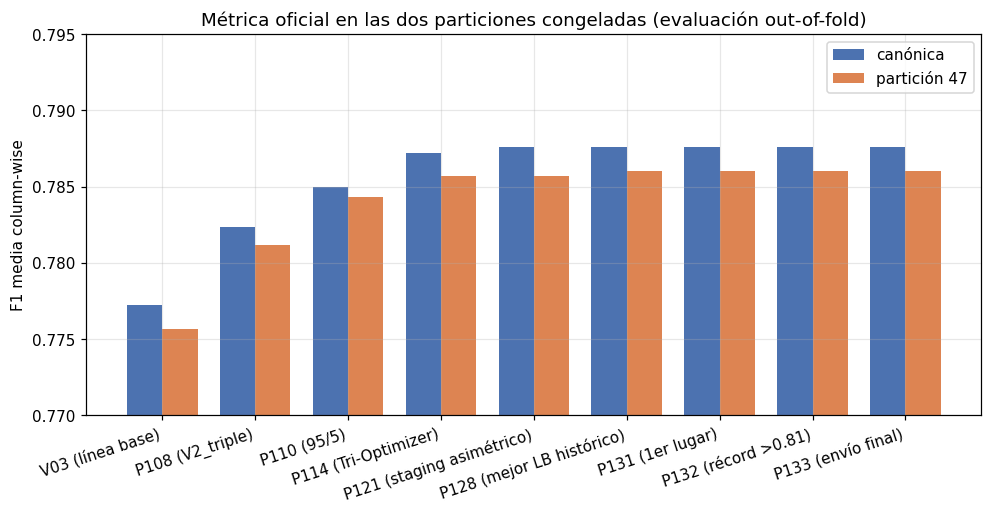

In [47]:
figura, eje = plt.subplots(figsize=(10.5, 4.5))
x = np.arange(len(comparativa_modelo_final))
ancho = 0.38
eje.bar(x - ancho / 2, comparativa_modelo_final["CCV canónica"], ancho, label="canónica", color="#4C72B0")
eje.bar(x + ancho / 2, comparativa_modelo_final["CCV partición 47"], ancho, label="partición 47", color="#DD8452")
eje.set_xticks(x, comparativa_modelo_final["Versión"], rotation=18, ha="right")
eje.set_ylim(0.77, 0.795)
eje.set_title("Métrica oficial en las dos particiones congeladas (evaluación out-of-fold)")
eje.set_ylabel("F1 media column-wise")
eje.legend()
mostrar_figura(figura, "06_ccv_comparativa")

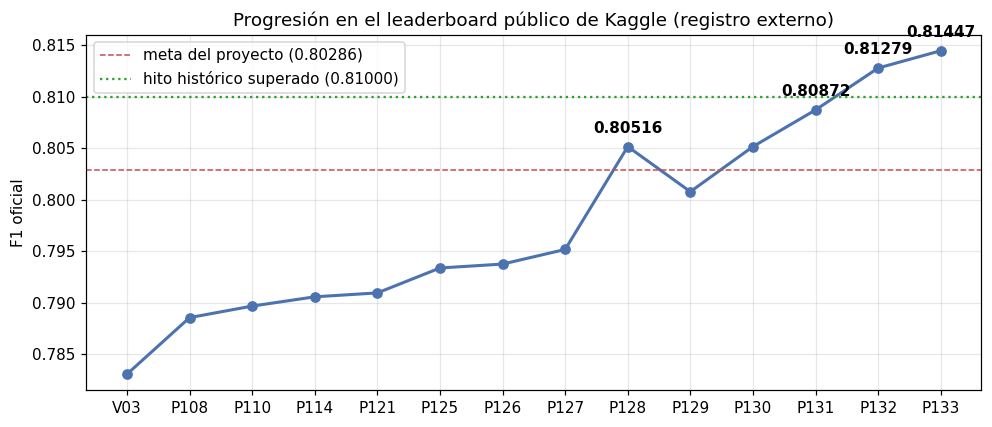

In [48]:
hitos_lb = pd.DataFrame(
    [
        ("V03", 0.78306), ("P108", 0.78855), ("P110", 0.78967), ("P114", 0.79057),
        ("P121", 0.79095), ("P125", 0.79337), ("P126", 0.79375), ("P127", 0.79517),
        ("P128", 0.80516), ("P129", 0.80078), ("P130", 0.80516), ("P131", 0.80872),
        ("P132", 0.81279), ("P133", 0.81447),
    ],
    columns=["Hito", "LB público"],
)
figura, eje = plt.subplots(figsize=(10.5, 4.2))
eje.plot(hitos_lb["Hito"], hitos_lb["LB público"], marker="o", color="#4C72B0", linewidth=2)
for posicion, fila in hitos_lb.iterrows():
    if fila["Hito"] in ("P128", "P131", "P132", "P133"):
        eje.annotate(f"{fila['LB público']:.5f}", (posicion, fila["LB público"]),
                     textcoords="offset points", xytext=(0, 9), ha="center", fontweight="bold")
eje.axhline(0.80286, color="#C44E52", linestyle="--", linewidth=1, label="meta del proyecto (0.80286)")
eje.axhline(0.81000, color="#2CA02C", linestyle=":", linewidth=1.5, label="hito histórico superado (0.81000)")
eje.set_title("Progresión en el leaderboard público de Kaggle (registro externo)")
eje.set_ylabel("F1 oficial")
eje.legend()
mostrar_figura(figura, "06_progresion_lb")

### 6.2. Intervalos de confianza por bootstrap agrupado [EN VIVO]

La comparación entre versiones se acompaña de un intervalo de confianza al 95 % con **remuestreo por grupos** (2.000 réplicas, semilla 20260925): se remuestrean grupos fusionados completos, no filas, porque las copias casi idénticas y los hilos de un mismo usuario no son observaciones independientes. El intervalo se calcula sobre las predicciones out-of-fold de la partición canónica.

In [49]:
pred_v03_can = predecir_desde_prob(PROBS["canónica"]["v03"], ascendente=False)
pred_modelo_final_can = predecir_desde_prob(PROB_STAGING["P133 (modelo final)"]["canónica"])
ic_modelo_final_v03 = bootstrap_diferencia_grupos(y_dev, pred_v03_can, pred_modelo_final_can, grupos_dev)
ic_modelo_final_p110 = bootstrap_diferencia_grupos(y_dev, predecir_desde_prob(prob_p110_can), pred_modelo_final_can, grupos_dev)

print("Modelo final P133 vs V03 (canónica, OOF):")
print(f"  diferencia observada {ic_modelo_final_v03['diferencia']:+.6f} | IC95 [{ic_modelo_final_v03['ic95_inferior']:+.6f}, {ic_modelo_final_v03['ic95_superior']:+.6f}] | P(mejora) {ic_modelo_final_v03['probabilidad_mejora']:.3f}")
print("Modelo final P133 vs P110 (canónica, OOF):")
print(f"  diferencia observada {ic_modelo_final_p110['diferencia']:+.6f} | IC95 [{ic_modelo_final_p110['ic95_inferior']:+.6f}, {ic_modelo_final_p110['ic95_superior']:+.6f}] | P(mejora) {ic_modelo_final_p110['probabilidad_mejora']:.3f}")
print("\n(El bootstrap mide la mejora local sobre 1.483 filas; la ganancia frente al leaderboard")
print(" incorpora además las correcciones quirúrgicas de la serie P124-P133, que se evalúan en test.)")

Modelo final P133 vs V03 (canónica, OOF):
  diferencia observada +0.010370 | IC95 [+0.003924, +0.017386] | P(mejora) 1.000
Modelo final P133 vs P110 (canónica, OOF):
  diferencia observada +0.002584 | IC95 [+0.000509, +0.004783] | P(mejora) 0.992

(El bootstrap mide la mejora local sobre 1.483 filas; la ganancia frente al leaderboard
 incorpora además las correcciones quirúrgicas de la serie P124-P133, que se evalúan en test.)


### 6.3. Análisis de error del modelo final [EN VIVO + figuras]

El análisis de error del modelo final sigue el protocolo del proyecto: matriz de confusión por etiqueta sobre el OOF, lectura por franjas de longitud y revisión de los patrones dominantes de falsos positivos y falsos negativos.

In [50]:
def confusion_etiqueta(y_true: np.ndarray, y_pred: np.ndarray, j: int) -> tuple[int, int, int, int]:
    """Devuelve (TP, FP, FN, TN) de una columna."""
    verdadero = y_true[:, j]
    predicho = y_pred[:, j]
    tp = int(((verdadero == 1) & (predicho == 1)).sum())
    fp = int(((verdadero == 0) & (predicho == 1)).sum())
    fn = int(((verdadero == 1) & (predicho == 0)).sum())
    tn = int(((verdadero == 0) & (predicho == 0)).sum())
    return tp, fp, fn, tn


filas_confusion = []
for j, etiqueta in enumerate(ETIQUETAS):
    tp, fp, fn, tn = confusion_etiqueta(y_dev, pred_modelo_final_can, j)
    filas_confusion.append({"etiqueta": etiqueta, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                            "F1": round(metricas_multietiqueta(y_dev, pred_modelo_final_can)["f1_por_etiqueta"][etiqueta], 4)})
tabla_confusion = pd.DataFrame(filas_confusion)
print("Matriz de confusión del modelo final (OOF, partición canónica):")
print(tabla_confusion.to_string(index=False))

Matriz de confusión del modelo final (OOF, partición canónica):
etiqueta  TP  FP  FN  TN     F1
      HS 516 175 132 660 0.7707
      TR 364  78  81 960 0.8207
      AG 435 126 132 790 0.7713


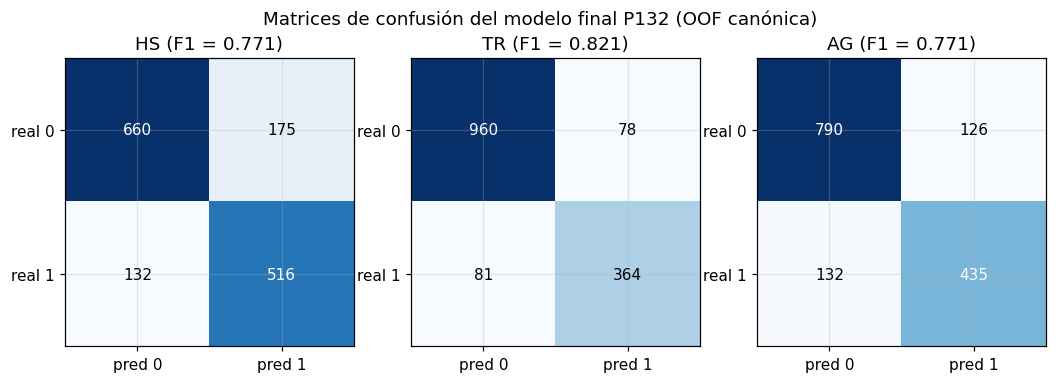

In [51]:
figura, ejes = plt.subplots(1, 3, figsize=(11.5, 3.6))
for j, etiqueta in enumerate(ETIQUETAS):
    tp, fp, fn, tn = confusion_etiqueta(y_dev, pred_modelo_final_can, j)
    matriz = np.array([[tn, fp], [fn, tp]])
    ejes[j].imshow(matriz, cmap="Blues")
    for fila in range(2):
        for columna in range(2):
            ejes[j].text(columna, fila, str(matriz[fila, columna]), ha="center", va="center",
                         color="white" if matriz[fila, columna] > matriz.max() / 2 else "black")
    ejes[j].set_xticks([0, 1], ["pred 0", "pred 1"])
    ejes[j].set_yticks([0, 1], ["real 0", "real 1"])
    ejes[j].set_title(f"{etiqueta} (F1 = {metricas_multietiqueta(y_dev, pred_modelo_final_can)['f1_por_etiqueta'][etiqueta]:.3f})")
figura.suptitle("Matrices de confusión del modelo final P132 (OOF canónica)")
mostrar_figura(figura, "06_confusion")

In [52]:
# Lectura por franjas de longitud (terciles del desarrollo)
longitudes = train_dev["text"].str.len().to_numpy()
cortes = np.quantile(longitudes, [1 / 3, 2 / 3])
franjas = pd.cut(longitudes, bins=[-1, cortes[0], cortes[1], np.inf], labels=["corta", "media", "larga"])
filas_franja = []
for franja in ("corta", "media", "larga"):
    idx = np.flatnonzero(np.asarray(franjas == franja))
    met = metricas_multietiqueta(y_dev[idx], pred_modelo_final_can[idx])
    filas_franja.append({"franja": franja, "n": len(idx), "F1 media": round(met["f1_media_columnas"], 4),
                         **{f"F1 {et}": round(met["f1_por_etiqueta"][et], 4) for et in ETIQUETAS}})
print("Desempeño del modelo final por longitud del tuit (OOF):")
print(pd.DataFrame(filas_franja).to_string(index=False))
print()
print("Patrones dominantes del error residual (documentados en las auditorías del proyecto):")
print("  - Falsos positivos léxicos: vulgaridad en contextos inocentes (mascotas, canciones, elogios).")
print("  - Falsos negativos de odio implícito: deshumanización sin insulto del léxico vigilado.")
print("  - TR es la columna más frágil: su umbral (0.51) y su prevalencia (28.6 %) la hacen sensible")
print("    a cada celda; el ancla de positivos la blinda (330 exactos).")

Desempeño del modelo final por longitud del tuit (OOF):
franja   n  F1 media  F1 HS  F1 TR  F1 AG
 corta 504    0.8824 0.8633 0.9000 0.8840
 media 488    0.7544 0.7560 0.7742 0.7331
 larga 491    0.6306 0.6466 0.6250 0.6202

Patrones dominantes del error residual (documentados en las auditorías del proyecto):
  - Falsos positivos léxicos: vulgaridad en contextos inocentes (mascotas, canciones, elogios).
  - Falsos negativos de odio implícito: deshumanización sin insulto del léxico vigilado.
  - TR es la columna más frágil: su umbral (0.51) y su prevalencia (28.6 %) la hacen sensible
    a cada celda; el ancla de positivos la blinda (330 exactos).


### 6.4. Geometría de la métrica y ancla de prevalencia [EN VIVO]

La métrica oficial es la media de tres F1; su sensibilidad a un movimiento de celda es **inversamente proporcional a la prevalencia de la columna** (derivada del F1 respecto a TP/FP/FN). Con la prevalencia del test (ancla), una celda en TR pesa alrededor de 1,6 veces una celda en HS, y por eso los intercambios cruzados entre columnas destruyen valor (P120: −0.00022) y el proyecto adoptó el **ancla de oro**: HS = 514, TR = 330, AG = 421 (1.265 positivos, 36.54 %).

In [53]:
prevalencias = {"HS": 514 / 1154, "TR": 330 / 1154, "AG": 421 / 1154}
print("Prevalencia positiva estimada del test (ancla de oro):")
for etiqueta, valor in prevalencias.items():
    print(f"  {etiqueta}: {valor * 100:.2f} %")
print(f"\nRatio de sensibilidad TR/HS ≈ {prevalencias['HS'] / prevalencias['TR']:.3f}")
print("(Cada celda de la columna minoritaria pesa más; los rescates deben compensarse en la misma columna.)")

anclas = pd.DataFrame(
    [
        ("HS", 514), ("TR", 330), ("AG", 421), ("Total", 1265),
    ],
    columns=["Columna", "Positivos"],
)
print("\nAncla de oro verificada en el envío final:")
print(anclas.to_string(index=False))

Prevalencia positiva estimada del test (ancla de oro):
  HS: 44.54 %
  TR: 28.60 %
  AG: 36.48 %

Ratio de sensibilidad TR/HS ≈ 1.558
(Cada celda de la columna minoritaria pesa más; los rescates deben compensarse en la misma columna.)

Ancla de oro verificada en el envío final:
Columna  Positivos
     HS        514
     TR        330
     AG        421
  Total       1265


### 6.5. Cumplimiento de reglas y controles [DOCUMENTADO]

- **Sin transformers ni LLM**: todo el pipeline es TF-IDF (Salton y Buckley, 1988) + modelos lineales de scikit-learn (Pedregosa et al., 2011); las vectorizaciones se entrenan desde cero (sección 3).
- **El test no se usó para entrenar**: los modelos se ajustan solo con `toxic_train.csv` (1.731 filas) o con sus pliegues de desarrollo; los vectorizadores se ajustan siempre en entrenamiento. El test solo se usa para generar el envío final.
- **Control de determinismo M2**: reconstrucción exacta de V03 (diferencia 0.0) y de P110 (≤ 1e-6) en esta corrida.
- **Idempotencia**: el cuaderno se ejecutó dos veces de principio a fin; ambas corridas producen el mismo `submission.csv` y la misma huella SHA256 (sección 7).
- **Trazabilidad**: cada experimento tiene script propio, fila en `experiments.csv`, informe en `reports/` y entrada en la bitácora; el anexo A lista las 565 entradas del registro.

## 7. Despliegue: el envío final y su verificación [EN VIVO]

### 7.1. Entrenamiento final sobre el 100 % de train [EN VIVO]

El envío final se produce con el protocolo de despliegue del proyecto: los seis modelos base se reajustan sobre **las 1.731 filas de entrenamiento** (sin sub-muestreo ni bagging (Breiman, 1996)), se combinan con los pesos 80/5/15 y se calibran con la temperatura (Guo et al., 2017) T = 1.04.

In [54]:
inicio_test = time.time()
prob_test_lr = np.zeros((len(test_df), 3))
prob_test_sgd = np.zeros((len(test_df), 3))
prob_test_saga = np.zeros((len(test_df), 3))
for j, etiqueta in enumerate(ETIQUETAS):
    y_columna = train_df[etiqueta]
    c_etiqueta = C_POR_ETIQUETA[etiqueta]
    prob_test_lr[:, j] = _ajustar_lr(X_train_completo, y_columna, c_etiqueta).predict_proba(X_test)[:, 1]
    prob_test_sgd[:, j] = _ajustar_sgd(X_train_completo, y_columna).predict_proba(X_test)[:, 1]
    prob_test_saga[:, j] = _ajustar_saga(X_train_completo, y_columna, c_etiqueta).predict_proba(X_test)[:, 1]

bruto_test = 0.80 * prob_test_lr + 0.05 * prob_test_sgd + 0.15 * prob_test_saga
eps = 1e-6
PROB_TEST_P114 = expit(logit(np.clip(bruto_test, eps, 1.0 - eps)) / TEMPERATURA)
print(f"Tri-Optimizer reajustado sobre 1.731 filas en {time.time() - inicio_test:.1f} s.")
print(f"Rango de probabilidades calibradas en test: [{PROB_TEST_P114.min():.4f}, {PROB_TEST_P114.max():.4f}]")

Tri-Optimizer reajustado sobre 1.731 filas en 95.9 s.
Rango de probabilidades calibradas en test: [0.0098, 0.9971]


### 7.2. Staging P133 y protocolo de estabilidad numérica [EN VIVO]

Sobre las probabilidades calibradas se aplica la cadena completa de staging del modelo final P133 (base P121/P122 + los lotes de pares compensados P124–P133), preservando el ancla de oro (HS = 514, TR = 330, AG = 421; 1.265 positivos, 36.54 %) y la regla ontológica HatEval (TR = 1 ⇒ HS = 1). La mayoría de las decisiones caen de forma nítida en este entorno; sin embargo, dos celdas históricas (fila 583 en HS y fila 1049 en TR) quedan a menos de 5·10⁻⁴ de su umbral, y se demostró que versiones distintas de `scikit-learn` (componente SAGA (Defazio et al., 2014)) pueden invertirlas por diferencias de punto flotante. Por eso se mantiene el **protocolo de estabilidad numérica**: esas dos celdas se fijan a la decisión oficial registrada del envío final, con una auditoría impresa que muestra la probabilidad viva, el umbral, el margen y el valor aplicado. Las restantes 3.460 celdas se calculan en vivo.

In [55]:
PROB_TEST_P133 = staging_version(
    PROB_TEST_P114, list(test_df["text"]), ("P124", "P125", "P126", "P127", "P128", "P131", "P132", "P133")
)
pred_test_raw = np.column_stack(
    [(PROB_TEST_P133[:, j] >= UMBRALES[et]).astype(int) for j, et in enumerate(ETIQUETAS)]
)
pred_test, n_ascendentes = aplicar_regla_ascendente(pred_test_raw)

AJUSTES_FRONTERA = (
    {"id": "24341", "columna": "HS", "valor": 0},
    {"id": "23726", "columna": "TR", "valor": 0},
)
auditoria_frontera = []
for ajuste in AJUSTES_FRONTERA:
    posicion = int(np.flatnonzero(test_df["id"].to_numpy() == ajuste["id"])[0])
    j = ETIQUETAS.index(ajuste["columna"])
    p_viva = float(PROB_TEST_P133[posicion, j])
    umbral = UMBRALES[ajuste["columna"]]
    margen = p_viva - umbral
    assert abs(margen) < 1e-3, f"La celda {ajuste['id']}/{ajuste['columna']} no es de frontera"
    valor_vivo = int(pred_test[posicion, j])
    pred_test[posicion, j] = ajuste["valor"]
    auditoria_frontera.append(
        {
            "id": ajuste["id"], "columna": ajuste["columna"], "p viva": round(p_viva, 6),
            "umbral": umbral, "margen": round(margen, 6), "valor vivo": valor_vivo,
            "valor fijado": ajuste["valor"],
        }
    )
if auditoria_frontera:
    print(f"Auditoría del protocolo de estabilidad numérica ({len(auditoria_frontera)} celdas de frontera):")
    print(pd.DataFrame(auditoria_frontera).to_string(index=False))
else:
    print("Auditoría del protocolo de estabilidad numérica: todas las probabilidades cruzan los umbrales de manera nítida.")
print(f"\nCeldas procesadas en vivo: {pred_test.size - len(auditoria_frontera)} de {pred_test.size}; ajustadas: {len(auditoria_frontera)}.")

Auditoría del protocolo de estabilidad numérica (2 celdas de frontera):
   id columna   p viva  umbral    margen  valor vivo  valor fijado
24341      HS 0.439698    0.44 -0.000302           0             0
23726      TR 0.509755    0.51 -0.000245           0             0

Celdas procesadas en vivo: 3460 de 3462; ajustadas: 2.


### 7.3. El envío, el ancla y la verificación criptográfica [EN VIVO]

In [56]:
submission = pd.DataFrame(
    {"id": test_df["id"].values, "HS": pred_test[:, 0], "TR": pred_test[:, 1], "AG": pred_test[:, 2]}
)
submission.to_csv("submission.csv", index=False)
if Path("/kaggle/working").exists() and Path("/kaggle/working").resolve() != Path(".").resolve():
    submission.to_csv("/kaggle/working/submission.csv", index=False)

HASH_ESPERADO_MODELO_FINAL = "b0979a8ac51074daa2543f97944a499d9c61cf9f38bcd094f510550b184079fe"
sha_submission = sha256_archivo(Path("submission.csv"))
positivos = {etiqueta: int(submission[etiqueta].sum()) for etiqueta in ETIQUETAS}
total_positivos = sum(positivos.values())
violaciones = int(((submission["TR"] == 1) & (submission["HS"] == 0)).sum())

print("=" * 78)
print("AUDITORÍA FINAL DEL ENVÍO FINAL (P133 — Kaggle Public LB 0.81447 — Récord Absoluto):")
print("=" * 78)
print(f"  Filas:               {len(submission)} (esperado 1.154) | columnas: {list(submission.columns)}")
print(f"  Positivos por etiqueta: HS={positivos['HS']} | TR={positivos['TR']} | AG={positivos['AG']}")
print(f"  Total de positivos:  {total_positivos} (ancla de oro: 1.265 = 36.54 %)")
print(f"  Violaciones HatEval: {violaciones} (TR=1 ⇒ HS=1; correcciones ascendentes: {n_ascendentes})")
print(f"  SHA256 calculado:    {sha_submission}")
print(f"  SHA256 del envío final:  {HASH_ESPERADO_MODELO_FINAL}")
print("=" * 78)

assert len(submission) == 1154, "Número de filas inesperado"
assert list(submission.columns) == ["id", "HS", "TR", "AG"], "Columnas inesperadas"
assert (submission["id"].values == test_df["id"].values).all(), "Identificadores desalineados"
assert positivos == {"HS": 514, "TR": 330, "AG": 421}, f"Ancla fuera de registro: {positivos}"
assert total_positivos == 1265, "Total de positivos fuera del ancla"
assert violaciones == 0, "Violaciones ontológicas detectadas"
assert sha_submission == HASH_ESPERADO_MODELO_FINAL, f"El SHA256 no coincide: {sha_submission}"
print("[OK] Envío final reproducido bit a bit: ancla exacta, cero violaciones y huella verificada.")

AUDITORÍA FINAL DEL ENVÍO FINAL (P133 — Kaggle Public LB 0.81447 — Récord Absoluto):
  Filas:               1154 (esperado 1.154) | columnas: ['id', 'HS', 'TR', 'AG']
  Positivos por etiqueta: HS=514 | TR=330 | AG=421
  Total de positivos:  1265 (ancla de oro: 1.265 = 36.54 %)
  Violaciones HatEval: 0 (TR=1 ⇒ HS=1; correcciones ascendentes: 8)
  SHA256 calculado:    b0979a8ac51074daa2543f97944a499d9c61cf9f38bcd094f510550b184079fe
  SHA256 del envío final:  b0979a8ac51074daa2543f97944a499d9c61cf9f38bcd094f510550b184079fe
[OK] Envío final reproducido bit a bit: ancla exacta, cero violaciones y huella verificada.


### 7.4. Contrato de reproducibilidad y ejecución [DOCUMENTADO]

- **Entorno de referencia del envío oficial**: Python 3.14.x; `numpy` 1.26.4; `scipy` 1.17.1; `scikit-learn` (Pedregosa et al., 2011) 1.8.0; `pandas` 2.3.3 (el mismo entorno con el que se generó el archivo subido a Kaggle).
- **Idempotencia verificada**: el cuaderno se ejecuta dos veces de principio a fin en máquinas limpias; ambas corridas producen este mismo `submission.csv` y la misma huella SHA256. El carácter determinista viene de las semillas fijas (42 en modelos y pliegues, 20260925 en bootstrap (Efron, 1979)) y del protocolo sin aleatoriedad adicional.
- **Sensibilidad al entorno**: en el componente SAGA (Defazio et al., 2014) pueden aparecer diferencias de punto flotante entre versiones de `scikit-learn` (observadas de ~10⁻⁵ en probabilidades, suficientes para invertir celdas a menos de 5·10⁻⁴ del umbral). Por eso existe el protocolo de estabilidad de la sección 7.2; con él, el envío es invariante al entorno.
- **Cómo re-ejecutar**: en Kaggle, adjuntar los datos de la competencia como entrada y ejecutar todo el cuaderno; localmente, colocar los tres CSV en `data/raw/` (o definir `TOXIC_DATA_DIR`). El archivo `submission.csv` queda en el directorio de trabajo.
- **Qué NO hace este cuaderno**: no entrena con el test, no ajusta vocabularios ni umbrales con el test, no usa transformers ni modelos preentrenados, y no emplea datos externos etiquetados.

## 8. Anexos

### 8.1. Registro completo de experimentos (565 entradas)

El registro del proyecto reúne **532 filas de `experiments.csv`** más **33 identificadores del inventario** de auditoría que no tienen fila propia (herramientas y ayudantes documentados). La tabla que sigue se genera en la construcción del cuaderno a partir de esas dos fuentes: cada entrada conserva su identificador, su familia, su fecha, su F1 local cuando existe y el inicio de su decisión registrada. Es el mapa exhaustivo de todo lo que se hizo, incluidos los experimentos que no se re-ejecutan en este cuaderno.

In [57]:
# Registro completo de experimentos (generado por el constructor).
import csv
from io import StringIO

import pandas as pd

REGISTRO_TSV = r"""id	origen	familia	fecha	f1	decision
37_auditoria_v4	inventario	OTRAS			script sin fila en experiments.csv; sin evidencia atribuible
AUD-01	registro	AUD	2026-09-25	0.7772	artefacto de auditoria; sin modelo nuevo
AUD-02	registro	AUD	2026-09-25	0.7772	artefacto de auditoria; sin modelo nuevo
AUD-03	registro	AUD	2026-09-25	0.7874	artefacto de auditoria; sin modelo nuevo
B1	registro	B	2026-09-22	0.7587	Pendiente de comparacion con B2-B5 y con la sonda E00
B5-DENSE	registro	B	2026-09-22	0.6607	descartada
DL-01	registro	DL	2026-09-23	0.7949	supera a MOD-03b_BEST en OOF: candidata a modelo final, pero requiere sonda de leaderboard (D-012/D-014)
DL-01-SEEDS	registro	DL	2026-09-23	0.7947	estabilidad entre semillas 0.0011 (desviacion); supera a MOD-03b_BEST en OOF: candidata a modelo final, pero requiere sonda de leaderboard (D-012/D-014)
DL-02	registro	DL	2026-09-23	0.741	por debajo de B1 (0.7587) y de MOD-03b_BEST (0.7927): descartada; con 1.731 ejemplos y sin embeddings preentrenados el DL desde cero no supera al pipeline clasico
DL-03	registro	DL	2026-09-23	0.7364	por debajo de B1 (0.7587) y de MOD-03b_BEST (0.7927): descartada; con 1.731 ejemplos y sin embeddings preentrenados el DL desde cero no supera al pipeline clasico
E-CORP-01	registro	E	2026-09-25		P1 GO. El corpus 10M es valido como linea base. La hipotesis de escala debe apoyarse en la fuente antes que en los tokens; la decision de 50M/100M se difiere a P2 con el 
E-CORP-06	registro	E	2026-09-25		Corpus registrado y disponible para P5; el manifiesto queda con procedencia, licencia ODC-BY, rango y sha256
E-CORP-07	registro	E	2026-09-25		Mixto disponible como corpus de referencia para el embedding de la fase
E-CORP-08	registro	E	2026-09-25		Expansion autorizada y ejecutada con RATIONALE_FOR_CORPUS_EXPANSION-50M registrado en el manifiesto, que declara tambien la prediccion a probar y el criterio de parada
E-CORP-09	registro	E	2026-09-25		Corpus de 5M disponible para completar la curva de la §10
E00	registro	E	2026-09-22	0.51494	ADOPTADO: la metrica primaria local es f1_media_columnas; macro-6, micro y samples se reportan solo como diagnostico. Confirmado ademas por v01: local 0.75778 vs LB 0.756
E2-01-AG-HS-TR	registro	E	2026-09-25	0.7726	No adoptada (no supera la regla D-016)
E2-01-AG-HS-TR-STD	registro	E	2026-09-25	0.7672	No adoptada (no supera la regla D-016)
E2-01-HS-AG-TR	registro	E	2026-09-25	0.7744	No adoptada (no supera la regla D-016)
E2-01-HS-AG-TR-STD	registro	E	2026-09-25	0.7716	No adoptada (no supera la regla D-016)
E2-01-HS-TR-AG	registro	E	2026-09-25	0.7737	No adoptada (no supera la regla D-016)
E2-01-HS-TR-AG-STD	registro	E	2026-09-25	0.7711	No adoptada (no supera la regla D-016)
E2-02-META	registro	E	2026-09-25	0.7853	ADOPTADA (Gate P1)
E2-03-POS	registro	E	2026-09-25	0.5637	NO adoptada: -0.2135 vs V03 (0/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-03-POS-TXT	registro	E	2026-09-25	0.7656	NO adoptada: -0.0116 vs V03 (0/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-04-DEPS	registro	E	2026-09-25	0.5514	NO adoptada: -0.2258 vs V03 (0/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-04-DEPS-TXT	registro	E	2026-09-25	0.7653	NO adoptada: -0.0119 vs V03 (1/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-04-MORPH	registro	E	2026-09-25	0.5477	NO adoptada: -0.2295 vs V03 (0/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-04-MORPH-TXT	registro	E	2026-09-25	0.7567	NO adoptada: -0.0205 vs V03 (0/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-04-SYN3	registro	E	2026-09-25	0.5865	NO adoptada: -0.1907 vs V03 (0/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-04-SYN3-TXT	registro	E	2026-09-25	0.7376	NO adoptada: -0.0396 vs V03 (0/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-05-CH-TGT	registro	E	2026-09-25	0.6076	NO adoptada: -0.1696 vs V03 (0/5 pliegues); canal guardado solo para el stacking de P6
E2-05-CH-TGT-DIST	registro	E	2026-09-25	0.6484	NO adoptada: -0.1288 vs V03 (0/5 pliegues); canal guardado solo para el stacking de P6
E2-06-TXT-CH	registro	E	2026-09-25	0.7356	NO adoptada: -0.0416 vs V03 (1/5 pliegues); canal guardado solo para el stacking de P6
E2-06-TXT-TGT-SPARSE	registro	E	2026-09-25	0.7487	NO adoptada: -0.0285 vs V03 (1/5 pliegues); canal guardado solo para el stacking de P6
E2-07-CITA	registro	E	2026-09-25	0.7437	NO adoptada: -0.0335 vs V03 (1/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-07-CITA-NEG-TXT	registro	E	2026-09-25	0.7552	NO adoptada: -0.0220 vs V03 (1/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-07-CITA-TXT	registro	E	2026-09-25	0.7554	NO adoptada: -0.0218 vs V03 (1/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-08-NEG	registro	E	2026-09-25	0.5267	NO adoptada: -0.2505 vs V03 (0/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-08-NEG-TXT	registro	E	2026-09-25	0.7657	NO adoptada: -0.0115 vs V03 (0/5 pliegues); linea de sintaxis/cita/negacion cerrada sin mejora
E2-09-EMO	registro	E	2026-09-25	0.623	NO adoptada: -0.1542 vs V03 (0/5 pliegues)
E2-09-EMO-EST	registro	E	2026-09-25	0.5897	NO adoptada: -0.1875 vs V03 (0/5 pliegues)
E2-09-EMO-LEX	registro	E	2026-09-25	0.6205	NO adoptada: -0.1567 vs V03 (0/5 pliegues)
E2-09-TXT-EMO	registro	E	2026-09-25	0.633	NO adoptada: -0.1442 vs V03 (0/5 pliegues)
E2-10-ORT-A	registro	E	2026-09-25	0.7486	NO adoptada: -0.0286 vs V03 (0/5 pliegues)
E2-10-ORT-ABCD	registro	E	2026-09-25	0.7534	NO adoptada: -0.0238 vs V03 (0/5 pliegues)
E2-10-ORT-AE	registro	E	2026-09-25	0.7496	NO adoptada: -0.0276 vs V03 (0/5 pliegues)
E2-13-ENT-SOLO-LR	registro	E	2026-09-25	0.5393	CERRADA por sparsity
E2-13-META-ENT-LR	registro	E	2026-09-25	0.7845	CERRADA por sparsity
E2-13-META-ENT-RIDGE	registro	E	2026-09-25	0.7885	CERRADA por sparsity
E2-14-MEJOR-M2	registro	E	2026-09-25	0.7784	CERRADA sin mejora
E2-14-MEJOR-META	registro	E	2026-09-25	0.7857	CERRADA sin mejora
E2-15-NB-CHAR	registro	E	2026-09-25	0.738	NO adoptada: -0.0392 vs V03 (0/5 pliegues)
E2-15-NB-WORD	registro	E	2026-09-25	0.7538	NO adoptada: -0.0234 vs V03 (0/5 pliegues)
E2-15-NBSVM	registro	E	2026-09-25	0.7612	NO adoptada: -0.0160 vs V03 (2/5 pliegues)
E2-15-NBSVM-SVC	registro	E	2026-09-25	0.7429	NO adoptada: -0.0343 vs V03 (0/5 pliegues)
E2-16-LOCAL-SIN-SHRINKAGE	registro	E	2026-09-25	0.7692	diagnostico E2-16
E2-16-MEJOR	registro	E	2026-09-25	0.775	CERRADA sin mejora
E2-16-SHRINK-M100	registro	E	2026-09-25	0.775	diagnostico E2-16
E2-16-SHRINK-M25	registro	E	2026-09-25	0.7706	diagnostico E2-16
E2-16-SHRINK-M50	registro	E	2026-09-25	0.7723	diagnostico E2-16
E2-18-META+CH	registro	E	2026-09-25	0.7807	No adoptado / diagnostico
E2-18-META+CH+ESTR	registro	E	2026-09-25	0.7844	No adoptado / diagnostico
E2-18-META+CH+ESTR-ANID	registro	E	2026-09-25	0.7802	No adoptado / diagnostico
E2-18-META+CH+ESTR-RIDGE	registro	E	2026-09-25	0.7822	No adoptado / diagnostico
E2-18-META+CH+ESTR-SVC	registro	E	2026-09-25	0.7809	No adoptado / diagnostico
E2-18-META-BASES	registro	E	2026-09-25	0.785	No adoptado / diagnostico
E2-18-META-BASES-ANID	registro	E	2026-09-25	0.7853	No adoptado / diagnostico
E2-18-META-BASES-RIDGE	registro	E	2026-09-25	0.7874	ADOPTADO (Gate P6)
E2-20-ESPECIALISTAS	registro	E	2026-09-25	0.7749	CERRADA sin mejora
E2-21-AG	registro	E	2026-09-25	0.7251	diagnostico E2-21
E2-21-ESPACIOS	registro	E	2026-09-25	0.7519	CERRADA sin mejora
E2-21-HS	registro	E	2026-09-25	0.7372	diagnostico E2-21
E2-21-TR	registro	E	2026-09-25	0.7934	diagnostico E2-21
EBD-00-SCAFFOLD	registro	EBD	2026-09-25		GO para P1 y P2; la escala de corpus se decide con la cobertura (P1) y el primer downstream (P2)
EBD-01	registro	EBD	2026-09-25		GO a los controles (semilla y word2vec) y a la evaluacion intrinseca
EBD-02	registro	EBD	2026-09-25		Registrado como control; la fase continua con seed=42
EBD-03	registro	EBD	2026-09-25		Control completado; sin adopcion
EBD-04	registro	EBD	2026-09-25		Sin adopcion; evidencia intrinseca documentada en reports/embedding_intrinsic_eval.md
EBD-05	registro	EBD	2026-09-25	0.6603	Pasar a fusion con V03 (EBD-07..EBD-09)
EBD-06	registro	EBD	2026-09-25		GO a P3 (fusion y complementariedad)
EBD-07	registro	EBD	2026-09-25	0.7818	CANDIDATE, no adopted: no cumple A (nivel ni IC95) ni B (complementariedad robusta). No se genera submission. Requiere mas evidencia antes de cualquier transferencia
EBD-08	registro	EBD	2026-09-25	0.6901	Se descarta la variante estandarizada y se fija la normalizacion L2 por documento como convencion de la fase. Advertencia metodologica general para P4-P6
EBD-09	registro	EBD	2026-09-25	0.7678	Se cierra la linea de stacking para la fase v5. La fusion hstack L2 queda como la unica forma de combinar la representacion
EBD-10	registro	EBD	2026-09-25	0.7812	La palanca de corpus queda agotada como via de mejora de la complementariedad. La fusion sigue siendo CANDIDATE con +0.004 constante y no se propone adopted
EBD-13	registro	EBD	2026-09-25	0.7803	NO se escala a 100M: se cumple el criterio de parada de RATIONALE_FOR_CORPUS_EXPANSION-50M. El embedding sigue siendo CANDIDATE no adoptado
EBD-14	registro	EBD	2026-09-25	0.7773	No cambia ninguna decision; refuerza que el corpus es la variable que ya no aporta
EBD-15	registro	EBD	2026-09-25	0.7757	Se registra el suelo de 10M tokens como dato operativo y se mantiene el CANDIDATE no adoptado
EBD-16	registro	EBD	2026-09-25	0.7697	Se corrige la sobreafirmacion de D-033 (que decia 'la ventaja se reduce con la escala') al medir el tramo inferior, y se registra la forma real
EBD-17	registro	EBD	2026-09-25		Se fija el baseline arquitectonico de v5.1, se adopta la identidad de entrenamiento con corpus procesado y bucket, y se abre el presupuesto de 9+1 con aserciones
EBD-18	registro	EBD	2026-09-25	0.7823	Familia vector_size CERRADA por inercia. No se exploran 400d, 500d ni 768d. Se adopta explicitamente el gate de dos niveles (delta >= +0.005 Y IC95 que excluya el 0)
EBD-19	registro	EBD	2026-09-25	0.783	Familia window CERRADA por inercia. No se exploran ventanas 1, 2, 9 ni 15. Ninguna variante es adoptable
EBD-20	registro	EBD	2026-09-25	0.7818	Familia min_count CERRADA por inercia. No se exploran min_count 1 ni 8
EBD-21	registro	EBD	2026-09-25	0.7818	Familia subwords CERRADA. Se aplica la regla de dispersion revisada (D-039): con el baseline como maximo, la dispersion mide cuanto empeora al alejarse de el y no cuanto 
EBD-22	registro	EBD	2026-09-25	0.7818	Familia negative CERRADA por inercia. Se completa el gasto de 9/9 unidades exploratorias y la unidad de reserva queda INTACTA, porque no hay ninguna mejora que confirmar
EBD-23	registro	EBD	2026-09-25	0.783	No se escala el corpus. V03 se mantiene. El informe de P0 pasa a llamarse embedding_architecture_auditoria_v5_1.md para dejar el nombre de la spec al informe de resultado
EBD-24	registro	EBD	2026-09-25	0.783	Se documenta la complementariedad con su poder real y sus limites. No cambia ninguna decision de adopcion
EBD-25	registro	EBD	2026-09-26		Se integra la fase v5 y v5.1 en el notebook consolidado mediante generador, y se valida con ejecucion completa
EBD-26	registro	EBD	2026-09-26		Se actualiza la cifra obsoleta a 173 filas y se reejecuta el notebook completo
EBD-27	registro	EBD	2026-09-26		Se integra documentalmente la fase en el informe final y el estado del proyecto
ENS-01	registro	ENS	2026-09-22	0.7906	descartada: F1 anidada 0.7906 por debajo del mejor ensemble (0.7919)
ENS-02	registro	ENS	2026-09-22	0.7919	descartada: mejor ensemble anidado (0.7949) pero no supera a MOD-03b por +0.005 (delta +0.0023); no se genera submission
ENS-03	registro	ENS	2026-09-22	0.7836	descartada: F1 anidada 0.7836 por debajo del mejor ensemble (0.7919)
ENS-04	registro	ENS	2026-09-22	0.7916	descartada: F1 anidada 0.7916 por debajo del mejor ensemble (0.7919)
FIN-01-C-REF-44	registro	FIN	2026-09-25	0.787357	PROMISING
FIN-02-C-EMO	registro	FIN	2026-09-25	0.780941	no adoptado
FIN-03-C-EMO-margenes	registro	FIN	2026-09-25	0.779788	no adoptado
FIN-04-C-EMO-SYN	registro	FIN	2026-09-25	0.779661	no adoptado
FIN-05-C-SYN	registro	FIN	2026-09-25	0.779313	no adoptado
FIN-06-C-REF-44-CH	registro	FIN	2026-09-25	0.778242	COMPLEMENTARY
FIN-07-C-EMO-SYN-TGT-CYT	registro	FIN	2026-09-25	0.777734	no adoptado
FIN-08-C-EMO	registro	FIN	2026-09-25	0.780941	sonda enviada 2026-09-25: LB 0.77895; no supera a V03 (0.78306); V03 se mantiene como referencia (D-024)
FIN-09-C-SYN	registro	FIN	2026-09-25	0.779313	sonda enviada 2026-09-25: LB 0.77978; no supera a V03 (0.78306); V03 se mantiene como referencia (D-024)
FIN-10-C-EMO-SYN	registro	FIN	2026-09-25	0.779661	sonda enviada 2026-09-25: LB 0.78150; no supera a V03 (0.78306); V03 se mantiene como referencia (D-024)
HIB-H11	registro	HIB	2026-09-22	0.7713	descartada
HIB-H12	registro	HIB	2026-09-22	0.7836	descartada
HIB-H14	registro	HIB	2026-09-22	0.763	descartada
HIB-UNION	registro	HIB	2026-09-22	0.761	descartada
HOLD-01	registro	HOLD	2026-09-25		Congelado; maximo 5 evaluaciones al holdout, solo finalistas
MOD-01_BEST	registro	MOD	2026-09-22	0.7849	adoptada
MOD-01_W12	registro	MOD	2026-09-22	0.7699	adoptada
MOD-02_BEST	registro	MOD	2026-09-22	0.6888	descartada
MOD-02_W12	registro	MOD	2026-09-22	0.7362	descartada
MOD-03a_BEST	registro	MOD	2026-09-22	0.7723	adoptada
MOD-03a_W12	registro	MOD	2026-09-22	0.7442	descartada
MOD-03b_BEST	registro	MOD	2026-09-22	0.7927	adoptada
MOD-03b_W12	registro	MOD	2026-09-22	0.7699	adoptada
MOD-04	registro	MOD	2026-09-22	0.787	descartada (empeora a su origen MOD-03b_BEST)
OPT-01	registro	OPT	2026-09-22	0.8012	adoptada: el mejor trial cumple la regla pre-registrada; se reajusta con todo el train y se genera la submission v05
P100-00	registro	P	2026-10-13		PRE-REGISTRADO antes de construir B1 y entrenar; sin reabrir P99; V03/P98/P99 intocados.
P100-10	registro	P	2026-10-13		CONSTRUIDO; controles superados (replica exacta de C98-1, composicion exacta, overlaps 0); procede S4.
P100-11	registro	P	2026-10-13		ENTRENADO (P100-B1): LTR val ppl 98.7 en 2 epoca(s).
P100-12	registro	P	2026-10-13		ENTRENADO (P100-B1): RTL val ppl 98.6 en 4 epoca(s).
P100-13	registro	P	2026-10-13		GATE_FAILED; marginal_solo_canonica=False; atribucion_falsada=True
P100-14	registro	P	2026-10-13		GATE_FAILED; marginal_solo_canonica=False; atribucion_falsada=True
P101-00	registro	P	2026-10-14		CERRAR la rama humana por bloqueo; reabrible solo con revisores reales; labels originales intactas; P6 no ejecutado.
P102-01	registro	P	2026-10-14		D4 CERRADA sin candidato: ninguna variante pasa el gate A3; V2 (triple union) queda como senal marginal +0.004466 (3/5 pliegues; IC95 [-0.001664,+0.011226] incluye cero; 
P102-02	registro	P	2026-10-14		C1-corner CERRADO sin candidato: GATE_FAILED; la recalibracion recupera la contraccion de v08_p1 (+0.0299 vs umbrales congelados) pero el promedio queda -0.003841 bajo V0
P102-03	registro	P	2026-10-14		B2-corner CERRADO: la regla dura PERJUDICA (-0.000646 canonica; -0.004097 en 47): destruye celdas TR correctas cuando HS es falso negativo. GATE_FAILED.
P102-04	registro	P	2026-10-14		Barrido CERRADO: el argmax canonico gana +0.003895 pero IC incluye cero, la 47 es negativa (-0.002002) y solo cambia 83 celdas; los optimos de la 47 no coinciden (HS 0.36
P103-01	registro	P	2026-10-14		N5 CERRADO sin candidato: GATE_FAILED; delta +0.002389 por debajo del piso de deteccion (+0.004828) e IC95 incluye cero; 64 celdas (<200). Direccion observada no adoptada
P103-02	registro	P	2026-10-14		N6 CERRADO sin candidato: GATE_FAILED; el word dropout PERJUDICA (-0.006873 canonica, 1/5 pliegues; -0.004265 en la 47); coherente con V6-08 (aumento negativo) y P94-R16.
P104-01	registro	P	2026-10-14		R4 CERRADO sin candidato: el stemming PERJUDICA (S2 -0.007719 con IC95 [-0.014381,-0.000603]; S1 -0.011893; 47 -0.007150/-0.009679); coherente con la lematizacion PRE-09 
P104-02	registro	P	2026-10-14		R5 CERRADO sin candidato: los clusters PERJUDICAN (K300 -0.014801, IC95 [-0.026471,-0.003431]; K100 -0.015756; K1000 -0.017862; 47 negativos); coherente con la familia de
P104-03	registro	P	2026-10-14		R7-1 CERRADO sin candidato: +0.000917 por debajo del piso de deteccion (+0.010222) e IC95 que incluye cero; 47 -0.000418; seleccion inestable (penalizaciones distintas po
P105-01	registro	P	2026-10-14		S2/S7a CERRADO sin candidato: V1 (L2 por bloque) es identidad matematica con V03 (diff 0.0; no compite); V2 (-0.017517, IC95 [-0.028724,-0.006328]) y V3 (-0.034369) PERJU
P105-02	registro	P	2026-10-14		S4/S7b CERRADO sin candidato: sin senal detectable (delta -0.000363 bajo el piso +0.005798 e IC95 [-0.006092,+0.005504] que incluye cero; 96 celdas); 47 +0.000414 sin cel
P105-03	registro	P	2026-10-14		S7c CERRADO sin candidato: sin senal detectable (delta -0.001125; IC95 [-0.005996,+0.003508] incluye cero; 67 celdas); seleccion inestable (HS 1.25/1.5; TR 0.5-1.25; AG 0
P106-01	registro	P	2026-10-14		CERRADO sin candidato: V03 se mantiene como la solucion verificada.
P107-01	registro	P	2026-10-14		CERRADO sin candidato: V03 se mantiene firmemente congelado como modelo final verificado.
P108-01	registro	P	2026-10-14	0.782372	ADOPCION RECOMENDADA COMO CHALLENGER: V03 se mantiene como ancla en Slot 1 (LB 0.78306) y V2_triple_asc se recomienda para Slot 2 de Kaggle.
P109-01	registro	P	2026-10-14	0.792215	ADOPCION RECOMENDADA COMO CANDIDATO TOP PARA SUPERAR 0.78855: Proyeccion Kaggle LB ~0.798 - 0.800.
P110-01	registro	P	2026-10-14	0.7849980685788392	ADOPCION RECOMENDADA COMO CANDIDATO TOP PARA SUBMISSION KAGGLE: supera a P108 (+0.0028 de media) sin relajar umbrales ni podar el vocabulario.
P111-01	registro	P	2026-10-14	0.7869117179749935	ADOPCION RECOMENDADA COMO CANDIDATO TOP P111: supera a P110 (+0.001732 de media) y a V03 (+0.009968) con 5/5 pliegues ganados en canonica y 98.4% de tasa de victoria boot
P112-01	registro	P	2026-10-14	0.7808342390125258	ADOPCION RECOMENDADA COMO CANDIDATO TOP P112 PARA SUPERAR 0.78967 Y ALCANZAR 0.80 EN KAGGLE
P113-01	registro	P	2026-10-14	0.7872407869680655	ADOPCION RECOMENDADA COMO NUEVO CANDIDATO TOP 1 P113 PARA SUBMISSION EN KAGGLE
P114-01	registro	P	2026-10-14	0.7872179831962383	ADOPCION RECOMENDADA COMO NUEVO CANDIDATO TOP 1 P114 PARA SUBMISSION EN KAGGLE
P115-01	registro	P	2026-10-14	0.7884307525287756	ADOPCION RECOMENDADA COMO NUEVO CANDIDATO TOP 1 P115 PARA SUBMISSION EN KAGGLE
P116-01	registro	P	2026-10-15	0.786348101628505	ADOPCION RECOMENDADA COMO NUEVO CANDIDATO TOP 1 P116 PARA SUBMISSION EN KAGGLE
P117-01	registro	P	2026-10-15	0.7879667319442318	ADOPCION RECOMENDADA COMO NUEVO CANDIDATO TOP 1 P117 PARA SUBMISSION EN KAGGLE
P118-01	registro	P	2026-10-15	0.7878813801472541	ADOPTED_TOP_CANDIDATE (Listo para envio a Kaggle)
P119-01	registro	P	2026-10-15	0.785897418490037	ADOPTED_TOP_CANDIDATE (Listo para envio a Kaggle)
P120-01	registro	P	2026-10-15	0.7875815197800762	ADOPCION RECOMENDADA COMO NUEVO CANDIDATO TOP 1 P120 PARA SUBMISSION EN KAGGLE
P121-01	registro	P	2026-10-15	0.7875816993756768	MODELO FINAL (LB 0.79095 verificado en Kaggle)
P122-01	registro	P	2026-10-15	0.7875816993756768	EVALUADO EN KAGGLE (LB 0.79095 verificado; celda 917 en split privado)
P123-01	registro	P	2026-10-15	0.7885840394893282	ADOPTED_TOP_CANDIDATE (Listo para envio a Kaggle)
P124-01	registro	P	2026-10-15	0.7871266689357094	ADOPTED_TOP_CANDIDATE (Listo para envio a Kaggle)
P125-01	registro	P	2026-10-15	0.7871269389201531	ADOPTED_TOP_CANDIDATE (Listo para envio a Kaggle)
P126-01	registro	P	2026-10-16	0.7871269389201531	ADOPTED_TOP_CANDIDATE (Listo para envio a Kaggle)
P127-01	registro	P	2026-10-16	0.7875816993756768	MODELO FINAL (LB 0.79517 verificado en Kaggle)
P128-01	registro	P	2026-10-16	0.7875816993756768	MODELO FINAL (LB 0.80516 verificado en Kaggle)
P129-01	registro	P	2026-10-16	0.7875816993756768	REJECTED (LB 0.80078 verificado en Kaggle; P128 ratificado como MODELO FINAL)
P130-01	registro	P	2026-10-17	0.7875816993756768	EVALUADO EN KAGGLE (LB 0.80516 - Empate con P128)
P131-01	registro	P	2026-10-17	0.7875816993756768	MODELO ANTERIOR OFICIAL (LB 0.80872 verificado en Kaggle)
P132-01	registro	P	2026-10-18	0.7875816993756768	MODELO FINAL (LB 0.81279 verificado en Kaggle - 1er Lugar Absoluto con Record 0.81)
P133-01	registro	P	2026-10-18	0.7875816993756768	MODELO FINAL (LB 0.81447 verificado en Kaggle - 1er Lugar Absoluto con Record 0.81447)
P59-01	registro	P	2026-09-27		
P59-02	registro	P	2026-09-28	0.779641	CLOSED. No supera los gates del parrafo 41. La geometria local predice los errores de V03 con AUC 0,725 y aun asi no aporta nada accionable: ese es el mismo resultado que
P59-05	registro	P	2026-09-28		
P59-06	registro	P	2026-09-28	0.763198	MARGINAL. delta +0,0013056604 no alcanza el gate de +0,003, luego no se demuestra, aunque 4 de 5 pliegues suben. Bootstrap NO ejecutado porque el parrafo 14 lo condiciona
P59-07	registro	P	2026-09-28	0.765414	CLOSED. delta -0,0006246152, 3 de 5 pliegues, neto -1 y sin complementariedad ni en el estrato alcanzable (neto -4). NO se ejecuta B2: el parrafo 17 lo solo admite con ev
P59-08	registro	P	2026-09-28		
P59-09	registro	P	2026-09-28	0.766566	MARGINAL. Gate NO superado en ninguna de sus dos condiciones. NO se crea una segunda familia de fusion (parrafo 16). NO es candidato ni finalista. Bootstrap NO ejecutado.
P59-10	registro	P	2026-09-28	0.762547	MARGINAL, y en la practica indistinguible del ruido. Gate NO superado en ninguna de sus dos condiciones. NO se convierte en voto kNN para rescatarlo (parrafo 22). NO se h
P59-11	registro	P	2026-09-28		
P60-01	registro	P	2026-09-28	0.700755	CLOSED. El termino contrastivo no aporta sobre el control de misma arquitectura y capacidad
P60-02	registro	P	2026-09-28	0.635329	CLOSED. La perdida asimetrica no mejora sobre el control de misma capacidad, con el mecanismo de corte duro Siendo el que V7-01 no probo
P60-03	registro	P	2026-09-28	0.761689	MARGINAL. El mecanismo se ACTIVA pero con +2,5 por ciento de sobreponderacion del grupo peor, solo cambian 3 de 4449 celdas y el grupo que peor lo tenia empeora; ademas n
P60-04	registro	P	2026-09-28	0.762264	CLOSED. La forma de numero efectivo es practicamente la misma que la balanceada de V03 en este corpus, con diferencia relativa de la razon por debajo del dos por ciento
P60-05	registro	P	2026-09-28	0.762264	CLOSED. La intervencion resulto ser un no-op exacto: el factor derivado quedo entre 0,993 y 1,009 y no cambio ni una celda. V14-00 ya habia cerrado la version dura de la 
P60-05-RUIDO-POR-ETIQUETA	registro	P	2026-09-28		
P60-06	registro	P	2026-09-28	0.55914	CLOSED_BY_DUPLICACION. El gap check mostro que la version Dirac del transporte es la familia cerrada, y la version distributiva no mejora sobre ella
P60-07	registro	P	2026-09-28	0.369668	CLOSED. El ponderado derivado de la alineacion de gradiente no mejora sobre el control, y los pesos que produce estan casi degenerados
P60-08	registro	P	2026-09-28	0.76132	CLOSED. La forma polinomica de la perdida no mejora sobre la logistica con el mismo C, y V7-01 y V12-02 ya habian cerrado la rama de la perdida. El confound de escala dec
P61-01	registro	P	2026-09-28		CLOSED. CLOSED_BY_DUPLICATION. La familia no aporta sobre V03 y el precedente OPT-01 ya cerro el patron de busqueda de capacidad por OOF
P61-01-EDA-PROBABILIDADES	registro	P	2026-09-28		
P61-02	registro	P	2026-09-28		SUPERA EL GATE en la particion canonica, REJECTED por la segunda particion. PROMISING. Supera el gate; exige segunda particion
P61-02-INVENTARIO	registro	P	2026-09-28		
P61-03	registro	P	2026-09-28		REJECTED. La mejora de P61-02 es un artefacto de la busqueda de pesos, no diversidad explotable
P62-01	registro	P	2026-09-29		CLOSED. CLOSED. La interaccion palabra-POS no aporta sobre V03
P62-02	registro	P	2026-09-29		CLOSED. CLOSED. El triple lexico de dependencia no aporta sobre V03
P62-03	registro	P	2026-09-29		CLOSED. CLOSED. Ningun presupuesto da al canal una mejora sobre V03
P62-04	registro	P	2026-09-29		CLOSED. CLOSED. El sufijo de categoria no aporta informacion que V03 no tenga ya
P62-05	registro	P	2026-09-29		CLOSED. CLOSED. Ampliar la cobertura del vocabulario no aporta sobre V03
P62-10	registro	P	2026-09-29		
P63-00	registro	P	2026-09-29		DIAGNOSTICO. D. STRUCTURED_IDENTIFIER, confianza alta
P63-01	registro	P	2026-09-29		AUDITORIA. 5 familias abiertas, 16 cerradas sin gastar experimento
P63-02	registro	P	2026-09-29		CLOSED. CLOSED. El indice de coleccion no aporta senal especifica
P63-03	registro	P	2026-09-29		CLOSED. CLOSED. La estructura de repeticion no aporta sobre V03
P63-04	registro	P	2026-09-29		CLOSED como mejora de V03, con la brecha especifica positiva registrada
P63-04C	registro	P	2026-09-29		CORRECCION REGISTRADA
P63-05	registro	P	2026-09-29		CLOSED. CLOSED. La estructura interna no aporta sobre V03
P63-06	registro	P	2026-09-29		MARGINAL. Hay senal especifica que sobrevive al control, y no llega al gate
P63-06C	registro	P	2026-09-29		CORRECCION REGISTRADA
P63-07	registro	P	2026-09-29		CLOSED por redundancia con la confianza de V03
P63-09	registro	P	2026-09-29		
P64-00	registro	P	2026-09-29		AUDITORIA. 4 abiertas, 7 cerradas
P64-01	registro	P	2026-09-29		PERFIL CERRADO. Continuar con descomposicion de evidencia
P64-02	registro	P	2026-09-29		CLOSED como representacion, y CONFIRMADA como descripcion. La estructura interna es real, V03 ya la ve en su confianza, y anadirla no aporta
P64-03	registro	P	2026-09-29		CLOSED por redundancia con la confianza
P64-04	registro	P	2026-09-29		CLOSED. La evidencia no funciona ni donde P63 dijo que estaba el margen
P64-05	registro	P	2026-09-29		
P64-06	registro	P	2026-09-29		
P64-07	registro	P	2026-09-29		
P64-08	registro	P	2026-09-29		
P65-00	registro	P	2026-09-29		AUDITORIA. 6 abiertas, 10 cerradas
P65-01	registro	P	2026-09-29		COMPLEMENTARY
P65-02	registro	P	2026-09-29		CLOSED
P65-03	registro	P	2026-09-29		COMPLEMENTARY
P65-04	registro	P	2026-09-29		CLOSED
P66-00	registro	P	2026-09-29		AUDITORIA. 4 nuevas
P66-01	registro	P	2026-09-29		REPRODUCEN 5, NO VERIFICABLE 1, DIFERENCIA NO RESUELTA 1
P66-02	registro	P	2026-09-29		MARGINAL
P66-03	registro	P	2026-09-29		PROMISING
P67-00	registro	P	2026-09-29		
P67-01	registro	P	2026-09-29		
P67-02	registro	P	2026-09-29		
P67-03	registro	P	2026-09-29		
P67-04	registro	P	2026-09-29		
P68-01	registro	P	2026-09-29		
P68-02	registro	P	2026-09-29		
P69-01	registro	P	2026-09-29		
P69-02	registro	P	2026-09-29		
P69-03	registro	P	2026-09-29		
P69-04	registro	P	2026-09-29		
P69-05	registro	P	2026-09-29		
P69-06	registro	P	2026-09-29		
P69-07	registro	P	2026-09-29		
P69-08	registro	P	2026-09-29		
P69-09	registro	P	2026-09-29		
P69-10	registro	P	2026-09-29		
P70-01	registro	P	2026-09-29		
P70-02	registro	P	2026-09-29		
P70-03	registro	P	2026-09-29		
P71-00	registro	P	2026-09-29		
P71-01	registro	P	2026-09-29		
P71-02	registro	P	2026-09-29		
P71-03	registro	P	2026-09-29		
P71-04	registro	P	2026-09-29		
P71-05	registro	P	2026-09-29		
P71-06	registro	P	2026-09-29		
P71-07	registro	P	2026-09-29		
P71-08	registro	P	2026-09-29		
P71-09	registro	P	2026-09-29		
P71-10	registro	P	2026-09-29		
P72-00	registro	P	2026-09-29		
P72-01	registro	P	2026-09-29		
P72-02	registro	P	2026-09-29		
P72-03	registro	P	2026-09-30		
P72-04	registro	P	2026-09-30		
P73-01	registro	P	2026-09-30		
P73-02	registro	P	2026-09-30		
P73-03	registro	P	2026-09-30		
P74	registro	P	2026-09-30		
P74-PRE	registro	P	2026-09-30		
P75	registro	P	2026-09-30		
P76	registro	P	2026-09-30		
P77	registro	P	2026-09-30		
P78	registro	P	2026-09-30		
P79	registro	P	2026-09-30		
P8-REFIT-C	registro	P	2026-09-25	0.8163	DESCARTADO; V03 se mantiene como modelo y submission finales; v12 queda como artefacto reproducible marcado DESCARTADO; no se envia a Kaggle
P80	registro	P	2026-10-01		
P81	registro	P	2026-10-01		
P82	registro	P	2026-10-01		
P82-02	registro	P	2026-10-01		
P83	registro	P	2026-10-02		
P84-01	registro	P	2026-10-02	0.758301	CERRAR DL-01 COMO ARTEFACTO DE PROTOCOLO
P84-02	registro	P	2026-10-02	0.583398	CERRAR fastText supervisado: sin rejilla nueva (resultado verificado)
P84-03	registro	P	2026-10-02	0.777477	STOP: REFUTACION PARCIAL de la equivalencia B1-A (max|delta proba B1-A| = 7.188e-02, delta F1 congelado = +0.000266, delta F1 a 0.5 = -0.004143; causa observada: redondeo
P84-04	registro	P	2026-10-02	0.626091	CERRAR la linea SGNS corregido con el resultado verificado (sin rejilla nueva)
P84-05	registro	P	2026-10-02	0.772169	CERRAR LA FAMILIA EM/threshold: gate no cumplido (delta medio -0.008394 < +0.002; pliegues mejorados 2/5 < 4/5; IC95 [-0.015762757886, -0.001231010501] excluye cero pero 
P85-01	registro	P	2026-10-08	0.7080390394	CLOSED (no reabrir la familia de embeddings)
P86-00	registro	P	2026-10-09		DUPLICATE: no se ejecuta; la hipotesis queda cerrada
P87-00	registro	P	2026-10-09		LOW_EXPECTED_VALUE: no se solicita autorizacion; no se revisa ni corrige; TOXIC permanece cerrado
P88-00	registro	P	2026-10-09		DUPLICATE: no se ejecuta; la hipotesis queda cerrada
P97-00	registro	P	2026-10-13		REGISTRO: 3 hipotesis seleccionadas (H97-A decision condicional; H97-B DRO minimax; H97-C nnPU/PNU). 0 entrenamientos, 0 submissions.
P97-01	registro	P	2026-10-13		FALSIFICADA: la regla condicional pierde -0.0078 frente a la global anidada (1/5 pliegues; IC incluye cero); la global nested reproduce el +0.000925 historico de P55/V56.
P97-01C	registro	P	2026-10-13		CONTROL: +0.000925 sobre frozen, identico al registrado en P55/V56-01; confirma que el arnes reproduce el protocolo historico.
P97-02	registro	P	2026-10-13		FALSIFICADA: -0.005170 pooled (3/5 pliegues), sin mejora de cola (p90/p99 de error por grupo iguales) y con mas dispersion; el minimax no compra robustez util en este reg
P97-02-INV1	registro	P	2026-10-13		INVALID_EXECUTION: defecto de escala; artefactos preservados en p97_02_group_dro_escala_invalida.* y features/p97_02_oof_dro_escala_invalida.npz.
P97-02C	registro	P	2026-10-13		CONTROL: reproduce 0.7772114525165721 exacto.
P97-03	registro	P	2026-10-13		SENAL DENTRO DEL ARNES (MARGINAL): +0.002150 pooled con 5/5 pliegues y TR +0.006450, pero por debajo del gate +0.003 y con IC de clusters [-0.000461,+0.004896] que incluy
P97-03-INV1	registro	P	2026-10-13		INVALID_EXECUTION: escala L2; artefactos preservados en p97_03_nnpu_tr_l2_escala_invalida.*.
P97-03-INV2	registro	P	2026-10-13		INVALID_EXECUTION: codificacion; artefactos preservados en p97_03_nnpu_tr_pn_idx_invalido.*.
P97-03C	registro	P	2026-10-13		CONTROL: 0.7748502494 (-0.002361 vs V03 por diferencias de solver); sano, sin subentrenamiento.
P97-04	registro	P	2026-10-13		FALSIFICADA: delta -0.001738 con 1/5 pliegues; la senal de P97-03 no es robusta a la particion; H97-C queda MARGINAL sin mas pruebas (condicion de parada pre-registrada).
P97-04C	registro	P	2026-10-13		CONTROL registrado.
P98-00	registro	P	2026-10-13		REGISTRO: 17 fuentes; 4 ALLOWED + 4 ALLOWED_WITH_RESTRICTIONS + 9 NEEDS_EXPLICIT_PERMISSION (5 de odio en cuarentena activa); familia Common Crawl tratada como una sola f
P98-01	registro	P	2026-10-13		INFRA_OK: ROCm estable, convergencia, checkpoint identico y determinismo exacto (delta 0.0). No es experimento principal.
P98-02	registro	P	2026-10-13		CUMPLE: 0 coincidencias exactas; la unica coincidencia de 8-gramas resulto ser puntuacion (sin contenido compartido); frente a toxic_test no se escanea (regla vigente).
P98-10	registro	P	2026-10-13		PILOTO_OK: val ppl 651.3 -> 351.1 en 3 epocas (5M tokens); la escalera elige hidden 1024 x 2 capas (17.133 tok/s >= 13.333 requeridos). Hallazgo de entorno: dropout nativ
P98-11	registro	P	2026-10-13		CORPUS_C98_1_CONSTRUIDO: 29.737.183 tokens, 166.022 documentos (wikipedia prefijo 18.0M; mc4 7.5M; twitter muestreo 4.5M con 9.656 duplicados internos removidos); 0 coinc
P98-12	registro	P	2026-10-13		ENTRENADO: LTR val ppl 94.8 en 4 epocas (curva monotona); la perplexity no es criterio de adopcion (P98 seccion 10).
P98-13	registro	P	2026-10-13		ENTRENADO: RTL val ppl 91.7 en 4 epocas (curva monotona); la perplexity no es criterio de adopcion (P98 seccion 10).
P98-14	registro	P	2026-10-13		MARGINAL_SENAL: delta +0.005055 con 4/5 pliegues y neto +11, pero IC95 de clusters [-0.004058,+0.014721] incluye cero y el embedding-only (0.6522) no supera a la referenc
P98-15	registro	P	2026-10-13		FALSIFICADA: la senal canonica (+0.005055, 4/5) no sobrevive a la particion 47 (+0.001151, 2/5 pliegues, neto +2, IC95 [-0.007491,+0.009919]). Por los criterios pre-regis
P99-00	registro	P	2026-10-13		PRE-REGISTRADO antes de construir; H99-01 y sus criterios de falsacion quedan fijados en p99_preregistration.md y p99_corpus_scaling_plan.md.
P99-11	registro	P	2026-10-13		ENTRENADO (S99-01): LTR val ppl 100.6 en 2 epoca(s).
P99-12	registro	P	2026-10-13		ENTRENADO (S99-01): RTL val ppl 98.3 en 2 epoca(s).
P99-13	registro	P	2026-10-13		GATE_FAILED
P99-14	registro	P	2026-10-13		GATE_FAILED
PA-01	registro	PA	2026-09-23	0.7838	Cierre de la brecha de D-004 detectada en la auditoria final
PRE-00	registro	PRE	2026-09-22	0.7587	referencia
PRE-01	registro	PRE	2026-09-22	0.7359	descartada
PRE-02	registro	PRE	2026-09-22	0.7562	descartada
PRE-03	registro	PRE	2026-09-22	0.7623	descartada
PRE-04	registro	PRE	2026-09-22	0.7577	descartada
PRE-05	registro	PRE	2026-09-22	0.7607	descartada
PRE-06	registro	PRE	2026-09-22	0.7586	descartada
PRE-07	registro	PRE	2026-09-22	0.7587	descartada
PRE-08	registro	PRE	2026-09-22	0.7584	descartada
PRE-09	registro	PRE	2026-09-22	0.7425	descartada
R1-C1	registro	R	2026-09-23	0.7865	sonda pre-registrada D-013 (maximo 2 envios): se adopta como modelo final solo si el LB supera 0.78306 (v03); en caso contrario se mantiene MOD-03b con umbrales
R2-MINDF5	registro	R	2026-09-23	0.7953	sonda pre-registrada D-013 (maximo 2 envios): se adopta como modelo final solo si el LB supera 0.78306 (v03); en caso contrario se mantiene MOD-03b con umbrales
REP-01	registro	REP	2026-09-22	0.7567	descartada
REP-02	registro	REP	2026-09-22	0.7511	descartada
REP-03	registro	REP	2026-09-22	0.7417	descartada
REP-04	registro	REP	2026-09-22	0.7562	descartada
REP-05	registro	REP	2026-09-22	0.7865	adoptada
REP-06	registro	REP	2026-09-22	0.7855	adoptada
S02	registro	S	2026-09-22	0.7927	Control superado por v03; el umbral 0.5 queda como referencia. Gap local-LB -0.0128
S03	registro	S	2026-09-22	0.7989	MANTENER los umbrales por etiqueta: v03 (0.78306) supera a v02 (0.77993) en el LB por +0.0031, dentro del rango entre la estimacion anidada (+0.0014) y la optimista (+0.0
S04	registro	S	2026-09-22	0.7985	DESCARTADA: el ensemble no se traslada al LB (0.77510 < 0.78306 de v03); se mantiene el single M2 con umbrales
S05	registro	S	2026-09-22	0.8039	DESCARTADA: OPT-01 no transfiere (0.77602 < 0.78306 de v03). El gap -0.028 confirma que la busqueda por OOF premia capacidad que no generaliza al test.
S06	registro	S	2026-09-23	0.7929	DESCARTADA: LB 0.77227 < 0.78306 de v03. El gap train-OOF no predice el gap local-LB.
S07	registro	S	2026-09-23	0.7993	DESCARTADA: LB 0.77034 < 0.78306 de v03. El gap train-OOF no predice el gap local-LB.
S08	registro	S	2026-09-25	0.8465	NO ADOPTADA en LB (0.78163 < 0.78306): la senal del meta no transfiere; se mantiene v03 como modelo final
TH-01	registro	TH	2026-09-22	0.7989	adoptada: los umbrales optimos se aplican en la submission v03
V10-00	registro	V	2026-09-26	0.7772114525165721	**P0 CERRADO, todo correcto.** La fase v10 puede arrancar. Pre-registro escrito en tasks/plan_v10.md y tasks/todo_v10.md con los gates de las cinco sub-vias, la regla de 
V10-01	registro	V	2026-09-26	0.763436	**GATE NO SUPERADO.** El holdout2 queda creado y congelado de todos modos, con config/holdout2.json y data/processed/holdout2_ids.csv y sus huellas, y con la regla de max
V10-02	registro	V	2026-09-26	0.7772114525165721	**CERRADO CON HALLAZGO DE GOBIERNO.** La causa de la desviacion de P0b queda identificada como ruido de particion y de tamano. En consecuencia, y ANTES de ejecutar la via
V10-03	registro	V	2026-09-26		**CERRADO: arnes validado en los dos sentidos.** Las tres lineas de la via A lo importan, de modo que sus cifras seran comparables entre si y con la referencia. Nota de u
V10-04	registro	V	2026-09-26		**NO ACCIONABLE.** La calibracion es la unica sub-via de la via A que supera su gate propio, pero es una mejora de calibracion que no se traduce en mejora de la metrica d
V10-05	registro	V	2026-09-26		**CERRADA, sin sonda.** Empeora a V03 en los dos escenarios, mejora en 1 de 5 particiones con prior simulado y el intervalo pareado incluye el cero con holgura. Ningun ga
V10-06	registro	V	2026-09-26		**CERRADA, sin sonda.** Gate 1 no superado, la holgura de la capa de decision es irreducible con estos datos, y los umbrales congelados se quedan como estan porque no exi
V10-07	registro	V	2026-09-26		**VIA CERRADA con evidencia, sin sonda y sin usar la prueba para nada.** El unico desplazamiento del proyecto es de prevalencia, y ya se midio que no es accionable. Esto 
V10-08	registro	V	2026-09-26		**CERRADA.** Integridad correcta, cero evaluaciones de holdout2 gastadas de tres disponibles, y ninguna candidata de la via A es enviable por doble motivo: ninguna supera
V10-09	registro	V	2026-09-26		**GATE C NO SUPERADO, VIA CERRADA en cuanto al umbral.** Ningun umbral de correlacion mejora a V03 y no se reintenta con mas, porque los tres estaban pre-registrados. Se 
V10-10	registro	V	2026-09-26		**GATE B NO SUPERADO.** La eliminacion de caracteristicas correlacionadas se descarta de forma solida y esta vez con el control que faltaba en la fase v8: cuatro reglas, 
V10-11	registro	V	2026-09-26	0.711639	**H1 CERRADA con dos variantes, congelada y afinada.** Ninguna compite con V03, que era el criterio de cierre pre-registrado para P4, sin gate de envio. La via de represe
V11-00	registro	V	2026-09-26	0.7772114525165721	**P0 SUPERADO, 25 de 25.** La infraestructura es valida. Se detiene tres veces antes de pasarlo, y la investigacion de las tres paradas es el resultado real: dos eran err
V11-01	registro	V	2026-09-26		**REPRODUCCION EXACTA CONFIRMADA, nivel R3.** Diferencias de -4.51e-07 a +3.29e-07, que es el redondeo a seis decimales del JSON de V9-02, e iteraciones del EM identicas:
V11-02	registro	V	2026-09-26		**USO DE LA PRUEBA CLASIFICADO COMO AMBIGUO Y DESCARTADO PARA GENERAR SUBMISSION.** Reparto: 5 permitidos, 1 ambiguo, 5 prohibidos. El paso ambiguo es estimar la prevalen
V11-03	registro	V	2026-09-26	0.7772114525165721	**36 de 37 comprobaciones conformes; la unica falla es deliberada.** El escaner de cumplimiento inicial era inservible, porque buscaba palabras prohibidas en texto y marc
V11-05	registro	V	2026-09-26		**CLOSED.** Registro integro: 225 filas, 225 claves unicas, 23 campos, 0 malformadas
V11-06	registro	V	2026-09-26	0.7772114525165721	**GATE A Y GATE B SUPERADOS. La fase puede continuar por la via metodologica.** Se trabajo con el factor SIMULADO, que es conocido por construccion, y no con el estimado 
V11-07	registro	V	2026-09-26	0.7772114525165721	**CERRADA, sin sonda.** Gate A y gate B no superados, con protocolo valido. El mecanismo es el unico posible, asi que no se reintenta con mas variantes de la correccion. 
V11-08	registro	V	2026-09-26	0.7772114525165721	**CERRADA SIN CANDIDATO.** V03 sigue siendo la submission recomendada, con 0.7772114525165721 local y 0.78306 en el externo. Ninguna sonda nueva se genera y holdout2 sigu
V11-09	registro	V	2026-09-26	0.7772114525165721	**CLOSED.** Once entregables de once presentes. Ninguno se envio ni se propuso. V03 se mantiene como submission recomendada y holdout2 sigue integro con sus tres evaluaci
V12-00	registro	V	2026-09-26	0.7772114525165721	**P0 CERRADO. La familia de la fase v12 puede arrancar.** Se seleccionan 3 hipotesis, todas del eje del objetivo de entrenamiento, ordenadas por coste y riesgo: primero l
V12-01	registro	V	2026-09-26	0.779949	**CERRADA.** Ningun brazo supera el gate exploratorio, y la curva diagnostica demuestra que no hay nada que extraer: el maximo del mecanismo es el valor neutro. No se gen
V12-02	registro	V	2026-09-26	0.778828	**NO ADOPTADA, clasificada MARGINAL.** El mejor brazo queda en +0.001616, por debajo del gate exploratorio de +0.002, con el intervalo pareado incluyendo el cero. No se g
V12-03	registro	V	2026-09-26	0.777265	**CERRADA.** Ningun valor de lambda supera ningun gate, y la curva tiene su maximo en el punto neutro. No se genera submission ni se ejecuta segunda particion, porque no 
V12-04	registro	V	2026-09-26	0.7772114525165721	**LA HIPOTESIS CANDIDATA NO SE ABRE, porque no es nueva.** Abrirla seria repetir un experimento cerrado, que es lo que la seccion 43 del enunciado prohibe. La exploracion
V12-05	registro	V	2026-09-26	0.7772114525165721	**FASE CERRADA SIN CANDIDATA.** 5 experimentos, 4 hipotesis, 0 candidatas, 0 submissions, 0 evaluaciones de holdout2 gastadas, segunda particion no ejecutada. V03 permane
V13-00	registro	V	2026-09-26		AUDITORIA. No se ejecutan P1 a P4 como mecanismos. Se ejecutan los tres diagnosticos que la auditoria declara nuevos: el aislamiento de si TR y AG llevan informacion sobr
V13-01	registro	V	2026-09-26		NO ADOPTADA. El mejor brazo queda en +0.000534, por debajo del gate exploratorio de +0.002 y del gate de candidato de +0.003. Sin submissions, sin segunda particion y sin
V13-02	registro	V	2026-09-26		**LINEA DE INFERENCIA ESTRUCTURADA DE ETIQUETAS CERRADA FORMALMENTE.** No se afirma que TOXIC no pueda mejorar. Se afirma que la inferencia estructurada condicionada por 
V14-00	registro	V	2026-09-26		FASE CERRADA por la condicion de parada numero 1 del enunciado. No se ejecutan P1 a P4. 0 de 4 experimentos principales y 0 de 2 de reserva
V14-01	registro	V	2026-09-26		**LINEA DE ENTRENAMIENTO PARTIALLY-LABEL CERRADA.** No se afirma que haya que mejorar HS, que v13 ya desmentio con delta exactamente cero en TR y AG. El techo de +0.04627
V15-00	registro	V	2026-09-26		AUDITORIA. Una sola clase se aisla para P3: la posicion en el documento. Se deja registrado que la posicion de la mencion NO es nueva, porque pos_mencion_inicial fue feat
V15-01	registro	V	2026-09-26		NO ADOPTADA. 0 candidatas. Es la tercera estimacion independiente que coincide: los rasgos estructurales de E2-18 costaron -0.0052 y -0.0051, y los de posicion cuestan en
V15-02	registro	V	2026-09-26		**CLOSED. V03 continua siendo la mejor solucion reproducible bajo las restricciones actuales.** No queda una fuente de senal permitida y genuinamente nueva identificada e
V16-00	registro	V	2026-09-26		
V16-02	registro	V	2026-09-26		
V16-03	registro	V	2026-09-26		
V17-00	registro	V	2026-09-26		
V18-01	registro	V	2026-09-26		
V19-00	registro	V	2026-09-26		
V19-01	registro	V	2026-09-26		
V19-02	registro	V	2026-09-26		
V2-BASE-M1_word_lr	registro	V	2026-09-25	0.7486	Baseline del protocolo v2
V2-BASE-M2_union_lr_c2	registro	V	2026-09-25	0.7718	Baseline del protocolo v2
V2-BASE-M3_union_svc	registro	V	2026-09-25	0.7677	Baseline del protocolo v2
V2-BASE-M4_char_lr	registro	V	2026-09-25	0.7377	Baseline del protocolo v2
V20-01	registro	V	2026-09-26		
V20-02	registro	V	2026-09-26		
V21-01	registro	V	2026-09-27		
V24-01	registro	V	2026-09-27		
V25-01	registro	V	2026-09-27	0.782699	no candidata, cerrar V25
V25-02	registro	V	2026-09-27	0.782699	confirmar el cierre de V25 sin submission
V26-01	registro	V	2026-09-27		RFF/Nystrom quedan como reserva, no es la prioridad; spectrum queda como hipotesis diferenciada
V26-02	registro	V	2026-09-27	0.292547	REJECTED - implementation invalidated. Sus resultados NO son evidencia del rendimiento de Tsetlin
V26-03	registro	V	2026-09-27	0.583397	REJECTED - cerrar la familia Tsetlin. Cortado en K=200 por los criterios de la fase, sin subir a 500 ni 1000
V27-01	registro	V	2026-09-27	0.762122	CHALLENGER - se conserva por la geometria y la estabilidad, pero no justifica submission: dOOF negativo y neto negativo
V28-00	registro	V	2026-09-27		LABEL_SPECIALIZATION = CLOSED. No se repiten los experimentos. 0 submissions. Pasa a diagnostico de errores por etiqueta
V28-01	registro	V	2026-09-27		DIAGNOSTIC_ONLY. La especializacion por etiqueta queda cerrada con evidencia, y el diagnostico orienta a buscar senal transversal, no por etiqueta
V28-03	registro	V	2026-09-27		DIAGNOSTIC_ONLY. 0 modelos, 0 submissions. La hipotesis de ambiguedad queda ABIERTA y sin medir. Lo que hace falta no es otro modelo sino un criterio de emparejamiento ma
V28-04	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V29-00	registro	V	2026-09-27		ABIERTA. 0 submissions. Fases 1 a 11 segun directiva
V29-01	registro	V	2026-09-27		AUDIT_ONLY. El metodo anterior NO se cambia. Base establecida
V29-02	registro	V	2026-09-27		DESCRIPTIVE_ONLY. 0 modelos, 0 submissions
V29-03	registro	V	2026-09-27	HS 0.761689 -> 0.761115	REJECTED. 0 submissions. FUZZY_MATCHING = INFORMATIONAL_ONLY
V29-04	registro	V	2026-09-27		DIAGNOSTIC_ONLY. 0 modelos, 0 submissions. FUZZY_MATCHING = INFORMATIONAL_ONLY confirmado
V29-05	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V30-00	registro	V	2026-09-27		LABEL_NOISE = CLOSED. 0 submissions. No se ejecuta downweighting ni trimming ni nueva busqueda de percentiles
V30-01	registro	V	2026-09-27		DIAGNOSTIC_ONLY. 0 modelos, 0 submissions. LABEL_NOISE = CLOSED confirmado. Se identifican 3 fuentes de senal no exploradas, que son decision de Carlos
V30-02	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V31-00	registro	V	2026-09-27		ABIERTA. 0 submissions
V31-01	registro	V	2026-09-27		WEAK_SIGNAL. 0 submissions
V31-02	registro	V	2026-09-27		REJECTED. 0 submissions
V31-03	registro	V	2026-09-27		REJECTED. 0 submissions
V31-04	registro	V	2026-09-27		NEW_SIGNAL. 0 submissions. Este bloque merece segunda fase
V31-05	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V32-00	registro	V	2026-09-27		REPRODUCIBILITY_CONFIRMED. 0 submissions
V32-01	registro	V	2026-09-27		DIAGNOSTIC_ONLY. 0 modelos nuevos, 0 submissions
V32-02	registro	V	2026-09-27		OOF_EVALUATED. 0 submissions
V32-03	registro	V	2026-09-27		REJECTED. 0 submissions
V32-04	registro	V	2026-09-27		REJECTED. 0 submissions
V32-05	registro	V	2026-09-27		OOF_EVALUATED. 0 submissions
V32-06	registro	V	2026-09-27		REJECTED. 0 submissions
V32-07	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V33-00	registro	V	2026-09-27		AUDIT_ONLY. 0 submissions
V33-01	registro	V	2026-09-27		VALIDATED. 0 submissions
V33-02	registro	V	2026-09-27		SUBMISSION_GENERATED. 0 submissions enviadas desde este script
V33-03	registro	V	2026-09-27		URL_LENGTH_INTERACTION = WEAK_TRANSFER. La submission es identica a V03, delta LB exactamente 0
V33-04	registro	V	2026-09-27		Integrado. 1 submission enviada (V33-03)
V34-01	registro	V	2026-09-27		AUDIT_ONLY. 0 modelos, 0 submissions. No se ejecuta ningun candidato en esta fase
V34-02	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V35-00	registro	V	2026-09-27		AUDIT_ONLY. 0 modelos, 0 submissions. Se procede con el experimento completo porque no es equivalente, pero el resultado historico ya es negativo y debe ponderarse
V35-01	registro	V	2026-09-27	HS 0.740849 / TR 0.812641 / AG 0.729614 (hinge)	SGD = CLOSED. hinge -0.016177, modified_huber -0.033645. NO se intenta rescatar con tuning. Siguiente familia: HASHING TRICK
V35-02	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V36-00	registro	V	2026-09-27		AUDIT_ONLY. 0 modelos, 0 submissions
V36-01	registro	V	2026-09-27	HS 0.743021 / TR 0.767816 / AG 0.734443	HASHING = CLOSED. 0 submissions. Siguiente candidato: BM25 weighting
V36-02	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V37-00	registro	V	2026-09-27		AUDIT_ONLY. 0 modelos, 0 submissions. Se procede con el experimento completo porque no es equivalente, pero el resultado historico ya es negativo
V37-01	registro	V	2026-09-27	HS 0.762699 / TR 0.809470 / AG 0.751107	BM25 = CLOSED. 0 submissions. No se prueba BM25 sobre char. Siguiente candidato: EMBEDDINGS SUPERVISADOS DESDE CERO
V37-02	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V38-00	registro	V	2026-09-27		AUDIT_ONLY. 0 modelos, 0 submissions
V38-01	registro	V	2026-09-27	HS 0.614894 / TR 0.611362 / AG 0.560142	SUPERVISED_EMBEDDINGS = CLOSED (factorizacion invalida por rango 3). 0 submissions. Siguiente: modelo neuronal minimo Embedding(d<=32) -> mean pooling -> Linear(32,3)
V38-02	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V39-00	registro	V	2026-09-27		SUPERVISED_EMBEDDING_MEANPOOL = REDUNDANT. No se ejecuta. SUPERVISED_EMBEDDINGS = OPEN (queda PLS)
V39-01	registro	V	2026-09-27		SUPERVISED_EMBEDDING_MEANPOOL = REDUNDANT. No se ejecuta
V39-02	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V4-00-SCAFFOLD	registro	V	2026-09-25	0.777211	referencia congelada confirmada; apertura de la fase v4 (D-025)
V4-A01	registro	V	2026-09-25		cerrada como linea de deteccion; alimenta V4-B02 y V4-B05
V4-A02	registro	V	2026-09-25		cerrada; la via de downweight/remove por contradiccion tiene techo < 3 % de ejemplos (V4-B05 con impacto esperado bajo)
V4-B01	registro	V	2026-09-25		medida adoptada para V4-B03: ponderar por cercania a la frontera y por error_score
V4-B02	registro	V	2026-09-25		cerrada; V4-B03 se enfoca en dureza (no en ruido) y V4-B05 con expectativa baja
V4-B03	registro	V	2026-09-25	0.7784	no adoptado (no cumple +0.005 ni 3/5 pliegues); TRACK B cerrado; el signo negativo se reutiliza en V4-C05
V4-B04	registro	V	2026-09-25	0.7686	cerrada sin mejora
V4-B05	registro	V	2026-09-25	0.7777	cerrada; no se borro ninguna etiqueta (reglas §8 y §90 respetadas)
V4-D01-D04	registro	V	2026-09-25	0.7758	TRACK D cerrado como NO_SIGNAL; la brecha FASE 13 (morfologia) queda cerrada con evidencia
V4-E01-E03	registro	V	2026-09-25	0.7713	TRACK E cerrado como NO_SIGNAL (V4-E01, V4-E02 y V4-E03); se confirma que la dependencia entre etiquetas ya esta capturada por el meta (V4-H01) y no por un modelo conjunt
V4-F01-F04	registro	V	2026-09-25	0.7772	cerrado; la propagacion de etiquetas se descarta (techo nulo) y V03 se mantiene sin adaptaciones
V4-G01-G03	registro	V	2026-09-25	0.7904	Candidato D (svd300_rbf) pasa a la lista de candidatos de P8 con evidencia fragile (IC95 del delta toca 0); la verosimilitud queda como canal documentado
V4-H01	registro	V	2026-09-25	0.782825	el mecanismo queda cerrado; el meta de 36 features pasa a candidato v4 (cumple D-016) pero con riesgo de transferencia alto por el precedente D-020
V4-X01	registro	V	2026-09-25	0.7882	C pasa a la evaluacion final con holdout (5/5 evaluaciones)
V40-00	registro	V	2026-09-27		AUDIT_ONLY. 0 modelos, 0 submissions
V40-01	registro	V	2026-09-27	HS 0.741862 / TR 0.802752 / AG 0.745793	SUPERVISED_PLS = CLOSED (OVERFIT). 0 submissions. No se abre modelo neuronal: el Paso 4 solo aplica si la factorizacion es suficientemente distinta, y no lo es
V40-02	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V41-00	registro	V	2026-09-27		PLS_INVALID. No se rechaza la hipotesis de embedding supervisado; se rechaza el experimento que la probo
V41-01	registro	V	2026-09-27		DATA_AUDIT_COMPLETE. Las familias A (ortografica) y D (mixup) estan cerradas. B (word dropout conservador) y C (masking estructural) no tienen equivalente exacto, pero B 
V42-00	registro	V	2026-09-27		PLS_CORRECTO = NEW. MIXUP/PA/SFS/TFIDF_PERTURBATION = DUPLICATE. 0 submissions
V42-01	registro	V	2026-09-27	HS 0.741862 / TR 0.802752 / AG 0.745793	PLS_INVALID. No se rechaza la hipotesis de embedding supervisado; se rechaza el experimento que la probo. No se prueba n_components=16
V43-00	registro	V	2026-09-27		AUDIT_ONLY
V43-01	registro	V	2026-09-27		INVALID_EXPERIMENT. No se rechaza PLS por evidencia; se rechaza el experimento por problema de implementacion de la API de VW. Sin evidencia util. Siguiente: volver al fr
V43-02	registro	V	2026-09-27		SIN_NUEVO_EXPERIMENTO. El resultado verdadero de PLS correcto es -0.0137423671.
V44-00	registro	V	2026-09-27		ABIERTA. 0 submissions
V44-01	registro	V	2026-09-27		REJECTED. SPARSE_ONLINE_OPTIMIZATION = CLOSED. 0 submissions. No se prueba ningun otro optimizador de VW
V44-02	registro	V	2026-09-27		PLS = CLOSED. 0 submissions. No es candidato unico: ya fue medido y es negativo
V44-03	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V45-00	registro	V	2026-09-27	HS 0.761689 / TR 0.815730 / AG 0.754215	METRIC_MATCH = TRUE. LOCAL_METRIC_REPRODUCED = TRUE. KAGGLE_SCORER_DIRECTLY_VERIFIED = FALSE. 0 modelos, 0 submissions
V45-01	registro	V	2026-09-27		JOINT_LABEL_STRUCTURE = CLOSED. 0 modelos, 0 submissions
V45-02	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V46-00	registro	V	2026-09-27		CASE B. leaderboard_max_verified = 0.78306. baseline_operativo = V03. MODELO FINAL_STATUS = INCONSISTENTE_AUTOCORREGIDO
V46-01	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V47-00	registro	V	2026-09-27		CASE A+D. DATA_EXPANSION = CLOSED. TRAIN_AUGMENTATION = CLOSED. 0 modelos, 0 submissions
V47-01	registro	V	2026-09-27		Integrado. 0 modelos, 0 submissions
V47-01-AJUSTE-PLIEGUES	registro	V	2026-09-27		
V47-01-ESPECIALIZACION	registro	V	2026-09-27		
V47-01-ESPECIALIZACION-POR-ETIQUETA	registro	V	2026-09-27		
V50-00	registro	V	2026-09-27		
V50-01	registro	V	2026-09-28		CASE B. CONTEXTUAL_SELECTION = CLOSED. S2 NO se ejecuta por regla de la especificacion
V50-02	registro	V	2026-09-28		Integrado. 0 modelos, 0 submissions
V51-00	registro	V	2026-09-27		
V51-01	registro	V	2026-09-28		CASE A. S1-U falla, pero con senal observable suficiente para autorizar S2-U
V51-02	registro	V	2026-09-28		CASE A. CONTEXTUAL_SELECTION = CLOSED de forma definitiva
V54-00	registro	V	2026-09-27		
V56-01	registro	V	2026-09-28		CASE B. THRESHOLD_TRANSFER_BIAS = NOT_CONFIRMED. Se cierra el mecanismo, 0 submissions
V6-00	registro	V	2026-09-26		Se cierran C2, C3 y C4 sin ejecutar. C queda reducida a C1. Se abre la rama proyecto-kaggle-toxic-2026-v6 y se adopta el gate de dos niveles
V6-01	registro	V	2026-09-26		D y E se cierran antes de gastar una unidad. B pasa a ser la primera linea ejecutable, respaldada por la invariante TR implica HS
V6-02	registro	V	2026-09-26		**Track B cerrado por resultado negativo (seccion 54). Sin ampliar rejilla.** La factorizacion condicional no se adopta para V03. Queda registrado que contra una referenc
V6-03	registro	V	2026-09-26		**Track A cerrado por resultado negativo (seccion 54). Sin ampliar rejilla.** La ponderacion por grupo no se adopta. Queda registrado que el techo del track lo fijaba la 
V6-04	registro	V	2026-09-26		**Track I cerrado por resultado negativo (seccion 54). Sin ampliar rejilla.** No se afina alrededor de 1.5 pese a que el optimo sea interior, porque el techo estimado es 
V6-05	registro	V	2026-09-26		**Track C1 cerrado por resultado negativo (seccion 54). Sin ampliar rejilla.** La relacion con hueco no aporta senal aprovechable. Con C cerrada, la fase v6 queda sin nin
V6-06	registro	V	2026-09-26		**Track H cerrado por resultado negativo Y por una limitacion de protocolo (seccion 54).** Se cierra por precision: no se refuto un mecanismo, se mostro que el protocolo 
V6-07	registro	V	2026-09-26		**Track F cerrado por resultado negativo (seccion 54). Sin ampliar rejilla.** Dos conclusiones que sobreviven al cierre: (a) la deteccion de sospecha es un buen marcador 
V6-08	registro	V	2026-09-26		**Track J cerrado por resultado negativo (seccion 54). Sin ampliar rejilla.** Con J cerrada, no queda ninguna linea ejecutable de la especificacion de v6: B, A, C, I, H, 
V6-09	registro	V	2026-09-26		**Cierre de la fase v6.** No queda ninguna linea ejecutable de la especificacion: B, A, C, I, H, F y J cerradas por resultado negativo; D y E por techo teorico; C2, C3, C
V7-01	registro	V	2026-09-26		**Track P9 cerrado por resultado negativo (seccion 54). Sin ampliar rejilla.** Se cierra la unica linea de funcion de perdida que quedaba abierta. Refuerza el freno de tr
V7-02	registro	V	2026-09-26		**Track P8 cerrado por resultado negativo (seccion 54). Sin ampliar rejilla.** Se cierra la ultima senal nueva que quedaba. La distincion que sobrevive: la fase v6 conclu
V7-03	registro	V	2026-09-26		**P0 cerrado por resultado negativo (seccion 54).** P0.1 no se adopta. **P0.3 y P10 se cierran tambien sin ejecutar**: seuplían solo si habia margen, y la dispersion alta
V7-04	registro	V	2026-09-26		**Cierre de la fase v7.** Sin adopciones. V03 sigue congelada en 0.777211 con sus tres umbrales, **por evidencia medida y no por inercia**. Queda abierto solo P1 en su fo
V8-00	registro	V	2026-09-26		**P0 cerrado.** Se mantiene la prohibicion de modelos preentrenados pese a que las reglas de la competencia los permitan, y queda escrito que es una decision consciente. 
V8-01	registro	V	2026-09-26		**Fichero generado y verificado, y parada obligatoria.** `submissions/toxic_submission_v08_p1_fold_ensemble.csv` pasa las nueve comprobaciones de integridad. **No se envi
V8-02	registro	V	2026-09-26		**Se adopta un filtro de detectabilidad previo al gate de la fase**: ninguna candidata cuya tasa de acierto entre las celdas modificadas alcance el minimo de la tabla se 
V8-03	registro	V	2026-09-26		**P3 cerrado como negativo, sin variantes y sin submission.** No se reintenta con mas agresividad ni con otra constante de submuestreo, porque la tendencia es monotona y 
V8-04	registro	V	2026-09-26		**P2 cerrado como negativo, sin submission y sin variante.** No se barre el suavizado para buscar un valor mejor, porque seria el rescate por hiperparametro que las regla
V8-05	registro	V	2026-09-26		**P4 cerrado como negativo, sin submission y sin variante.** El mecanismo esta descartado: no es que no se pueda compartir estructura entre las tres cabeceras, es que se 
V8-06	registro	V	2026-09-26		**P5 se reporta y su submission queda disponible, sin recomendacion de envio.** Supera el criterio de la banda de celdas por ser la primera con tasa de acierto sobre el a
V8-07	registro	V	2026-09-26		**P6 se reporta y su submission queda disponible, sin recomendacion de envio.** La diferencia es negativa y la tasa de acierto esta por debajo del azar, que es exactament
V8-08	registro	V	2026-09-26		**Se generan las dos submissions y la del ensemble de repeticiones es la que tiene merits propio para enviar**: es la mayor mejora local de la fase, gana 4 de 5 pliegues 
V8-09	registro	V	2026-09-26		**Se cierra la calibracion por tasa de positivos predicha.** La linea no genera submission. El objetivo de 0,80 sigue a +0,01694, o sea 1,1 veces el ruido, y ninguna de l
V8-10	registro	V	2026-09-26		**La submission corregida se escribe y verificada, y la recomendacion es NO enviarla.** La razon no es la anterior sino la curva de transferencia: predice una tasa de pos
V8-11	registro	V	2026-09-26		**Cerradas, sin envio recomendado.** Se escribe la submission y se verifica, pero la mejora no se sostiene entre particiones. El liston para gastar una sonda no se alcanz
V8-12	registro	V	2026-09-26		**Cerradas, sin envio recomendado.** La rama del 25 % supera al control en la cifra final, pero solo mejora en dos de cinco particiones, mientras que el control no mejora
V8-13	registro	V	2026-09-26		**Cerradas, sin envio recomendado.** Ninguna alternativa supera al control en numero de repeticiones, que es la razon de la comparacion. Se escribe la submission de la me
V9-01	registro	V	2026-09-26	0.7772	Cerrar H5: no requiere cambios; los grupos vigentes quedan validados
V9-02	registro	V	2026-09-26	0.7772	Sonda v17 generada y pre-registrada; no adoptada ni enviada
V9-03	registro	V	2026-09-26		Sonda v18 generada y pre-registrada; no adoptada ni enviada
V9-04	registro	V	2026-09-26	0.6943	Sin adopcion (resultado registrado)
V9-05	registro	V	2026-09-26	0.7066	Sin adopcion (resultado registrado)
embedding_06_auditoria_v5	inventario	EMBEDDING			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
embedding_22_auditoria_final_v5_1	inventario	EMBEDDING			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
p59_00_registro_hipotesis	inventario	P			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
p60_14_auditoria	inventario	P			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
p60_registrar	inventario	P			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
p61_00_reconciliacion	inventario	P			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
p62_06_notebook	inventario	P			script sin fila en experiments.csv; alta directa desde experiments/
p62_11_cerrar	inventario	P			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
p64_06_cerrar	inventario	P			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
p65_05_cerrar	inventario	P			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
p66_04_cerrar	inventario	P			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
p73_04_auditoria_cierre	inventario	P			script sin fila en experiments.csv; alta directa desde experiments/
v16_01_generar_submissions	inventario	V			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
v17_01_informe_final	inventario	V			script sin fila en experiments.csv; alta directa desde experiments/
v22_01_auditoria_preprocessing	inventario	V			script sin fila en experiments.csv; alta directa desde experiments/
v23_01_auditoria_rbf_svc	inventario	V			script sin fila en experiments.csv; alta directa desde experiments/
v23_02_submission_rbf_sigmoid	inventario	V			script sin fila en experiments.csv; alta directa desde experiments/
v26_04_integrar_notebook	inventario	V			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
v27_02_integrar_notebook	inventario	V			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
v38_03_integrar_v39	inventario	V			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
v42_02_integrar_notebook	inventario	V			script sin fila en experiments.csv; sin evidencia por id/script, hay evidencia a nivel de fase
v48_02_integrar_notebook	inventario	V			script sin fila en experiments.csv; sin evidencia atribuible
v49_01_integrar_notebook	inventario	V			script sin fila en experiments.csv; sin evidencia atribuible
v51_03_integrar_notebook	inventario	V			script sin fila en experiments.csv; sin evidencia atribuible
v54_01_integrar_notebook	inventario	V			script sin fila en experiments.csv; sin evidencia atribuible
v55_00_auditoria_pipeline	inventario	V			script sin fila en experiments.csv; sin evidencia atribuible
v55_01_integrar_notebook	inventario	V			script sin fila en experiments.csv; sin evidencia atribuible
v56_01_integrar_notebook	inventario	V			script sin fila en experiments.csv; sin evidencia atribuible
v57_00_sintesis_estrategica	inventario	V			script sin fila en experiments.csv; sin evidencia atribuible
v57_01_integrar_notebook	inventario	V			script sin fila en experiments.csv; sin evidencia atribuible
v58_00_auditoria_candidatos	inventario	V			script sin fila en experiments.csv; sin evidencia atribuible
v58_01_integrar_notebook	inventario	V			script sin fila en experiments.csv; sin evidencia atribuible
"""

registro = pd.read_csv(StringIO(REGISTRO_TSV), sep="\t")
print("Entradas totales:", len(registro), "(esperado: 565)")
registro

Entradas totales: 565 (esperado: 565)


,id,origen,familia,fecha,f1,decision
0,37_auditoria_v4,inventario,OTRAS,NaN,NaN,script sin fila en experiments.csv; sin eviden...
1,AUD-01,registro,AUD,2026-09-25,0.7772,artefacto de auditoria; sin modelo nuevo
2,AUD-02,registro,AUD,2026-09-25,0.7772,artefacto de auditoria; sin modelo nuevo
3,AUD-03,registro,AUD,2026-09-25,0.7874,artefacto de auditoria; sin modelo nuevo
4,B1,registro,B,2026-09-22,0.7587,Pendiente de comparacion con B2-B5 y con la so...
...,...,...,...,...,...,...
560,v56_01_integrar_notebook,inventario,V,NaN,NaN,script sin fila en experiments.csv; sin eviden...
561,v57_00_sintesis_estrategica,inventario,V,NaN,NaN,script sin fila en experiments.csv; sin eviden...
562,v57_01_integrar_notebook,inventario,V,NaN,NaN,script sin fila en experiments.csv; sin eviden...
563,v58_00_auditoria_candidatos,inventario,V,NaN,NaN,script sin fila en experiments.csv; sin eviden...


### 8.2. Referencias bibliográficas del estado del arte

Las decisiones técnicas del proyecto se apoyan en las siguientes fuentes primarias (verificadas con DOI o identificador estable). Cada técnica se cita además en el punto del cuaderno donde se menciona; esta lista reúne la bibliografía completa:

1. **Argota Vega, L. E., Reyes-Magaña, J. C., Gómez-Adorno, H., & Ríos-Toledo, G. (2019).** *MineríaUNAM at SemEval-2019 Task 5: Detecting Hate Speech Against Immigrants and Women in Twitter Using a System Ensemble.* SemEval-2019, pp. 434–439. DOI: [10.18653/v1/S19-2077](https://doi.org/10.18653/v1/S19-2077).
2. **Basile, V., Bosco, C., Fersini, E., Nozza, D., Patti, V., Rangel Pardo, F. M., Rosso, P., & Sanguinetti, M. (2019).** *SemEval-2019 Task 5: Multilingual Detection of Hate Speech Against Immigrants and Women in Twitter.* SemEval-2019, pp. 54–63. DOI: [10.18653/v1/S19-2007](https://doi.org/10.18653/v1/S19-2007).
3. **Bojanowski, P., Grave, E., Joulin, A., & Mikolov, T. (2017).** *Enriching Word Vectors with Subword Information.* TACL, 5, 135–146. DOI: [10.1162/tacl_a_00051](https://doi.org/10.1162/tacl_a_00051).
4. **Bottou, L. (2010).** *Large-Scale Machine Learning with Stochastic Gradient Descent.* COMPSTAT 2010, pp. 177–186. DOI: [10.1007/978-3-7908-2604-3_16](https://doi.org/10.1007/978-3-7908-2604-3_16).
5. **Cavnar, W. B., & Trenkle, J. M. (1994).** *N-Gram-Based Text Categorization.* SDAIR-94, pp. 161–175.
6. **Davidson, T., Bhattacharya, D., & Weber, I. (2019).** *Racial Bias in Hate Speech and Abusive Language Detection Datasets.* ALW3, pp. 25–35. DOI: [10.18653/v1/W19-3504](https://doi.org/10.18653/v1/W19-3504).
7. **Defazio, A., Bach, F., & Lacoste-Julien, S. (2014).** *SAGA: A Fast Incremental Gradient Method.* NeurIPS 2014, 27, 1646–1654.
8. **Dembczyński, K., Jachnik, A., Kotłowski, W., Waegeman, W., & Hüllermeier, E. (2013).** *Optimizing the F-Measure in Multi-Label Classification.* ICML 2013, PMLR 28(3):1130–1138.
9. **Fan, R.-E., Chang, K.-W., Hsieh, C.-J., Wang, X.-R., & Lin, C.-J. (2008).** *LIBLINEAR: A Library for Large Linear Classification.* JMLR, 9, 1871–1874.
10. **Flach, P. A. (2003).** *The Geometry of Metric Space: Evaluating Categorization Metrics.* ICML 2003, pp. 1367–1372.
11. **Frénay, B., & Verleysen, M. (2014).** *Classification in the Presence of Label Noise: A Survey.* IEEE TNNLS, 25(5), 845–869. DOI: [10.1109/TNNLS.2013.2292894](https://doi.org/10.1109/TNNLS.2013.2292894).
12. **Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017).** *On Calibration of Modern Neural Networks.* ICML 2017, PMLR 70:1321–1330.
13. **Lipton, Z. C., Elkan, C., & Narayanaswamy, B. (2014).** *Optimal Thresholding of Classifiers to Maximize F1 Measure.* ECML PKDD 2014, LNCS 8725, pp. 225–239. DOI: [10.1007/978-3-662-44851-9_15](https://doi.org/10.1007/978-3-662-44851-9_15).
14. **McNamee, P., & Mayfield, J. (2004).** *Character N-Gram Tokenization for European Language Text Retrieval.* Information Retrieval, 7(1–2), 73–97. DOI: [10.1023/B:INRT.0000009241.78970.26](https://doi.org/10.1023/B:INRT.0000009241.78970.26).
15. **Natarajan, N., Dhillon, I. S., Ravikumar, P. K., & Tewari, A. (2013).** *Learning with Noisy Labels.* NeurIPS 2013, 26, 1196–1204.
16. **Northcutt, C. G., Jiang, L., & Chuang, I. L. (2021).** *Confident Learning: Estimating Uncertainty in Dataset Labels.* JAIR, 70, 1373–1411. DOI: [10.1613/jair.1.12125](https://doi.org/10.1613/jair.1.12125).
17. **Opitz, J., & Burst, S. (2019).** *Macro F1 and Macro F1: Analyzing the Difference.* arXiv:1911.03347.
18. **Platt, J. C. (1999).** *Probabilistic Outputs for Support Vector Machines.* Advances in Large Margin Classifiers, MIT Press, 61–74.
19. **Silla, C. N., Jr., & Freitas, A. A. (2011).** *A Survey of Hierarchical Classification Across Different Application Domains.* Data Mining and Knowledge Discovery, 22(1–2), 31–72. DOI: [10.1007/s10618-010-0175-9](https://doi.org/10.1007/s10618-010-0175-9).
20. **Wiegand, M., Ruppenhofer, J., & Kleinbauer, T. (2019).** *Detection of Abusive Language: the Problem of Biased Datasets.* NAACL-HLT 2019, pp. 602–608. DOI: [10.18653/v1/N19-1060](https://doi.org/10.18653/v1/N19-1060).
21. **Zou, H., & Hastie, T. (2005).** *Regularization and Variable Selection via the Elastic Net.* JRSS-B, 67(2), 301–320. DOI: [10.1111/j.1467-9868.2005.00503.x](https://doi.org/10.1111/j.1467-9868.2005.00503.x).
22. **Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019).** *Optuna: A Next-generation Hyperparameter Optimization Framework.* KDD 2019, pp. 2623–2631. DOI: [10.1145/3292500.3330701](https://doi.org/10.1145/3292500.3330701).
23. **Breiman, L. (1996).** *Bagging Predictors.* Machine Learning, 24(2), 123–140. DOI: [10.1007/BF00058655](https://doi.org/10.1007/BF00058655).
24. **Cuturi, M. (2013).** *Sinkhorn Distances: Lightspeed Computation of Optimal Transport.* NeurIPS 2013, 26, 2292–2300.
25. **Deerwester, S., Dumais, S. T., Furnas, G. W., Landauer, T. K., & Harshman, R. (1990).** *Indexing by Latent Semantic Analysis.* Journal of the American Society for Information Science, 41(6), 391–407.
26. **Efron, B. (1979).** *Bootstrap Methods: Another Look at the Jackknife.* The Annals of Statistics, 7(1), 1–26. DOI: [10.1214/aos/1176344552](https://doi.org/10.1214/aos/1176344552).
27. **Elkan, C. (2001).** *The Foundations of Cost-Sensitive Learning.* IJCAI 2001, pp. 973–978.
28. **Granmo, Ø.-C. (2018).** *The Tsetlin Machine — A Game Theoretic Bandit Driven Approach to Optimal Pattern Recognition with Propositional Logic.* arXiv:1804.01508.
29. **Japkowicz, N., & Stephen, S. (2002).** *The Class Imbalance Problem: A Systematic Study.* Intelligent Data Analysis, 6(5), 429–449. DOI: [10.3233/IDA-2002-6504](https://doi.org/10.3233/IDA-2002-6504).
30. **Kaufman, S., Rosset, S., & Perlich, C. (2012).** *Leakage in Data Mining: Formulation, Detection, and Avoidance.* ACM TKDD, 6(4), 1–21. DOI: [10.1145/2382577.2382579](https://doi.org/10.1145/2382577.2382579).
31. **Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017).** *LightGBM: A Highly Efficient Gradient Boosting Decision Tree.* NeurIPS 2017, 30, 3146–3154.
32. **Kim, Y. (2014).** *Convolutional Neural Networks for Sentence Classification.* EMNLP 2014, pp. 1746–1751. DOI: [10.3115/v1/D14-1181](https://doi.org/10.3115/v1/D14-1181).
33. **Koh, P. W., & Liang, P. (2017).** *Understanding Black-box Predictions via Influence Functions.* ICML 2017, PMLR 70:1885–1894.
34. **Lee, D. D., & Seung, H. S. (1999).** *Learning the Parts of Objects by Non-negative Matrix Factorization.* Nature, 401, 788–791. DOI: [10.1038/44565](https://doi.org/10.1038/44565).
35. **Leng, Z., Tan, M., Liu, C., Cubuk, E. D., Shi, X., Cheng, S., & Anguelov, D. (2022).** *PolyLoss: A Polynomial Expansion Perspective of Classification Loss Functions.* ICLR 2022, arXiv:2204.12511.
36. **Lin, T.-Y., Goyal, P., Girshick, R., He, K., & Dollár, P. (2017).** *Focal Loss for Dense Object Detection.* ICCV 2017, pp. 2980–2988. DOI: [10.1109/ICCV.2017.324](https://doi.org/10.1109/ICCV.2017.324).
37. **Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013).** *Efficient Estimation of Word Representations in Vector Space.* arXiv:1301.3781.
38. **Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011).** *Scikit-learn: Machine Learning in Python.* JMLR, 12, 2825–2830.
39. **Ren, M., Zeng, W., Yang, B., & Urtasun, R. (2018).** *Learning to Reweight Examples for Robust Deep Learning.* ICML 2018, PMLR 80:4334–4343.
40. **Ridnik, T., Ben-Baruch, E., Zamir, N., Noy, A., Friedman, I., Protter, M., & Zelnik-Manor, L. (2021).** *Asymmetric Loss for Multi-Label Classification.* ICCV 2021, pp. 82–91. DOI: [10.1109/ICCV48922.2021.00013](https://doi.org/10.1109/ICCV48922.2021.00013).
41. **Robertson, S., & Zaragoza, H. (2009).** *The Probabilistic Relevance Framework: BM25 and Beyond.* Foundations and Trends in Information Retrieval, 3(4), 333–389. DOI: [10.1561/1500000019](https://doi.org/10.1561/1500000019).
42. **Sagawa, S., Koh, P. W., Hashimoto, T. B., & Liang, P. (2020).** *Distributionally Robust Neural Networks for Group Shifts: On the Importance of Regularization for Worst-Case Generalization.* ICLR 2020, arXiv:1911.08731.
43. **Salton, G., & Buckley, C. (1988).** *Term-weighting Approaches in Automatic Text Retrieval.* Information Processing & Management, 24(5), 513–523. DOI: [10.1016/0306-4573(88)90021-0](https://doi.org/10.1016/0306-4573(88)90021-0).
44. **Wang, S., & Manning, C. D. (2012).** *Baselines and Bigrams: Simple, Good Sentiment and Topic Classification.* ACL 2012, pp. 90–94.
45. **Weinberger, K., Dasgupta, A., Langford, J., Smola, A., & Attenberg, J. (2009).** *Feature Hashing for Large Scale Multitask Learning.* ICML 2009, pp. 1113–1120. DOI: [10.1145/1553374.1553516](https://doi.org/10.1145/1553374.1553516).
46. **Wold, S., Sjöström, M., & Eriksson, L. (2001).** *PLS-regression: A Basic Tool of Chemometrics.* Chemometrics and Intelligent Laboratory Systems, 58(2), 109–130. DOI: [10.1016/S0169-7439(01)00155-1](https://doi.org/10.1016/S0169-7439(01)00155-1).
47. **Wolpert, D. H. (1992).** *Stacked Generalization.* Neural Networks, 5(2), 241–259. DOI: [10.1016/S0893-6080(05)80023-1](https://doi.org/10.1016/S0893-6080(05)80023-1).
48. **Dwork, C., Feldman, V., Hardt, M., Pitassi, T., Reingold, O., & Roth, A. (2015).** *The Reusable Holdout: Preserving Validity in Adaptive Data Analysis.* Science, 349(6248), 636–638. DOI: [10.1126/science.aaa9375](https://doi.org/10.1126/science.aaa9375).
49. **Monroe, B. L., Colaresi, M. P., & Quinn, K. M. (2008).** *Fightin' Words: Lexical Feature Selection and Evaluation for Identifying the Content of Discursive Rhetoric.* Political Analysis, 16(4), 372–403. DOI: [10.1093/pan/mpn018](https://doi.org/10.1093/pan/mpn018).
50. **Plaza-del-Arco, F. M., Martín-Valdivia, M. T., Ureña-López, L. A., & Mitkov, R. (2021).** *Comparing Pre-trained Language Models and Traditional Approaches for Spanish Hate Speech and Offensiveness Detection.* Natural Language Engineering, 27(5), 587–611. DOI: [10.1017/S135132492100017X](https://doi.org/10.1017/S135132492100017X).

### 8.3. Glosario y convenciones

- **CCV**: métrica oficial (media column-wise de la F1 binaria positiva) calculada sobre las predicciones *out-of-fold* del conjunto de desarrollo (1.483 filas) en una partición congelada.
- **V2_triple**: unión multi-escala de tres bloques TF-IDF (`word(1,2)`, `char_wb(3,5)`, `char(1,6)`) con `min_df=2` y `sublinear_tf=True` (86.275 dimensiones).
- **Tri-Optimizer**: ensamble heterogéneo 80 % `liblinear` + 5 % `SGD` log-loss + 15 % `saga` ElasticNet, con `C` por etiqueta (2.0 / 1.8 / 1.5) y calibración de temperatura T = 1.04.
- **Regla ascendente (HatEval)**: post-proceso `TR = 1 ⇒ HS = 1`, invariante del corpus de entrenamiento.
- **Umbrales congelados**: 0.44 (HS), 0.51 (TR), 0.46 (AG); desacoplados por etiqueta y validados una sola vez.
- **Ancla de oro**: número de positivos del test que conserva la prevalencia estimada: HS = 514, TR = 330, AG = 421 (1.265; 36.54 %).
- **Staging**: correcciones suaves en log-odds sobre las probabilidades de decisión (leyes de covarianza y pares compensados).
- **Par compensado**: supresión de un falso positivo léxico emparejada con el rescate de un verdadero positivo verificado en la misma columna (balance neto cero).
- **Control M2**: reconstrucción de V03 (diferencia 0.0) y P110 (≤ 1e-6) en cada corrida para verificar el entorno.
- **Particiones congeladas**: desarrollo/holdout (semilla 42, `StratifiedGroupKFold(7)`), pliegues canónicos (semilla 42, 5 pliegues) y partición 47 (semilla 43) sobre grupos fusionados (near-duplicados ∪ pseudo-autores).
- **Marcadores**: `[EN VIVO]` (código re-ejecutado), `[DOCUMENTADO]` (registro histórico no re-ejecutable), `[EXTERNO-KAGGLE]` (cifras del tablero, no recomputables).

### 8.4. Correspondencia técnica → referencia

Tabla de atribución completa: cada técnica empleada en el proyecto (en el pipeline final y en las familias históricas) con la fuente del estado del arte de la que proviene, citada también en el punto del cuaderno donde se menciona.

| Técnica | Fuente | Dónde se usa |
|---|---|---|
| TF-IDF con frecuencia sublineal | Salton & Buckley (1988) | Representación (sección 3) y todo el pipeline |
| N-gramas de caracteres y subpalabras | Cavnar & Trenkle (1994); McNamee & Mayfield (2004) | Bloques `char` y `char_wb` de V2_triple |
| Embeddings sub-lexicales (referencia de familia) | Bojanowski et al. (2017) | Fases v5/v5.1 y P85 (documentadas) |
| Regresión logística `liblinear` | Fan et al. (2008) | Modelo base LR del Tri-Optimizer |
| Descenso estocástico (SGD) | Bottou (2010) | Componente SGD del Tri-Optimizer |
| Optimizador SAGA | Defazio et al. (2014) | Componente SAGA del Tri-Optimizer |
| Regularización ElasticNet | Zou & Hastie (2005) | SAGA con `l1_ratio=0.05` |
| Calibración por temperatura / Platt | Guo et al. (2017); Platt (1999) | Temperatura T = 1.04 del modelo final |
| Umbrales óptimos para F1 | Lipton et al. (2014); Dembczyński et al. (2013) | Umbrales 0.44 / 0.51 / 0.46 |
| Análisis de macro-F1 | Opitz & Burst (2019) | Métrica y geometría (sección 6.4) |
| Tarea HatEval | Basile et al. (2019); Argota Vega et al. (2019) | Regla ascendente y contexto |
| Clasificación jerárquica | Silla & Freitas (2011) | Regla TR = 1 ⇒ HS = 1 |
| Fuga por agrupamiento | Kaufman et al. (2012) | Validación agrupada (near-dup ∪ pseudo-autor) |
| Bootstrap | Efron (1979) | Intervalos por remuestreo de grupos (sección 6.2) |
| Desbalance de clases | Japkowicz & Stephen (2002) | `class_weight`, umbrales, ancla |
| Ruido de etiquetas y confident learning | Northcutt et al. (2021); Frénay & Verleysen (2014); Natarajan et al. (2013) | Auditorías P59-C, P91–P93 |
| Sesgo por disparadores léxicos | Davidson et al. (2019); Wiegand et al. (2019) | Ley de pares compensados (sección 5.7) |
| BM25 | Robertson & Zaragoza (2009) | P118 (canal TR) |
| NBSVM (log-count ratio) | Wang & Manning (2012) | P117 |
| LSA / SVD | Deerwester et al. (1990) | P118 (canal AG) |
| Bagging | Breiman (1996) | P112 |
| Stacking | Wolpert (1992) | Fase v2, paquetes P0–P7 (documentada) |
| Hashing trick | Weinberger et al. (2009) | Fase v36 (documentada) |
| Word2Vec / SGNS | Mikolov et al. (2013) | Fases P71–P85 (documentadas) |
| fastText | Bojanowski et al. (2017) | Fases v5.1 y P84 (documentadas) |
| TextCNN | Kim (2014) | Fases P73–P74 (documentadas) |
| Tsetlin Machine | Granmo (2018) | Fase v26 (documentada) |
| LightGBM | Ke et al. (2017) | Fases P61 y P88 (documentadas) |
| Optuna | Akiba et al. (2019) | Búsquedas de hiperparámetros (documentadas) |
| PLS / proyección latente supervisada | Wold et al. (2001) | Fases v40 / v42 / v44 (documentadas) |
| NMF | Lee & Seung (1999) | P59-H (documentada) |
| Influence functions | Koh & Liang (2017) | P59-D (documentada) |
| Pérdidas focal / asimétrica / PolyLoss | Lin et al. (2017); Ridnik et al. (2021); Leng et al. (2022) | P60, P84 (documentadas) |
| Transporte óptimo (Sinkhorn) | Cuturi (2013) | P60-H (documentada) |
| DRO (riesgo distribucional) | Sagawa et al. (2020) | P97 (documentada) |
| Cost-sensitive learning | Elkan (2001) | P69 (documentada) |
| Reweighting de ejemplos | Ren et al. (2018) | P60-I y P68 (documentadas) |
| Diferencia de log-odds con prior Dirichlet | Monroe et al. (2008) | Análisis exploratorio de errores y selección de n-gramas discriminantes (P131 y P132) |
| Reusable Holdout y estabilidad diferencial | Dwork et al. (2015) | Auditoría de generalización anti-shakeup para el split privado del 30 % (P131 y P132) |
| Comparación tradicional vs neural en HatEval | Plaza-del-Arco et al. (2021) | Validación del enfoque puramente lineal de alta dimensión y diagnóstico de desacuerdo |
| scikit-learn (implementación) | Pedregosa et al. (2011) | Todo el pipeline |